# *Semantic Role Labeling Tanpa Predikat pada Tweet Krisis Berbahasa Indonesia Menggunakan Self-Training Terkalibrasi Conformal Prediction*

<div align="justify">

Laporan *Checkpoint* 2 · Kelompok 5

</div>

<div align="justify">

Khansa Firyal Adiila (245150700111029), Fatikha Ulinnuha (255150207111114)

</div>

<div align="justify">

Internship Intelligent Systems Lab FILKOM UB, 21 November 2026

</div>


## Daftar Isi

1. [Abstrak / Ringkasan](#bab-1)  
2. [Pendahuluan dan Pertanyaan Penelitian](#bab-2)  
3. [Penelitian Terkait dan Rancangan Alur Penelitian](#bab-3)  
4. [Dependensi dan Reproduksibilitas](#bab-4)  
5. [Data dan Exploratory Data Analysis](#bab-5)  
6. [Preprocessing dan Feature Engineering](#bab-6)  
7. [Baseline](#bab-7)  
8. [Metode / Pendekatan yang Digunakan](#bab-8)  
9. [Validasi dan Evaluasi](#bab-9)  
10. [Hasil Eksperimen dan Analisis](#bab-10)  
11. [Interpretabilitas / Error Analysis](#bab-11)  
12. [Biaya Komputasi](#bab-12)  
13. [Model Final / Inferensi](#bab-13)  
14. [Pembahasan](#bab-14)  
15. [Keterbatasan](#bab-15)  
16. [Kesimpulan](#bab-16)  
17. [Referensi](#bab-17)


### Data dan penyimpanan


In [ ]:
import csv
import hashlib
import json
import os
import platform
import shutil
import subprocess
import sys
import tempfile
from datetime import datetime, timezone
from pathlib import Path

DI_COLAB = "google.colab" in sys.modules
if DI_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    FOLDER_DRIVE = Path("/content/drive/MyDrive/CP2-KEL5")
    if not (FOLDER_DRIVE / "audit/penilaian_train.xlsx").is_file():
        raise FileNotFoundError(f"Unggah folder audit terbaru ke {FOLDER_DRIVE / 'audit'}.")
    FOLDER_KERJA = Path("/content/CP2-KEL5")
    shutil.copytree(FOLDER_DRIVE / "audit", FOLDER_KERJA / "audit", dirs_exist_ok=True)
    calon = [FOLDER_DRIVE / "hasil"]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown>=5.2,<7"])
    import gdown
    gdown.download(id="1ffpPXbyk5-lItmX-Bx2_F3Bt_V6m2jvL", output=str(FOLDER_KERJA / "requirements.txt"), quiet=True, use_cookies=False)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-r", str(FOLDER_KERJA / "requirements.txt")])
else:
    awal = Path.cwd().resolve()
    FOLDER_KERJA = next((p for r in (awal, *awal.parents) for p in (r, r / "CP2-KEL5")
                         if p.name == "CP2-KEL5" and (p / "audit/penilaian_train.xlsx").is_file()), None)
    if FOLDER_KERJA is None:
        raise FileNotFoundError("Folder CP2-KEL5 tidak ditemukan dari lokasi kernel.")
    calon = [Path(os.environ["CP2_HASIL"])] if os.environ.get("CP2_HASIL") else [
        Path(f"{d}:/{m}/CP2-KEL5/hasil") for d in "DEFGHIJKLMNOPQRSTUVWXYZ" for m in ("My Drive", "Drive Saya")]
HASIL = next((p for p in calon if (p / "runs").is_dir()), None)
if HASIL is None:
    raise FileNotFoundError("...")
with tempfile.NamedTemporaryFile(prefix=".cp2_cek_tulis_", dir=HASIL):
    pass
(FOLDER_KERJA / "srl_cp2").mkdir(parents=True, exist_ok=True)
os.chdir(FOLDER_KERJA)
if str(FOLDER_KERJA) not in sys.path:
    sys.path.insert(0, str(FOLDER_KERJA))
os.environ.update(CP2_OUT=str(HASIL), CP2_DATA=str(FOLDER_KERJA / "data"),
                  HF_HOME=str(FOLDER_KERJA / "hf_cache"), HF_HUB_DISABLE_XET="1", TOKENIZERS_PARALLELISM="false")
import torch
if DI_COLAB and not torch.cuda.is_available():
    raise RuntimeError("GPU belum aktif. Pilih Runtime > Change runtime type > GPU, lalu jalankan kembali dari awal.")
print("Input:", FOLDER_KERJA)
print("Hasil di Google Drive:", HASIL)
print("Perangkat:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Mounted at /content/drive
Input: /content/CP2-KEL5
Hasil di Google Drive: /content/drive/MyDrive/CP2-KEL5/hasil
Perangkat: NVIDIA L4


In [2]:
DATASET = FOLDER_KERJA / "data/Semantic-Role-Labeling-Datasets-for-Crisis-Event"
HASIL_CP1 = FOLDER_KERJA / "outputs/runs/c1916485a4ed/results"
FOLDER_AUDIT = FOLDER_KERJA / "audit"
BERKAS_DATA = ([f"1-Raw Data/{e}.csv" for e in ("accident", "earthquake", "fire", "flood")]
              + [f"2-Preprocessed Data/{e}-preprocessed.csv" for e in ("accident", "earthquake", "fire", "flood")]
              + ["3-Labeled Data/all-labeled-data.csv"])
BERKAS_CP1 = ["IndoBERT_tanpa_self_training.json"] + [f"IndoBERT_self_training_0_{t}.json" for t in (7, 8, 9)]
BERKAS_AUDIT = [f"penilaian_{s}.xlsx" for s in ("train", "validasi", "test")]
BERKAS_AUDIT += ["kandidat_kunci.csv", "sampel_acak_kunci.csv", "oof_train.npz"]
BERKAS_AUDIT += [f"{p}_{s}.csv" for p in ("kunci_kandidat", "sampel_acak_kunci") for s in ("validasi", "test")]
BERKAS_AUDIT += [f"data_saat_audit/{s}.json" for s in ("train", "filter_dev", "stop_dev", "test")]
if DI_COLAB:
    def unduh(folder_id, tujuan, diperlukan):
        daftar = gdown.download_folder(id=folder_id, output=str(tujuan), skip_download=True, quiet=True, use_cookies=False)
        peta = {f.path.replace("\\", "/"): f.id for f in daftar or []}
        if set(diperlukan) - peta.keys():
            raise FileNotFoundError("Input Drive belum lengkap: " + ", ".join(sorted(set(diperlukan) - peta.keys())))
        for nama in diperlukan:
            (tujuan / nama).parent.mkdir(parents=True, exist_ok=True)
            if not (tujuan / nama).is_file():
                gdown.download(id=peta[nama], output=str(tujuan / nama), quiet=True, use_cookies=False)
    unduh("1HxX1VB8s54ZrrFXFzmr4CzAG5248Dy1L", DATASET, BERKAS_DATA)
    unduh("1vAW2NrkhhBc6MLurtGN_PpK8KWuyO_7E", HASIL_CP1, BERKAS_CP1)
INPUT_LOKAL = [p / f for p, names in ((DATASET, BERKAS_DATA), (HASIL_CP1, BERKAS_CP1), (FOLDER_AUDIT, BERKAS_AUDIT)) for f in names]
kurang = [str(p.relative_to(FOLDER_KERJA)) for p in INPUT_LOKAL if not p.is_file() or p.stat().st_size == 0]
if kurang:
    raise FileNotFoundError("Input belum lengkap: " + ", ".join(kurang))
print(f"Input tersedia: {len(BERKAS_DATA)} CSV dataset, {len(BERKAS_CP1)} JSON CP1, {len(BERKAS_AUDIT)} berkas audit.")

Input tersedia: 9 CSV dataset, 4 JSON CP1, 14 berkas audit.


In [3]:
for nama in BERKAS_DATA:
    with (DATASET / nama).open(encoding="utf-8-sig", newline="") as f:
        baca = csv.DictReader(f)
        perlu = {"text_id", "id", "token", "entity", "argument"} if nama.startswith("3-") else {"created_at", "id_str", "full_text"}
        if not perlu.issubset(baca.fieldnames or []) or next(baca, None) is None:
            raise ValueError(f"Struktur CSV tidak sesuai: {nama}")
for nama in BERKAS_CP1:
    isi = json.loads((HASIL_CP1 / nama).read_text(encoding="utf-8-sig"))
    if "f1_macro_noO" not in isi.get("val_metrics", {}) or ("tanpa" not in nama and not isi.get("st_log")):
        raise ValueError(f"Hasil CP1 tidak lengkap: {nama}")
CATATAN_LOKAL = dict(waktu_utc=datetime.now(timezone.utc).isoformat(), output=str(HASIL), python=platform.python_version(),
                     perangkat=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
                     input=[dict(file=p.relative_to(FOLDER_KERJA).as_posix(), sha256=hashlib.sha256(p.read_bytes()).hexdigest()) for p in INPUT_LOKAL])
(HASIL / ("lingkungan_colab_audit.json" if DI_COLAB else "lingkungan_lokal.json")).write_text(json.dumps(CATATAN_LOKAL, ensure_ascii=False, indent=2), encoding="utf-8")
print("Input lolos pemeriksaan; hasil disimpan di", HASIL)

Input lolos pemeriksaan; hasil disimpan di /content/drive/MyDrive/CP2-KEL5/hasil


<a id="bab-1"></a>
## 1. Abstrak

<div align="justify">

*Tweet* bencana memuat informasi lokasi, waktu, korban, dan objek terdampak. Namun, penggunaan bahasa informal dan ketiadaan kata kerja dapat menyulitkan ekstraksi informasi. Penelitian sebelumnya menerapkan *semantic role labeling* (SRL) tanpa predikat dengan 15 label krisis melalui model berbasis *Transformer* dan *self-training*. *Pseudo-label* atau label hasil prediksi model diseleksi berdasarkan *threshold* rata-rata probabilitas prediksi per *tweet*. Reproduksi pada *Checkpoint* 1 menunjukkan bahwa sebagian besar model menerima seluruh atau hampir seluruh 5.850 *tweet* dalam *pool* atau kumpulan data tanpa label secara kumulatif pada ketiga *threshold* meskipun jumlah iterasinya berbeda. Protokol tersebut menggabungkan *pseudo-label* dengan data berlabel sebelum membagi ulang data latih dan validasi. *Checkpoint* 2 memperbaiki *preprocessing* dan mengembangkan tiga kontribusi. Pertama, seleksi dilakukan per *span* atau rentang token berurutan dengan label sama melalui lima model dan *Monte Carlo* (MC) *dropout*, yaitu prediksi berulang dengan *dropout* aktif untuk menilai kestabilannya. Protokol ini menggunakan kuota per kelompok label, data validasi yang tetap, dan jumlah *epoch* yang ditetapkan sebelum pelatihan. Kedua, *conformal prediction* membentuk himpunan kandidat label untuk menandai prediksi yang memerlukan peninjauan. Ketiga, *leave-one-event-type-out* menguji generalisasi pada jenis kejadian yang dikeluarkan dari data latih berlabel. *Self-training* meningkatkan *macro-F1* tanpa label O, yaitu label token di luar peran krisis, sebesar 0,0066–0,0165 pada validasi keempat model bahasa dasar. IndoBERT *self-training* terpilih dengan *macro-F1* 0,7763 pada validasi dan 0,7644 pada data uji. Cakupan empiris *conformal prediction* untuk token bukan O berada pada 0,894–0,903 dengan target 0,9. Skor *logit* ternormalisasi terendah menghasilkan pengurutan ketidakpastian terbaik pada validasi. Uji lintas kejadian menurunkan *macro-F1* sebesar 0,188–0,273 dan menurunkan cakupan conformal. Hasil ini menunjukkan manfaat protokol baru sekaligus keterbatasannya pada jenis bencana baru yang memerlukan evaluasi dan kalibrasi ulang, yaitu penentuan kembali batas himpunan label menggunakan data berlabel yang sesuai.

</div>

<div align="justify">

Kata kunci—*semantic role labeling*, *tweet* krisis, bahasa Indonesia, *self-training*, *conformal prediction*, uji lintas kejadian, IndoBERT

</div>


<a id="bab-2"></a>
## 2. Pendahuluan dan Pertanyaan Penelitian

### 2.1 Latar Belakang

<div align="justify">

Media sosial seperti Twitter menjadi salah satu sumber informasi awal saat bencana. Warga dapat membagikan kondisi di sekitar mereka, termasuk lokasi kejadian, korban, dan kerusakan. Informasi tersebut berpotensi membantu pemantauan situasi dan penyusunan respons darurat. Namun, banyaknya pesan dengan tingkat relevansi yang berbeda menuntut proses penyaringan dan ekstraksi informasi. Pemanfaatan media sosial untuk kebutuhan ini telah dikaji melalui berbagai pendekatan, mulai dari klasifikasi pesan hingga pengambilan informasi yang dapat ditindaklanjuti [1](#ref-1).

</div>

<div align="justify">

Informasi dalam *tweet* perlu diubah menjadi data terstruktur agar jenis kejadian, lokasi, waktu, dan korban dapat dikenali. *Semantic role labeling* (SRL) memberikan label peran semantik pada bagian kalimat. Namun, SRL berbasis predikat seperti PropBank menggunakan label argumen generik, misalnya ARG0 sampai ARG5, relatif terhadap suatu predikat. Pendekatan ini kurang sesuai untuk *tweet* tanpa kata kerja seperti “banjir di desa kalibuntu”. Label generik tersebut juga tidak secara langsung membedakan korban meninggal, korban luka, dan objek terdampak. Oleh karena itu, Ariyanto dkk. [2](#ref-2) mengembangkan SRL tanpa predikat yang memberikan satu dari 15 label krisis pada setiap token.

</div>

<div align="justify">

Anotasi tingkat token membutuhkan pemeriksaan rinci, sementara data berlabel untuk tugas ini terbatas. Penelitian sebelumnya menggunakan 3.150 *tweet* latih berlabel dan memanfaatkan 5.850 *tweet* tanpa label melalui *self-training*. Kumpulan data tanpa label ini disebut *pool* dan menjadi sumber kandidat data latih tambahan. Model menghasilkan prediksi pada data tanpa label, kemudian prediksi dari *tweet* yang rata-rata probabilitas tokennya memenuhi *threshold* digunakan sebagai *pseudo-label* atau label hasil prediksi model. Di antara model yang dibandingkan, IndoBERT mencapai F1 0,863 pada *threshold* 0,9.

</div>

<div align="justify">

*Checkpoint* 1 mereproduksi penelitian tersebut dan menganalisis hubungan antara skor evaluasi, distribusi label, dan seleksi *pseudo-label*. Terdapat sekitar 69% token berlabel O atau token yang tidak memiliki peran krisis. Dominasi ini dapat mempertahankan F1 berbobot pada nilai tinggi meskipun sejumlah peran semantik belum dikenali. Sebagian besar model juga menerima seluruh atau hampir seluruh *pool* secara kumulatif pada *threshold* yang diuji. Dalam protokol awal, *pseudo-label* sengaja digabungkan dengan data berlabel sebelum data latih dan validasi dibagi ulang. Akibatnya, komposisi validasi berubah selama *self-training* dan tidak lagi seluruhnya berasal dari anotasi manusia.

</div>

<div align="justify">

Keterbatasan evaluasi tersebut berkaitan dengan kebutuhan penggunaan model dalam tanggap darurat. Kesalahan prediksi lokasi atau jumlah korban dapat memengaruhi penafsiran informasi, maka prediksi yang memerlukan pemeriksaan manusia perlu dapat dikenali. Penelitian sebelumnya menggunakan probabilitas model untuk menerima *pseudo-label*, tetapi belum mengevaluasi kesesuaian probabilitas tersebut dengan frekuensi prediksi yang benar. Jaringan saraf dapat menghasilkan probabilitas *softmax* yang terlalu tinggi dibandingkan akurasinya [4](#ref-4). *Conformal prediction* membentuk himpunan kandidat label dengan jaminan cakupan statistik apabila asumsi pertukaran data terpenuhi [5](#ref-5). Perkembangannya dalam *natural language processing* (NLP), yaitu pemrosesan bahasa alami, menjadi dasar untuk mengkaji penerapannya pada SRL *tweet* krisis berbahasa Indonesia [6](#ref-6).

</div>

<div align="justify">

Penggunaan model juga menghadapi kemungkinan munculnya jenis bencana yang tidak tersedia dalam data latih berlabel. Penelitian tentang *tweet* bencana menunjukkan bahwa model dapat bergantung pada kata khas suatu kejadian dan mengalami penurunan kinerja pada kejadian baru [7](#ref-7). Kondisi ini mendorong evaluasi generalisasi pada SRL *tweet* krisis berbahasa Indonesia. *Checkpoint* 2 menghubungkan kebutuhan tersebut dengan perbaikan *self-training* dan evaluasi ketidakpastian agar manfaat serta keterbatasan model dapat dinilai dalam satu rangkaian eksperimen.

</div>

### 2.2 Permasalahan

<div align="justify">

Seleksi kumulatif kurang membedakan *threshold*. Pada IndoBERT, ketiga *threshold* akhirnya menerima seluruh 5.850 *tweet* *pool*. Pada *pool* final, rata-rata probabilitas yang dipengaruhi dominasi token O menerima 99,1% *tweet* pada *threshold* 0,7.

</div>

<div align="justify">

Komposisi validasi berubah selama *self-training*. Pembagian ulang data gabungan memungkinkan *pseudo-label* masuk ke validasi. Simulasi prosedur tersebut menghasilkan 65,2% data validasi berupa *pseudo-label* setelah seluruh *pool* diterima.

</div>

<div align="justify">

Pemilihan *epoch* ditelaah melalui pemeriksaan lanjutan pada model awal *Checkpoint* 2. Selisih F1 antara *epoch* terbaik dan *epoch* 15 paling besar 0,0054. Lebar *confidence interval* (CI) 95% berada pada 0,0621 sampai 0,0725. CI adalah interval kepercayaan yang menggambarkan ketidakpastian estimasi skor akibat variasi sampel. Analisis ini berbeda dari pelatihan *Checkpoint* 1 yang dibatasi sepuluh *epoch* dan belum membuktikan bahwa *early stopping* hanya mengikuti fluktuasi acak.

</div>

<div align="justify">

Keandalan probabilitas belum menjadi bagian evaluasi awal. *Expected Calibration Error* (ECE), yaitu rata-rata berbobot selisih antara *confidence* dan akurasi pada kelompok probabilitas, mencapai 0,117 sampai 0,136 untuk token bukan O. *Confidence* merujuk pada probabilitas yang diberikan model kepada label prediksinya.

</div>

<div align="justify">

Generalisasi pada jenis kejadian baru belum diuji secara khusus. Pembagian data awal masih memuat semua jenis kejadian pada data latih, validasi, dan uji.

</div>

<div align="justify">

*Preprocessing* dan anotasi masih memuat ketidaksesuaian. Normalisasi bawaan mengubah “KM” menjadi “kamu” dan jam “21.00” menjadi “0:21”. Sebagian *tweet* membahas kejadian di luar Indonesia, sementara 33 pasangan kata dan label memiliki batas *span* yang tidak konsisten. *Span* adalah rentang token berurutan dengan label yang sama.

</div>

### 2.3 Tujuan dan Pertanyaan Penelitian

<div align="justify">

Penelitian ini bertujuan memperbaiki protokol *self-training*, mengevaluasi ketidakpastian prediksi melalui *conformal prediction*, dan menguji generalisasi pada jenis kejadian yang dikeluarkan dari data latih berlabel. Tujuan tersebut dijabarkan menjadi empat *research question* (RQ) atau pertanyaan penelitian.

</div>

<div align="justify">

RQ1: Apakah protokol *self-training* yang diperbaiki dapat meningkatkan kinerja dibandingkan model awal dan R-Drop (*Regularized Dropout*), yaitu regularisasi konsistensi prediksi, pada keempat model bahasa dasar?

</div>

<div align="justify">

RQ2: Sejauh mana *conformal prediction* mencapai target cakupan label benar, berapa beban peninjauannya, dan sinyal ketidakpastian mana yang paling baik mengurutkan *tweet* berdasarkan kemungkinan kesalahan prediksi?

</div>

<div align="justify">

RQ3: Seberapa baik model mengenali kejadian dari jenis bencana yang tidak disertakan dalam data latih berlabel?

</div>

<div align="justify">

RQ4: Bagaimana koreksi anotasi yang disepakati dua penilai memengaruhi kinerja IndoBERT, cakupan *conformal prediction*, dan beban peninjauan prediksi?

</div>


<a id="bab-3"></a>
## 3. Penelitian Terkait

<div align="justify">

Ariyanto dkk. [2](#ref-2) mengembangkan SRL tanpa predikat dengan beberapa model berbasis *Transformer* dan BiLSTM. Penelitian ini mereproduksi protokol tersebut dan memakai *dataset* publiknya [3](#ref-3).

</div>

<div align="justify">

Rizve dkk. [11](#ref-11) menunjukkan manfaat seleksi *pseudo-label* berbasis ketidakpastian. SeqUST dari Wang dkk. [12](#ref-12) memilih token yang andal pada *sequence labeling*. Seleksi per *span* dalam penelitian ini mengadaptasi kedua gagasan tersebut dan mempertimbangkan risiko entitas terlewat yang dipelajari sebagai O [13](#ref-13).

</div>

<div align="justify">

*Deep ensemble* dari Lakshminarayanan dkk. [14](#ref-14) dan *Monte Carlo* *dropout* dari Gal dan Ghahramani [15](#ref-15) menjadi dasar penggabungan prediksi. R-Drop dari Liang dkk. [10](#ref-10) membatasi perbedaan distribusi dua *forward pass*. Jumlah model, kuota, dan bobot *loss* merupakan konfigurasi eksperimen ini.

</div>

<div align="justify">

Guo dkk. [4](#ref-4) membahas kalibrasi probabilitas. Angelopoulos dan Bates [5](#ref-5) merumuskan *split conformal* dan versi per kelas, sedangkan Campos dkk. [6](#ref-6) meninjau penerapannya pada NLP. Evaluasi pengurutan prediksi mengikuti gagasan kurva risiko dan cakupan dari Geifman dkk. [17](#ref-17).

</div>

<div align="justify">

Uji lintas kejadian berangkat dari temuan Medina Maza dkk. [7](#ref-7) dan masalah transfer jenis kejadian pada Huang dkk. [18](#ref-18). Audit label mengadaptasi pencarian kandidat CrossWeigh [19](#ref-19) dan mengukur kesepakatan penilai dengan Cohen’s kappa [20](#ref-20).

</div>


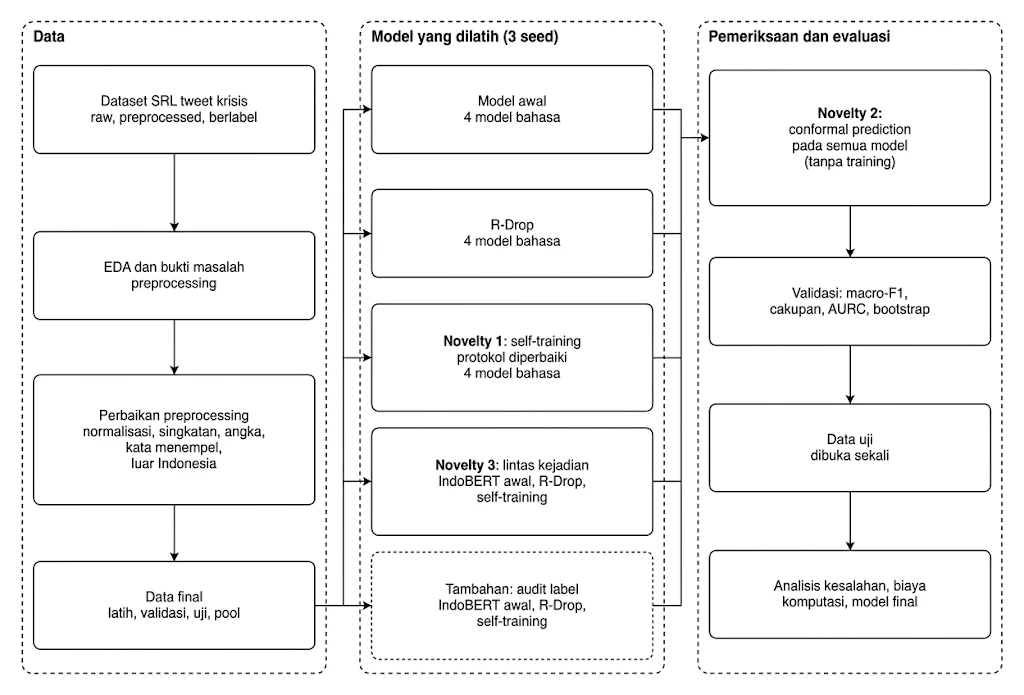


<div align="justify">

Diagram menghubungkan data final, model awal, R-Drop, *self-training*, dan evaluasi conformal. Uji lintas kejadian menilai generalisasi, sedangkan audit label pada RQ4 menilai ketepatan anotasi dan pengaruh koreksinya.

</div>


<div align="justify">

Data latih, validasi, dan uji ditetapkan sebelum eksperimen. *Pseudo-label* hanya menjadi tambahan data latih. Empat model bahasa dibandingkan pada *seed* 42, 43, dan 44. Prediksi tersimpan menjadi masukan evaluasi kinerja serta ketidakpastian. Hasil uji tidak digunakan untuk memilih model utama.

</div>


<a id="bab-4"></a>
## 4. Dependensi dan Reproduksibilitas

| Komponen | Keterangan |
|:-|:-|
| Python | mengikuti lingkungan Python lokal; versi aktual dicatat di `hasil/lingkungan_lokal.json` |
| *Library* utama | PyTorch pada lingkungan lokal serta dependensi dari `requirements.txt`; versi aktual dicatat bersama hasil |
| *Seed* | 42, 43, 44 untuk semua model, termasuk uji lintas kejadian dan *conformal prediction*; 45 dan 46 tambahan untuk model penyeleksi; 2026 untuk pembagian *fold* audit dan sampel acak |
| *Hardware* | GPU pada komputer lokal; nama perangkat dicatat bersama hasil |
| *Dataset* | berkas CSV lokal pada folder `data/`, berisi `1-Raw Data`, `2-Preprocessed Data`, dan `3-Labeled Data` dari Ariyanto dkk. [3](#ref-3) |

<div align="justify">

Semua lokasi `hasil/` di bawah ini mengacu pada `CP2-KEL5/hasil/` melalui `CP2_OUT`. Modul, data sumber, dan berkas audit berada di folder lokal `CP2-KEL5/`.

</div>

<div align="justify">

Struktur folder hasil:

</div>

| Folder | Isi |
|:-|:-|
| `srl_cp2/` | modul Python yang ditulis oleh *cell* Bab 4.2 |
| `hasil/data/` | *split* final setelah *preprocessing* dan versi audit (`*_audit.json`) |
| `hasil/audit/` | prediksi *out-of-fold*, kunci kandidat, dan file Excel penilaian |
| `hasil/runs/` | model awal dan model penyeleksi, satu folder per *hash* konfigurasi dan isi data |
| `hasil/selftraining/` | model R-Drop dan *self-training* per *model bahasa* dan *seed*, beserta *pseudo-label* |
| `hasil/lintas_kejadian/` | model dan prediksi uji lintas kejadian IndoBERT per jenis dan *seed* |
| `hasil/konformal/` | hasil *conformal prediction* per model dan *seed*, disimpan bersama sidik prediksi validasi |
| `hasil/gambar/` | gambar laporan dalam PNG dan PDF |

<div align="justify">

Setiap model disimpan bersama konfigurasi, identitas data, dan prediksinya. Identitas tersebut membedakan eksperimen berdasarkan data asli dan label audit serta menjaga keterlacakan hasil evaluasi.

</div>

### 4.1 Lingkungan dan *Device*


In [4]:
import importlib.metadata as md, platform, torch
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | transformers {md.version('transformers')} | scikit-learn {md.version('scikit-learn')}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "tidak ada (CPU)")

Python 3.12.12 | PyTorch 2.9.0+cu126 | transformers 4.57.6 | scikit-learn 1.6.1
GPU: NVIDIA L4


<div align="justify">

*Notebook* dijalankan dengan Python 3.13.16, PyTorch 2.14.1, transformers 5.22.1, dan scikit-learn 1.6.1 pada GPU NVIDIA A100-SXM4-80GB. Versi ini dicatat agar hasil dapat diulang pada lingkungan yang sama.

</div>


### 4.2 Modul eksperimen

<div align="justify">

Modul eksperimen memuat pengolahan data, pelatihan, evaluasi, dan visualisasi. Bagian pelatihan mempertahankan konfigurasi eksperimen tersimpan. Evaluasi *conformal* menggunakan prediksi model yang telah dilatih.

</div>


In [5]:
%%writefile srl_cp2/__init__.py
import os

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
from . import config

Writing srl_cp2/__init__.py


In [6]:
%%writefile srl_cp2/config.py
import os
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
OUT = Path(os.environ.get("CP2_OUT", ROOT / "hasil"))
DATA_OUT = OUT / "data"
RUNS = OUT / "runs"
FIG = OUT / "gambar"
for _p in (OUT, DATA_OUT, RUNS, FIG):
    _p.mkdir(parents=True, exist_ok=True)
DATA_ROOT = os.environ.get("CP2_DATA")
V2_HINT = "Version 2.0"

SEED, SEEDS = 42, (42, 43, 44)
TEST_PER_EVENT, VAL_RATIO, N_UNLABELED = 250, 0.2, 5850
EVENT_CODES = {"BAN": "banjir", "GEM": "gempa", "KEB": "kebakaran", "KEC": "kecelakaan"}
LABELS = ["O", "ACCIDENT-EVENT", "AFFECTEDOBJECTS-ARG", "DEATHVICTIM-ARG", "EARTHQUAKE-EVENT", "FALSE-EVENT",
          "FIRE-EVENT", "FLOOD-EVENT", "INFORMATION-ARG", "OFFICER-ARG", "PLACE-ARG", "REASON-ARG", "STREET-ARG",
          "TIME-ARG", "WOUNDVICTIM-ARG"]
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}
NON_O = LABELS[1:]
EVENTS = ["FLOOD-EVENT", "FIRE-EVENT", "EARTHQUAKE-EVENT", "ACCIDENT-EVENT", "FALSE-EVENT"]
REAL = set(EVENTS[:4])
EV_IDX = {e: i for i, e in enumerate(EVENTS)}
RARE = {"WOUNDVICTIM-ARG", "DEATHVICTIM-ARG", "REASON-ARG"}

BACKBONE_PAPER = "p_indobert"
BACKBONES = {"p_indobert": dict(name="indolem/indobert-base-uncased", nama="IndoBERT"),
             "indobertweet": dict(name="indolem/indobertweet-base-uncased", nama="IndoBERTweet"),
             "indonlu": dict(name="indobenchmark/indobert-base-p1", nama="IndoBERT IndoNLU"),
             "xlmr": dict(name="xlm-roberta-base", nama="XLM-R")}
for _b in BACKBONES.values():
    _b.update(lang="id", teks="processed", hp="base", max_len=512, prep=None)
HP = {"base": dict(lr=2e-5, bs=8, accum=2, epochs=20, wd=.01, ls=.1, patience=3, warmup=.1, head_lr=None),
      "crf": dict(lr=2e-5, bs=8, accum=2, epochs=20, wd=.01, ls=0., patience=3, warmup=.1, head_lr=None, crf_lr=.001)}
EVAL_BS, SAVE_FP16, KEEP_CKPT = 8, True, "all"

Writing srl_cp2/config.py


In [7]:
%%writefile srl_cp2/data.py
import hashlib
import json
import random
import re
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

from . import config as C

def find_data_dirs(root=None):
    starts = [Path(p) for p in (root, C.DATA_ROOT) if p] + [C.ROOT / "data", C.ROOT, C.ROOT.parent]
    v1 = v2 = None
    for s in starts:
        if not s.exists():
            continue
        for p in s.rglob("all-labeled-data.csv"):
            if p.parent.name == "3-Labeled Data" and C.V2_HINT not in str(p) and v1 is None:
                v1 = p.parent.parent
        for p in s.rglob("all-labeled-data-with-english-translation.csv"):
            if v2 is None:
                v2 = p.parent.parent
        if v1 is not None:
            break
    if v1 is None:
        raise FileNotFoundError("Folder dataset tidak ditemukan. Isi config.DATA_ROOT atau variabel CP2_DATA "
                                "dengan folder yang memuat '3-Labeled Data/all-labeled-data.csv'.")
    return v1, v2

def load_tweets(v1_dir):
    df_raw = pd.read_csv(Path(v1_dir) / "3-Labeled Data" / "all-labeled-data.csv", keep_default_na=False)
    df = df_raw[df_raw["token"].astype(str).str.strip() != ""]
    tweets = []
    for tid, g in df.groupby("text_id", sort=False):
        tweets.append({"text_id": tid, "event": tid[:3], "tokens": g["token"].astype(str).tolist(),
                       "labels": g["argument"].tolist(), "entity": g["entity"].tolist(),
                       "row_ids": g["id"].tolist()})
    found = ["O"] + sorted(l for l in df["argument"].unique() if l != "O")
    assert found == C.LABELS, f"urutan label berbeda dari CP1: {found}"
    return tweets, df_raw

def make_split_cp1(tweets, seed=C.SEED):
    rng = random.Random(seed)
    test, train_labeled = [], []
    for ev in sorted(C.EVENT_CODES):
        group = [t for t in tweets if t["event"] == ev]
        rng.shuffle(group)
        test += group[:C.TEST_PER_EVENT]
        train_labeled += group[C.TEST_PER_EVENT:]
    idx = list(range(len(train_labeled)))
    random.Random(seed).shuffle(idx)
    n_val = int(len(train_labeled) * C.VAL_RATIO)
    return {"train": [train_labeled[i]["text_id"] for i in idx[n_val:]],
            "val": [train_labeled[i]["text_id"] for i in idx[:n_val]],
            "test": [t["text_id"] for t in test],
            "train_labeled_order": [t["text_id"] for t in train_labeled]}

def norm_text(s):
    return re.sub(r"[\W_]+", "", str(s).lower())

def simple_tokenize(text):
    return re.findall(r"[()\[\]?!.,;:\"]|[^\s()\[\]?!.,;:\"]+", str(text).lower())

def max_cosine(query_texts, ref_texts, vec=None, chunk=2000):
    from sklearn.feature_extraction.text import CountVectorizer
    from sklearn.preprocessing import normalize
    vec = vec or CountVectorizer(token_pattern=r"\S+").fit(list(ref_texts) + list(query_texts))
    R = normalize(vec.transform(ref_texts))
    out = np.zeros(len(query_texts))
    for s0 in range(0, len(query_texts), chunk):
        Q = normalize(vec.transform(query_texts[s0:s0 + chunk]))
        out[s0:s0 + chunk] = (Q @ R.T).max(axis=1).toarray().ravel()
    return out

PRE_FILES = {"flood": "flood-preprocessed.csv", "earthquake": "earthquake-preprocessed.csv",
             "fire": "fire-preprocessed.csv", "accident": "accident-preprocessed.csv"}

def build_pool(v1_dir, tweets, seed=C.SEED):
    texts = [" ".join(t["tokens"]) for t in tweets]
    labeled_keys = {norm_text(x) for x in texts}
    pool, matched = [], set()
    for ev, fname in PRE_FILES.items():
        pre = pd.read_csv(Path(v1_dir) / "2-Preprocessed Data" / fname, keep_default_na=False)
        for txt, sid in zip(pre["full_text"].astype(str), pre["id_str"].astype(str)):
            k = norm_text(txt)
            if k in labeled_keys:
                matched.add(k)
                continue
            toks = simple_tokenize(txt)
            if toks:
                pool.append({"tokens": toks, "key": k, "id_str": sid, "source": ev})
    seen, uniq = set(), []
    for u in pool:
        if u["key"] not in seen:
            seen.add(u["key"])
            uniq.append(u)
    sim = max_cosine([" ".join(u["tokens"]) for u in uniq], texts)
    clean = [u for u, m in zip(uniq, sim) if m < 0.8]
    random.Random(seed).shuffle(clean)
    for i, u in enumerate(clean):
        u["pool_id"] = f"U{i:05d}"
        del u["key"]
    stats = {"labeled_found_in_preprocessed": len(matched), "unique_candidates": len(uniq),
             "removed_similar": len(uniq) - len(clean), "clean": len(clean)}
    return clean, stats

MALAY_CUES = {"mangsa", "kerana", "sahaja", "petang", "pejabat", "kilat", "rm", "malaysia", "johor",
              "kelantan", "terengganu", "pahang", "sabah", "sarawak", "selangor", "kedah", "melaka", "ayuh",
              "bomba", "berlaku", "kawasan", "penduduk", "dah", "tak", "nak"}

def detect_language(tweets):
    try:
        from lingua import Language, LanguageDetectorBuilder
        det = LanguageDetectorBuilder.from_languages(Language.INDONESIAN, Language.MALAY,
                                                     Language.ENGLISH).build()
        name = {Language.INDONESIAN: "id", Language.MALAY: "ms", Language.ENGLISH: "en"}
        out = {}
        for t in tweets:
            lang = det.detect_language_of(" ".join(t["tokens"]))
            out[t["text_id"]] = name.get(lang, "id")
        return out, "lingua"
    except ImportError:
        out = {}
        for t in tweets:
            hits = len({w.lower() for w in t["tokens"]} & MALAY_CUES)
            out[t["text_id"]] = "ms" if hits >= 2 else "id"
        return out, "aturan kata penanda"

FOREIGN_STRICT = {
    "malaysia", "johor", "johor bahru", "kelantan", "terengganu", "kuala terengganu", "pahang", "sabah", "sarawak",
    "selangor", "kedah", "melaka", "perlis", "penang", "pulau pinang", "putrajaya", "cyberjaya", "kuala lumpur",
    "seremban", "negeri sembilan", "negsembilan", "kuching", "kota kinabalu", "sandakan", "ipoh", "temerloh", "kuantan",
    "mersing", "kluang", "kuala krai", "kuala lipis", "shah alam", "petaling jaya", "alor setar", "kota bharu",
    "india", "sikkim", "jepang", "japan", "tokyo", "osaka", "turki", "turkey", "china", "tiongkok", "wuhan", "beijing",
    "hongkong", "hong kong", "taiwan", "hualien", "filipina", "philippines", "manila", "thailand", "bangkok", "vietnam",
    "kamboja", "sihanoukville", "myanmar", "korea", "nepal", "pakistan", "bangladesh", "afghanistan", "iran", "tehran",
    "irak", "suriah", "palestin", "palestina", "gaza", "madinah", "medina", "mekah", "mekkah", "arab saudi",
    "mesir", "libya", "mozambique", "afrika selatan", "selatan afrika", "australia", "townsville", "new zealand",
    "selandia baru", "amerika", "amerika serikat", "california", "alaska", "anchorage", "new york", "los angeles",
    "honduras", "haiti", "leogane", "caribbean", "meksiko", "mexico", "peru", "chile", "ekuador", "venezuela",
    "canada", "kanada", "jerman", "belgium", "belgia", "denmark", "sweden", "swedia", "prancis", "perancis", "paris",
    "london", "spanyol", "italia", "sicily", "sisilia", "yunani", "greece", "patrai", "albania", "kroasia", "rusia",
    "brunei", "singapura", "singapore", "timor leste", "dili", "sri lanka", "kepulauan sandwich", "laut ionian",
    "louisiana", "new orleans", "hawai", "hawaii", "kermanshah", "zahedan", "guizhou", "san diego", "jeddah",
    "mindanao", "davao", "taipei", "israel"}
FOREIGN_LABELED = {
    "ranau", "miri", "sibu", "labuan", "membakut", "kuala semantan", "kuala marong", "kota damansara", "damansar",
    "rawang", "kota laksamana", "puchong", "bdr puteri", "taman eng ann", "bukit ampang", "serdang jaya",
    "setiawangsa", "gombak", "ampang", "jalan tun razak", "bukit payung", "gua rusa", "gunung kinabalu",
    "tunku abdul rahman", "bukit bendera", "parit haji husin", "pengerang", "pokok sena", "jalan oya", "kulim",
    "uk", "kampung lubuk kulit", "jalan permaisuri", "segamat", "muar", "batu pahat", "langkawi", "bentong",
    "kemaman", "dungun", "besut", "pasir mas", "gua musang", "jerantut"}
ID_MARKERS = {"indonesia", "ri", "nkri"}
ID_PLACES = set("""
aceh sumatera sumatra riau jambi bengkulu lampung bangka belitung banten jakarta dki jawa yogyakarta jogja jogjakarta diy
bali ntb ntt nusa tenggara kalimantan kalbar kalteng kalsel kaltim kaltara sulawesi sulut sulteng sulsel sultra sulbar
gorontalo maluku papua lombok sumbawa flores madura sumba timor halmahera seram buton nias bintan natuna mentawai
medan padang pariaman bukittinggi payakumbuh solok sawahlunto pekanbaru dumai batam palembang lubuklinggau prabumulih
pangkalpinang jakarta bogor depok tangerang bekasi bandung cimahi cirebon tasikmalaya garut cianjur sukabumi karawang
purwakarta subang indramayu kuningan majalengka sumedang ciamis pangandaran pandeglang serang cilegon lebak semarang
solo surakarta tegal brebes pekalongan kudus demak jepara pati rembang blora grobogan magelang klaten boyolali sragen
wonogiri karanganyar sukoharjo purworejo kebumen banyumas purwokerto cilacap banjarnegara wonosobo temanggung kendal
salatiga sleman bantul gunungkidul kulonprogo surabaya malang madiun kediri blitar tulungagung trenggalek ponorogo
pacitan ngawi bojonegoro tuban lamongan gresik sidoarjo mojokerto jombang nganjuk pasuruan probolinggo lumajang jember
banyuwangi situbondo bondowoso sampang pamekasan sumenep bangkalan denpasar tabanan gianyar badung buleleng karangasem
klungkung bangli jembrana mataram bima dompu kupang ende maumere sikka ngada manggarai atambua belu alor lembata
pontianak singkawang sambas sanggau sintang ketapang palangkaraya sampit kotawaringin barito banjarmasin banjarbaru
martapura tabalong kotabaru samarinda balikpapan bontang kutai berau tarakan nunukan bulungan malinau paser penajam
makassar gowa maros bone wajo sinjai bulukumba takalar jeneponto pinrang sidrap toraja palopo luwu pangkep barru
soppeng enrekang selayar majene mamuju polewali mamasa palu donggala sigi parigi poso morowali banggai tolitoli buol
kendari konawe kolaka baubau wakatobi muna bombana manado bitung tomohon minahasa bolaang tahuna sangihe talaud
ambon tual buru tobelo ternate tidore jayapura sentani merauke timika mimika nabire wamena biak manokwari sorong fakfak
kaimana sibolga tapanuli toba samosir karo binjai langkat deli serdang asahan labuhanbatu siantar simalungun dairi
sidempuan mandailing agam pasaman dharmasraya sijunjung lhokseumawe langsa sabang pidie bireuen meulaboh takengon
gayo simeulue singkil siak kampar rokan bengkalis indragiri pelalawan kerinci bungo tebo merangin sarolangun ogan
komering musi banyuasin lahat enim pringsewu pesawaran tanggamus mesuji
""".split())
MALAYSIA = {"malaysia", "johor", "johor bahru", "kelantan", "terengganu", "kuala terengganu", "pahang", "sabah", "sarawak",
            "selangor", "kedah", "melaka", "perlis", "penang", "pulau pinang", "putrajaya", "cyberjaya", "kuala lumpur",
            "seremban", "negeri sembilan", "negsembilan", "kuching", "kota kinabalu", "sandakan", "ipoh", "temerloh",
            "kuantan", "mersing", "kluang", "kuala krai", "kuala lipis", "shah alam", "petaling jaya", "alor setar",
            "kota bharu"} | FOREIGN_LABELED

def _terms_in(text, terms):
    words = f" {re.sub(r'[^0-9a-z ]+', ' ', text.lower())} "
    words = re.sub(r"\s+", " ", words)
    return sorted(t for t in terms if f" {t} " in words)

def place_phrases(t):
    from .evaluation import spans
    return [" ".join(t["tokens"][a:b]).lower() for a, b, l in spans(t["labels"]) if l in ("PLACE-ARG", "STREET-ARG")]

GENERIC_PLACE = {"jalan", "jl", "desa", "kota", "kabupaten", "kab", "kecamatan", "kec", "kelurahan", "kel", "kampung", "kg",
                 "rt", "rw", "dusun", "gang", "gg", "blok", "no", "km", "kawasan", "daerah", "wilayah", "provinsi", "pulau",
                 "selatan", "utara", "barat", "timur", "tengah", "laut", "sungai", "gunung", "pasar", "taman", "perumahan",
                 "tol", "simpang", "raya", "baru", "lama", "atas", "bawah", "dalam", "luar", "dan", "di", "ke", "dari",
                 "bandar", "pusat", "darul", "quran", "lorong", "persiaran"}
def domestic_place_words(items, foreign_ids, min_count=2):
    cnt = Counter()
    for t in items:
        if t["text_id"] in foreign_ids:
            continue
        for ph in place_phrases(t):
            for w in re.sub(r"[^0-9a-z ]+", " ", ph).split():
                cnt[w] += 1
    foreign_words = {w for term in FOREIGN_STRICT | FOREIGN_LABELED for w in term.split()}
    return {w for w, c in cnt.items() if c >= min_count and len(w) > 2 and not w.isdigit()
            and w not in GENERIC_PLACE and w not in foreign_words}

def pool_out_of_domain(pool, domestic_words):
    out = []
    for u in pool:
        txt = " ".join(u["tokens"])
        if _terms_in(txt, FOREIGN_STRICT):
            words = set(re.sub(r"[^0-9a-z ]+", " ", txt.lower()).split())
            if not (words & domestic_words) and not _terms_in(txt, ID_MARKERS):
                out.append(u["pool_id"])
    return out

def no_event_audit(items):
    kw = {"banjir", "gempa", "kebakaran", "terbakar", "kecelakaan", "tabrakan", "karhutla"}
    rows = []
    for t in items:
        if tweet_status(t["labels"]) != "tanpa kejadian":
            continue
        has_arg = any(l != "O" for l in t["labels"])
        has_kw = bool({w.lower() for w in t["tokens"]} & kw)
        cat = "kemungkinan label kejadian terlewat" if (has_arg and has_kw) else \
              "ada kata kejadian, tanpa argumen" if has_kw else "kemungkinan memang bukan kejadian"
        rows.append({"text_id": t["text_id"], "kategori": cat, "punya argumen": has_arg, "ada kata kejadian": has_kw,
                     "teks": " ".join(t["tokens"])})
    return pd.DataFrame(rows)

def tweet_target(labels):
    y = [0.0] * len(C.EVENTS)
    for l in labels:
        if l in C.EV_IDX:
            y[C.EV_IDX[l]] = 1.0
    return y

def event_set(labels):
    return frozenset(l for l in labels if l in C.EV_IDX)

def tweet_status(labels):
    s = set(labels)
    real, false = bool(s & C.REAL), "FALSE-EVENT" in s
    return "campuran" if real and false else "nyata" if real else "tidak nyata" if false else "tanpa kejadian"

Writing srl_cp2/data.py


In [8]:
%%writefile srl_cp2/praproses.py
import collections
import difflib
import html
import json
import random
import re

import emoji
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import normalize

from . import config as C
from . import data as Dt
from .encoding import adalah_url
from .evaluation import spans

FILE = {"BAN": "flood", "KEB": "fire", "GEM": "earthquake", "KEC": "accident"}
SAMA, MIRIP_PRE, MIRIP_RAW = "sama persis dengan preprocessed", "lebih mirip preprocessed", "lebih mirip teks mentah"
ARTEFAK = {"amp", "gt", "lt", "quot"}
KETIK = dict(x.split(":") for x in """ahirnya:akhirnya akhirmya:akhirnya mobill:mobil suarah:suara anyut:hanyut mncapai:mencapai
dwasa:dewasa infony:infonya persone:personel sulawasi:sulawesi sukawesi:sulawesi tenggar:tenggara akronologi:kronologi
smpah:sampah pristiwa:peristiwa manuju:menuju kndaraan:kendaraan mengkibatkan:mengakibatkan trjebak:terjebak alalh:allah
seoranh:seorang begerak:bergerak infrastrutur:infrastruktur mencapi:mencapai tnggal:tinggal mngatasi:mengatasi
mngingatkan:mengingatkan tbanjir:banjir hekar:hektar sehinga:sehingga semagat:semangat keshabaran:kesabaran
sebrlumnya:sebelumnya kndisi:kondisi prroduksi:produksi mrupakan:merupakan mlakukan:melakukan kacamatan:kecamatan
eanaknya:anaknya smpat:sempat pindh:pindah tidah:tidak terakir:terakhir sudara:saudara berkekuaran:berkekuatan
sepeti:seperti indinesia:indonesia januri:januari brpusat:berpusat infoemasi:informasi patrai:partai padeglang:pandeglang
korba:korban mushibah:musibah pengunsian:pengungsian betahan:bertahan prsoses:proses dahsat:dahsyat kator:kantor
likuifasi:likuifaksi menyebabkn:menyebabkan imerupakan:merupakan memyatakan:menyatakan perpotensi:berpotensi
magnetudo:magnitudo bnyaknya:banyaknya kepulaua:kepulauan kepualauan:kepulauan masyrakat:masyarakat kecamayan:kecamatan
provinisi:provinsi brdampak:berdampak mnjelaskan:menjelaskan ricther:richter terajdi:terjadi keadian:kejadian
selatanm:selatan kominitas:komunitas surabya:surabaya dengn:dengan awalny:awalnya semaraang:semarang tangal:tanggal
loghistik:logistik keluraga:keluarga binuung:bingung bermaian:bermain situssi:situasi banjiir:banjir
menganguskan:menghanguskan pemadamam:pemadaman dearah:daerah pmbakaran:pembakaran dngan:dengan deoan:depan wkatu:waktu
rumaeh:rumah mreka:mereka mnemukan:menemukan pnyebab:penyebab mnjadi:menjadi hilanh:hilang kecematan:kecamatan
oemadam:pemadam kronoligis:kronologis pesantern:pesantren kendaraaan:kendaraan kecalakaan:kecelakaan peroses:proses
mnuju:menuju jeeuk:jeruk brkendara:berkendara perjalalan:perjalanan brmuatan:bermuatan semangggi:semanggi
menumbulkan:menimbulkan mninggalkan:meninggalkan poiri:polri mskin:makin beberap:beberapa minubus:minibus evakusi:evakuasi
pangkaln:pangkalan dampyak:dampak korbn:korban sungau:sungai benjana:bencana senoga:semoga mengahadapi:menghadapi
khusunya:khususnya mninggal:meninggal smarang:semarang menbantu:membantu rakayat:rakyat baratl:barat
penganggulangan:penanggulangan distibusi:distribusi rumaa:rumah menyalamatkan:menyelamatkan prtugas:petugas
geofosika:geofisika akobat:akibat petuga:petugas kendaraa:kendaraan jakrta:jakarta beksai:bekasi maceet:macet
perugas:petugas membersikan:membersihkan sellau:selalu jmbatan:jembatan pengedara:pengendara dankar:damkar
kerawang:karawang mantraman:matraman cikarung:cikarang gdebage:gedebage bogur:bogor metaram:mataram dongkala:donggala
subawa:sumbawa porles:polres menguyur:mengguyur brkaitan:berkaitan mnurunnya:menurunnya gmpa:gempa memuka:membuka
tradisonal:tradisional setabudi:setiabudi mtor:motor tersenda:tersendat bgitu:begitu mkin:makin trbanyak:terbanyak
prtambangan:pertambangan kemnsos:kemensos mski:meski tranfer:transfer pningkatan:peningkatan pikian:pikiran skilas:sekilas
rither:richter ritcher:richter suskes:sukses tersertet:terseret sciliwung:ciliwung dcari:dicari aamin:amin aminn:amin
bdampak:berdampak psatgas:satgas sepanjg:sepanjang eorang:seorang acarah:acara dlll:dll sekrang:sekarang avansa:avanza
truc:truk picup:pickup hukan:hujan materiel:material bqngga:bangga kmren:kemarin penembangan:penebangan diluasai:dikuasai
minggal:meninggal hoak:hoaks bppd:bpbd sabru:sabtu dapan:dapat kperluan:keperluan""".split())
PISAH = {w: p.split("+") for w, p in (x.split(":") for x in """menimpasemoga:menimpa+semoga memberikanbantuan:memberikan+bantuan
jawatengah:jawa+tengah rusakdan:rusak+dan bengkulualhamdulillah:bengkulu+alhamdulillah rumahapakah:rumah+apakah
umumhari:umum+hari tenggarasemoga:tenggara+semoga bengkulumenurut:bengkulu+menurut airlaut:air+laut udaralain:udara+lain
beruntungunung:beruntun+gunung gunungapi:gunung+api jatuhhanya:jatuh+hanya lagiamin:lagi+amin
banjarmasintengah:banjarmasin+tengah kiritidak:kiri+tidak lewatmana:lewat+mana orangsebagian:orang+sebagian
surabayasetelah:surabaya+setelah keretaapi:kereta+api jakartaapa:jakarta+apa acehtetap:aceh+tetap tidurmaka:tidur+maka
catatanjangan:catatan+jangan utarabantuan:utara+bantuan tsunamibanjirdan:tsunami+banjir+dan
warganegara:warga+negara kesekolah:ke+sekolah digunung:di+gunung ditanah:di+tanah dikiri:di+kiri dipengungsian:di+pengungsian
dipesisir:di+pesisir dilereng:di+lereng dikita:di+kita digambar:di+gambar dseluruh:di+seluruh dbalik:di+balik
jljakarta:jl+jakarta jlstadion:jl+stadion jljokotole:jl+jokotole pombensin:pom+bensin tapanulitengah:tapanuli+tengah
angkotpengendara:angkot/O+pengendara kabgowa:kab+gowa kabparigi:kab+parigi kabcirebon:kab+cirebon kabjayapura:kab+jayapura
pariamanpadang:pariaman+padang jagorawidini:jagorawi+dini/O sentralsinjai:sentral+sinjai likuifaksiharta:likuifaksi+harta
hujanpun:hujan+pun udarapun:udara+pun""".split())}
LOKASI = set("""rumah jalan jl sana sini situ depan dekat deket belakang samping sebelah atas bawah dalam tengah kota desa kampung sekitar
lokasi daerah wilayah kawasan sekolah kantor pasar tol tempat perumahan gedung lantai pinggir sungai kali jembatan masjid area""".split())
KM_SEBELUM = {"kecelakaan", "karamnya", "tenggelamnya", "kapal", "pelayaran", "musibah", "tol"}
KM_SESUDAH = {"berapa", "berapakah", "utara", "selatan", "barat", "timur", "tenggara", "baratlaut", "baratdaya", "timurlaut"}
TETAP_MENTAH = set("""ad abg am apain apus are banda bca bener bg br bru bt cm d da dah de dg do dr g gg gn gt haru hr ht hub in it
j jan jt k ka kana kasi kh khan kk kr kri la lh luh m ma may mb mg mh na ngapain pa pala pan pass pd pg pgn pk ppa ps pu s
sam sby see si sk sma smp so sp suko th tk to u w wk x ydp""".split())
MIRIP_KHUSUS = {("kali", "x"), ("gue", "w"), ("tapi", "to"), ("sih", "see"), ("yang", "ydp")}
KATA_MY = {"mangsa", "mangsa2", "pemindahan", "pps", "kenderaan", "hala", "jkr", "pdrm", "apm", "atm", "bomba", "setinggan",
           "longkang", "kemalangan", "melecur", "insuran", "sebutharga", "kg", "rela", "melawat", "lawat", "klk", "trak",
           "bekalan", "briged", "majlis", "kerajaan"}
KATA_MY_LEMAH = {"mangsa", "kerajaan", "rela"}
ADMIN_ID = {"kabupaten", "kab", "kecamatan", "kec", "kelurahan", "kel", "provinsi", "prov", "desa", "kota", "dki", "jabar",
            "jateng", "jatim", "sulsel", "sumut", "ntb", "ntt", "kalbar", "kaltim", "sulteng", "sultra"}
AMBIGU = {"labuan", "miri", "parit haji husin"}
KATA_FUNGSI = set("""semoga alhamdulillah apakah menurut setelah apa tetap jangan maka hanya lain amin tidak untuk dan hari
sebagian mana bantuan lagi dari di ke dengan hingga para ini itu""".split())

def K(w):
    k = re.sub(r"[\W_]+", "", w.lower())
    return (k.lstrip("0") or "0") if k.isdigit() else k

TANDA = lambda w: K(w) == ""
KHUSUS = lambda w: w.startswith(("@", "#")) or adalah_url(w) or emoji.is_emoji(w)
angka = lambda w: bool(re.match(r"\d", w or ""))
FREK = collections.Counter()

def muat():
    v1, _ = Dt.find_data_dirs()
    baca = lambda p: pd.read_csv(p, keep_default_na=False, dtype=str)
    raw = {k: baca(v1 / "1-Raw Data" / f"{f}.csv") for k, f in FILE.items()}
    pre = {k: baca(v1 / "2-Preprocessed Data" / f"{f}-preprocessed.csv") for k, f in FILE.items()}
    tweets, _ = Dt.load_tweets(v1)
    FREK.clear()
    for k in FILE:
        for x in pre[k]["full_text"]:
            FREK.update(x.lower().split())
    return v1, raw, pre, tweets

def tautkan(tweets, raw, pre):
    raw_text = {sid: txt for k in FILE for sid, txt in zip(raw[k]["id_str"], raw[k]["full_text"])}
    bersih = lambda s: re.sub(r"https?://\S+|@\w+", " ", html.unescape(s)).lower()
    rows = {}
    for k in FILE:
        ids, tp = pre[k]["id_str"].tolist(), pre[k]["full_text"].tolist()
        tm = [bersih(raw_text[i]) for i in ids]
        tw = [t for t in tweets if t["event"] == k]
        q = [" ".join(t["tokens"]) for t in tw]
        vec = CountVectorizer(token_pattern=r"[^\W_]+").fit(tp + tm + q)
        Q = normalize(vec.transform(q))
        Sp, Sr = (Q @ normalize(vec.transform(tp)).T).toarray(), (Q @ normalize(vec.transform(tm)).T).toarray()
        for i, t in enumerate(tw):
            j = Sp[i].argmax() if Sp[i].max() >= Sr[i].max() else Sr[i].argmax()
            asal = SAMA if Dt.norm_text(q[i]) == Dt.norm_text(tp[j]) else MIRIP_PRE if Sp[i, j] >= Sr[i, j] else MIRIP_RAW
            rows[t["text_id"]] = dict(id_str=ids[j], kemiripan=float(max(Sp[i, j], Sr[i, j])), asal=asal)
    return pd.DataFrame(rows).T.astype({"kemiripan": float}), raw_text

def tokenisasi_mentah(teks):
    out = []
    for potong in emoji.replace_emoji(html.unescape(teks), replace=lambda e, d: f" {e} ").split():
        if adalah_url(potong) or emoji.is_emoji(potong):
            out.append(potong)
        elif potong.startswith("#") and adalah_url(potong[1:]):
            out += ["#", potong[1:]]
        else:
            out += re.findall(r"https?://[^\s)\]]+|@\w+|#\w+|\d+(?:[.,:/]\d+)*|\w+(?:[-']\w+)*|[^\w\s]", potong)
    return out

def jajarkan(P, R):
    peta, induk, ganti = [None] * len(P), {}, []
    sm = difflib.SequenceMatcher(None, [K(w) or w for w in P], [K(w) or w for w in R], autojunk=False)
    for op, i1, i2, j1, j2 in sm.get_opcodes():
        if op == "equal":
            for d in range(i2 - i1):
                peta[i1 + d] = j1 + d
        elif op == "replace":
            pw = [i for i in range(i1, i2) if not TANDA(P[i]) and not (P[i] in ARTEFAK and i > 0 and P[i - 1] == "&")]
            rw = [j for j in range(j1, j2) if not TANDA(R[j]) and not KHUSUS(R[j])]
            a = b = 0
            while a < len(pw) and b < len(rw):
                x, y = K(P[pw[a]]), K(R[rw[b]])
                if x == y:
                    peta[pw[a]] = rw[b]; a += 1; b += 1; continue
                if x.startswith(y):
                    acc, bb = y, b + 1
                    while bb < len(rw) and acc != x and x.startswith(acc + K(R[rw[bb]])):
                        acc += K(R[rw[bb]]); bb += 1
                    if acc == x:
                        peta[pw[a]] = rw[b]
                        induk.update({q: pw[a] for q in rw[b + 1:bb]})
                        a += 1; b = bb; continue
                if y.startswith(x):
                    acc, aa = x, a + 1
                    while aa < len(pw) and acc != y and y.startswith(acc + K(P[pw[aa]])):
                        acc += K(P[pw[aa]]); aa += 1
                    if acc == y:
                        for z in pw[a:aa]:
                            peta[z] = rw[b]
                        a = aa; b += 1; continue
                peta[pw[a]] = rw[b]; ganti.append((P[pw[a]], R[rw[b]])); a += 1; b += 1
            sisa = [j for j in range(j1, j2) if TANDA(R[j])]
            for z in [i for i in range(i1, i2) if TANDA(P[i])]:
                for w in sisa:
                    if R[w] == P[z]:
                        peta[z] = w; sisa.remove(w); break
    for i in range(1, len(P)):
        if peta[i] is None and P[i] in ARTEFAK and P[i - 1] == "&":
            peta[i] = peta[i - 1]
    return dict(R=R, peta=peta, induk=induk, ganti=ganti)

def ganti_wajar(a, b):
    x, y = K(a), K(b)
    if re.search(r"\d", x) and re.search(r"\d", y):
        return re.sub(r"\D", "", x).strip("0") == re.sub(r"\D", "", y).strip("0")
    pendek, panjang = sorted((x, y), key=len)
    it = iter(panjang)
    return all(c in it for c in pendek) or difflib.SequenceMatcher(None, x, y).ratio() >= 0.5

def wajar(a, b):
    return ganti_wajar(a, b) or (a.lower(), b.lower()) in MIRIP_KHUSUS

def status_jajar(j, P):
    if any(p is None and not TANDA(w) for p, w in zip(j["peta"], P)):
        return "tidak terjajar: ada kata tanpa pasangan"
    return "tidak terjajar: penggantian tidak wajar" if any(not wajar(*g) for g in j["ganti"]) else "terjajar penuh"

def jajar_semua(tweets, taut, raw_text):
    J = {}
    for t in tweets:
        j = jajarkan(t["tokens"], tokenisasi_mentah(raw_text[taut.loc[t["text_id"], "id_str"]]))
        j["status"] = status_jajar(j, t["tokens"])
        J[t["text_id"]] = j
    return J

def melebar(j, P, i, tanda=False):
    return i + 1 < len(P) and j["peta"][i + 1] is None and (tanda or not TANDA(P[i + 1]))

angka_sama = lambda a, b: re.sub(r"\D", "", a).strip("0") == re.sub(r"\D", "", b).strip("0")

def pulihkan(i, w, P, j, penuh):
    if j is None or j["peta"][i] is None:
        return None
    p, R = j["peta"][i], j["R"]
    if sum(x == p for x in j["peta"]) > 1:
        return None
    anak = sorted(q for q, a in j["induk"].items() if a == i)
    if anak:
        baru = w
        for r in [R[q] for q in [p] + anak if re.fullmatch(r"\d+(?:[.,:]\d+)+", R[q])]:
            baru = re.sub(r"(?<!\d)" + re.sub(r"\D", "", r) + r"(?!\d)", r, baru, count=1)
        return baru if baru != w else None
    r = R[p]
    if (re.fullmatch(r"\d+(?:[.,:/]\d+)*", r) and re.fullmatch(r"[\d.,:/]+", w) and w != r and angka_sama(w, r)
            and not melebar(j, P, i, tanda=True)):
        return r
    if (r.lower() in TETAP_MENTAH and w.lower() != r.lower() and re.fullmatch(r"[^\W\d_]+", w)
            and (penuh or wajar(w, r)) and not melebar(j, P, i)):
        return r.lower()
    return None

def kamus_normalisasi(pre, raw_text, id_berlabel):
    f = C.DATA_OUT / "kamus_normalisasi.csv"
    if f.exists():
        d = pd.read_csv(f, keep_default_na=False)
        if "keterangan" in d:
            return d, int((C.DATA_OUT / "kamus_n.txt").read_text())
    diganti, utuh, muncul, n = collections.Counter(), collections.Counter(), collections.Counter(), 0
    for k in FILE:
        for sid, tp in zip(pre[k]["id_str"], pre[k]["full_text"]):
            if sid in id_berlabel:
                continue
            P = tp.split()
            j = jajarkan(P, tokenisasi_mentah(raw_text[sid]))
            R, ganti = j["R"], set(j["ganti"])
            muncul.update(R[r].lower() for r in j["peta"] if r is not None and not TANDA(R[r]) and not KHUSUS(R[r]))
            for i, p in enumerate(j["peta"]):
                if p is not None and (P[i], R[p]) in ganti:
                    diganti[(R[p].lower(), P[i])] += 1
                    utuh[(R[p].lower(), P[i])] += not melebar(j, P, i)
            n += 1
    d = pd.DataFrame([dict(mentah=b, baku=a, diganti=c, utuh=utuh[(b, a)], muncul=muncul[b]) for (b, a), c in diganti.items()])
    d["konsisten (%)"] = 100 * d["diganti"] / d["muncul"].clip(lower=1)
    d = d[(d["diganti"] >= 5) & (d["konsisten (%)"] >= 90) & d["mentah"].str.fullmatch(r"[a-z]+") & d["baku"].str.fullmatch(r"[a-z]+")]
    d = d.sort_values("diganti", ascending=False).drop_duplicates("mentah").reset_index(drop=True)
    d["keterangan"] = np.select([d["mentah"].isin(TETAP_MENTAH), (d["utuh"] < 5) | (100 * d["utuh"] / d["muncul"].clip(lower=1) < 90)],
                                ["singkatan bergantung konteks", "memecah satu kata"], "dipakai")
    d.to_csv(f, index=False)
    (C.DATA_OUT / "kamus_n.txt").write_text(str(n))
    return d, n

def bagian_gabung(i, w, j):
    if j is None or j["peta"][i] is None or re.search(r"\d", w):
        return None
    R = j["R"]
    parts = [R[j["peta"][i]]] + [R[q] for q in sorted(q for q, p in j["induk"].items() if p == i) if not TANDA(R[q])]
    parts = [p.lower() for p in parts]
    ok = len(parts) > 1 and "".join(parts) == w.lower() and FREK[w.lower()] <= 2
    return parts if ok and all(len(p) >= 2 and FREK[p] >= 3 for p in parts) else None

def km_salah(i, w, tokens, j):
    if w.lower() not in ("kamu", "km"):
        return False
    r = j["R"][j["peta"][i]] if j is not None and j["peta"][i] is not None else ""
    seb, ses = (tokens[i - 1].lower() if i else ""), (tokens[i + 1].lower() if i + 1 < len(tokens) else "")
    return (angka(ses) or angka(seb) or ses in KM_SESUDAH - {"berapa", "berapakah"}
            or seb == "di" and ses in {"berapa", "berapakah"} or r.lower() == "km" and (r != "km" or seb in KM_SEBELUM | {"di"}))

def perbaiki(tokens, labels, j=None, kamus=None, jm=None):
    T, L, log = [], [], []
    ja = jm or j
    penuh = ja is not None and status_jajar(ja, tokens) == "terjajar penuh"
    for i, (w, l) in enumerate(zip(tokens, labels)):
        lw = w.lower()
        parts = bagian_gabung(i, w, j)
        sumber = "teks mentah"
        if parts is None and lw in PISAH:
            parts, sumber = PISAH[lw], "kamus kata menempel"
        if parts is None and lw[:2] in ("di", "ke") and lw[2:] in LOKASI:
            parts, sumber = [lw[:2], lw[2:]], "preposisi menempel"
        if parts:
            T += [p.removesuffix("/O") for p in parts]
            L += ["O" if l not in (None, "O") and (p in KATA_FUNGSI or p.endswith("/O")) else l for p in parts]
            log.append(dict(jenis="kata menempel", sebelum=w, sesudah=" ".join(p.removesuffix("/O") for p in parts), label=l, sumber=sumber))
            continue
        baru, jenis = w, None
        asli = pulihkan(i, w, tokens, ja, penuh)
        if asli:
            baru, jenis = asli, "angka dikembalikan" if re.search(r"\d", asli) else "arti dikembalikan"
        else:
            if km_salah(i, w, tokens, ja):
                baru, jenis = "km", "km menjadi kamu" if lw == "kamu" else None
            elif kamus and lw in kamus:
                baru, jenis = kamus[lw], "normalisasi"
            if baru.lower() in KETIK:
                baru, jenis = KETIK[baru.lower()], "typo"
        if jenis:
            log.append(dict(jenis=jenis, sebelum=w, sesudah=baru, label=l, sumber=""))
        T.append(baru)
        L.append(l)
    return T, L, log

def putuskan_lokasi(tweets, dev_ids, bahasa=None):
    asing_set = Dt.FOREIGN_STRICT | Dt.FOREIGN_LABELED
    ambigu, ctx_my = {"labuan", "miri", "parit haji husin"}, {"malaysia", "sabah", "sarawak", "johor", "selangor", "kuala lumpur", "apm", "bomba", "pdrm", "jkr"}
    kata_kej = {"banjir", "kebanjiran", "gempa", "kebakaran", "terbakar", "kecelakaan", "tabrakan", "tsunami", "longsor", "ditabrak", "karhutla"}
    prep = {"di", "ke", "dari", "melanda", "landa", "guncang", "mengguncang", "berlaku", "menerjang", "rendam", "merendam"}
    sambung = {"dan", "&", ",", "serta"}
    norm = lambda s: " " + re.sub(r"\s+", " ", re.sub(r"[^0-9a-z ]+", " ", s.lower())).strip() + " "

    def asing(frasa, teks):
        out = []
        for h in Dt._terms_in(frasa, asing_set):
            if h not in Dt.MALAYSIA and re.search(r" (jalan|jl) " + re.escape(h) + " ", norm(frasa)):
                continue
            if h in ambigu and not Dt._terms_in(teks, ctx_my):
                continue
            out.append(h)
        return out

    frasa = lambda t: [(a, b, " ".join(t["tokens"][a:b])) for a, b, l in spans(t["labels"]) if l in ("PLACE-ARG", "STREET-ARG")]
    cnt = collections.Counter()
    for t in tweets:
        if t["text_id"] in dev_ids:
            teks, sp = " ".join(t["tokens"]), frasa(t)
            if not any(asing(ph, teks) for *_, ph in sp):
                for *_, ph in sp:
                    cnt.update(norm(ph).split())
    kata_asing = {w for term in asing_set for w in term.split()}
    tempat_id = Dt.ID_PLACES | {w for w, c in cnt.items() if c >= 2 and len(w) > 2 and not w.isdigit() and w not in Dt.GENERIC_PLACE and w not in kata_asing}

    def jenis(ph, teks):
        ws = set(norm(ph).split())
        return "Indonesia" if ws & Dt.ID_MARKERS else "asing" if asing(ph, teks) else "Indonesia" if ws & tempat_id else "tidak dikenal"

    rows = []
    for t in tweets:
        toks, labs, teks, sp = t["tokens"], t["labels"], " ".join(t["tokens"]), frasa(t)
        hit = sorted({h for *_, ph in sp for h in asing(ph, teks)})
        if not hit:
            continue
        jn = {(a, b): jenis(ph, teks) for a, b, ph in sp}
        ev = [i for i, (w, l) in enumerate(zip(toks, labs)) if l in C.EV_IDX or w.lower() in kata_kej]
        lok = {(a, b) for e in ev for a, b, ph in sp if ((a - e <= 15) if a > e else (e - b <= 15))
               and (any(a - k >= 0 and toks[a - k].lower() in prep for k in (1, 2)) or e < a <= e + 3)}
        tambah = True
        while tambah:
            tambah = False
            for a, b, ph in sp:
                if (a, b) not in lok and a > 0 and toks[a - 1].lower() in sambung and any(b2 == a - 1 for _, b2 in lok):
                    lok.add((a, b)); tambah = True
        jl = {jn[x] for x in lok}
        ada_id = "Indonesia" in jn.values() or bool(Dt._terms_in(teks, Dt.ID_MARKERS))
        aturan, kep = (("lokasi kejadian di Indonesia", "tetap") if "Indonesia" in jl else
                       ("lokasi kejadian di luar Indonesia", "luar Indonesia") if "asing" in jl else
                       ("tanpa lokasi kejadian jelas, ada tempat Indonesia", "tetap") if ada_id else
                       ("tanpa lokasi kejadian jelas, hanya tempat asing", "luar Indonesia"))
        rows.append({"text_id": t["text_id"], "tempat asing": "; ".join(hit),
                     "lokasi kejadian": "; ".join(f"{ph} ({jn[(a, b)]})" for a, b, ph in sp if (a, b) in lok),
                     "aturan": aturan, "keputusan": kep, "status label": Dt.tweet_status(labs), "teks": teks})
    sudah = {r["text_id"] for r in rows}
    for t in tweets:
        aturan = asing_teks(t["tokens"], bahasa.get(t["text_id"]) if bahasa else None)
        if aturan and t["text_id"] not in sudah:
            rows.append({"text_id": t["text_id"], "tempat asing": aturan[1], "lokasi kejadian": "", "aturan": aturan[0],
                         "keputusan": "luar Indonesia", "status label": Dt.tweet_status(t["labels"]), "teks": " ".join(t["tokens"])})
    return pd.DataFrame(rows)

def asing_teks(tokens, bahasa=None):
    T = [w.lower() for w in tokens]
    teks = " ".join(T)
    if Dt._terms_in(teks, Dt.ID_MARKERS | Dt.ID_PLACES) or set(T) & ADMIN_ID:
        return None
    my = set(T) & KATA_MY
    if bahasa == "ms" and (my - KATA_MY_LEMAH or len(my) >= 2):
        return "kosakata Malaysia tanpa tempat Indonesia", "; ".join(sorted(my))
    melayu = len(set(T) & Dt.MALAY_CUES) >= 2
    tempat = [h for h in Dt._terms_in(teks, Dt.FOREIGN_STRICT | Dt.FOREIGN_LABELED) if h != "malaysia" and (h not in AMBIGU or melayu)]
    return ("tempat asing di teks tanpa tempat Indonesia", "; ".join(tempat)) if tempat else None

def bagi_validasi(val, seed=2026):
    rng, fdev, stop = random.Random(seed), [], []
    for ev in sorted({t["event"] for t in val}):
        g = sorted([t for t in val if t["event"] == ev], key=lambda t: t["text_id"])
        rng.shuffle(g)
        cut = max(1, len(g) // 3)
        fdev, stop = fdev + g[:cut], stop + g[cut:]
    return fdev, stop

def simpan(nama, isi):
    (C.DATA_OUT / f"{nama}.json").write_text(json.dumps(isi, ensure_ascii=False), encoding="utf-8")

def bangun():
    v1, raw, pre, tweets = muat()
    taut, raw_text = tautkan(tweets, raw, pre)
    J = jajar_semua(tweets, taut, raw_text)
    by = {t["text_id"]: t for t in tweets}
    R = {"tweets": tweets, "taut": taut, "jajar": J, "raw_text": raw_text}
    R["isi"] = pd.DataFrame({"1-Raw Data (tweet)": {C.EVENT_CODES[k]: len(raw[k]) for k in FILE},
                             "2-Preprocessed Data (tweet)": {C.EVENT_CODES[k]: len(pre[k]) for k in FILE},
                             "3-Labeled Data (tweet)": {C.EVENT_CODES[k]: sum(t["event"] == k for t in tweets) for k in FILE},
                             "3-Labeled Data (token)": {C.EVENT_CODES[k]: sum(len(t["tokens"]) for t in tweets if t["event"] == k) for k in FILE}})
    R["isi"].loc["total"] = R["isi"].sum()
    KAMUS, R["n_kamus_tweet"] = kamus_normalisasi(pre, raw_text, set(taut["id_str"]))
    pakai = KAMUS[KAMUS["keterangan"] == "dipakai"]
    kamus = dict(zip(pakai["mentah"], pakai["baku"]))
    R["kamus"] = KAMUS
    asal = taut["asal"].to_dict()
    jaj = lambda tid: J[tid] if J[tid]["status"] == "terjajar penuh" else None
    final, log = {}, []
    for t in tweets:
        T, L, lg = perbaiki(t["tokens"], t["labels"], jaj(t["text_id"]), kamus if asal[t["text_id"]] != SAMA else None, J[t["text_id"]])
        final[t["text_id"]] = dict(t, tokens=T, labels=L)
        log += [dict(x, text_id=t["text_id"], asal=asal[t["text_id"]]) for x in lg]
    R["log"] = pd.DataFrame(log)
    R["sebelum_sesudah"] = {"sebelum": by, "sesudah": final}

    split = Dt.make_split_cp1(tweets)
    split_of = {i: n for n in ("train", "val", "test") for i in split[n]}
    dev_ids = set(split["train"]) | set(split["val"])
    tf = list(final.values())
    lang, R["metode_bahasa"] = Dt.detect_language(tf)
    loc = putuskan_lokasi(tf, dev_ids, lang)
    loc.insert(1, "split", loc["text_id"].map(split_of))
    luar = set(loc.loc[loc["keputusan"] == "luar Indonesia", "text_id"])
    ne = Dt.no_event_audit(tf)
    ne.insert(1, "split", ne["text_id"].map(split_of))
    R.update(lokasi=loc, tanpa_kejadian=ne, bahasa=lang, split_of=split_of)

    ids = {"train": [i for i in split["train"] if i not in luar and i not in set(ne["text_id"])],
           "val": [i for i in split["val"] if i not in luar], "test": [i for i in split["test"] if i not in luar]}
    train, val, test = ([final[i] for i in ids[n]] for n in ("train", "val", "test"))
    fdev, stop = bagi_validasi(val)
    sim = Dt.max_cosine([" ".join(t["tokens"]) for t in test], [" ".join(t["tokens"]) for t in train + val])
    R["mirip_test"] = pd.Series(sim, index=[t["text_id"] for t in test])

    pool, pstat = Dt.build_pool(v1, tweets)
    dari_id = {taut.loc[i, "id_str"]: split_of[i] for i in final}
    sp = Dt.max_cosine([" ".join(u["tokens"]) for u in pool], [" ".join(t["tokens"]) for t in tf])
    R["bocor"] = pd.DataFrame([{"sebab": "tweet berlabel itu sendiri" if u["id_str"] in dari_id else "mirip ≥ 0,8",
                                "split tweet berlabel": dari_id.get(u["id_str"], "lain"), "di pool CP1": k < C.N_UNLABELED}
                               for k, (u, s) in enumerate(zip(pool, sp)) if u["id_str"] in dari_id or s >= 0.8])
    pool = [u for u, s in zip(pool, sp) if u["id_str"] not in dari_id and s < 0.8]
    dom = Dt.domestic_place_words(train + val, luar)
    p5850 = pool[:C.N_UNLABELED]
    p_bahasa, _ = Dt.detect_language([dict(u, text_id=u["pool_id"]) for u in p5850])
    p_luar = set(Dt.pool_out_of_domain(p5850, dom)) | {u["pool_id"] for u in p5850 if asing_teks(u["tokens"], p_bahasa[u["pool_id"]])}
    pool_final, plog = [], []
    for u in p5850:
        if u["pool_id"] in p_luar:
            continue
        j = jajarkan(u["tokens"], tokenisasi_mentah(raw_text[u["id_str"]])) if u["id_str"] in raw_text else None
        T, _, lg = perbaiki(u["tokens"], ["O"] * len(u["tokens"]), j)
        pool_final.append(dict(tokens=T, id_str=u["id_str"], source=u["source"], pool_id=u["pool_id"], text_id=u["pool_id"]))
        plog += lg
    R["log_pool"] = pd.DataFrame(plog)
    R["pool_stat"] = dict(pstat, dibuang_bocor=len(R["bocor"]), pool_cp1=len(p5850), luar_indonesia=len(p_luar), dipakai=len(pool_final))

    out = lambda items: [dict(text_id=t["text_id"], tokens=t["tokens"], labels=t["labels"], event=t["event"]) for t in items]
    for nama, isi in (("train", out(train)), ("filter_dev", out(fdev)), ("stop_dev", out(stop)), ("test", out(test)), ("pool", pool_final)):
        simpan(nama, isi)
    simpan("info", dict(luar_indonesia=sorted(luar), tanpa_kejadian=sorted(ne["text_id"]), pool_luar_indonesia=sorted(p_luar),
                        test_mirip=[t["text_id"] for t, s in zip(test, sim) if s >= 0.8], kamus=kamus,
                        bahasa=lang, asal=asal, informal={i: any(K(w) in kamus for w in J[i]["R"]) for i in J}, split_cp1={k: split[k] for k in ("train", "val", "test")}))
    R["final"] = pd.DataFrame({"split CP1": {"latih": len(split["train"]), "validasi": len(split["val"]), "uji": len(split["test"])},
                               "luar Indonesia": {n: sum(i in luar for i in split[k]) for n, k in (("latih", "train"), ("validasi", "val"), ("uji", "test"))},
                               "tanpa label kejadian": {"latih": len(split["train"]) - len(ids["train"]) - sum(i in luar for i in split["train"]), "validasi": 0, "uji": 0},
                               "dipakai": {"latih": len(train), "validasi": len(val), "uji": len(test)}})
    R["data"] = dict(train=train, filter_dev=fdev, stop_dev=stop, test=test, pool=pool_final)
    return R

Writing srl_cp2/praproses.py


In [9]:
%%writefile srl_cp2/encoding.py
import re

import torch

from . import config as C
from .data import tweet_target

_TOK = {}
_URL_TANPA_HTTP = re.compile(r"(?:www\.)?(?:[a-z0-9-]+\.)+(?:com|net|org|id|co|ly|me|tv|info|html?)(?:[/?#]\S*)?")

def adalah_url(w):
    w = w.lower()
    return w.startswith(("http", "www.")) or bool(_URL_TANPA_HTTP.fullmatch(w))

def get_tok(name):
    if name in _TOK:
        return _TOK[name]
    from transformers import AutoConfig, AutoTokenizer
    if "bertweet" in name.lower():
        tok = AutoTokenizer.from_pretrained(name, normalization=True, use_fast=False)
    else:
        mtype = AutoConfig.from_pretrained(name).model_type
        kw = {"add_prefix_space": True} if mtype in ("roberta", "gpt2") else {}
        tok = AutoTokenizer.from_pretrained(name, **kw)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    _TOK[name] = tok
    return tok

def model_max_len(name, wanted):
    from transformers import AutoConfig
    cfg = AutoConfig.from_pretrained(name)
    limit = getattr(cfg, "n_positions", None) or getattr(cfg, "max_position_embeddings", None) or wanted
    if cfg.model_type == "roberta":
        limit -= 2
    return min(wanted, limit)

def encode_words_fast(tok, words, max_len):
    enc = tok(words, is_split_into_words=True, truncation=True, max_length=max_len)
    first, prev = [], None
    for j, w in enumerate(enc.word_ids()):
        if w is not None and w != prev:
            first.append(j)
        prev = w
    return enc["input_ids"], first

def encode_words_slow(tok, words, max_len=128):
    ids, first = [tok.cls_token_id if tok.cls_token_id is not None else tok.bos_token_id], []
    subs = tok(list(words), add_special_tokens=False)["input_ids"] if words else []
    for sub in subs:
        sub = sub or [tok.unk_token_id]
        if len(ids) + len(sub) >= max_len - 1:
            break
        first.append(len(ids))
        ids += sub
    end = tok.sep_token_id if tok.sep_token_id is not None else tok.eos_token_id
    return ids + [end], first

class Encoder:

    def __init__(self, name, max_len=256, prep=None):
        self.name, self.tok = name, get_tok(name)
        self.max_len = model_max_len(name, max_len)
        self.cache = {}

    def __call__(self, words):
        key = "\x1f".join(words)
        if key not in self.cache:
            fn = encode_words_fast if self.tok.is_fast else encode_words_slow
            self.cache[key] = fn(self.tok, list(words), self.max_len)
        return self.cache[key]

    def collate(self, batch):
        enc = [self(b["tokens"]) for b in batch]
        L = max(len(ids) for ids, _ in enc)
        W = max(max(len(f) for _, f in enc), 1)
        pad = self.tok.pad_token_id
        input_ids = torch.full((len(batch), L), pad, dtype=torch.long)
        attn = torch.zeros((len(batch), L), dtype=torch.long)
        labels = torch.full((len(batch), L), -100, dtype=torch.long)
        first_pos = torch.zeros((len(batch), W), dtype=torch.long)
        word_mask = torch.zeros((len(batch), W), dtype=torch.bool)
        word_tags = torch.zeros((len(batch), W), dtype=torch.long)
        word_valid = torch.zeros((len(batch), W), dtype=torch.bool)
        for i, (b, (ids, first)) in enumerate(zip(batch, enc)):
            input_ids[i, :len(ids)] = torch.tensor(ids)
            attn[i, :len(ids)] = 1
            first_pos[i, :len(first)] = torch.tensor(first, dtype=torch.long)
            word_mask[i, :len(first)] = True
            labs = b.get("labels")
            if labs is not None:
                for w, j in enumerate(first):
                    if labs[w] is not None:
                        labels[i, j] = C.label2id[labs[w]]
                        word_tags[i, w] = C.label2id[labs[w]]
                        word_valid[i, w] = True
        tw = [b.get("tw_target") or (tweet_target([l for l in b["labels"] if l is not None])
                                     if b.get("labels") is not None else [0.0] * len(C.EVENTS)) for b in batch]
        return {"inputs": {"input_ids": input_ids, "attention_mask": attn}, "labels": labels,
                "first_pos": first_pos, "word_mask": word_mask, "word_tags": word_tags, "word_valid": word_valid,
                "n_words": [len(b["tokens"]) for b in batch], "n_kept": [len(f) for _, f in enc],
                "weight": torch.tensor([float(b.get("weight", 1.0)) for b in batch]),
                "tw_target": torch.tensor(tw, dtype=torch.float)}

Writing srl_cp2/encoding.py


In [10]:
%%writefile srl_cp2/crf.py
import numpy as np
import torch
import torch.nn as nn

NEG = -1e4

class LinearChainCRF(nn.Module):
    def __init__(self, n_tags):
        super().__init__()
        self.n = n_tags
        self.start = nn.Parameter(torch.empty(n_tags).uniform_(-0.1, 0.1))
        self.end = nn.Parameter(torch.empty(n_tags).uniform_(-0.1, 0.1))
        self.trans = nn.Parameter(torch.empty(n_tags, n_tags).uniform_(-0.1, 0.1))

    def _log_partition(self, E, mask):
        a = self.start + E[:, 0]
        for t in range(1, E.size(1)):
            nxt = torch.logsumexp(a[:, :, None] + self.trans[None] + E[:, t, None, :], dim=1)
            a = torch.where(mask[:, t, None], nxt, a)
        return torch.logsumexp(a + self.end, dim=1)

    def nll(self, E, tags, mask, valid):
        E = E.float()
        allowed = torch.ones_like(E, dtype=torch.bool)
        known = valid & mask
        onehot = torch.zeros_like(allowed).scatter_(-1, tags[..., None], True)
        allowed = torch.where(known[..., None], onehot, allowed)
        E_con = E.masked_fill(~allowed, NEG)
        return self._log_partition(E, mask) - self._log_partition(E_con, mask)

    @torch.no_grad()
    def viterbi(self, E, mask):
        E = E.float()
        B, W, _ = E.shape
        score = self.start + E[:, 0]
        back = []
        for t in range(1, W):
            s = score[:, :, None] + self.trans[None]
            best, idx = s.max(dim=1)
            nxt = best + E[:, t]
            score = torch.where(mask[:, t, None], nxt, score)
            back.append(torch.where(mask[:, t, None], idx, torch.arange(self.n, device=E.device)[None].expand(B, -1)))
        score = score + self.end
        last = score.argmax(-1)
        paths = [last]
        for idx in reversed(back):
            last = idx.gather(1, last[:, None]).squeeze(1)
            paths.append(last)
        paths = torch.stack(paths[::-1], dim=1)
        lengths = mask.sum(1).tolist()
        return [paths[b, :lengths[b]].tolist() for b in range(B)]

    def params_numpy(self):
        return {"start": self.start.detach().cpu().numpy(), "end": self.end.detach().cpu().numpy(),
                "trans": self.trans.detach().cpu().numpy()}

def _lse(x, axis):
    m = x.max(axis=axis, keepdims=True)
    return (m + np.log(np.exp(x - m).sum(axis=axis, keepdims=True))).squeeze(axis)

def viterbi_np(e, p):
    e = np.asarray(e, np.float64)
    score, back = p["start"] + e[0], []
    for t in range(1, len(e)):
        s = score[:, None] + p["trans"]
        back.append(s.argmax(0))
        score = s.max(0) + e[t]
    score = score + p["end"]
    path = [int(score.argmax())]
    for idx in reversed(back):
        path.append(int(idx[path[-1]]))
    return path[::-1]

def marginals_np(e, p):
    e = np.asarray(e, np.float64)
    n = len(e)
    a = np.zeros_like(e)
    b = np.zeros_like(e)
    a[0] = p["start"] + e[0]
    for t in range(1, n):
        a[t] = _lse(a[t - 1][:, None] + p["trans"], 0) + e[t]
    b[-1] = p["end"]
    for t in range(n - 2, -1, -1):
        b[t] = _lse(p["trans"] + (e[t + 1] + b[t + 1])[None, :], 1)
    logZ = _lse(a[-1] + p["end"], 0)
    return np.exp(a + b - logZ)

Writing srl_cp2/crf.py


In [11]:
%%writefile srl_cp2/models.py
import torch
import torch.nn as nn

from . import config as C
from .crf import LinearChainCRF

class SRLModel(nn.Module):
    def __init__(self, name, kind="token", cls_concat=False, crf=False, enc_config_dir=None):
        super().__init__()
        from transformers import AutoConfig, AutoModel
        if enc_config_dir is None:
            self.enc = AutoModel.from_pretrained(name)
        else:
            self.enc = AutoModel.from_config(AutoConfig.from_pretrained(enc_config_dir))
        h = self.enc.config.hidden_size
        self.kind, self.cls_concat = kind, cls_concat
        self.drop = nn.Dropout(getattr(self.enc.config, "hidden_dropout_prob", 0.1))
        self.tok_head = nn.Linear(2 * h if cls_concat else h, len(C.LABELS)) if kind != "tweet" else None
        self.tw_head = nn.Linear(h, len(C.EVENTS)) if kind in ("joint", "tweet") else None
        self.crf = LinearChainCRF(len(C.LABELS)) if (crf and kind != "tweet") else None

    def forward(self, input_ids, attention_mask, first_pos=None, **_):
        H = self.enc(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        cls = H[:, 0]
        out = {}
        if self.tok_head is not None:
            Hw = H.gather(1, first_pos[..., None].expand(-1, -1, H.size(-1)))
            if self.cls_concat:
                Hw = torch.cat([Hw, cls[:, None].expand_as(Hw)], dim=-1)
            out["word_logits"] = self.tok_head(self.drop(Hw))
        if self.tw_head is not None:
            out["tw_logits"] = self.tw_head(self.drop(cls))
        return out

    def param_groups(self, wd, lr, head_lr=None, crf_lr=None):
        groups = {}
        head_names = ("tok_head", "tw_head", "crf")
        for n, p in self.named_parameters():
            if not p.requires_grad:
                continue
            is_head = n.startswith(head_names)
            no_wd = n.endswith("bias") or "LayerNorm" in n or "layer_norm" in n or n.startswith("crf")
            if n.startswith("crf") and crf_lr is not None:
                p_lr = crf_lr
            elif is_head and head_lr is not None:
                p_lr = head_lr
            else:
                p_lr = lr
            groups.setdefault((p_lr, no_wd), []).append(p)
        return [{"params": ps, "weight_decay": 0.0 if no_wd else wd, "lr": p_lr}
                for (p_lr, no_wd), ps in groups.items()]

Writing srl_cp2/models.py


In [12]:
%%writefile srl_cp2/evaluation.py
from collections import Counter

import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

from . import config as C
from .data import event_set

def spans(labels):
    out, start, cur = [], None, None
    for i, lab in enumerate(list(labels) + ["O"]):
        if lab != cur:
            if cur not in (None, "O"):
                out.append((start, i, cur))
            start, cur = i, lab
    return out

def evaluate(gold, pred):
    g, p = [x for s in gold for x in s], [x for s in pred for x in s]
    labels, non_o = C.LABELS, C.NON_O
    acc = accuracy_score(g, p)
    P, R, F, _ = precision_recall_fscore_support(g, p, labels=labels, average="weighted", zero_division=0)
    F_wn = precision_recall_fscore_support(g, p, labels=non_o, average="weighted", zero_division=0)[2]
    F_mn = precision_recall_fscore_support(g, p, labels=non_o, average="macro", zero_division=0)[2]
    f_lab = precision_recall_fscore_support(g, p, labels=labels, average=None, zero_division=0)[2]
    per_label = {l: float(v) for l, v in zip(labels, f_lab)}
    gs = {(i,) + s for i, seq in enumerate(gold) for s in spans(seq)}
    ps = {(i,) + s for i, seq in enumerate(pred) for s in spans(seq)}
    tp = len(gs & ps)
    sp, sr = (tp / len(ps) if ps else 0.0), (tp / len(gs) if gs else 0.0)
    sf = 2 * sp * sr / (sp + sr) if sp + sr else 0.0
    real_f1 = float(np.mean([per_label[e] for e in C.REAL]))
    return {"accuracy": float(acc), "precision_w": float(P), "recall_w": float(R), "f1_w": float(F),
            "f1_w_noO": float(F_wn), "f1_macro_noO": float(F_mn), "f1_span": float(sf),
            "f1_FALSE": per_label["FALSE-EVENT"], "f1_FLOOD": per_label["FLOOD-EVENT"],
            "f1_real_events": real_f1, "f1_per_label": per_label}

def ece(conf, correct, n_bins=15):
    conf, correct = np.asarray(conf, float), np.asarray(correct, float)
    if not len(conf):
        return float("nan")
    edges, e = np.linspace(0, 1, n_bins + 1), 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return float(e)

def reliability(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf, float), np.asarray(correct, float)
    edges = np.linspace(0, 1, n_bins + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            rows.append({"bin": f"{lo:.1f}–{hi:.1f}", "n": int(m.sum()), "keyakinan": conf[m].mean(),
                         "akurasi": correct[m].mean()})
    return rows

def tweet_counts(gold, pred):
    N, K = len(gold), len(C.LABELS)
    tp, fp, fn, sup = (np.zeros((N, K)) for _ in range(4))
    sp = np.zeros((N, 3))
    for i, (g, p) in enumerate(zip(gold, pred)):
        for gi, pi in zip(g, p):
            a, b = C.label2id[gi], C.label2id[pi]
            sup[i, a] += 1
            if a == b:
                tp[i, a] += 1
            else:
                fp[i, b] += 1
                fn[i, a] += 1
        gs, ps = set(spans(g)), set(spans(p))
        sp[i] = (len(gs & ps), len(ps), len(gs))
    return {"tp": tp, "fp": fp, "fn": fn, "sup": sup, "sp": sp}

def metrics_from_counts(cn, w=None):
    w = np.ones(len(cn["tp"])) if w is None else w
    tp, fp, fn, sup, sp = (w @ cn[k] for k in ("tp", "fp", "fn", "sup", "sp"))
    d = 2 * tp + fp + fn
    f1 = np.divide(2 * tp, d, out=np.zeros_like(tp), where=d > 0)
    non_o = np.arange(1, len(C.LABELS))
    P = sp[0] / sp[1] if sp[1] else 0.0
    R = sp[0] / sp[2] if sp[2] else 0.0
    real = [C.label2id[e] for e in C.REAL]
    prec = np.divide(tp, tp + fp, out=np.zeros_like(tp), where=tp + fp > 0)
    rec = np.divide(tp, tp + fn, out=np.zeros_like(tp), where=tp + fn > 0)
    return {"accuracy": float(tp.sum() / max(sup.sum(), 1)), "precision_macro_noO": float(prec[non_o].mean()),
            "recall_macro_noO": float(rec[non_o].mean()), "f1_macro_noO": float(f1[non_o].mean()),
            "f1_w": float((f1 * sup).sum() / max(sup.sum(), 1)), "precision_span": float(P), "recall_span": float(R),
            "f1_span": float(2 * P * R / (P + R)) if P + R else 0.0,
            "f1_FALSE": float(f1[C.label2id["FALSE-EVENT"]]), "f1_real_events": float(f1[real].mean()),
            **{f"f1_{l}": float(f1[k]) for l, k in C.label2id.items()}}

def _boot_weights(N, n, seed):
    rng = np.random.default_rng(seed)
    for _ in range(n):
        yield np.bincount(rng.integers(0, N, N), minlength=N).astype(float)

def bootstrap_ci(gold, pa, pb, key="f1_macro_noO", n=1000, seed=0):
    ca, cb = tweet_counts(gold, pa), tweet_counts(gold, pb)
    d = [metrics_from_counts(ca, w)[key] - metrics_from_counts(cb, w)[key] for w in _boot_weights(len(gold), n, seed)]
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {"selisih": float(metrics_from_counts(ca)[key] - metrics_from_counts(cb)[key]),
            "ci_low": float(lo), "ci_high": float(hi), "nyata": bool(lo > 0 or hi < 0)}

def bootstrap_metric(gold, pred, key="f1_macro_noO", n=1000, seed=0):
    cn = tweet_counts(gold, pred)
    v = [metrics_from_counts(cn, w)[key] for w in _boot_weights(len(gold), n, seed)]
    return float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))

def by_slice(items, gold, pred, key_fn, keys=("f1_w", "f1_macro_noO", "f1_span", "f1_FALSE", "f1_real_events")):
    groups = {}
    for t, g, p in zip(items, gold, pred):
        G, P = groups.setdefault(key_fn(t), ([], []))
        G.append(g)
        P.append(p)
    rows = []
    for k, (G, P) in sorted(groups.items(), key=lambda x: str(x[0])):
        m = evaluate(G, P)
        rows.append({"irisan": k, "n tweet": len(G), **{x: m[x] for x in keys}})
    return rows

def tweet_metrics(gold_sets, pred_sets):
    tp, fp, fn = Counter(), Counter(), Counter()
    for g, p in zip(gold_sets, pred_sets):
        for e in C.EVENTS:
            tp[e] += (e in g) and (e in p)
            fp[e] += (e not in g) and (e in p)
            fn[e] += (e in g) and (e not in p)
    f1 = {}
    for e in C.EVENTS:
        d = 2 * tp[e] + fp[e] + fn[e]
        f1[e] = 2 * tp[e] / d if d else 0.0
    T, Fp, Fn = sum(tp.values()), sum(fp.values()), sum(fn.values())
    micro = 2 * T / (2 * T + Fp + Fn) if T + Fp + Fn else 0.0
    exact = float(np.mean([set(g) == set(p) for g, p in zip(gold_sets, pred_sets)]))
    return {"tweet_micro_f1": micro, "tweet_macro_f1": float(np.mean(list(f1.values()))),
            "tweet_exact": exact, **{f"tweet_f1_{e}": v for e, v in f1.items()}}

def status_conflict(pred_labels):
    s = event_set(pred_labels)
    return bool(s & C.REAL) and "FALSE-EVENT" in s

def confusion(gold, pred, labels=C.LABELS):
    idx = {l: i for i, l in enumerate(labels)}
    m = np.zeros((len(labels), len(labels)), int)
    for g, p in zip(gold, pred):
        for a, b in zip(g, p):
            m[idx[a], idx[b]] += 1
    return m

Writing srl_cp2/evaluation.py


In [13]:
%%writefile srl_cp2/store.py
import hashlib
import json
import shutil
import time
from pathlib import Path

import numpy as np

from . import config as C

def stable_hash(obj, n=12):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()[:n]

def data_fingerprint(items):
    rows = [{k: t.get(k) for k in ("text_id", "pool_id", "tokens", "labels", "raw_tokens", "peta",
                                    "tw_target", "weight", "pseudo", "aug")} for t in items]
    return stable_hash(rows, 16)

class RunStore:
    def __init__(self, run_id, base=None):
        self.id = run_id
        self.dir = Path(base or C.RUNS) / run_id
        self.dir.mkdir(parents=True, exist_ok=True)

    def path(self, name):
        return self.dir / name

    def done(self):
        return (self.dir / "DONE").exists()

    def mark_done(self):
        (self.dir / "DONE").write_text(time.strftime("%Y-%m-%d %H:%M:%S"))

    def save_json(self, name, obj):
        tmp = self.dir / (name + ".tmp")
        tmp.write_text(json.dumps(obj, indent=1, default=float))
        tmp.replace(self.dir / name)

    def load_json(self, name, default=None):
        p = self.dir / name
        return json.loads(p.read_text()) if p.exists() else default

    def has(self, name):
        return (self.dir / name).exists()

    def remove(self, name):
        p = self.dir / name
        if p.is_dir():
            shutil.rmtree(p)
        elif p.exists():
            p.unlink()

class Outputs:

    def __init__(self, ids, word_logits, n_words, tw_logits=None):
        self.ids, self.word_logits, self.n_words = list(ids), list(word_logits), list(n_words)
        self.tw_logits = None if tw_logits is None else np.asarray(tw_logits, np.float32)

    def __len__(self):
        return len(self.ids)

    def subset(self, idx):
        idx = list(idx)
        return Outputs([self.ids[i] for i in idx], [self.word_logits[i] for i in idx],
                       [self.n_words[i] for i in idx], None if self.tw_logits is None else self.tw_logits[idx])

    def save(self, path):
        lens = np.array([len(x) for x in self.word_logits], np.int32)
        flat = np.concatenate(self.word_logits).astype(np.float32) if len(lens) and lens.sum() else np.zeros((0, len(C.LABELS)), np.float32)
        np.savez_compressed(path, flat=flat, lens=lens, n_words=np.array(self.n_words, np.int32),
                            ids=np.array(self.ids, dtype=object), has_tw=self.tw_logits is not None,
                            tw=self.tw_logits if self.tw_logits is not None else np.zeros((0, len(C.EVENTS)), np.float32))

    @classmethod
    def load(cls, path):
        d = np.load(path, allow_pickle=True)
        lens, flat = d["lens"], d["flat"].astype(np.float32)
        cuts = np.cumsum(lens)[:-1]
        wl = np.split(flat, cuts) if len(lens) else []
        return cls(d["ids"].tolist(), wl, d["n_words"].tolist(), d["tw"] if bool(d["has_tw"]) else None)

def append_registry(row):
    with open(C.OUT / "registry.jsonl", "a", encoding="utf-8") as f:
        f.write(json.dumps(row, default=float) + "\n")

def registry(last_only=True):
    import pandas as pd
    p = C.OUT / "registry.jsonl"
    if not p.exists():
        return pd.DataFrame()
    rows = [json.loads(l) for l in p.read_text(encoding="utf-8").splitlines() if l.strip()]
    df = pd.DataFrame(rows)
    return df.drop_duplicates("run_id", keep="last") if last_only and len(df) else df

Writing srl_cp2/store.py


In [14]:
%%writefile srl_cp2/training.py
import math
import gc
from functools import wraps
from inspect import signature
import random
import time

import numpy as np
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

from . import config as C
from .crf import marginals_np, viterbi_np
from .data import event_set, tweet_target
from .encoding import Encoder
from .evaluation import ece, evaluate, tweet_metrics
from .models import SRLModel
from .store import Outputs, RunStore, append_registry, data_fingerprint, stable_hash

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_BF16 = DEVICE == "cuda" and torch.cuda.is_bf16_supported()
VERBOSE = True

def amp():
    return torch.autocast("cuda", dtype=torch.bfloat16) if USE_BF16 else torch.autocast("cpu", enabled=False)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def make_spec(backbone=C.BACKBONE_PAPER, kind="token", cls_concat=False, crf=False, alpha=1.0, pos_weight=True,
              hp=None, **hp_overrides):
    bb = C.BACKBONES.get(backbone) or dict(name=backbone, lang="id", teks="processed", hp="base", max_len=256)
    hp_key = hp or ("crf" if crf else bb["hp"])
    h = dict(C.HP[hp_key])
    h.update(hp_overrides)
    return {"backbone": backbone, "name": bb["name"], "lang": bb.get("lang", "id"), "teks": bb.get("teks", "processed"),
            "max_len": bb.get("max_len", 256), "prep": bb.get("prep"), "kind": kind, "cls_concat": cls_concat,
            "crf": crf, "alpha": alpha if kind == "joint" else None, "pos_weight": pos_weight, "hp": h}

_ENC = {}

def get_encoder(spec):
    key = (spec["name"], spec["max_len"], spec["prep"])
    if key not in _ENC:
        _ENC[key] = Encoder(spec["name"], spec["max_len"], spec["prep"])
    return _ENC[key]

def pos_weight(items):
    Y = torch.tensor([t.get("tw_target") or tweet_target([l for l in t["labels"] if l is not None]) for t in items])
    n_pos = Y.sum(0).clamp(min=1)
    return (len(Y) - n_pos) / n_pos

def compute_loss(model, out, b, spec, pw=None, ls=None):
    ls = spec["hp"]["ls"] if ls is None else ls
    w = b["weight"]
    total = 0.0
    if "word_logits" in out:
        E = out["word_logits"].float()
        if model.crf is not None:
            nll = model.crf.nll(E, b["word_tags"], b["word_mask"], b["word_valid"])
            total = (nll * w).sum() / w.sum().clamp(min=1e-6)
        else:
            ce = F.cross_entropy(E.transpose(1, 2), b["word_tags"], reduction="none", label_smoothing=ls)
            ww = w[:, None] * (b["word_mask"] & b["word_valid"])
            total = (ce * ww).sum() / ww.sum().clamp(min=1e-6)
    if "tw_logits" in out:
        bce = F.binary_cross_entropy_with_logits(out["tw_logits"].float(), b["tw_target"],
                                                 pos_weight=pw, reduction="none").mean(-1)
        l_tw = (bce * w).sum() / w.sum().clamp(min=1e-6)
        total = total + (spec["alpha"] if model.tok_head is not None else 1.0) * l_tw
    return total

def to_dev(b):
    out = dict(b)
    out["inputs"] = {k: v.to(DEVICE) for k, v in b["inputs"].items()}
    for k in ("first_pos", "word_mask", "word_tags", "word_valid", "weight", "tw_target"):
        out[k] = b[k].to(DEVICE)
    return out

O_ROW = np.full(len(C.LABELS), -8.0, np.float32)
O_ROW[C.label2id["O"]] = 8.0

def ke_posisi_berlabel(w_raw, peta, n):
    out = np.tile(O_ROW, (n, 1))
    for k, r in enumerate(peta):
        if r is not None and r < len(w_raw):
            out[k] = w_raw[r]
    return out

def _tokens_model(t):
    return t.get("raw_tokens", t["tokens"])

def memory_safe_eval(fn):
    sig = signature(fn)
    @wraps(fn)
    def wrapped(*args, **kwargs):
        bound = sig.bind(*args, **kwargs)
        bs = bound.arguments.get("bs", C.EVAL_BS)
        while True:
            bound.arguments["bs"] = bs
            try:
                return fn(*bound.args, **bound.kwargs)
            except torch.cuda.OutOfMemoryError:
                if bs <= 1:
                    raise
            gc.collect()
            torch.cuda.empty_cache()
            bs = max(1, bs // 2)
            print(f"[{fn.__name__}] OOM evaluasi, mencoba batch {bs}")
    return wrapped

@torch.no_grad()
@memory_safe_eval
def predict(model, items, enc, bs=C.EVAL_BS):
    model.eval()
    order = sorted(range(len(items)), key=lambda i: len(_tokens_model(items[i])))
    wl, tw = [None] * len(items), [None] * len(items)
    for s0 in range(0, len(order), bs):
        idx = order[s0:s0 + bs]
        b = enc.collate([{"tokens": _tokens_model(items[i])} for i in idx])
        with amp():
            out = model(**{k: v.to(DEVICE) for k, v in b["inputs"].items()}, first_pos=b["first_pos"].to(DEVICE))
        L = out["word_logits"].float().cpu().numpy() if "word_logits" in out else None
        T = out["tw_logits"].float().cpu().numpy() if "tw_logits" in out else None
        for r, i in enumerate(idx):
            wl[i] = L[r, :b["n_kept"][r]] if L is not None else np.zeros((0, len(C.LABELS)), np.float32)
            if L is not None and "peta" in items[i]:
                wl[i] = ke_posisi_berlabel(wl[i], items[i]["peta"], len(items[i]["tokens"]))
            tw[i] = T[r] if T is not None else None
    ids = [t.get("text_id") or t.get("pool_id") for t in items]
    has_tw = any(x is not None for x in tw)
    return Outputs(ids, wl, [len(t["tokens"]) for t in items], np.stack(tw) if has_tw else None)

def softmax(x, T=1.0):
    z = np.asarray(x, np.float64) / T
    z = z - z.max(-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(-1, keepdims=True)

def sigmoid(x, T=1.0):
    return 1.0 / (1.0 + np.exp(-np.asarray(x, np.float64) / T))

def word_probs(out, i, T=1.0, crf=None):
    e = out.word_logits[i]
    if not len(e):
        return np.zeros((0, len(C.LABELS)))
    return marginals_np(e, crf) if crf is not None else softmax(e, T)

def decode(out, i, crf=None, logits=None):
    e = out.word_logits[i] if logits is None else logits
    tags = (viterbi_np(e, crf) if crf is not None else e.argmax(-1).tolist()) if len(e) else []
    return [C.id2label[int(k)] for k in tags] + ["O"] * (out.n_words[i] - len(e))

def decode_all(out, crf=None):
    return [decode(out, i, crf) for i in range(len(out))]

def eval_outputs(out, items, crf=None):
    m = {}
    if sum(len(x) for x in out.word_logits) > 0:
        gold = [t["labels"] for t in items]
        pred = decode_all(out, crf)
        ev = evaluate(gold, pred)
        m.update({k: ev[k] for k in ("f1_w", "f1_macro_noO", "f1_span", "f1_FALSE", "f1_real_events")})
        nll, conf, ok = [], [], []
        for i, t in enumerate(items):
            P = word_probs(out, i, 1.0, crf)
            for j in range(len(P)):
                g = C.label2id[t["labels"][j]]
                nll.append(-math.log(max(P[j, g], 1e-12)))
                conf.append(P[j].max())
                ok.append(P[j].argmax() == g)
        m["val_loss"] = float(np.mean(nll))
        m["val_ece"] = ece(conf, ok)
        m["select"] = m["f1_macro_noO"]
    if out.tw_logits is not None:
        p = sigmoid(out.tw_logits)
        gold_sets = [event_set(t["labels"]) for t in items]
        pred_sets = [{C.EVENTS[k] for k in range(len(C.EVENTS)) if p[i, k] >= 0.5} for i in range(len(items))]
        tm = tweet_metrics(gold_sets, pred_sets)
        Y = np.array([tweet_target(t["labels"]) for t in items])
        m["val_tw_loss"] = float(-np.mean(Y * np.log(np.clip(p, 1e-12, 1)) + (1 - Y) * np.log(np.clip(1 - p, 1e-12, 1))))
        m.update({k: tm[k] for k in ("tweet_micro_f1", "tweet_macro_f1", "tweet_exact")})
        m.setdefault("select", tm["tweet_macro_f1"])
    return m

@torch.no_grad()
@memory_safe_eval
def train_loss_eval(model, items, enc, spec, pw=None, bs=C.EVAL_BS):
    model.eval()
    tot, n = 0.0, 0
    for s0 in range(0, len(items), bs):
        b = to_dev(enc.collate(items[s0:s0 + bs]))
        b["weight"] = torch.ones_like(b["weight"])
        with amp():
            out = model(**b["inputs"], first_pos=b["first_pos"])
        tot += float(compute_loss(model, out, b, spec, pw, ls=0.0)) * len(b["n_words"])
        n += len(b["n_words"])
    return tot / max(n, 1)

class RunResult:
    def __init__(self, store):
        self.store, self.id = store, store.id
        self.config = store.load_json("config.json")
        self.spec = self.config["spec"]
        self.history = store.load_json("history.json", [])
        self.metrics = store.load_json("metrics.json", {})
        self._val = None

    def __repr__(self):
        return f"RunResult({self.id}, {self.config.get('tag')}, val macro-F1 tanpa O={self.metrics.get('f1_macro_noO')})"

    @property
    def val_out(self):
        if self._val is None:
            self._val = Outputs.load(self.store.path("val_out.npz"))
        return self._val

    @property
    def crf(self):
        p = self.store.path("crf.npz")
        if not p.exists():
            return None
        d = np.load(p)
        return {k: d[k] for k in ("start", "end", "trans")}

    def has_weights(self):
        return self.store.has("model.pt")

    def load_model(self):
        s = self.spec
        m = SRLModel(s["name"], s["kind"], s["cls_concat"], s["crf"], enc_config_dir=self.store.path("enc_config"))
        state = torch.load(self.store.path("model.pt"), map_location="cpu", weights_only=False)
        m.load_state_dict(state)
        return m.to(DEVICE).eval()

    def predict(self, items, cache=None, model=None):
        name = None
        if cache is not None:
            name = f"pred_{cache}_{data_fingerprint(items)}.npz"
            if self.store.has(name):
                return Outputs.load(self.store.path(name))
        own = model is None
        model = model or self.load_model()
        try:
            out = predict(model, items, get_encoder(self.spec))
        finally:
            if own:
                del model
                if DEVICE == "cuda":
                    torch.cuda.empty_cache()
        if name:
            out.save(self.store.path(name))
        return out

    def calibration(self, val_items):
        cal = self.store.load_json("calib.json")
        if cal is None:
            cal = fit_calibration(self.val_out, val_items, crf=self.crf is not None)
            self.store.save_json("calib.json", cal)
        return cal

def fit_temperature(logits, target, kind="softmax"):
    logits = torch.tensor(np.asarray(logits), dtype=torch.float32)
    target = torch.tensor(np.asarray(target), dtype=torch.long if kind == "softmax" else torch.float32)
    logT = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)

    def closure():
        opt.zero_grad()
        z = logits / logT.exp()
        loss = F.cross_entropy(z, target) if kind == "softmax" else F.binary_cross_entropy_with_logits(z, target)
        loss.backward()
        return loss

    opt.step(closure)
    return float(logT.exp().clamp(0.05, 20).item())

def fit_calibration(out, items, crf=False):
    cal = {"T_tok": 1.0, "T_tw": 1.0}
    if not crf and sum(len(x) for x in out.word_logits):
        L = np.concatenate([x for x in out.word_logits if len(x)])
        y = np.array([C.label2id[t["labels"][j]] for i, t in enumerate(items) for j in range(len(out.word_logits[i]))])
        cal["T_tok"] = fit_temperature(L, y, "softmax")
    if out.tw_logits is not None:
        Y = np.array([tweet_target(t["labels"]) for t in items])
        cal["T_tw"] = fit_temperature(out.tw_logits.reshape(-1), Y.reshape(-1), "sigmoid")
    return cal

def _state_fp16(model):
    return {k: (v.detach().half().cpu() if (C.SAVE_FP16 and v.is_floating_point()) else v.detach().cpu())
            for k, v in model.state_dict().items()}

def train_model(spec, train_items, val_items, seed, tag="", split_hash="", log=print, butuh_bobot=False):
    hp = spec["hp"]
    cfg = {"spec": spec, "seed": seed, "split": split_hash, "train_fp": data_fingerprint(train_items),
           "val_fp": data_fingerprint(val_items), "n_train": len(train_items), "version": 3}
    run_id = stable_hash(cfg)
    st = RunStore(run_id)
    if st.done() and st.has("model.pt"):
        if VERBOSE:
            log(f"[{tag}] memakai hasil tersimpan runs/{run_id}")
        return RunResult(st)
    if st.done() and not butuh_bobot:
        if VERBOSE:
            log(f"[{tag}] memakai hasil tersimpan runs/{run_id} (tanpa bobot)")
        return RunResult(st)
    if st.done():
        log(f"[{tag}] bobot runs/{run_id} sudah dihapus; dilatih ulang dengan pengaturan dan seed yang sama")
        for f in ("DONE", "metrics.json", "history.json", "val_out.npz", "crf.npz"):
            st.remove(f)
    n_pseudo = sum(bool(t.get("pseudo")) for t in train_items)
    st.save_json("config.json", {**cfg, "tag": tag, "n_pseudo": n_pseudo, "n_gold": len(train_items) - n_pseudo})

    enc = get_encoder(spec)
    gold_items = [t for t in train_items if not t.get("pseudo") and not t.get("aug")]
    bs_f, acc, oom = hp["bs"], hp["accum"], st.load_json("oom.json")
    if oom:
        bs_f, acc = oom["bs_fisik"], oom["accum"]
    while True:
        phase = "training"
        try:
            set_seed(seed)
            model = SRLModel(spec["name"], spec["kind"], spec["cls_concat"], spec["crf"]).to(DEVICE)
            pw = pos_weight(train_items).to(DEVICE) if (model.tw_head is not None and spec["pos_weight"]) else None
            opt = torch.optim.AdamW(model.param_groups(hp["wd"], hp["lr"], hp.get("head_lr"), hp.get("crf_lr")), lr=hp["lr"])
            n_batches = math.ceil(len(train_items) / bs_f)
            steps = hp["epochs"] * math.ceil(n_batches / acc)
            warm = int(hp["warmup"] * steps)
            sched = torch.optim.lr_scheduler.LambdaLR(
                opt, lambda s: (s + 1) / max(1, warm) if s < warm else max(0.0, (steps - s) / max(1, steps - warm)))
            start, best, bad, best_ep, hist = 1, -1.0, 0, None, []
            if st.has("resume.pt"):
                r = torch.load(st.path("resume.pt"), map_location="cpu", weights_only=False)
                model.load_state_dict(r["model"])
                opt.load_state_dict(r["opt"])
                sched.load_state_dict(r["sched"])
                start, best, bad, best_ep, hist = r["epoch"] + 1, r["best"], r["bad"], r["best_ep"], r["hist"]
                log(f"[{tag}] melanjutkan dari epoch {r['epoch']}")
            t_run = time.time()
            for ep in range(start, hp["epochs"] + 1):
                if bad >= hp["patience"] and not hp.get("fixed"):
                    break
                t0 = time.time()
                phase = "training"
                model.train()
                g = torch.Generator()
                g.manual_seed(seed * 1000 + ep)
                dl = DataLoader(train_items, batch_size=bs_f, shuffle=True, collate_fn=enc.collate, generator=g)
                for k, b in enumerate(dl):
                    b = to_dev(b)
                    with amp():
                        out = model(**b["inputs"], first_pos=b["first_pos"])
                    group_size = min(acc, len(dl) - (k // acc) * acc)
                    loss = compute_loss(model, out, b, spec, pw) / group_size
                    loss.backward()
                    if (k + 1) % acc == 0 or k + 1 == len(dl):
                        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                        opt.step()
                        sched.step()
                        opt.zero_grad()
                b = out = loss = None
                phase = "evaluasi"
                crf = model.crf.params_numpy() if model.crf is not None else None
                vout = predict(model, val_items, enc)
                vm = eval_outputs(vout, val_items, crf)
                row = {"epoch": ep, "train_loss_gold": train_loss_eval(model, gold_items, enc, spec, pw), **vm,
                       "detik": time.time() - t0}
                hist.append(row)
                if vm["select"] > best + 1e-4 or hp.get("fixed"):
                    best, bad, best_ep = vm["select"], 0, ep
                    torch.save(_state_fp16(model), st.path("model.pt"))
                    vout.save(st.path("val_out.npz"))
                    if crf is not None:
                        np.savez(st.path("crf.npz"), **crf)
                else:
                    bad += 1
                torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "epoch": ep,
                            "best": best, "bad": bad, "best_ep": best_ep, "hist": hist}, st.path("resume.pt"))
                if VERBOSE:
                    extra = f"val macro-F1 tanpa O {vm['f1_macro_noO']:.4f} | val loss {vm['val_loss']:.4f}" if "f1_macro_noO" in vm \
                        else f"val tweet macro-F1 {vm['tweet_macro_f1']:.4f}"
                    log(f"  [{tag}] epoch {ep:2d} | train loss (asli) {row['train_loss_gold']:.4f} | {extra} | {row['detik']:.0f} s")
            break
        except torch.cuda.OutOfMemoryError:
            if phase == "evaluasi" or bs_f <= 1:
                raise
            model = opt = sched = out = loss = b = pw = r = None
            gc.collect()
            torch.cuda.empty_cache()
            for f in ("resume.pt", "model.pt", "val_out.npz", "crf.npz"):
                st.remove(f)
            bs_f, acc = max(1, bs_f // 2), acc * 2
            st.save_json("oom.json", {"bs_fisik": bs_f, "accum": acc, "batch_efektif": hp["bs"] * hp["accum"]})
            log(f"[{tag}] GPU kehabisan memori: diulang dengan batch fisik {bs_f} x akumulasi {acc} (batch efektif tetap)")
    model.enc.config.save_pretrained(st.path("enc_config"))
    best_row = next(h for h in hist if h["epoch"] == best_ep)
    metrics = {**best_row, "best_epoch": best_ep, "epochs_run": len(hist), "train_time_s": time.time() - t_run,
               "batch_fisik": bs_f, "akumulasi": acc}
    st.save_json("history.json", hist)
    st.save_json("metrics.json", metrics)
    st.remove("resume.pt")
    st.mark_done()
    append_registry({"run_id": run_id, "tag": tag, "backbone": spec["backbone"], "kind": spec["kind"],
                     "crf": spec["crf"], "cls_concat": spec["cls_concat"], "alpha": spec["alpha"], "seed": seed,
                     "n_gold": len(gold_items), "n_pseudo": n_pseudo, **{k: v for k, v in metrics.items() if k != "detik"}})
    del model, opt
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return RunResult(st)

def load_run(run_id):
    return RunResult(RunStore(run_id))

Writing srl_cp2/training.py


In [15]:
%%writefile srl_cp2/selftraining.py
import gc
import json
import math
import os
import sys
import time
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from . import config as C
from . import training as tr
from .evaluation import evaluate, spans
from .models import SRLModel
from .store import Outputs, data_fingerprint, stable_hash

L = C.LABELS
EV = set(C.EVENTS)
OUT = C.OUT / "selftraining"
BB = list(C.BACKBONES)
SEL_SEEDS = (42, 43, 44, 45, 46)
PARAM = dict(seed=42, backbone=C.BACKBONE_PAPER, epochs=15, fixed_epochs=True, lr=2e-5, wd=.01, ls=.1, rdrop=.5,
             pseudo_weight=.25, asli_mb=4, pseudo_mb=4, accum=2, track_train=True, mc_passes=10, mc_seed=43,
             a_min=.9, b_min=.8, o_rate=.35, o_gap=2, mass_cap=2., min_spans=30, quota_mode="kuota", quota=.5, tau=.9)
ARMS = {"rdrop": dict(pseudo=False), "st": {}, "st_t09": dict(quota_mode="ambang", tau=.9),
        "st_t08": dict(quota_mode="ambang", tau=.8), "st_t07": dict(quota_mode="ambang", tau=.7),
        "kurva_10": dict(pseudo=False, frac=.1), "kurva_25": dict(pseudo=False, frac=.25), "kurva_50": dict(pseudo=False, frac=.5),
        "audit_rdrop": dict(pseudo=False, versi="_audit"), "audit_st": dict(versi="_audit")}
VERSI = 2
STATUS = lambda l: None if l not in EV else ("FALSE" if l == "FALSE-EVENT" else "nyata")
_DATA, _ENC = {}, {}


def read(p):
    return json.loads(Path(p).read_text(encoding="utf-8"))


def write(p, obj):
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_name(p.name + ".tmp")
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=1, default=float), encoding="utf-8")
    os.replace(tmp, p)


def data(name):
    if name.startswith("val"):
        return data("filter_dev" + name[3:]) + data("stop_dev" + name[3:])
    if name not in _DATA:
        _DATA[name] = read(C.DATA_OUT / f"{name}.json")
    return _DATA[name]


def spec(bb, fixed=15):
    s = tr.make_spec(bb)
    return dict(s, hp=dict(s["hp"], epochs=fixed, fixed=True))


def encoder(bb):
    if bb not in _ENC:
        _ENC[bb] = tr.get_encoder(spec(bb))
    return _ENC[bb]


def load_model(d, bb):
    m = SRLModel(C.BACKBONES[bb]["name"])
    m.load_state_dict(torch.load(Path(d) / "model.pt", map_location="cpu", weights_only=True))
    return m.to(tr.DEVICE).eval()


def free():
    gc.collect()
    if tr.DEVICE == "cuda":
        torch.cuda.empty_cache()


def rel(p):
    return str(Path(p).resolve().relative_to(C.OUT.resolve())).replace("\\", "/")


def penyeleksi(bb, seed, latih=None, stop=None, tag=""):
    latih, stop = latih or data("train"), stop or data("stop_dev")
    nama = f"awal {C.BACKBONES[bb]['nama']} seed{seed}{tag}"
    return Path(tr.train_model(spec(bb), latih, stop, seed, tag=nama, butuh_bobot=True).store.dir)


def dir_penyeleksi(bb, seed, latih=None, stop=None):
    latih, stop = latih or data("train"), stop or data("stop_dev")
    cfg = {"spec": spec(bb), "seed": seed, "split": "", "train_fp": data_fingerprint(latih), "val_fp": data_fingerprint(stop),
           "n_train": len(latih), "version": 3}
    return C.RUNS / stable_hash(cfg)


def prediksi(d, split, bb, items=None):
    f, items = Path(d) / f"pred_{split}.npz", items or data(split)
    if f.exists():
        o = Outputs.load(f)
        if o.ids == [t["text_id"] for t in items] and o.n_words == [len(t["tokens"]) for t in items]:
            return o
    model = load_model(d, bb)
    o = tr.predict(model, items, encoder(bb))
    o.save(f)
    del model
    free()
    return o


def label_prediksi(d, split, bb):
    return tr.decode_all(prediksi(d, split, bb))


def mc_votes(d, items, name, prm):
    f = Path(d) / f"mc_{name}.npz"
    if not f.exists():
        model, enc = load_model(d, prm["backbone"]), encoder(prm["backbone"])
        order = sorted(range(len(items)), key=lambda i: len(items[i]["tokens"]))
        mean, vote = [None] * len(items), [None] * len(items)
        devs = [torch.cuda.current_device()] if tr.DEVICE == "cuda" else []
        with torch.random.fork_rng(devices=devs), torch.inference_mode():
            torch.manual_seed(prm["mc_seed"])
            for m in model.modules():
                if isinstance(m, torch.nn.Dropout):
                    m.train()
            for s in range(0, len(order), 16):
                idx = order[s:s + 16]
                b = enc.collate([items[i] for i in idx])
                inp = {k: v.to(tr.DEVICE) for k, v in b["inputs"].items()}
                st = []
                for _ in range(prm["mc_passes"]):
                    with tr.amp():
                        st.append(model(**inp, first_pos=b["first_pos"].to(tr.DEVICE))["word_logits"].float().softmax(-1).cpu().numpy())
                st = np.stack(st)
                for r, i in enumerate(idx):
                    n = b["n_kept"][r]
                    mean[i] = st[:, r, :n].mean(0).astype(np.float16)
                    vote[i] = st[:, r, :n].argmax(-1).T.astype(np.int8)
        np.savez_compressed(f, ids=np.array([t["text_id"] for t in items]), lens=np.array([len(x) for x in mean]),
                            mean=np.concatenate(mean), vote=np.concatenate(vote))
        del model
        free()
    z = np.load(f)
    assert z["ids"].tolist() == [t["text_id"] for t in items]
    cut = np.cumsum(z["lens"])[:-1]
    return np.split(z["mean"].astype(np.float32), cut), np.split(z["vote"], cut)


def ensemble(dirs, items, name, prm):
    res = [mc_votes(d, items, name, prm) for d in dirs]
    return ([np.mean([r[0][i] for r in res], 0) for i in range(len(items))],
            [np.concatenate([r[1][i] for r in res], 1) for i in range(len(items))])


def zscore(P):
    lp = np.log(np.clip(P, 1e-12, 1))
    v = lp - lp.mean(-1, keepdims=True)
    k = P.argmax(-1)
    return v[np.arange(len(k)), k] / np.abs(v).sum(-1)


def segments(P, votes=None):
    k = P.argmax(-1)
    z = zscore(P)
    pass_spans = [set(spans([L[x] for x in votes[:, m]])) for m in range(votes.shape[1])] if votes is not None else None
    out = []
    for a, b, c in spans([L[x] for x in k]):
        r = dict(a=a, b=b, label=c, score=float(z[a:b].min()), conf=float(P[a:b, C.label2id[c]].min()))
        if votes is not None:
            r["agree"] = float((votes[a:b] == C.label2id[c]).mean())
            r["bagree"] = float(np.mean([(a, b, c) in s for s in pass_spans]))
        out.append(r)
    return out


def porsi(items):
    cnt = Counter(l for t in items for l in t["labels"] if l != "O")
    return {k: v / sum(cnt.values()) for k, v in cnt.items()}


def kelompok(items, prm):
    cnt = Counter(c for t in items for _, _, c in spans(t["labels"]))
    return lambda c: "RARE" if cnt[c] < prm["min_spans"] and c not in EV else c


def select(items, P, Vt, grup, prm, porsi_asli=None, seed=0):
    rng = np.random.default_rng(seed)
    cand = []
    for i, (p, v) in enumerate(zip(P, Vt)):
        st = {STATUS(L[x]) for x in np.unique(v) if L[x] in EV}
        cand += [dict(s, i=i, grup=grup(s["label"])) for s in segments(p, v) if not (s["label"] in EV and len(st) > 1)]
    d = pd.DataFrame(cand, columns=["a", "b", "label", "score", "conf", "agree", "bagree", "i", "grup"])
    if prm["quota_mode"] == "ambang":
        k = d[(d.conf >= prm["tau"]) & (d.agree >= prm["a_min"])]
    else:
        keep = [x.sort_values("score", ascending=False).head(math.ceil(prm["quota"] * len(x))) for _, x in d.groupby("grup")]
        k = pd.concat([x[x.agree >= prm["a_min"]] for x in keep]) if keep else d
    if porsi_asli and len(k):
        tok = (k.b - k.a).groupby(k.label).sum()
        for c, sh in (tok / tok.sum()).items():
            cap = prm["mass_cap"] * porsi_asli.get(c, 0)
            if sh > cap > 0:
                drop, cut = [], tok[c] - cap * tok.sum()
                for idx, r in k[k.label == c].sort_values("score").iterrows():
                    if cut <= 0:
                        break
                    drop.append(idx)
                    cut -= r.b - r.a
                k = k.drop(index=drop)
    labs = [[None] * len(t["tokens"]) for t in items]
    for r in k.itertuples():
        lo, hi = (r.a, r.b) if (r.bagree >= prm["b_min"] or r.b - r.a <= 2) else (r.a + 1, r.b - 1)
        for j in range(lo, hi):
            labs[r.i][j] = r.label
    for i, v in enumerate(Vt):
        if not any(x not in (None, "O") for x in labs[i]):
            continue
        far = np.ones(len(v), bool)
        for j in np.where((v != 0).any(1))[0]:
            far[max(0, j - prm["o_gap"]):j + prm["o_gap"] + 1] = False
        cand_o = [j for j in np.where(far & (v == 0).all(1))[0] if labs[i][j] is None]
        for j in rng.permutation(cand_o)[:math.ceil(prm["o_rate"] * len(cand_o))]:
            labs[i][j] = "O"
    return labs


def pseudo_label(pool, dirs, latih, prm, name="pool"):
    P, Vt = ensemble(dirs, pool, name, prm)
    labs = select(pool, P, Vt, kelompok(latih, prm), prm, porsi(latih), prm["seed"])
    return [dict(text_id=t["text_id"], tokens=t["tokens"], labels=lab, pseudo=True, source=t.get("source"))
            for t, lab in zip(pool, labs) if any(x not in (None, "O") for x in lab)]


def balanced_loss(logits, tags, valid, is_pseudo, ls, weight):
    ce = F.cross_entropy(logits.float().transpose(1, 2), tags, reduction="none", label_smoothing=ls)
    asli, pseudo = valid & ~is_pseudo[:, None], valid & is_pseudo[:, None]
    loss = ce[asli].mean() if asli.any() else logits.sum() * 0
    parts = [ce[m].mean() for m in (pseudo & (tags != 0), pseudo & (tags == 0)) if m.any()]
    return loss + weight * torch.stack(parts).mean() if parts else loss


def batches(asli, pseudo, epoch, prm):
    order = np.random.default_rng(prm["seed"] * 1000 + epoch).permutation(len(asli))
    need = math.ceil(len(asli) / prm["asli_mb"]) * prm["pseudo_mb"] if pseudo else 0
    stream, srng = [], np.random.default_rng(424242)
    while len(stream) < epoch * need:
        stream.extend(srng.permutation(len(pseudo)).tolist())
    picked = stream[(epoch - 1) * need:epoch * need]
    for k, s in enumerate(range(0, len(asli), prm["asli_mb"])):
        yield [asli[i] for i in order[s:s + prm["asli_mb"]]] + [pseudo[i] for i in picked[k * prm["pseudo_mb"]:(k + 1) * prm["pseudo_mb"]]]


def rdrop_kl(a, b, mask):
    pa, pb = a.float().log_softmax(-1), b.float().log_softmax(-1)
    kl = ((pa.exp() * (pa - pb)) + (pb.exp() * (pb - pa))).sum(-1) / 2
    return kl[mask].mean() if mask.any() else a.sum() * 0


def train_round(d, asli, pseudo, stop, prm):
    d = Path(d)
    if (d / "DONE").exists():
        return read(d / "metrics.json")
    d.mkdir(parents=True, exist_ok=True)
    tr.set_seed(prm["seed"])
    bb, enc = prm["backbone"], encoder(prm["backbone"])
    model = SRLModel(C.BACKBONES[bb]["name"]).to(tr.DEVICE)
    opt = torch.optim.AdamW(model.param_groups(prm["wd"], prm["lr"]), lr=prm["lr"])
    micro = math.ceil(len(asli) / prm["asli_mb"])
    steps = math.ceil(micro / prm["accum"]) * prm["epochs"]
    warm = max(1, int(.1 * steps))
    sch = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else max(0., (steps - s) / max(1, steps - warm)))
    hist = []
    for ep in range(1, prm["epochs"] + 1):
        t0, losses, kls = time.time(), [], []
        model.train()
        opt.zero_grad(set_to_none=True)
        for k, mb in enumerate(batches(asli, pseudo, ep, prm)):
            b = tr.to_dev(enc.collate(mb))
            flag = torch.tensor([bool(x.get("pseudo")) for x in mb], device=tr.DEVICE)
            valid = b["word_mask"] & b["word_valid"]
            with tr.amp():
                o = model(**b["inputs"], first_pos=b["first_pos"])["word_logits"]
                o2 = model(**b["inputs"], first_pos=b["first_pos"])["word_logits"] if prm["rdrop"] else None
            loss = balanced_loss(o, b["word_tags"], valid, flag, prm["ls"], prm["pseudo_weight"])
            if o2 is not None:
                kl = rdrop_kl(o, o2, b["word_mask"])
                loss = (loss + balanced_loss(o2, b["word_tags"], valid, flag, prm["ls"], prm["pseudo_weight"])) / 2 + prm["rdrop"] * kl
                kls.append(float(kl.detach()))
            (loss / min(prm["accum"], micro - (k // prm["accum"]) * prm["accum"])).backward()
            losses.append(float(loss.detach()))
            if (k + 1) % prm["accum"] == 0 or k + 1 == micro:
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.)
                opt.step()
                sch.step()
                opt.zero_grad(set_to_none=True)
        if prm.get("eval_every", 1) > 1 and ep % prm["eval_every"] and ep != prm["epochs"]:
            continue
        vout = tr.predict(model, stop, enc)
        m = tr.eval_outputs(vout, stop)
        row = dict(epoch=ep, loss=float(np.mean(losses)), seconds=time.time() - t0, kl=float(np.mean(kls)) if kls else None,
                   **{x: m[x] for x in ("f1_macro_noO", "f1_span", "f1_FALSE", "f1_real_events", "val_loss", "val_ece")})
        if prm["track_train"]:
            tm = tr.eval_outputs(tr.predict(model, asli, enc), asli)
            row.update(train_f1=tm["f1_macro_noO"], train_span=tm["f1_span"], train_nll=tm["val_loss"])
        hist.append(row)
        print(f"{rel(d)} epoch {ep} F1 {m['f1_macro_noO']:.4f} span {m['f1_span']:.4f} nll {m['val_loss']:.4f}", flush=True)
    torch.save({k: v.detach().half().cpu() if v.is_floating_point() else v.detach().cpu() for k, v in model.state_dict().items()}, d / "model.pt")
    write(d / "history.json", hist)
    met = dict(hist[-1], epochs_run=len(hist))
    write(d / "metrics.json", met)
    (d / "DONE").write_text("ok")
    del model, opt
    free()
    return met


def subset(items, frac, seed=2026):
    rng, keep = np.random.default_rng(seed), set()
    for ev in sorted({t["text_id"][:3] for t in items}):
        ids = sorted(t["text_id"] for t in items if t["text_id"][:3] == ev)
        keep |= {ids[i] for i in rng.permutation(len(ids))[:max(1, round(frac * len(ids)))]}
    return [t for t in items if t["text_id"] in keep]


def run_dir(arm, bb=C.BACKBONE_PAPER, seed=42):
    root = OUT / ("audit_" + os.environ["CP2_AUDIT_ID"]) if arm.startswith("audit") else OUT
    return root / arm / bb / f"seed{seed}"


def model_dir(arm, bb=C.BACKBONE_PAPER, seed=42):
    if arm in ("awal", "audit_awal"):
        x = "_audit" if arm == "audit_awal" else ""
        return penyeleksi(bb, seed, data("train" + x), data("stop_dev" + x), x.replace("_", " "))
    return C.OUT / read(run_dir(arm, bb, seed) / "summary.json")["dir"]


def sidik(prm):
    v = prm.get("versi", "")
    return stable_hash(dict(prm, latih=data_fingerprint(data("train" + v)), stop=data_fingerprint(data("stop_dev" + v)),
                            pool=data_fingerprint(data("pool"))))


def run(arm="st", seed=42, bb=C.BACKBONE_PAPER):
    prm = {**PARAM, **ARMS[arm], "seed": seed, "backbone": bb}
    root, fp = run_dir(arm, bb, seed), sidik(prm)
    if (root / "summary.json").exists():
        if read(root / "summary.json").get("sidik") == fp:
            return read(root / "summary.json")
        (C.OUT / "usang").mkdir(exist_ok=True)
        root.rename(C.OUT / "usang" / f"{arm}_{bb}_seed{seed}_{time.strftime('%Y%m%d%H%M%S')}")
    x = prm.get("versi", "")
    asli, stop = data("train" + x), data("stop_dev" + x)
    if prm.get("frac", 1) < 1:
        asli = subset(asli, prm["frac"])
        prm = dict(prm, epochs=round(prm["epochs"] / prm["frac"]), eval_every=round(1 / prm["frac"]))
    pseudo, info = [], {}
    if prm.get("pseudo", True):
        pseudo = pseudo_label(data("pool"), [model_dir("audit_awal" if x else "awal", bb, s) for s in SEL_SEEDS], asli, prm)
        info = dict(tweet_pseudo=len(pseudo), token_bukan_O=sum(x not in (None, "O") for t in pseudo for x in t["labels"]),
                    token_O=sum(x == "O" for t in pseudo for x in t["labels"]),
                    per_label=dict(Counter(x for t in pseudo for x in t["labels"] if x not in (None, "O"))))
        write(root / "pseudo.json", [dict(text_id=t["text_id"], labels=t["labels"]) for t in pseudo])
    met = train_round(root / "model", asli, pseudo, stop, prm)
    s = dict(arm=arm, seed=seed, backbone=bb, sidik=fp, dir=rel(root / "model"), tweet_latih=len(asli), **info,
             stop_macro_F1=met["f1_macro_noO"], stop_span_F1=met["f1_span"])
    write(root / "summary.json", s)
    return s


def latih_lengan(arms, bb, seeds=C.SEEDS, splits=("val", "test", "train")):
    for s in seeds:
        for arm in arms:
            d = model_dir(arm, bb, s) if arm.endswith("awal") else C.OUT / run(arm, s, bb)["dir"]
            for split in splits if s in C.SEEDS else ("val",):
                prediksi(d, split, bb)


def lintas(bb):
    from . import konformal as KF
    from . import lintas_kejadian as LK
    for e in LK.JENIS:
        LK.jalankan(e, bb)
    KF.pergeseran()


def konformal(bb, audit=False):
    from . import konformal as KF
    KF.siapkan(bb, KF.AUDIT if audit else KF.ASLI)


TAHAP = {"awal": lambda bb: latih_lengan(["awal"], bb, SEL_SEEDS),
         "rdrop": lambda bb: latih_lengan(["rdrop"], bb),
         "st": lambda bb: latih_lengan(["st"], bb),
         "lain": lambda bb: latih_lengan(["st_t09", "st_t08", "st_t07", "kurva_10", "kurva_25", "kurva_50"], bb, C.SEEDS, ("val",)),
         "konformal": konformal,
         "lintas": lintas,
         "audit": lambda bb: (latih_lengan(["audit_awal"], bb, SEL_SEEDS), latih_lengan(["audit_rdrop", "audit_st"], bb)),
         "konformal_audit": lambda bb: konformal(bb, audit=True)}
ANTREAN = ([(t, b) for b in BB for t in ("awal", "rdrop")] + [("st", b) for b in BB] + [("lain", BB[0])]
           + [("konformal", b) for b in BB] + [(t, BB[0]) for t in ("lintas", "audit", "konformal_audit")])


def antrean(*tahap, bbs=None):
    return [(t, b) for t, b in ANTREAN if (not tahap or t in tahap) and (bbs is None or b in bbs)]


def tanda(tahap, bb):
    v = "_" + os.environ["CP2_AUDIT_ID"] if "audit" in tahap else ""
    return OUT / "selesai" / f"{tahap}{v}.{bb}"


def kunci_data(tahap=""):
    audit = ("train_audit", "stop_dev_audit", "filter_dev_audit", "test_audit") if "audit" in tahap else ()
    return stable_hash([PARAM, VERSI] + [data_fingerprint(data(n)) for n in ("train", "stop_dev", "filter_dev", "pool") + audit
                                  if (C.DATA_OUT / f"{n}.json").exists()])


def jalankan_semua(antrean=ANTREAN, log=print):
    for tahap, bb in antrean:
        kunci = kunci_data(tahap)
        if tanda(tahap, bb).exists() and tanda(tahap, bb).read_text().endswith(kunci):
            continue
        t0 = time.time()
        log(f"[{time.strftime('%m-%d %H:%M')}] mulai {tahap} {C.BACKBONES[bb]['nama']}")
        TAHAP[tahap](bb)
        tanda(tahap, bb).parent.mkdir(parents=True, exist_ok=True)
        tanda(tahap, bb).write_text(f"{(time.time() - t0) / 3600:.2f} jam | {kunci}")
        log(f"[{time.strftime('%m-%d %H:%M')}] selesai {tahap} {C.BACKBONES[bb]['nama']}")


if __name__ == "__main__":
    if not (C.DATA_OUT / "pool.json").exists():
        from . import praproses
        praproses.bangun()
    if not (C.DATA_OUT / "train_audit.json").exists():
        from . import audit
        audit.terapkan()
    bbs = [x for x in sys.argv[1:] if x in C.BACKBONES] or BB
    tahap = [x for x in sys.argv[1:] if x in TAHAP]
    jalankan_semua([(t, b) for t, b in ANTREAN if b in bbs and (not tahap or t in tahap)])

Writing srl_cp2/selftraining.py


In [16]:
%%writefile srl_cp2/audit.py
import difflib
import hashlib
from pathlib import Path
import json
import re
from collections import Counter

import numpy as np
import pandas as pd

from . import config as C
from . import selftraining as S
from . import training as tr
from .evaluation import spans
from .store import Outputs

OUT = C.ROOT / "audit"
SNAP = OUT / "data_saat_audit"
EV = set(C.EVENTS)
K, SEED = 5, 2026
N_PER = {"status kejadian": 60, "argumen mungkin terlewat": 50, "batas span": 40, "tipe argumen": 20, "label mungkin berlebih": 20}
N_ACAK = {"train": 80, "validasi": 40, "test": 50}
BAGIAN = {"train": ("train",), "validasi": ("stop_dev", "filter_dev"), "test": ("test",)}
LAB, PB, KS = "label asli benar", "prediksi benar", "keduanya salah"
PILIHAN = {False: [LAB, PB, KS, "tidak yakin"], True: ["opsi A benar", "opsi B benar", KS, "tidak yakin"]}
STATUS = lambda l: None if l not in EV else ("FALSE" if l == "FALSE-EVENT" else "nyata")
norm = lambda s: re.sub(r"\s+", " ", str(s).strip().upper()) if pd.notna(s) and str(s).strip() else ""
inti = lambda s: s.split("[")[0].strip()

def snapshot(split):
    return [t for n in BAGIAN[split] for t in json.loads((SNAP / f"{n}.json").read_text(encoding="utf-8"))]

def folds(n, k=K, seed=SEED):
    idx = np.random.default_rng(seed).permutation(n)
    return [sorted(idx[i::k].tolist()) for i in range(k)]

def oof(bb=C.BACKBONE_PAPER):
    f = OUT / "oof_train.npz"
    if f.exists():
        return Outputs.load(f)
    train, stop = snapshot("train"), json.loads((SNAP / "stop_dev.json").read_text(encoding="utf-8"))
    logits = [None] * len(train)
    for j, held in enumerate(folds(len(train))):
        fit = [t for i, t in enumerate(train) if i not in set(held)]
        d = S.penyeleksi(bb, SEED + j, fit, stop, tag=f" fold {j + 1}")
        for i, x in zip(held, S.prediksi(d, f"fold{j + 1}", bb, [train[i] for i in held]).word_logits):
            logits[i] = x
    o = Outputs([t["text_id"] for t in train], logits, [len(t["tokens"]) for t in train])
    o.save(f)
    return o

def tandai(tokens, a, b):
    return " ".join(tokens[:a] + ["[["] + tokens[a:b] + ["]]"] + tokens[b:])

def kandidat(o, items):
    rows = []
    for i, t in enumerate(items):
        P = tr.softmax(o.word_logits[i])
        pred = [C.LABELS[x] for x in P.argmax(-1)]
        G, Pp = spans(t["labels"]), spans(pred)
        prob = lambda a, b, l: float(P[a:b, C.label2id[l]].mean())
        tambah = lambda **r: rows.append(dict(text_id=t["text_id"], teks=tandai(t["tokens"], r["a"], r["b"]),
                                              span=" ".join(t["tokens"][r["a"]:r["b"]]), **r))
        for a, b, l in G:
            ov = [(u, v, m) for u, v, m in Pp if max(a, u) < min(b, v)]
            if l in EV:
                pl = Counter(x for x in pred[a:b] if x in EV).most_common(1)
                if pl and STATUS(pl[0][0]) != STATUS(l):
                    tambah(kategori="status kejadian", a=a, b=b, label_asli=l, label_prediksi=pl[0][0], skor=prob(a, b, pl[0][0]) - prob(a, b, l))
            elif not ov:
                tambah(kategori="label mungkin berlebih", a=a, b=b, label_asli=l, label_prediksi="O", skor=prob(a, b, "O") - prob(a, b, l))
            elif any(u == a and v == b and m != l for u, v, m in ov):
                m = next(m for u, v, m in ov if u == a and v == b)
                tambah(kategori="tipe argumen", a=a, b=b, label_asli=l, label_prediksi=m, skor=prob(a, b, m) - prob(a, b, l))
        for u, v, m in Pp:
            ov = [(a, b, l) for a, b, l in G if max(a, u) < min(b, v)]
            if m in EV:
                continue
            if not ov:
                tambah(kategori="argumen mungkin terlewat", a=u, b=v, label_asli="O", label_prediksi=m, skor=prob(u, v, m) - prob(u, v, "O"))
            elif any(l == m and (a, b) != (u, v) for a, b, l in ov):
                a, b, l = next(x for x in ov if x[2] == m)
                tambah(kategori="batas span", a=min(a, u), b=max(b, v), label_asli=f"{l} [{' '.join(t['tokens'][a:b])}]",
                       label_prediksi=f"{m} [{' '.join(t['tokens'][u:v])}]", skor=prob(u, v, m))
    return pd.DataFrame(rows).sort_values("skor", ascending=False)

def pilih(d, n_per=N_PER):
    return pd.concat([d[d.kategori == k].head(n) for k, n in n_per.items()], ignore_index=True)

def sampel_acak(items, n, seed):
    semua = [(t, a, b, l) for t in items for a, b, l in spans(t["labels"])]
    return pd.DataFrame([dict(text_id=t["text_id"], teks=tandai(t["tokens"], a, b), span=" ".join(t["tokens"][a:b]), label_asli=l)
                         for t, a, b, l in (semua[k] for k in np.random.default_rng(seed).choice(len(semua), n, replace=False))])

def turunkan(kep, perb, asli, pred):
    kep, p = str(kep).strip().lower(), norm(perb)
    if kep in (LAB, PB):
        label = asli if kep == LAB else pred
        return kep, label if label and (not p or p == label) else None
    if kep == KS:
        return KS, p or None
    return ("tidak yakin", None) if kep == "tidak yakin" else (None, None)

def lembar(split, nama):
    from openpyxl import load_workbook
    wb = load_workbook(OUT / f"penilaian_{split}.xlsx", data_only=True)
    cells = list(wb[nama].iter_rows())
    seen, cols = Counter(), []
    for cell in cells[0]:
        h = str(cell.value).strip().lower().replace(" ", "_")
        cols.append(h + (f".{seen[h]}" if seen[h] else ""))
        seen[h] += 1
    start = cols.index("keputusan")
    merah = lambda c: c.fill.patternType == "solid" and c.fill.fgColor.type == "rgb" and c.fill.fgColor.rgb[-6:].upper() == "FF0000"
    d = pd.DataFrame([[c.value for c in row] for row in cells[1:]], columns=cols)
    d["baris_merah"] = [all(merah(c) for c in row[start:start + 3]) for row in cells[1:]]
    wb.close()
    no = pd.to_numeric(d["no"], errors="coerce")
    d = d.loc[no.notna()].copy()
    d["no"] = no.loc[d.index].astype(int)
    if d.duplicated(["no", "text_id"]).any():
        raise ValueError(f"Item audit berulang: {split}/{nama}")
    return d.reset_index(drop=True)

def versi():
    files = sorted(OUT.glob("penilaian_*.xlsx")) + sorted(OUT.glob("*kunci*.csv")) + sorted(SNAP.glob("*.json"))
    h = hashlib.sha256(b"audit_lokal_v1")
    for f in files:
        h.update(f.name.encode()); h.update(f.read_bytes())
    return h.hexdigest()[:12]

def folder_hasil():
    p = C.OUT / ("audit_" + versi())
    p.mkdir(parents=True, exist_ok=True)
    return p

def posisi(teks):
    w = str(teks).split()
    return w.index("[["), w.index("]]") - 1

def baca(split):
    rows = []
    for nama in ("kandidat", "sampel_acak"):
        d = lembar(split, nama)
        if nama == "sampel_acak":
            asli, pred, kat = d.label_asli.map(norm), pd.Series("", index=d.index), "sampel acak"
        elif split == "train":
            asli, pred, kat = d.label_asli.map(norm), d.label_prediksi.map(norm), d.kategori
        else:
            key = pd.read_csv(OUT / f"kunci_kandidat_{split}.csv")
            d = d.merge(key[["no", "text_id", "kategori", "asli_di"]], on=["no", "text_id"], how="left", validate="1:1")
            if d.asli_di.isna().any():
                raise ValueError(f"Kunci audit tidak lengkap: {split}")
            asli = pd.Series(np.where(d.asli_di == "A", d.opsi_a, d.opsi_b)).map(norm)
            pred = pd.Series(np.where(d.asli_di == "A", d.opsi_b, d.opsi_a)).map(norm)
            kat = d.kategori
            for c in ("keputusan", "keputusan.1"):
                d[c] = d[c].map(lambda x: str(x).strip().lower())
                mask = d[c].isin(["opsi a benar", "opsi b benar"])
                d.loc[mask, c] = np.where(d.loc[mask, c].str[5].str.upper() == d.loc[mask, "asli_di"], LAB, PB)
        out = pd.DataFrame({"split": split, "lembar": nama.replace("_", " "), "no": d.no, "text_id": d.text_id,
                            "kategori": kat, "teks": d.teks, "span": d.span, "posisi": d.teks.map(posisi),
                            "label_asli": asli, "label_prediksi": pred, "baris_merah": d.baris_merah})
        for j, suf in ((1, ""), (2, ".1")):
            h = [turunkan(k, p, a, b) for k, p, a, b in zip(d["keputusan" + suf], d["label_perbaikan" + suf], asli, pred)]
            out[f"keputusan_{j}"], out[f"label_{j}"] = [x[0] for x in h], [x[1] for x in h]
        out["status"] = np.select([out.label_1.isna() | out.label_2.isna(), out.label_1 != out.label_2, out.label_1 == out.label_asli],
                                  ["tidak sepakat", "tidak sepakat", "sepakat tetap"], "sepakat ubah")
        out["beda_keputusan"] = out.keputusan_1.fillna("belum diisi") != out.keputusan_2.fillna("belum diisi")
        out.loc[out.baris_merah, "status"] = "tidak sepakat"
        rows.append(out)
    return pd.concat(rows, ignore_index=True)

def semua():
    return pd.concat([baca(s) for s in BAGIAN], ignore_index=True)

def kappa(d, n=2000, seed=0):
    rng, rows = np.random.default_rng(seed), []
    def nilai(m):
        total = m.sum()
        po = np.trace(m) / total
        pe = (m.sum(0) * m.sum(1)).sum() / total ** 2
        return (po - pe) / (1 - pe) if pe < 1 else np.nan
    groups = list(d.groupby(["split", "lembar"], sort=False))
    for (sp, lb), raw in groups:
        g = raw.dropna(subset=["keputusan_1", "keputusan_2"])
        grup = {LAB: "tetap", PB: "diubah", KS: "diubah", "tidak yakin": "tidak yakin"}
        levels = [LAB, PB, KS, "tidak yakin"] if lb == "kandidat" else ["tetap", "diubah", "tidak yakin"]
        x, y = [(g[c] if lb == "kandidat" else g[c].map(grup)).map({v: i for i, v in enumerate(levels)}).to_numpy(dtype=int) for c in ("keputusan_1", "keputusan_2")]
        k = len(levels)
        ids, tweets = pd.factorize(g.text_id)
        counts = np.zeros((len(tweets), k * k), dtype=int)
        np.add.at(counts, (ids, x * k + y), 1)
        m = counts.sum(0).reshape(k, k)
        boot = [nilai(counts[rng.integers(len(tweets), size=len(tweets))].sum(0).reshape(k, k)) for _ in range(n)] if len(g) else []
        boot = np.asarray(boot); boot = boot[np.isfinite(boot)]
        lo, hi = np.quantile(boot, [.025, .975]) if len(boot) else (np.nan, np.nan)
        rows.append(dict(split=sp, lembar=lb, kelas=k, item=len(g), dikeluarkan=len(raw)-len(g),
                         baris_merah=int(raw.baris_merah.sum()), beda_keputusan=int((x != y).sum()),
                         tidak_yakin=int(((g.keputusan_1 == "tidak yakin") | (g.keputusan_2 == "tidak yakin")).sum()),
                         **{"sepakat (%)": 100 * (x == y).mean() if len(g) else np.nan, "kappa": nilai(m) if len(g) else np.nan,
                            "CI bawah": lo, "CI atas": hi}))
    return pd.DataFrame(rows)

def koreksi(d):
    return d[d.status == "sepakat ubah"].assign(label_baru=lambda x: x.label_1)

def petakan(lama, baru):
    sm = difflib.SequenceMatcher(None, [w.lower() for w in lama], [w.lower() for w in baru], autojunk=False)
    peta = {}
    for op, i1, i2, j1, j2 in sm.get_opcodes():
        if op == "equal" or op == "replace" and i2 - i1 == j2 - j1:
            peta.update({i1 + k: [j1 + k] for k in range(i2 - i1)})
        elif op == "replace" and i2 - i1 == 1:
            peta[i1] = list(range(j1, j2))
        elif op == "replace" and j2 - j1 == 1:
            peta.update({i: [j1] for i in range(i1, i2)})
    return peta

def target(tokens, a, b, label):
    pasang = re.findall(r"([A-Z]+(?:-[A-Z]+)?)\s*(?:\[([^\]]*)\])?", label)
    if len(pasang) == 1 and not pasang[0][1]:
        return {i: pasang[0][0] for i in range(a, b)}
    low, out = [w.lower() for w in tokens], {}
    for lab, teks in pasang:
        q = teks.lower().split()
        cari = [s for s in range(max(0, a - 5), min(len(tokens), b + 5) - len(q) + 1) if low[s:s + len(q)] == q]
        if not q or not cari:
            return None
        s = min(cari, key=lambda s: abs(s - a))
        out.update({i: lab for i in range(s, s + len(q))})
    return {**{i: "O" for i in range(a, b)}, **out}

def terapkan(d=None):
    d = semua() if d is None else d
    kor = koreksi(d)
    lama = {t["text_id"]: t for sp in BAGIAN for t in snapshot(sp)}
    log, hasil = [], {}
    for nama in ("train", "filter_dev", "stop_dev", "test"):
        data = {t["text_id"]: dict(t, labels=list(t["labels"])) for t in S.data(nama)}
        proposals = []
        for r in kor[kor.text_id.isin(data)].itertuples():
            t, tl = data[r.text_id], lama[r.text_id]
            rec = dict(split=r.split, data=nama, text_id=r.text_id, kategori=r.kategori, span=r.span,
                       label_asli=r.label_asli, label_baru=r.label_baru, token_diubah=0, status="gagal dipetakan")
            text = str(r.teks).replace("[[", "").replace("]]", "").split()
            tg, mapping = target(tl["tokens"], *r.posisi, r.label_baru), petakan(tl["tokens"], t["tokens"])
            if text != tl["tokens"] or not tg or any(i not in mapping or lab not in C.LABELS for i, lab in tg.items()):
                log.append(rec); continue
            dest = {}
            for i, lab in tg.items():
                for j in mapping[i]:
                    dest.setdefault(j, set()).add(lab)
            proposals.append((rec, dest))
        votes = {}
        for rec, dest in proposals:
            for j, labels in dest.items():
                votes.setdefault((rec["text_id"], j), set()).update(labels)
        for rec, dest in proposals:
            if any(len(votes[rec["text_id"], j]) != 1 for j in dest):
                rec["status"] = "konflik koreksi"
            else:
                t = data[rec["text_id"]]
                for j, labels in dest.items():
                    lab = next(iter(labels))
                    rec["token_diubah"] += int(t["labels"][j] != lab)
                    t["labels"][j] = lab
                rec["status"] = "diterapkan"
            log.append(rec)
        hasil[nama] = list(data.values())
        S.write(C.DATA_OUT / f"{nama}_audit.json", hasil[nama])
    ada = {t["text_id"] for v in hasil.values() for t in v}
    log += [dict(split=r.split, data="", text_id=r.text_id, kategori=r.kategori, span=r.span, label_asli=r.label_asli,
                 label_baru=r.label_baru, token_diubah=0, status="tweet dikeluarkan") for r in kor[~kor.text_id.isin(ada)].itertuples()]
    for key in list(S._DATA):
        if key.endswith("_audit"):
            del S._DATA[key]
    folder = folder_hasil()
    out = pd.DataFrame(log)
    out.to_csv(folder / "penerapan_koreksi.csv", index=False)
    d[d.status == "tidak sepakat"].to_csv(folder / "perlu_tinjau.csv", index=False)
    for nama, items in hasil.items():
        S.write(folder / f"{nama}_audit.json", items)
    S.write(folder / "sumber.json", dict(versi=versi(), aturan="dua label akhir sepakat; konflik tetap memakai label asli"))
    return out, hasil

def konvensi(items, min_n=8):
    cnt = {}
    for t in items:
        w, lab = [x.lower() for x in t["tokens"]], t["labels"]
        for j in range(len(w)):
            for l in {lab[k] for k in (j - 1, j + 1) if 0 <= k < len(lab)} - EV - {"O"}:
                c = cnt.setdefault((w[j], l), Counter())
                c["masuk span" if lab[j] == l else "di luar span" if lab[j] == "O" else "lain"] += 1
    d = pd.DataFrame([dict(kata=w, label=l, **c) for (w, l), c in cnt.items()]).fillna(0)
    d["n"] = d["masuk span"] + d["di luar span"]
    d["% masuk"] = 100 * d["masuk span"] / d["n"].clip(lower=1)
    return d[(d.n >= min_n) & d["% masuk"].between(25, 75) & ~d.kata.str.fullmatch(r"\d+|\W+")].sort_values("n", ascending=False)

def jenis_kesalahan(o, items):
    return kandidat(o, items).kategori.value_counts()


Writing srl_cp2/audit.py


In [17]:
%%writefile srl_cp2/lintas_kejadian.py
import re
from collections import Counter

import numpy as np
import pandas as pd

from . import config as C
from . import selftraining as S
from .store import Outputs, data_fingerprint, stable_hash

OUT = C.OUT / "lintas_kejadian"
BB = C.BACKBONE_PAPER
JENIS = ("BAN", "GEM", "KEB", "KEC")
NAMA = C.EVENT_CODES
SUMBER = {"BAN": "flood", "GEM": "earthquake", "KEB": "fire", "KEC": "accident"}
MODEL = {"awal": "awal", "rdrop": "R-Drop", "st": "self-training"}
PETA = {l: "KEJADIAN NYATA" if l in C.REAL else l for l in C.LABELS}
LAB = [l for l in dict.fromkeys(PETA.values()) if l != "O"]

def bagian(e):
    return [[t for t in S.data(n) if t["text_id"][:3] != e] for n in ("train", "stop_dev")]

def folder(e, bb=BB):
    return OUT / bb / f"tanpa_{e}"

def sidik(e, bb=BB):
    latih, stop = bagian(e)
    return stable_hash(dict(S.PARAM, backbone=bb, seeds=C.SEEDS, latih=data_fingerprint(latih), stop=data_fingerprint(stop),
                            pool=data_fingerprint(S.data("pool"))))

def file_val(bb, k, e=None, s=42):
    return folder(e, bb) / f"{k}_seed{s}_val.npz" if e else S.model_dir(k, bb, s) / "pred_val.npz"

def jalankan(e, bb=BB):
    root, (latih, stop), fp = folder(e, bb), bagian(e), sidik(e, bb)
    if (root / "ringkasan.json").exists():
        if S.read(root / "ringkasan.json").get("sidik") == fp:
            return S.read(root / "ringkasan.json")
        (C.OUT / "usang").mkdir(exist_ok=True)
        root.rename(C.OUT / "usang" / f"lintas_{bb}_{e}_{fp}")
    sel = [S.penyeleksi(bb, s, latih, stop, f" tanpa {NAMA[e]}") for s in S.SEL_SEEDS]
    dari = lambda t: "jenis yang dikeluarkan" if t["source"] == SUMBER[e] else "jenis lain"
    rinci, n_pseudo = [], {}
    for s in C.SEEDS:
        prm = {**S.PARAM, "backbone": bb, "seed": s}
        pseudo = S.pseudo_label(S.data("pool"), sel, latih, prm)
        S.train_round(root / f"rdrop_seed{s}", latih, [], stop, prm)
        S.train_round(root / f"st_seed{s}", latih, pseudo, stop, prm)
        for k, d in (("awal", sel[S.SEL_SEEDS.index(s)]), ("rdrop", root / f"rdrop_seed{s}"), ("st", root / f"st_seed{s}")):
            S.prediksi(d, "val", bb).save(file_val(bb, k, e, s))
        n_pseudo[s] = len(pseudo)
        rinci += [dict(seed=s, pool=p, label=l, token=n) for (p, l), n in
                  Counter((dari(t), x) for t in pseudo for x in t["labels"] if x not in (None, "O")).items()]
    r = dict(dikeluarkan=e, sidik=fp, tweet_latih=len(latih), tweet_stop=len(stop), tweet_pseudo=n_pseudo, pseudo_rinci=rinci)
    S.write(root / "ringkasan.json", r)
    for d in sel:
        (d / "model.pt").unlink(missing_ok=True)
    return r

def siap(bb=BB):
    return all((folder(e, bb) / "ringkasan.json").exists() and S.read(folder(e, bb) / "ringkasan.json").get("sidik") == sidik(e, bb) for e in JENIS)

def label(f):
    return [[PETA[C.LABELS[k]] for k in x.argmax(1)] for x in Outputs.load(f).word_logits]

def hitung(gold, pred):
    idx = {l: i for i, l in enumerate(["O"] + LAB)}
    c = np.zeros((len(gold), 3, len(idx)))
    for n, (g, p) in enumerate(zip(gold, pred)):
        for a, b in zip(g, p):
            if a == b:
                c[n, 0, idx[a]] += 1
            else:
                c[n, 1, idx[b]] += 1
                c[n, 2, idx[a]] += 1
    return c

def f1(c, w=None):
    t = c.sum(0) if w is None else np.tensordot(w, c, 1)
    d = 2 * t[0] + t[1] + t[2]
    return np.divide(2 * t[0], d, out=np.zeros_like(d), where=d > 0)[1:]

def hitungan(bb=BB):
    items = S.data("val")
    ev = [t["text_id"][:3] for t in items]
    gold = [[PETA[l] for l in t["labels"]] for t in items]
    out = {}
    for k in MODEL:
        out[k] = []
        for s in C.SEEDS:
            lintas = {e: label(file_val(bb, k, e, s)) for e in JENIS}
            out[k].append((hitung(gold, label(file_val(bb, k, s=s))), hitung(gold, [lintas[e][i] for i, e in enumerate(ev)])))
    return np.array(ev), out

def hasil(n=1000, seed=0):
    if not siap():
        return pd.DataFrame(), pd.DataFrame()
    ev, C3 = hitungan()
    F = lambda cs, m, w=None: np.mean([f1(c[m], w).mean() for c in cs])
    rng, tabel, per_label = np.random.default_rng(seed), [], []
    for e in [None] + list(JENIS):
        m = np.ones(len(ev), bool) if e is None else ev == e
        W = np.stack([np.bincount(rng.integers(0, m.sum(), m.sum()), minlength=m.sum()) for _ in range(n)]).astype(float)
        for k, pasang in C3.items():
            cd, cl = [p[0] for p in pasang], [p[1] for p in pasang]
            d = np.array([F(cl, m, w) - F(cd, m, w) for w in W])
            tabel.append(dict(model=MODEL[k], jenis="gabungan" if e is None else NAMA[e], tweet=int(m.sum()), f1_dalam_domain=F(cd, m),
                              f1_jenis_dikeluarkan=F(cl, m), sd_jenis_dikeluarkan=np.std([f1(c[m]).mean() for c in cl], ddof=1),
                              selisih=F(cl, m) - F(cd, m), ci_bawah=np.percentile(d, 2.5), ci_atas=np.percentile(d, 97.5)))
        if e is None:
            for a, b in (("st", "awal"), ("st", "rdrop"), ("rdrop", "awal")):
                ca, cb = [p[1] for p in C3[a]], [p[1] for p in C3[b]]
                d = np.array([F(ca, m, w) - F(cb, m, w) for w in W])
                tabel.append(dict(model=f"{MODEL[a]} dikurangi {MODEL[b]}", jenis="gabungan", tweet=int(m.sum()), selisih=F(ca, m) - F(cb, m),
                                  ci_bawah=np.percentile(d, 2.5), ci_atas=np.percentile(d, 97.5)))
    for k, pasang in C3.items():
        fd, fl = np.mean([f1(p[0]) for p in pasang], 0), np.mean([f1(p[1]) for p in pasang], 0)
        per_label += [dict(model=MODEL[k], label=l, dalam_domain=x, jenis_dikeluarkan=y) for l, x, y in zip(LAB, fd, fl)]
    return pd.DataFrame(tabel), pd.DataFrame(per_label)

def token_kejadian(bb=BB):
    rows, items = [], S.data("val")
    for k in MODEL:
        for s in C.SEEDS:
            for sumber, f in (("dalam domain", lambda e: file_val(bb, k, s=s)), ("jenis dikeluarkan", lambda e: file_val(bb, k, e, s))):
                for e in JENIS:
                    P = Outputs.load(f(e)).word_logits
                    for t, p in zip(items, P):
                        if t["text_id"][:3] != e:
                            continue
                        for g, x in zip(t["labels"], p.argmax(1)):
                            if g in C.REAL:
                                y = C.LABELS[x]
                                kat = ("label jenisnya sendiri" if y == g else "label jenis nyata lain" if y in C.REAL else
                                       y if y in ("O", "FALSE-EVENT") else "label argumen")
                                rows.append(dict(model=MODEL[k], sumber=sumber, jenis=NAMA[e], prediksi=kat))
    d = pd.DataFrame(rows)
    return d.groupby(["model", "sumber", "jenis"], sort=False).prediksi.value_counts(normalize=True).mul(100).unstack(fill_value=0).reset_index()

def pseudo_rinci(bb=BB):
    rows = [dict(r, jenis=NAMA[e]) for e in JENIS for r in S.read(folder(e, bb) / "ringkasan.json")["pseudo_rinci"]]
    return pd.DataFrame(rows).groupby(["jenis", "pool", "label"], sort=False).token.sum().div(len(C.SEEDS)).reset_index()

def periode():
    f = OUT / f"periode_{stable_hash([data_fingerprint(S.data(n)) for n in ('train', 'val', 'test', 'pool')])}.json"
    if f.exists():
        return pd.DataFrame(S.read(f))
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.neighbors import NearestNeighbors
    from . import data as Dt
    v1, _ = Dt.find_data_dirs()
    P = pd.concat([pd.read_csv(x, dtype=str, keep_default_na=False).assign(src=x.stem.split("-")[0])
                   for x in sorted((v1 / "2-Preprocessed Data").glob("*-preprocessed.csv"))], ignore_index=True)
    P["bulan"] = pd.to_datetime(P.created_at, errors="coerce", utc=True).dt.strftime("%Y-%m")
    norm = lambda s: re.sub(r"[\W_]+", "", str(s).lower())
    persis = dict(zip(P.full_text.map(norm), P.bulan))
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True).fit(P.full_text.str.lower())
    rows = []
    for nm, bag in (("train", "latih"), ("val", "validasi"), ("test", "uji"), ("pool", "pool")):
        for e, src in SUMBER.items():
            items = [t for t in S.data(nm) if (t["text_id"][:3] == e if nm != "pool" else t["source"] == src)]
            sub = P[P.src == src].reset_index(drop=True)
            if nm == "pool":
                idm = dict(zip(sub.id_str, sub.bulan))
                rows += [dict(bagian=bag, jenis=NAMA[e], bulan=idm.get(str(t["id_str"]))) for t in items]
                continue
            teks = [" ".join(t["tokens"]).lower() for t in items]
            d, i = NearestNeighbors(n_neighbors=1, metric="cosine").fit(vec.transform(sub.full_text.str.lower())).kneighbors(vec.transform(teks))
            rows += [dict(bagian=bag, jenis=NAMA[e], bulan=persis.get(norm(x)) or (sub.bulan[ii] if 1 - dd >= .8 else None))
                     for x, dd, ii in zip(teks, d[:, 0], i[:, 0])]
    S.write(f, rows)
    return pd.DataFrame(rows)

Writing srl_cp2/lintas_kejadian.py


In [18]:
%%writefile srl_cp2/laporan.py
import json
import random
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd

from . import config as C
from . import data as Dt
from . import selftraining as S
from . import training as tr
from .evaluation import confusion, ece, metrics_from_counts, spans, tweet_counts
from .store import Outputs

NAMA = {"awal": "awal", "rdrop": "R-Drop", "st": "self-training", "st_t09": "threshold 0,9", "st_t08": "threshold 0,8",
        "st_t07": "threshold 0,7", "kurva_10": "10%", "kurva_25": "25%", "kurva_50": "50%", "audit_awal": "awal",
        "audit_rdrop": "R-Drop", "audit_st": "self-training"}
METRIK = {"accuracy": "accuracy", "precision_macro_noO": "precision", "recall_macro_noO": "recall",
          "f1_macro_noO": "macro-F1", "f1_w": "weighted F1", "f1_span": "span F1"}
NB = lambda bb: C.BACKBONES[bb]["nama"]

def ada(arm, bb, seed=42, split="val"):
    split = split.removesuffix("_audit")
    if arm.endswith("awal"):
        x = "_audit" if arm.startswith("audit") else ""
        d = S.dir_penyeleksi(bb, seed, S.data("train" + x), S.data("stop_dev" + x))
    else:
        f = S.run_dir(arm, bb, seed) / "summary.json"
        if not f.exists() or S.read(f).get("sidik") != S.sidik({**S.PARAM, **S.ARMS[arm], "seed": seed, "backbone": bb}):
            return False
        d = C.OUT / S.read(f)["dir"]
    return (d / f"pred_{split}.npz").exists()

@lru_cache(None)
def pred(arm, bb, seed, split):
    return tuple(map(tuple, tr.decode_all(S.prediksi(S.model_dir(arm, bb, seed), split.removesuffix("_audit"), bb))))

@lru_cache(None)
def gold(split):
    return tuple(tuple(t["labels"]) for t in S.data(split))

def siap(arms=("awal", "rdrop", "st"), split="val", seeds=C.SEEDS):
    return [b for b in S.BB if all(ada(a, b, s, split) for a in arms for s in seeds)]

def metrik(split="val", arms=("awal", "rdrop", "st"), bbs=None, seeds=C.SEEDS):
    rows = []
    for bb in bbs or siap(arms, split, seeds):
        for a in arms:
            for s in seeds:
                m = metrics_from_counts(tweet_counts(gold(split), pred(a, bb, s, split)))
                rows.append(dict(backbone=NB(bb), model=NAMA[a], seed=s, **{v: m[k] for k, v in METRIK.items()}))
    return pd.DataFrame(rows)

def rerata(df, kunci=("backbone", "model")):
    g = df.drop(columns="seed").groupby(list(kunci), sort=False)
    m, sd = g.mean(), g.std()
    return m.round(4).astype(str).replace(r"\.", ",", regex=True) + " ± " + sd.round(4).astype(str).replace(r"\.", ",", regex=True)

def banding(split, bb, arm, ref, seeds=C.SEEDS, n=1000, key="f1_macro_noO", seed=2026):
    G = gold(split)
    ca = [tweet_counts(G, pred(arm, bb, s, split)) for s in seeds]
    cr = [tweet_counts(G, pred(ref, bb, s, split)) for s in seeds]
    beda = lambda w=None: np.mean([metrics_from_counts(a, w)[key] - metrics_from_counts(r, w)[key] for a, r in zip(ca, cr)])
    rng = np.random.default_rng(seed)
    B = [beda(np.bincount(rng.integers(0, len(G), len(G)), minlength=len(G)).astype(float)) for _ in range(n)]
    naik = sum(metrics_from_counts(a)[key] > metrics_from_counts(r)[key] for a, r in zip(ca, cr))
    return dict(backbone=NB(bb), model=NAMA[arm], acuan=NAMA[ref], selisih=beda(), ci_bawah=np.percentile(B, 2.5),
                ci_atas=np.percentile(B, 97.5), seed_naik=f"{naik}/{len(seeds)}")

def tabel_banding(split="val", pasangan=(("st", "awal"), ("st", "rdrop"), ("rdrop", "awal")), bbs=None, **kw):
    return pd.DataFrame([banding(split, bb, a, r, **kw) for bb in bbs or siap(split=split) for a, r in pasangan])

def per_label(split="val", arms=("awal", "rdrop", "st"), bbs=None, seeds=C.SEEDS):
    rows = []
    for bb in bbs or siap(arms, split, seeds):
        for a in arms:
            f = np.mean([[metrics_from_counts(tweet_counts(gold(split), pred(a, bb, s, split)))[f"f1_{l}"] for l in C.NON_O] for s in seeds], 0)
            rows += [dict(backbone=NB(bb), model=NAMA[a], label=l, f1=v) for l, v in zip(C.NON_O, f)]
    return pd.DataFrame(rows)

def matriks(split="val", arm="st", bb=C.BACKBONE_PAPER, seeds=C.SEEDS):
    return sum(confusion(gold(split), pred(arm, bb, s, split)) for s in seeds)

def riwayat(bb=C.BACKBONE_PAPER, seeds=C.SEEDS):
    rows = []
    for s in seeds:
        h = S.read(S.penyeleksi(bb, s) / "history.json")
        rows += [dict(model="awal", seed=s, epoch=r["epoch"], train_loss=r["train_loss_gold"], val_loss=r["val_loss"],
                      val_f1=r["f1_macro_noO"]) for r in h]
        for a in ("rdrop", "st"):
            h = S.read(S.model_dir(a, bb, s) / "history.json")
            rows += [dict(model=NAMA[a], seed=s, epoch=r["epoch"], train_loss=r["train_nll"], val_loss=r["val_loss"],
                          val_f1=r["f1_macro_noO"], train_f1=r["train_f1"]) for r in h]
    return pd.DataFrame(rows)

def fit(bb=C.BACKBONE_PAPER, seeds=C.SEEDS, arms=("awal", "rdrop", "st")):
    rows = []
    for a in arms:
        for s in seeds:
            tm = metrics_from_counts(tweet_counts(gold("train"), pred(a, bb, s, "train")))
            vm = metrics_from_counts(tweet_counts(gold("val"), pred(a, bb, s, "val")))
            rows.append(dict(model=NAMA[a], seed=s, f1_latih=tm["f1_macro_noO"], f1_validasi=vm["f1_macro_noO"],
                             celah=tm["f1_macro_noO"] - vm["f1_macro_noO"],
                             f1_latih_terendah=min(tm[f"f1_{l}"] for l in C.NON_O),
                             label_latih_terendah=min(C.NON_O, key=lambda l: tm[f"f1_{l}"])))
    return pd.DataFrame(rows)

def suhu(bb=C.BACKBONE_PAPER, seeds=C.SEEDS, arms=("awal", "rdrop", "st")):
    fd, sd = S.data("filter_dev"), S.data("stop_dev")
    tok = lambda L, items: (np.concatenate([x for x in L if len(x)]),
                            np.array([C.label2id[l] for x, t in zip(L, items) for l in t["labels"][:len(x)]]))
    rows = []
    for a in arms:
        for s in seeds:
            if not ada(a, bb, s):
                continue
            L = S.prediksi(S.model_dir(a, bb, s), "val", bb).word_logits
            T = tr.fit_temperature(*tok(L[:len(fd)], fd))
            X, y = tok(L[len(fd):], sd)
            r = dict(model=NAMA[a], seed=s, T=T)
            for nama, t in (("sebelum", 1.), ("sesudah", T)):
                p = tr.softmax(X / t)
                k, nll = p.argmax(1), -np.log(np.clip(p[np.arange(len(y)), y], 1e-12, 1))
                r.update({f"NLL {nama}": nll.mean(), f"ECE {nama}": ece(p.max(1), k == y)})
            r["porsi NLL dari token salah"] = nll[k != y].sum() / nll.sum()
            r["token salah dengan keyakinan ≥ 0,8"] = (p.max(1)[k != y] >= .8).mean()
            rows.append(r)
    return pd.DataFrame(rows)

def cp1_summary():
    rows = []
    for p in sorted((C.ROOT / "outputs/runs/c1916485a4ed/results").glob("IndoBERT_*.json")):
        d = json.loads(p.read_text(encoding="utf-8-sig"))
        log = d.get("st_log") or []
        rows.append({"threshold": p.stem.replace("IndoBERT_", "").replace("_", " "), "iterasi": len(log),
                     "tweet pool diterima": sum(x["diterima"] for x in log), "sisa pool": log[-1]["sisa_U"] if log else None,
                     "val macro-F1": d["val_metrics"]["f1_macro_noO"]})
    return pd.DataFrame(rows)

def validasi_tercemar():
    info = S.read(C.DATA_OUT / "info.json")["split_cp1"]
    n_gold = len(info["train"]) + len(info["val"])
    idx = lambda n: set(random.Random(C.SEED).sample(range(n), n)[:int(n * C.VAL_RATIO)])
    v0 = idx(n_gold)
    rows = []
    for n in (0, 500, 1000, 2000, 3000, 5850):
        v = idx(n_gold + n)
        rows.append({"pseudo-label di data gabungan": n, "% validasi berisi pseudo-label": 100 * sum(i >= n_gold for i in v) / len(v),
                     "% validasi awal pindah ke data latih": 100 * len(v0 - v) / len(v0)})
    return pd.DataFrame(rows).set_index("pseudo-label di data gabungan")

def seleksi_paper(bb=C.BACKBONE_PAPER, taus=(.7, .8, .9)):
    prm = {**S.PARAM, "backbone": bb}
    P, _ = S.mc_votes(S.penyeleksi(bb, 42), S.data("pool"), "pool", prm)
    rata = np.array([p.max(1).mean() for p in P])
    nono = np.array([p.max(1)[p.argmax(1) != 0].min() if (p.argmax(1) != 0).any() else 1. for p in P])
    tok = np.concatenate([p.max(1) for p in P])
    return pd.DataFrame([{"threshold": t, "tweet diterima, rata-rata keyakinan (%)": 100 * (rata >= t).mean(),
                          "tweet diterima, semua token bukan O yakin (%)": 100 * (nono >= t).mean(),
                          "token di atas threshold (%)": 100 * (tok >= t).mean()} for t in taus]).set_index("threshold")

def keyakinan_tweet(bb=C.BACKBONE_PAPER, taus=(.7, .8, .9)):
    items = S.data("val")
    P = [tr.softmax(x) for x in S.prediksi(S.penyeleksi(bb, 42), "val", bb).word_logits]
    rows = []
    for t, p in zip(items, P):
        y = np.array([C.label2id[l] for l in t["labels"]])
        k = p.argmax(1)
        rows.append(dict(rata=p.max(1).mean(), minimum=p.max(1)[k != 0].min() if (k != 0).any() else 1., salah=bool((k != y).any()),
                         tok_benar=int(((k == y) & (k != 0)).sum()), tok_bukan_o=int((k != 0).sum())))
    d = pd.DataFrame(rows)
    tab = pd.DataFrame([{"threshold": t, "tweet diterima (%)": 100 * (d.rata >= t).mean(),
                         "tweet diterima yang memuat kesalahan (%)": 100 * d[d.rata >= t].salah.mean(),
                         "presisi token bukan O yang diterima": d[d.rata >= t].tok_benar.sum() / max(1, d[d.rata >= t].tok_bukan_o.sum())}
                        for t in taus]).set_index("threshold")
    return d, tab

def analisis_epoch_cp2(bb=C.BACKBONE_PAPER, n=1000):
    rows = []
    stop = S.data("stop_dev")
    G = [t["labels"] for t in stop]
    for s in S.SEL_SEEDS:
        d = S.dir_penyeleksi(bb, s)
        h = pd.DataFrame(S.read(d / "history.json"))
        cn = tweet_counts(G, tr.decode_all(Outputs.load(d / "val_out.npz")))
        rng = np.random.default_rng(s)
        B = [metrics_from_counts(cn, np.bincount(rng.integers(0, len(G), len(G)), minlength=len(G)).astype(float))["f1_macro_noO"] for _ in range(n)]
        best = h.loc[h.f1_macro_noO.idxmax()]
        rows.append({"seed": s, "epoch terbaik": int(best.epoch), "F1 epoch terbaik": best.f1_macro_noO, "F1 epoch 15": h.f1_macro_noO.iloc[-1],
                     "selisih": best.f1_macro_noO - h.f1_macro_noO.iloc[-1], "sd F1 epoch 6 sampai 15": h.f1_macro_noO.iloc[5:].std(),
                     "lebar CI 95% bootstrap": np.percentile(B, 97.5) - np.percentile(B, 2.5)})
    return pd.DataFrame(rows).set_index("seed")

def cek_seleksi(bb=C.BACKBONE_PAPER, taus=(.9, .8, .7)):
    items, prm = S.data("val"), {**S.PARAM, "backbone": bb}
    sel = [S.penyeleksi(bb, s) for s in S.SEL_SEEDS]
    P, Vt = S.ensemble(sel, items, "val", prm)
    P1, _ = S.mc_votes(sel[0], items, "val", prm)
    grup, porsi = S.kelompok(S.data("train"), prm), S.porsi(S.data("train"))
    aturan = {f"paper, threshold {t:.1f}".replace(".", ","): [[C.LABELS[k] for k in p.argmax(1)] if p.max(1).mean() >= t else [None] * len(p) for p in P1]
              for t in taus}
    aturan.update({f"per span, threshold {t:.1f}".replace(".", ","): S.select(items, P, Vt, grup, dict(prm, quota_mode="ambang", tau=t), porsi) for t in taus})
    aturan["per span, kuota 0,5 (dipakai)"] = S.select(items, P, Vt, grup, prm, porsi)
    rows = []
    for nama, labs in aturan.items():
        c = Counter()
        for t, lab in zip(items, labs):
            for x, y in zip(lab, t["labels"]):
                c["gold"] += y != "O"
                c["rare_gold"] += y in C.RARE
                if x is None:
                    continue
                k = "O" if x == "O" else "n"
                c[k] += 1
                c[k + "_ok"] += x == y
                c["rare_ok"] += x == y and y in C.RARE
        rows.append({"aturan": nama, "token bukan O diterima": c["n"], "presisi bukan O": c["n_ok"] / max(1, c["n"]),
                     "cakupan bukan O": c["n_ok"] / max(1, c["gold"]), "presisi O": c["O_ok"] / max(1, c["O"]),
                     "cakupan label jarang": c["rare_ok"] / max(1, c["rare_gold"])})
    return pd.DataFrame(rows).set_index("aturan")

def pseudo_info(bb=C.BACKBONE_PAPER, arms=("st", "st_t09", "st_t08", "st_t07"), seed=42):
    rows = {}
    for a in arms:
        f = S.run_dir(a, bb, seed) / "summary.json"
        if f.exists():
            s = S.read(f)
            rows[NAMA[a]] = {"tweet pool dipakai": s["tweet_pseudo"], "token bukan O": s["token_bukan_O"], "token O": s["token_O"],
                             **{l: s["per_label"].get(l, 0) for l in C.NON_O}}
    return pd.DataFrame(rows)

def ambang_vs_kuota(bb=C.BACKBONE_PAPER, arms=("rdrop", "st_t09", "st_t08", "st_t07", "st"), seeds=C.SEEDS):
    rows = []
    for a in arms:
        for s in seeds:
            if ada(a, bb, s):
                m = metrics_from_counts(tweet_counts(gold("val"), pred(a, bb, s, "val")))
                rows.append({"model": NAMA[a], **{v: m[k] for k, v in METRIK.items()}})
    return pd.DataFrame(rows).groupby("model", sort=False).mean()

def kurva(bb=C.BACKBONE_PAPER, seeds=C.SEEDS):
    rows = []
    for a, frac in (("kurva_10", .1), ("kurva_25", .25), ("kurva_50", .5), ("rdrop", 1.)):
        for s in seeds:
            if ada(a, bb, s):
                m = metrics_from_counts(tweet_counts(gold("val"), pred(a, bb, s, "val")))
                rows.append(dict(porsi=frac, tweet=round(frac * len(S.data("train"))) if frac < 1 else len(S.data("train")), seed=s, f1=m["f1_macro_noO"]))
    return pd.DataFrame(rows)

def distribusi_label(items):
    tok = Counter(l for t in items for l in t["labels"])
    sp = Counter(c for t in items for *_, c in spans(t["labels"]))
    tw = Counter(l for t in items for l in set(t["labels"]))
    d = pd.DataFrame({"token": tok, "span": sp, "tweet": tw}).reindex(C.LABELS).fillna(0).astype(int)
    d["% token"] = 100 * d["token"] / d["token"].sum()
    return d

def kata_kejadian(items, kata=("banjir", "gempa", "kebakaran", "terbakar", "kecelakaan", "tabrakan")):
    rows = []
    for w in kata:
        c = Counter(("nyata" if l in C.REAL else "FALSE-EVENT" if l == "FALSE-EVENT" else "lain") for t in items
                    for x, l in zip(t["tokens"], t["labels"]) if x.lower() == w)
        n = sum(c.values())
        if n:
            rows.append({"kata": w, "muncul": n, **{k: 100 * c[k] / n for k in ("nyata", "FALSE-EVENT", "lain")}})
    return pd.DataFrame(rows).set_index("kata")

def per_jenis(split="test", arms=("awal", "rdrop", "st"), bbs=None, seeds=C.SEEDS):
    ev = np.array([t["text_id"][:3] for t in S.data(split)])
    rows = []
    for bb in bbs or siap(arms, split, seeds):
        for a in arms:
            cn = [tweet_counts(gold(split), pred(a, bb, s, split)) for s in seeds]
            for e, nama in C.EVENT_CODES.items():
                w = (ev == e).astype(float)
                rows.append(dict(backbone=NB(bb), model=NAMA[a], jenis=nama, f1=np.mean([metrics_from_counts(c, w)["f1_macro_noO"] for c in cn])))
    return pd.DataFrame(rows)

AUDIT = (("awal", "audit_awal"), ("rdrop", "audit_rdrop"), ("st", "audit_st"))

def tabel_audit(split="val", bbs=None, seeds=C.SEEDS):
    rows = []
    for bb in bbs or siap([a for p in AUDIT for a in p], split, seeds):
        for asli, audit in AUDIT:
            for latih, arm in (("label asli", asli), ("label audit", audit)):
                for uji in (split, split + "_audit"):
                    f = [metrics_from_counts(tweet_counts(gold(uji), pred(arm, bb, s, split)))["f1_macro_noO"] for s in seeds]
                    rows.append(dict(backbone=NB(bb), model=NAMA[asli], data_latih=latih, label_evaluasi="asli" if uji == split else "audit",
                                     f1=np.mean(f), sd=np.std(f, ddof=1)))
    return pd.DataFrame(rows)

JENIS = lambda t: C.EVENT_CODES[t["text_id"][:3]]

def ringkas_data(items):
    n = np.array([len(t["tokens"]) for t in items])
    return pd.Series({"tweet": len(items), "token": n.sum(), "token per tweet (median)": np.median(n), "token per tweet (maks)": n.max(),
                      "span": sum(len(spans(t["labels"])) for t in items), "token bukan O (%)": 100 * np.mean([l != "O" for t in items for l in t["labels"]])})

def status_per_jenis(items):
    return pd.crosstab(pd.Series([JENIS(t) for t in items], name="jenis"), pd.Series([Dt.tweet_status(t["labels"]) for t in items], name="status"))

def label_per_jenis(items):
    c = Counter((JENIS(t), l) for t in items for *_, l in spans(t["labels"]))
    d = pd.Series(c).unstack(0).reindex(C.NON_O).fillna(0)
    return 100 * d / d.sum()

def panjang(items):
    return pd.DataFrame({"jenis": [JENIS(t) for t in items], "token": [len(t["tokens"]) for t in items],
                         "span": [len(spans(t["labels"])) for t in items]})

def per_split(data):
    sp = {n: Counter(l for t in v for *_, l in spans(t["labels"])) for n, v in data.items()}
    lab = pd.DataFrame(sp).reindex(C.NON_O).fillna(0)
    jen = pd.DataFrame({n: Counter(JENIS(t) for t in v) for n, v in data.items()})
    return 100 * lab / lab.sum(), jen

def contoh_prediksi(split="test", arm="st", bb=C.BACKBONE_PAPER, seed=42, n=4, maks=30, acak=0):
    items, P = S.data(split), pred(arm, bb, seed, split)
    benar = [i for i, t in enumerate(items) if len(t["tokens"]) <= maks and tuple(t["labels"]) == P[i] and len(spans(t["labels"])) >= 3]
    salah = [i for i, t in enumerate(items) if len(t["tokens"]) <= maks and tuple(t["labels"]) != P[i]]
    rng = np.random.default_rng(acak)
    tulis = lambda t, lab: " ".join(f"[{' '.join(t['tokens'][a:b])}]{l.replace('-EVENT', '').replace('-ARG', '')}" for a, b, l in spans(list(lab)))
    rows = []
    for jenis, idx in (("benar", benar), ("salah", salah)):
        for i in rng.choice(idx, min(n, len(idx)), replace=False):
            rows.append({"hasil": jenis, "text_id": items[i]["text_id"], "teks": " ".join(items[i]["tokens"]),
                         "span label asli": tulis(items[i], items[i]["labels"]), "span prediksi": tulis(items[i], P[i])})
    return pd.DataFrame(rows)

def biaya(bbs=None, split="val"):
    import time
    import torch
    rows = []
    for bb in bbs or siap(("awal",), split, (42,)):
        d, items = S.model_dir("awal", bb, 42), S.data(split)
        m = S.load_model(d, bb)
        if tr.DEVICE == "cuda":
            torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        tr.predict(m, items, S.encoder(bb))
        dt = time.time() - t0
        mem = torch.cuda.max_memory_allocated() / 2 ** 20 if tr.DEVICE == "cuda" else np.nan
        n_par = sum(p.numel() for p in m.parameters())
        del m
        S.free()
        menit = lambda arm: np.mean([sum(r.get("detik", r.get("seconds", 0)) for r in S.read(S.model_dir(arm, bb, s) / "history.json"))
                                     for s in C.SEEDS if ada(arm, bb, s)] or [np.nan]) / 60
        rows.append({"backbone": NB(bb), "parameter (juta)": n_par / 1e6, "model.pt (MB)": (d / "model.pt").stat().st_size / 2 ** 20,
                     "training awal (menit)": menit("awal"), "training R-Drop (menit)": menit("rdrop"), "training self-training (menit)": menit("st"),
                     "inferensi validasi (detik)": dt, "inferensi per tweet (ms)": 1000 * dt / len(items), "memori GPU puncak (MB)": mem})
    return pd.DataFrame(rows).set_index("backbone")

Writing srl_cp2/laporan.py


In [19]:
%%writefile srl_cp2/konformal.py
import hashlib
import os
from pathlib import Path

import numpy as np
import pandas as pd

from . import config as C
from . import laporan as LP
from . import lintas_kejadian as LK
from . import selftraining as S
from . import training as tr
from .evaluation import evaluate
from .store import Outputs, data_fingerprint, stable_hash

L = C.LABELS
KORBAN = ("DEATHVICTIM-ARG", "WOUNDVICTIM-ARG")
NAMA_GRUP = [l if l not in KORBAN else "KORBAN (DEATH+WOUND)" for l in L]
GRUP = list(dict.fromkeys(NAMA_GRUP))
G_LAB = np.array([GRUP.index(g) for g in NAMA_GRUP])
OUT = C.OUT / "konformal_v2"
VERSI = "evaluasi_20261120"
ASLI, AUDIT = ("awal", "rdrop", "st"), ("audit_awal", "audit_rdrop", "audit_st")
SEEDS = C.SEEDS

def acuan(k, split="val"):
    return S.data(split + ("_audit" if k.startswith("audit") else ""))

def lokasi(k):
    return OUT / ("audit_" + os.environ["CP2_AUDIT_ID"]) if k.startswith("audit") else OUT

def folder_model(bb, k, seed=42):
    if k.endswith("awal"):
        x = "_audit" if k.startswith("audit") else ""
        return S.dir_penyeleksi(bb, seed, S.data("train" + x), S.data("stop_dev" + x))
    return C.OUT / S.read(S.run_dir(k, bb, seed) / "summary.json")["dir"]

def berkas_prediksi(bb, k, s=42, e=None, split="val"):
    return LK.folder(e, bb) / f"{k}_seed{s}_{split}.npz" if e else folder_model(bb, k, s) / f"pred_{split}.npz"

def baca_prediksi(path, items):
    if not Path(path).exists():
        raise FileNotFoundError(f"Prediksi tersimpan belum tersedia: {path}")
    o = Outputs.load(path)
    if o.ids != [t["text_id"] for t in items] or o.n_words != [len(t["tokens"]) for t in items]:
        raise ValueError(f"Identitas atau panjang token berbeda: {path}")
    if len(o.word_logits) != len(items) or any(x.shape != (len(t["tokens"]), len(L)) for x, t in zip(o.word_logits, items)):
        raise ValueError(f"Bentuk prediksi tidak sesuai data: {path}")
    return probabilitas(o)

def perlu_tinjau(Pm, Sx):
    pred = Pm.argmax(1)
    return (Sx.sum(1) != 1) | ~Sx[np.arange(len(pred)), pred]

def batas_lolos(u, salah, alpha):
    if not 0 < alpha < 1:
        raise ValueError("alpha harus berada di antara nol dan satu")
    v = np.sort(np.asarray(u)[np.asarray(salah, bool)])
    j = int(np.floor(alpha * (len(v) + 1)))
    return float(v[j - 1]) if j else -np.inf

def rasio(a, b):
    return float(a / b) if b else np.nan

def evaluasi_penerimaan(u, salah, galat_token, n_token, indeks, batas):
    ok = indeks[u[indeks] < batas]
    return dict(diterima=rasio(len(ok), len(indeks)),
                salah_lolos=rasio(salah[ok].sum(), salah[indeks].sum()),
                risiko_tweet_diterima=rasio(salah[ok].sum(), len(ok)),
                galat_token_diterima=rasio(galat_token[ok].sum(), n_token[ok].sum()))

def simpan_kalibrasi(bb, k, seed, q, alpha=.1):
    f = berkas_prediksi(bb, k, seed)
    r = dict(versi=VERSI, model=bb, tahap=k, seed=seed, alpha=alpha,
             labels=L, grup=GRUP, grup_label=G_LAB.tolist(), kuantil=q.tolist(),
             prediksi_sha256=hashlib.sha256(f.read_bytes()).hexdigest(),
             data_sha256=data_fingerprint(acuan(k)), label_acuan="audit" if k.startswith("audit") else "asli",
             penerimaan="singleton_selaras_argmax", interpretasi="cakupan empiris token")
    S.write(lokasi(k) / bb / f"kalibrasi_{k}_seed{seed}.json", r)
    return r

def evaluasi_tersimpan():
    rows = []
    for split in ("train", "stop_dev", "filter_dev", "test"):
        if not (C.DATA_OUT / f"{split}.json").exists():
            raise FileNotFoundError(f"Data final belum tersedia: {C.DATA_OUT / (split + '.json')}")
    for bb, k in daftar():
        if all(berkas_prediksi(bb, k, s, split="test").exists() for s in SEEDS):
            r = uji(bb, k)
            rows.append(dict(model=nama(bb, k), **r["ringkas"]))
    d = pd.DataFrame(rows)
    OUT.mkdir(parents=True, exist_ok=True)
    d.to_csv(OUT / "ringkasan_uji.csv", index=False)
    return d

def nama(bb, k):
    return f"{C.BACKBONES[bb]['nama']}, {LP.NAMA[k]}{' (label audit)' if k.startswith('audit') else ''}"

def daftar(arms=ASLI):
    return [(bb, k) for bb in S.BB for k in arms if (bb == C.BACKBONE_PAPER or k in ASLI) and all(LP.ada(k, bb, s) for s in SEEDS)]

def awal(k):
    return "audit_awal" if k.startswith("audit") else "awal"

def probabilitas(o):
    return [tr.softmax(x) for x in o.word_logits]

def data(bb, k, s=42, e=None):
    items = acuan(k)
    P = baca_prediksi(berkas_prediksi(bb, k, s, e), items)
    y = np.array([C.label2id[l] for t in items for l in t["labels"]])
    tw = np.concatenate([np.full(len(p), i) for i, p in enumerate(P)])
    return items, P, np.concatenate(P), y, tw

def ambang(Pm, y, idx, alpha, g_lab=G_LAB):
    if not 0 < alpha < 1:
        raise ValueError("alpha harus berada di antara nol dan satu")
    s, g = 1 - Pm[idx, y[idx]], g_lab[y[idx]]
    q = np.ones(g_lab.max() + 1)
    for k in range(len(q)):
        v = np.sort(s[g == k])
        r = int(np.ceil((len(v) + 1) * (1 - alpha)))
        q[k] = v[r - 1] if 0 < r <= len(v) else 1.
    return q

def himpunan(Pm, q, g_lab=G_LAB):
    return (1 - Pm) <= q[g_lab][None, :]

def silang(Pm, y, tw, alpha, seed=7):
    half = np.random.default_rng(seed).permutation(tw.max() + 1) % 2
    Sx = np.zeros(Pm.shape, bool)
    for h in (0, 1):
        cal, ev = np.isin(tw, np.where(half == h)[0]), np.isin(tw, np.where(half != h)[0])
        Sx[ev] = himpunan(Pm[ev], ambang(Pm, y, np.where(cal)[0], alpha))
    return Sx

def strata(items):
    info = S.read(C.DATA_OUT / "info.json")
    n = np.array([len(t["tokens"]) for t in items])
    return pd.DataFrame(dict(kejadian=[LK.NAMA[t["text_id"][:3]] for t in items],
                             informal=["ada kata tidak baku" if info["informal"].get(t["text_id"]) else "baku" for t in items],
                             panjang=np.where(n > np.median(n), "panjang", "pendek")))

def sumber(bb, k, e=None):
    return [berkas_prediksi(bb, k, s, e) for s in SEEDS]

def tersimpan(f, buat, *sumber, pengaturan=None):
    kunci = stable_hash(dict(versi=VERSI, parameter=pengaturan, sumber=[hashlib.sha256(Path(x).read_bytes()).hexdigest() for x in sumber], data=data_fingerprint(S.data("val")), audit={x: data_fingerprint(S.data(x)) for x in ("filter_dev_audit", "stop_dev_audit", "test_audit") if (C.DATA_OUT / f"{x}.json").exists()}))
    if f.exists() and S.read(f).get("kunci") == kunci:
        return S.read(f)["isi"]
    r = buat()
    S.write(f, dict(kunci=kunci, isi=r))
    return r

def reliabilitas(bb, k, n=10):
    D = [data(bb, k, s) for s in SEEDS]
    Pm, y = np.concatenate([d[2] for d in D]), np.concatenate([d[3] for d in D])
    p, benar = Pm.max(1), Pm.argmax(1) == y
    rows = []
    for grup, m in (("semua token", np.ones(len(y), bool)), ("token bukan O", (Pm.argmax(1) != 0) | (y != 0))):
        b = np.minimum((p[m] * n).astype(int), n - 1)
        rows += [dict(model=nama(bb, k), token=grup, keyakinan=p[m][b == i].mean(), akurasi=benar[m][b == i].mean(), n=int((b == i).sum()))
                 for i in np.unique(b)]
    d = pd.DataFrame(rows)
    g = d.assign(g=d.n * (d.keyakinan - d.akurasi).abs()).groupby("token", sort=False)
    return d, g.g.sum() / g.n.sum()

def resplit(bb, k, alphas=((.05, .05), (.1, .1), (.2, .2), (.1, .01)), n=500, seed=0):
    def buat(s):
        items, P, Pm, y, tw = data(bb, k, s)
        N, st = len(items), strata(items)
        salah = Pm.argmax(1) != y
        grup, ringkas, lapis = [], [], []
        for a, ao in alphas:
            rng = np.random.default_rng(seed)
            for _ in range(n):
                cal = rng.permutation(N)[:N // 2]
                m = np.isin(tw, cal)
                q = ambang(Pm, y, np.where(m)[0], a)
                q[0] = ambang(Pm, y, np.where(m)[0], ao)[0]
                Sx = himpunan(Pm[~m], q)
                yy, tt, ss = y[~m], tw[~m], salah[~m]
                cov, size = Sx[np.arange(len(yy)), yy], Sx.sum(1)
                gy = G_LAB[yy]
                grup += [dict(alpha=a, alpha_O=ao, grup=GRUP[g], cakupan=cov[gy == g].mean()) for g in np.unique(gy)]
                tanda = perlu_tinjau(Pm[~m], Sx)
                tinjau = np.unique(tt[tanda])
                ringkas.append(dict(alpha=a, alpha_O=ao, cakupan_bukan_O=cov[yy != 0].mean(), cakupan_O=cov[yy == 0].mean(),
                                    rerata_ukuran=size.mean(), token_ditinjau=tanda.mean(), tweet_ditinjau=len(tinjau) / (N - len(cal)),
                                    token_salah_tertangkap=tanda[ss].mean(), tweet_salah_tertangkap=np.isin(np.unique(tt[ss]), tinjau).mean()))
                if a == ao == .1:
                    tok = pd.DataFrame(dict(t=tt, c=cov, o=yy == 0))
                    tok = tok[~tok.o].groupby("t").c.agg(["sum", "count"])
                    ev = st.loc[tok.index]
                    for kol in st.columns:
                        for v, r in tok.groupby(ev[kol].values).sum().iterrows():
                            lapis.append(dict(kelompok=kol, nilai=v, cakupan_bukan_O=r["sum"] / r["count"]))
        return dict(grup=grup, ringkas=ringkas, strata=lapis)
    R = [tersimpan(lokasi(k) / bb / f"resplit_{k}_seed{s}.json", lambda s=s: buat(s), berkas_prediksi(bb, k, s), pengaturan=dict(alphas=alphas, n=n, seed=seed)) for s in SEEDS]
    return tuple(pd.DataFrame([dict(x, seed=s) for s, r in zip(SEEDS, R) for x in r[b]]) for b in ("grup", "ringkas", "strata"))

def contoh(bb, k, alpha=.1, n=4, seed=1, s=42):
    items, P, Pm, y, tw = data(bb, k, s)
    cal = np.random.default_rng(seed).permutation(len(items))[:len(items) // 2]
    q = ambang(Pm, y, np.where(np.isin(tw, cal))[0], alpha)
    rows, dipilih = [], 0
    for i in sorted(set(range(len(items))) - set(cal.tolist())):
        Sx = himpunan(P[i], q)
        ragu = np.where(perlu_tinjau(P[i], Sx) & ((P[i].argmax(1) != 0) | (y[tw == i] != 0)))[0]
        if not len(ragu) or len(items[i]["tokens"]) > 22:
            continue
        for j in ragu[:3]:
            rows.append(dict(tweet=items[i]["text_id"], konteks=" ".join(items[i]["tokens"][max(0, j - 3):j + 4]), token=items[i]["tokens"][j],
                             label_asli=items[i]["labels"][j], prediksi=L[P[i][j].argmax()],
                             himpunan=", ".join(f"{L[c]} ({P[i][j, c]:.2f})" for c in np.argsort(-P[i][j]) if Sx[j, c]) or "(kosong)"))
        dipilih += 1
        if dipilih == n:
            break
    return pd.DataFrame(rows)

def siapkan(bb, arms=ASLI):
    prm, x = {**S.PARAM, "backbone": bb}, "audit_" if arms == AUDIT else ""
    for d in [folder_model(bb, x + k, s) for k in ("rdrop", "st") for s in SEEDS] + [folder_model(bb, x + "awal", s) for s in S.SEL_SEEDS]:
        S.mc_votes(d, S.data("val"), "val", prm)
    for b, k in daftar(arms):
        if b == bb:
            resplit(b, k), risiko(b, k), kendali(b, k), uji(b, k)
    if x:
        for b, k in daftar(AUDIT):
            if b == bb:
                koreksi(b, k)

def sinyal(bb, k, s=42):
    items, P, Pm, y, tw = data(bb, k, s)
    prm = {**S.PARAM, "backbone": bb}
    model_paths = [folder_model(bb, k, s)] + [folder_model(bb, awal(k), x) for x in S.SEL_SEEDS]
    for d in model_paths:
        if not (d / "mc_val.npz").exists():
            raise FileNotFoundError(f"Cache MC dropout belum tersedia: {d / 'mc_val.npz'}")
    votes = S.mc_votes(model_paths[0], items, "val", prm)[1]
    sel = [S.mc_votes(d, items, "val", prm)[0] for d in model_paths[1:]]
    Sx = perlu_tinjau(Pm, silang(Pm, y, tw, .1))
    u = {"rerata keyakinan per tweet (paper)": [1 - p.max(1).mean() for p in P],
         "keyakinan token terendah": [1 - p.max(1).min() for p in P],
         "skor ternormalisasi logit terendah": [-S.zscore(p).min() for p in P],
         "MC dropout 10 pass": [1 - min(np.bincount(v, minlength=len(L)).max() / v.size for v in vt) for vt in votes],
         "lima model penyeleksi": [1 - min(np.bincount(np.array([q[i][j].argmax() for q in sel]), minlength=len(L)).max() / 5
                                           for j in range(len(items[i]["tokens"]))) for i in range(len(items))]}
    u["ukuran himpunan conformal"] = [Sx[tw == i].sum() + .001 * u["keyakinan token terendah"][i] for i in range(len(items))]
    salah = np.array([(p.argmax(1) != y[tw == i]).any() for i, p in enumerate(P)])
    return pd.DataFrame(u), salah, [t["labels"] for t in items], [[L[c] for c in p.argmax(1)] for p in P]

def aurc(u, salah):
    o = np.argsort(u, kind="stable")
    e = np.cumsum(salah[o]) / np.arange(1, len(o) + 1)
    return e.mean(), e

def risiko(bb, k, n=1000, seed=0):
    def buat():
        SG = [sinyal(bb, k, s) for s in SEEDS]
        kol, N = list(SG[0][0].columns), len(SG[0][1])
        rata = lambda c, i=slice(None): np.mean([aurc(U[c].to_numpy()[i], sl[i])[0] for U, sl, _, _ in SG])
        rng = np.random.default_rng(seed)
        boot = [rng.integers(0, N, N) for _ in range(n)]
        B = {c: np.array([rata(c, i) for i in boot]) for c in kol}
        acuan, tabel, kurva = kol[0], [], []
        for c in kol:
            d = B[c] - B[acuan]
            urut = [np.argsort(U[c].to_numpy(), kind="stable") for U, _, _, _ in SG]
            sel = {p: np.mean([evaluate([g[i] for i in o[:int(p * N)]], [pr[i] for i in o[:int(p * N)]])["f1_macro_noO"]
                               for (_, _, g, pr), o in zip(SG, urut)]) for p in (.5, .7, .9)}
            tabel.append(dict(sinyal=c, AURC=rata(c), ci_bawah=np.percentile(B[c], 2.5), ci_atas=np.percentile(B[c], 97.5),
                              selisih_vs_paper=rata(c) - rata(acuan), selisih_bawah=np.percentile(d, 2.5), selisih_atas=np.percentile(d, 97.5),
                              **{f"F1_diterima_{int(p * 100)}%": v for p, v in sel.items()}))
            e = np.mean([aurc(U[c].to_numpy(), sl)[1] for U, sl, _, _ in SG], 0)
            kurva += [dict(sinyal=c, diterima=(j + 1) / N, tweet_salah=v) for j, v in enumerate(e) if j % 6 == 0 or j == N - 1]
        tabel.append(dict(sinyal="acak (tanpa urutan)", AURC=np.mean([sl.mean() for _, sl, _, _ in SG])))
        return dict(tabel=tabel, kurva=kurva)
    mc = [folder_model(bb, arm, s) / "mc_val.npz" for arm, seeds in ((k, SEEDS), (awal(k), S.SEL_SEEDS)) for s in seeds]
    r = tersimpan(lokasi(k) / bb / f"risiko_{k}.json", buat, *sumber(bb, k), *mc, pengaturan=dict(n=n, seed=seed))
    return pd.DataFrame(r["tabel"]), pd.DataFrame(r["kurva"])

def batas(bb, k, alpha=.1):
    return pd.Series(np.mean([1 - ambang(d[2], d[3], np.arange(len(d[3])), alpha) for d in (data(bb, k, s) for s in SEEDS)], 0), GRUP)

def kendali(bb, k, alphas=(.05, .1, .15, .2, .25, .3), n=500, seed=0):
    def buat():
        rows = []
        for s in SEEDS:
            items, P, Pm, y, tw = data(bb, k, s)
            U, salah, _, _ = sinyal(bb, k, s)
            e = np.array([(p.argmax(1) != y[tw == i]).sum() for i, p in enumerate(P)])
            nt = np.array([len(p) for p in P])
            N, rng = len(items), np.random.default_rng(seed)
            for _ in range(n):
                p = rng.permutation(N)
                fit, cal, ev = np.split(p, [N // 4, N // 2])
                q = ambang(Pm, y, np.where(np.isin(tw, fit))[0], .1)
                tanda = perlu_tinjau(Pm, himpunan(Pm, q))
                cp = np.bincount(tw, weights=tanda, minlength=N) + .001 * U["keyakinan token terendah"].to_numpy()
                for name in U.columns:
                    u = cp if name == "ukuran himpunan conformal" else U[name].to_numpy()
                    for a in alphas:
                        batas = batas_lolos(u[cal], salah[cal], a)
                        rows.append(dict(sinyal=name, alpha=a, **evaluasi_penerimaan(u, salah, e, nt, ev, batas)))
        g = pd.DataFrame(rows).groupby(["sinyal", "alpha"], sort=False)
        r = g.mean().join(g.diterima.quantile(.05).rename("diterima_p5")).join(g.diterima.quantile(.95).rename("diterima_p95")).reset_index()
        return r.to_dict("records")
    mc = [folder_model(bb, arm, s) / "mc_val.npz" for arm, seeds in ((k, SEEDS), (awal(k), S.SEL_SEEDS)) for s in seeds]
    return pd.DataFrame(tersimpan(lokasi(k) / bb / f"kendali_{k}.json", buat, *sumber(bb, k), *mc,
                                 pengaturan=dict(alphas=alphas, n=n, seed=seed, split="seperempat_seperempat_separuh")))

def koreksi(bb, k, alpha=.1):
    def buat():
        va, R = S.data("val_audit"), []
        ya = np.array([C.label2id[l] for t in va for l in t["labels"]])
        for s in SEEDS:
            items, P, Pm, y, tw = data(bb, k, s)
            assert [t["text_id"] for t in va] == [t["text_id"] for t in items]
            Sx = silang(Pm, y, tw, alpha)
            y_asli = np.array([C.label2id[l] for t in S.data("val") for l in t["labels"]])
            tanda, ubah, salah = perlu_tinjau(Pm, Sx), y_asli != ya, Pm.argmax(1) != y
            R.append({"ditandai: semua token": tanda.mean(), "ditandai: prediksi salah": tanda[salah].mean(),
                      "ditandai: token dikoreksi audit": tanda[ubah].mean(), "label audit masuk himpunan": Sx[ubah, ya[ubah]].mean(),
                      "label asli masuk himpunan": Sx[ubah, y_asli[ubah]].mean(), "prediksi sama dengan label audit": (Pm.argmax(1)[ubah] == ya[ubah]).mean()})
        return {"token dikoreksi audit": int(ubah.sum()), **{c: float(np.mean([r[c] for r in R])) for c in R[0]}}
    return tersimpan(lokasi(k) / bb / f"koreksi_{k}.json", buat, *sumber(bb, k), pengaturan=dict(alpha=alpha, audit=data_fingerprint(S.data("val_audit"))))

def uji(bb, k, alpha=.1):
    def buat():
        items, R = acuan(k, "test"), []
        y = np.array([C.label2id[l] for t in items for l in t["labels"]])
        for s in SEEDS:
            _, _, Pv, yv, _ = data(bb, k, s)
            q = ambang(Pv, yv, np.arange(len(yv)), alpha)
            P = baca_prediksi(berkas_prediksi(bb, k, s, split="test"), items)
            simpan_kalibrasi(bb, k, s, q, alpha)
            Pm = np.concatenate(P)
            tw = np.concatenate([np.full(len(p), i) for i, p in enumerate(P)])
            Sx = himpunan(Pm, q)
            cov, size, salah = Sx[np.arange(len(y)), y], Sx.sum(1), Pm.argmax(1) != y
            tanda = perlu_tinjau(Pm, Sx)
            tinjau = np.unique(tw[tanda])
            R.append((dict(cakupan_bukan_O=cov[y != 0].mean(), cakupan_O=cov[y == 0].mean(), rerata_ukuran=size.mean(),
                           token_ditinjau=tanda.mean(), tweet_ditinjau=len(tinjau) / len(items),
                           tweet_ditinjau_aturan_lama=len(np.unique(tw[size != 1])) / len(items),
                           singleton_tidak_selaras=((size == 1) & tanda).mean(),
                           token_salah_tertangkap=tanda[salah].mean(), tweet_salah_tertangkap=np.isin(np.unique(tw[salah]), tinjau).mean()),
                      {GRUP[g]: cov[G_LAB[y] == g].mean() for g in np.unique(G_LAB[y])}))
        return dict(ringkas={c: float(np.mean([r[0][c] for r in R])) for c in R[0][0]}, grup={g: float(np.mean([r[1][g] for r in R])) for g in R[0][1]})
    return tersimpan(lokasi(k) / bb / f"uji_{k}.json", buat, *sumber(bb, k),
                     *[berkas_prediksi(bb, k, s, split="test") for s in SEEDS],
                     pengaturan=dict(alpha=alpha, test=data_fingerprint(acuan(k, "test"))))

def pergeseran(alpha=.1, ks=(0, 25, 50), n=200, seed=0):
    if not LK.siap():
        return pd.DataFrame()
    bb = LK.BB
    m = np.array([C.label2id[l] if l not in C.REAL else C.label2id[C.EVENTS[0]] for l in L])
    g_lab = np.array([G_LAB[i] if L[i] not in C.REAL else G_LAB[C.label2id[C.EVENTS[0]]] for i in range(len(L))])

    def buat():
        out = []
        for e in LK.JENIS:
            for k, nama_ in LK.MODEL.items():
                for s in SEEDS:
                    items, P, Pm, y, tw = data(bb, k, s, e)
                    Q = np.zeros((len(Pm), len(L)))
                    np.add.at(Q.T, m, Pm.T)
                    yy = m[y]
                    ev = np.array([t["text_id"][:3] == e for t in items])
                    dalam, luar = np.where(~ev)[0], np.where(ev)[0]
                    rng = np.random.default_rng(seed)
                    for kondisi, kk in [("jenis lain", None)] + [("jenis dikeluarkan" + (f" + {x} tweet kalibrasi" if x else ""), x) for x in ks]:
                        cov, rev = [], []
                        for _ in range(n if kk != 0 else 1):
                            if kk is None:
                                p = rng.permutation(dalam)
                                cal, uji_ = p[:len(p) // 2], p[len(p) // 2:]
                            else:
                                p = rng.permutation(luar)
                                cal, uji_ = np.concatenate([dalam, p[:kk]]), p[kk:]
                            Sx = himpunan(Q[np.isin(tw, uji_)], ambang(Q, yy, np.where(np.isin(tw, cal))[0], alpha, g_lab), g_lab)
                            y2, t2 = yy[np.isin(tw, uji_)], tw[np.isin(tw, uji_)]
                            c = Sx[np.arange(len(y2)), y2]
                            cov.append(c[y2 != 0].mean())
                            rev.append(len(np.unique(t2[perlu_tinjau(Q[np.isin(tw, uji_)], Sx)])) / len(uji_))
                        out.append(dict(jenis=LK.NAMA[e], model=nama_, seed=s, kondisi=kondisi, cakupan_bukan_O=np.mean(cov), tweet_ditinjau=np.mean(rev)))
        return out
    r = pd.DataFrame(tersimpan(OUT / bb / "pergeseran.json", buat, *[f for e in LK.JENIS for k in LK.MODEL for f in sumber(bb, k, e)], pengaturan=dict(alpha=alpha, ks=ks, n=n, seed=seed)))
    return r.groupby(["model", "kondisi", "jenis"], sort=False)[["cakupan_bukan_O", "tweet_ditinjau"]].mean().reset_index()

Writing srl_cp2/konformal.py


In [20]:
%%writefile srl_cp2/plotting.py
import textwrap

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import FancyBboxPatch

from . import config as C

TINTA, ABU, ABU_M, BIRU, BIRU_M, BATA = "#262626", "#8C8C8C", "#D4D4D4", "#2E5A87", "#9BB4CD", "#B0533C"
PAL = [BIRU, BIRU_M, ABU, ABU_M]
WARNA_MODEL = {"awal": ABU, "R-Drop": BIRU_M, "self-training": BIRU}
WARNA_BB = {"IndoBERT": BIRU, "IndoBERTweet": BIRU_M, "IndoBERT IndoNLU": ABU, "XLM-R": ABU_M}
WARNA_JENIS = {"banjir": BIRU, "gempa": BIRU_M, "kebakaran": ABU, "kecelakaan": ABU_M}
ISI = {"data": "#EEF2F6", "proses": "white", "hasil": "#DCE6F0", "catatan": "#F5F5F5"}

def style():
    mpl.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.family": "DejaVu Sans", "font.size": 8.5,
                         "axes.titlesize": 9, "axes.titleweight": "normal", "axes.labelsize": 8.5, "axes.spines.top": False,
                         "axes.spines.right": False, "axes.edgecolor": TINTA, "axes.linewidth": .7, "axes.grid": True,
                         "axes.grid.axis": "y", "grid.color": "#E8E8E8", "grid.linewidth": .6, "axes.axisbelow": True,
                         "xtick.color": TINTA, "ytick.color": TINTA, "xtick.labelsize": 8, "ytick.labelsize": 8,
                         "legend.frameon": False, "legend.fontsize": 7.5, "lines.linewidth": 1.4, "lines.markersize": 4,
                         "patch.edgecolor": TINTA, "patch.linewidth": .4, "axes.prop_cycle": mpl.cycler(color=PAL),
                         "figure.constrained_layout.use": False})

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(C.FIG / f"{name}.{ext}", bbox_inches="tight")

def angka(v, d=1):
    return f"{v:,.{d}f}".replace(",", "_").replace(".", ",").replace("_", ".")

def batang(ax, nilai, label, warna=BIRU, fmt=lambda v: angka(v, 0), xlabel=""):
    y = np.arange(len(nilai))
    ax.barh(y, nilai, color=warna, height=.62, edgecolor=TINTA, linewidth=.4)
    ax.set_yticks(y, label)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    m = max(nilai) if len(nilai) else 1
    for yi, v in zip(y, nilai):
        ax.text(v + .01 * m, yi, fmt(v), va="center", fontsize=7)
    ax.set_xlim(0, m * 1.16)
    ax.set_xlabel(xlabel)

def tumpuk(ax, df, warna=None, xlabel="", fmt=None):
    kiri = np.zeros(len(df))
    y = np.arange(len(df))
    for j, c in enumerate(df.columns):
        ax.barh(y, df[c], left=kiri, height=.62, color=(warna or {}).get(c, PAL[j % len(PAL)]), edgecolor=TINTA, linewidth=.4, label=c)
        if fmt:
            for yi, l, v in zip(y, kiri, df[c]):
                if v > .06 * df.sum(1).max():
                    ax.text(l + v / 2, yi, fmt(v), ha="center", va="center", fontsize=6.5,
                            color="white" if (warna or {}).get(c, PAL[j % len(PAL)]) in (BIRU, ABU, BATA) else TINTA)
        kiri += df[c].values
    ax.set_yticks(y, df.index)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel(xlabel)

def kelompok(ax, df, warna=None, err_lo=None, err_hi=None, ylabel="", fmt=None, lebar=.8):
    k = len(df.columns)
    w = lebar / k
    x = np.arange(len(df))
    for j, c in enumerate(df.columns):
        yerr = None if err_lo is None else np.vstack([df[c] - err_lo[c], err_hi[c] - df[c]])
        ax.bar(x + (j - (k - 1) / 2) * w, df[c], w * .92, color=(warna or {}).get(c, PAL[j % len(PAL)]), label=c,
               yerr=yerr, capsize=2, edgecolor=TINTA, linewidth=.4, error_kw=dict(lw=.7, ecolor=TINTA))
        if fmt:
            for xi, v in zip(x, df[c]):
                ax.text(xi + (j - (k - 1) / 2) * w, v, fmt(v), ha="center", va="bottom", fontsize=6.5)
    ax.set_xticks(x, df.index)
    ax.set_ylabel(ylabel)

def selisih(ax, df, label, warna=BIRU, xlabel="selisih macro-F1 (CI 95%)"):
    for i, r in enumerate(df.itertuples()):
        ax.errorbar(r.selisih, i, xerr=[[r.selisih - r.ci_bawah], [r.ci_atas - r.selisih]], fmt="o", color=warna, ms=4, capsize=2, lw=.9)
    ax.set_yticks(range(len(df)), label)
    ax.invert_yaxis()
    ax.axvline(0, color=TINTA, lw=.7)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel(xlabel)

def heatmap(ax, M, baris, kolom, fmt="{:.2f}", cmap="Blues", vmin=None, vmax=None, rot=45, nol=True):
    im = ax.imshow(M, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(kolom)), kolom, rotation=rot, ha="right" if rot else "center")
    ax.set_yticks(range(len(baris)), baris)
    ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)
    hi = np.nanmax(M) if vmax is None else vmax
    lo = np.nanmin(M) if vmin is None else vmin
    gelap = (lambda v: abs(v) > .6 * max(abs(lo), abs(hi))) if cmap in ("RdBu", "RdBu_r") else (lambda v: (v - lo) > .6 * (hi - lo))
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]) and (nol or M[i, j] != 0):
                ax.text(j, i, fmt.format(M[i, j]).replace(".", ","), ha="center", va="center", fontsize=6.5,
                        color="white" if gelap(M[i, j]) else TINTA)
    return im

def confusion(ax, m, labels, judul=""):
    r = m / np.clip(m.sum(1, keepdims=True), 1, None)
    heatmap(ax, r * 100, labels, labels, fmt="{:.0f}", vmin=0, vmax=100)
    ax.set_xlabel("label prediksi")
    ax.set_ylabel("label asli")
    if judul:
        ax.set_title(judul, loc="left")

def _titik(n, sisi):
    w, h = n.get("w", 2.4) / 2, n.get("h", .75) / 2
    return {"kanan": (n["x"] + w, n["y"]), "kiri": (n["x"] - w, n["y"]), "atas": (n["x"], n["y"] + h), "bawah": (n["x"], n["y"] - h)}[sisi]

def _jalur(p0, s0, p1, s1, tengah=None):
    (x0, y0), (x1, y1) = p0, p1
    datar0, datar1 = s0 in ("kanan", "kiri"), s1 in ("kanan", "kiri")
    if datar0 and datar1:
        xm = (x0 + x1) / 2 if tengah is None else tengah
        return [p0, p1] if abs(y0 - y1) < 1e-6 else [p0, (xm, y0), (xm, y1), p1]
    if not datar0 and not datar1:
        ym = (y0 + y1) / 2 if tengah is None else tengah
        return [p0, p1] if abs(x0 - x1) < 1e-6 else [p0, (x0, ym), (x1, ym), p1]
    return [p0, (x1, y0), p1] if datar0 else [p0, (x0, y1), p1]

def diagram(nodes, edges, grup=(), skala=1., lebar=None, fs=7.5):
    xs = [n["x"] + s * n.get("w", 2.4) / 2 for n in nodes.values() for s in (-1, 1)] + [g[k] for g in grup for k in ("x0", "x1")]
    ys = [n["y"] + s * n.get("h", .75) / 2 for n in nodes.values() for s in (-1, 1)] + [g[k] for g in grup for k in ("y0", "y1")]
    x0, x1, y0, y1 = min(xs) - .1, max(xs) + .1, min(ys) - .1, max(ys) + .1
    fig, ax = plt.subplots(figsize=((x1 - x0) * skala, (y1 - y0) * skala))
    fig.subplots_adjust(0, 0, 1, 1)
    ax.axis("off")
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    for g in grup:
        ax.add_patch(FancyBboxPatch((g["x0"], g["y0"]), g["x1"] - g["x0"], g["y1"] - g["y0"], boxstyle="round,pad=0,rounding_size=0.1",
                                    fc=g.get("fc", "none"), ec=ABU, lw=.8, ls=(0, (4, 2.5)), zorder=0))
        ax.text(g["x0"] + .1, g["y1"] - .08, g["judul"], ha="left", va="top", fontsize=fs, fontweight="bold", color=TINTA)
    for n in nodes.values():
        w, h = n.get("w", 2.4), n.get("h", .75)
        ax.add_patch(FancyBboxPatch((n["x"] - w / 2, n["y"] - h / 2), w, h, boxstyle="round,pad=0,rounding_size=0.06",
                                    fc=ISI[n.get("jenis", "proses")], ec=TINTA, lw=.7, ls="--" if n.get("jenis") == "catatan" else "-", zorder=2))
        teks = "\n".join(textwrap.fill(b, n.get("lebar", lebar or int(13 * w))) for b in n["teks"].split("\n"))
        ax.text(n["x"], n["y"], teks, ha="center", va="center", fontsize=n.get("fs", fs), color=TINTA, linespacing=1.3, zorder=3)
    for e in edges:
        e = e if isinstance(e, dict) else dict(zip(("a", "b", "label"), e))
        A, B = nodes[e["a"]], nodes[e["b"]]
        dx, dy = B["x"] - A["x"], B["y"] - A["y"]
        auto = ("kanan" if dx > 0 else "kiri", "kiri" if dx > 0 else "kanan") if abs(dx) >= abs(dy) else (("bawah", "atas") if dy < 0 else ("atas", "bawah"))
        s0, s1 = e.get("dari", auto[0]), e.get("ke", auto[1])
        p = e.get("via") and [_titik(A, s0), *e["via"], _titik(B, s1)] or _jalur(_titik(A, s0), s0, _titik(B, s1), s1, e.get("tengah"))
        ls = "--" if e.get("putus") else "-"
        for q0, q1 in zip(p[:-2], p[1:-1]):
            ax.plot([q0[0], q1[0]], [q0[1], q1[1]], color=TINTA, lw=.8, ls=ls, zorder=1, solid_capstyle="butt")
        ax.annotate("", xy=p[-1], xytext=p[-2], arrowprops=dict(arrowstyle="-|>", color=TINTA, lw=.8, ls=ls, shrinkA=0, shrinkB=0,
                                                                  mutation_scale=8), zorder=1)
        if e.get("label"):
            seg = max(zip(p[:-1], p[1:]), key=lambda s: abs(s[1][0] - s[0][0]) + abs(s[1][1] - s[0][1]))
            x, y = e.get("pos", ((seg[0][0] + seg[1][0]) / 2, (seg[0][1] + seg[1][1]) / 2))
            ax.text(x, y, e["label"], ha="center", va="center", fontsize=fs - .5, color=TINTA, style="italic",
                    bbox=dict(fc="white", ec="none", pad=1.2), zorder=4)
    return fig

def rentang(ax, nilai, bawah=.05, atas=.04):
    v = np.asarray(nilai, float)
    ax.set_ylim(max(0, np.nanmin(v) - bawah), min(1, np.nanmax(v) + atas))

def legenda_bawah(ax, ncol, y=-.16, **kw):
    ax.legend(ncol=ncol, loc="upper center", bbox_to_anchor=(.5, y), **kw)

Writing srl_cp2/plotting.py


### 4.3 Impor, *Seed*, dan *Path*


In [21]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
for m in [m for m in sys.modules if m == "srl_cp2" or m.startswith("srl_cp2.")]:
    del sys.modules[m]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from srl_cp2 import config as C, praproses as PR, selftraining as S, audit as AU, laporan as LP, lintas_kejadian as LK, konformal as KF, plotting as PL, training as tr
from srl_cp2.evaluation import spans

import transformers
transformers.logging.set_verbosity_error()
tr.VERBOSE = True
tr.set_seed(C.SEED)
PL.style()
pd.set_option("display.max_colwidth", 110)
BB = [C.BACKBONES[b]["nama"] for b in S.BB]
fmt = lambda x: f"{x:,.0f}".replace(",", ".")
pendek = lambda l: l.replace("-EVENT", "").replace("-ARG", "")
tabel = lambda df, d=3: df.style.format(precision=d, decimal=",", thousands=".", na_rep="")
print("hasil:", C.OUT, "| device:", tr.DEVICE)
os.environ["CP2_AUDIT_ID"] = AU.versi()
print("Versi audit:", os.environ["CP2_AUDIT_ID"])

hasil: /content/drive/MyDrive/CP2-KEL5/hasil | device: cuda
Versi audit: f63de278d41c


<a id="bab-5"></a>
## 5. Data dan *Exploratory Data Analysis*

### 5.1 Deskripsi *Dataset*

<div align="justify">

*Dataset* dari Ariyanto dkk. [3](#ref-3) memuat *tweet* tentang empat jenis kejadian, yaitu banjir, gempa, kebakaran, dan kecelakaan. Folder `1-Raw Data` berisi *tweet* mentah hasil *crawling*, `2-Preprocessed Data` berisi *tweet* setelah *preprocessing* bawaan, dan `3-Labeled Data` berisi token berlabel. Fitur masukan adalah urutan token sebuah *tweet*, sedangkan targetnya adalah satu label per token.

</div>

| Kelompok | Label | Arti |
|:-|:-|:-|
| Kejadian nyata | FLOOD-EVENT, EARTHQUAKE-EVENT, FIRE-EVENT, ACCIDENT-EVENT | kata kejadian yang dilaporkan benar terjadi |
| Bukan laporan kejadian | FALSE-EVENT | kata kejadian pada imbauan, doa, bantuan, iklan, atau berita lain |
| Lokasi | PLACE-ARG, STREET-ARG | nama tempat dan nama jalan |
| Waktu | TIME-ARG | hari, tanggal, atau jam |
| Dampak | AFFECTEDOBJECTS-ARG, DEATHVICTIM-ARG, WOUNDVICTIM-ARG | objek terdampak, korban meninggal, korban luka |
| Penyebab dan petugas | REASON-ARG, OFFICER-ARG | penyebab kejadian dan pihak yang menangani |
| Lainnya | INFORMATION-ARG, O | keterangan tambahan dan token di luar peran |

<div align="justify">

Pembagian data mengikuti *Checkpoint* 1: 250 *tweet* uji per jenis kejadian, lalu 20% sisanya menjadi data validasi. Data validasi dibagi lagi menjadi *filter dev* (sepertiga) dan *stop dev* (dua pertiga) per jenis kejadian. Hasil *preprocessing* pada Bab 6 membentuk pembagian data final.

</div>


In [22]:
R = PR.bangun()
d = R["data"]
lama = list(R["sebelum_sesudah"]["sebelum"].values())
display(tabel(R["isi"], 0))
contoh = pd.DataFrame([{"text_id": t["text_id"], "jenis": LP.JENIS(t), "token": len(t["tokens"]), "teks": " ".join(t["tokens"])[:90],
                        "label bukan O": ", ".join(sorted({pendek(l) for l in t["labels"]} - {"O"}))} for t in lama[::700]])
display(contoh)
print(pd.Series({"text_id": "str", "tokens": "list[str]", "labels": "list[str], 15 kelas", "event": "str (BAN, GEM, KEB, KEC)"}, name="tipe data").to_string())
display(tabel(pd.DataFrame({"berlabel (sebelum perbaikan)": LP.ringkas_data(lama), "latih final": LP.ringkas_data(d["train"]),
                            "validasi final": LP.ringkas_data(d["filter_dev"] + d["stop_dev"]), "uji final": LP.ringkas_data(d["test"])}), 1))

,1-Raw Data (tweet),2-Preprocessed Data (tweet),3-Labeled Data (tweet),3-Labeled Data (token)
banjir,43.028,7.321,1.250,28.779
kebakaran,149.308,33.251,1.128,30.386
gempa,38.286,7.408,906,22.807
kecelakaan,39.030,8.155,866,17.230
total,269.652,56.135,4.150,99.202


,text_id,jenis,token,teks,label bukan O
0,BAN-00001,banjir,41,13 janji akan mencari solusi banjir jakarta dan kemacetan jakarta ketika jadi presiden bah,"FALSE, OFFICER, PLACE, TIME"
1,BAN-01701,banjir,32,jabar 2 punten ah kang emil kami maah hayang perubahan sok weh mangga kang emil nyalira ka,"FALSE, PLACE"
2,GEM-01400,gempa,38,dalam masa pemulihan kerusakan pascabencana gempa bumi dan tsunami serta likuifikasi di su,"FALSE, OFFICER, PLACE"
3,KEB-00445,kebakaran,46,asyik dj lagi kebakaran gw mo berjudi $fire mumpung bandar belum ada yg tahu & amp retail,FALSE
4,KEC-01151,kecelakaan,16,626 : rt : dawuan km 62 arah jakarta padat ada evakuasi kecelakaan di lajur 3-4/tengah-kan,"ACCIDENT, PLACE, STREET"
5,GEM-00226,gempa,15,menggelar sosialisasi kesiapsiagaan menghadapi gempa bumi di gedung bertingkat ( alamanda,"FALSE, PLACE"


text_id                         str
tokens                    list[str]
labels          list[str], 15 kelas
event      str (BAN, GEM, KEB, KEC)


,berlabel (sebelum perbaikan),latih final,validasi final,uji final
tweet,"4.150,0","2.380,0","599,0","946,0"
token,"99.202,0","57.186,0","14.184,0","22.919,0"
token per tweet (median),"22,0","22,0","22,0","22,0"
token per tweet (maks),"126,0","126,0","58,0","78,0"
span,"16.111,0","9.433,0","2.331,0","3.680,0"
token bukan O (%),"30,7","30,8","31,6","31,3"


<div align="justify">

Hanya 4.150 dari 56.135 *tweet* hasil *preprocessing* yang berlabel (7,4%), sedangkan sisanya menjadi sumber *pool* untuk *self-training*. Pada teks mentah, kebakaran mencapai 55% dari seluruh *tweet*, tetapi jumlah *tweet* berlabel per jenis cukup seimbang (866 sampai 1.250). Median panjang *tweet* adalah 22 token, dan hanya 30,7% token yang berlabel selain O. Proporsi token bukan O hampir sama pada data latih, validasi, dan uji final (30,8%, 31,6%, dan 31,3%), sehingga ketiga *split* sebanding.

</div>


### 5.2 Analisis Target dan Distribusi Label


,token,span,tweet,% token
O,68.751,0,4.150,"69,3"
ACCIDENT-EVENT,683,618,582,"0,7"
AFFECTEDOBJECTS-ARG,2.789,1.385,1.128,"2,8"
DEATHVICTIM-ARG,632,232,214,"0,6"
EARTHQUAKE-EVENT,579,306,244,"0,6"
FALSE-EVENT,3.448,2.588,2.281,"3,5"
FIRE-EVENT,834,803,654,"0,8"
FLOOD-EVENT,470,412,371,"0,5"
INFORMATION-ARG,1.977,577,490,"2,0"
OFFICER-ARG,2.113,1.303,975,"2,1"


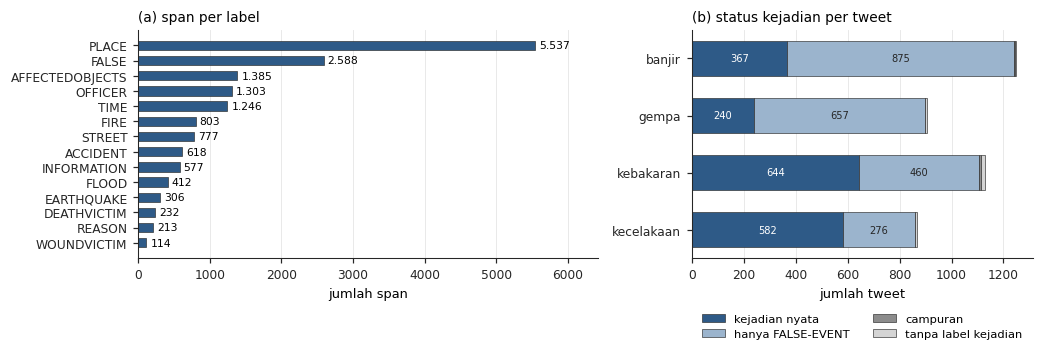

Rasio span label terbanyak dan tersedikit: 49 kali


In [23]:
DL = LP.distribusi_label(lama)
display(tabel(DL, 1))
fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.4), gridspec_kw=dict(width_ratios=[1.35, 1]))
x = DL.drop(index="O").sort_values("span", ascending=False)
PL.batang(ax[0], x["span"].values, [pendek(l) for l in x.index], PL.BIRU, xlabel="jumlah span")
ax[0].set_title("(a) span per label", loc="left")
SJ = LP.status_per_jenis(lama).reindex(columns=["nyata", "tidak nyata", "campuran", "tanpa kejadian"], fill_value=0)
SJ.columns = ["kejadian nyata", "hanya FALSE-EVENT", "campuran", "tanpa label kejadian"]
PL.tumpuk(ax[1], SJ, dict(zip(SJ.columns, [PL.BIRU, PL.BIRU_M, PL.ABU, PL.ABU_M])), "jumlah tweet", lambda v: fmt(v))
ax[1].set_title("(b) status kejadian per tweet", loc="left"); ax[1].legend(ncol=2, loc="upper center", bbox_to_anchor=(.5, -.2))
fig.tight_layout(); PL.save(fig, "5_2_distribusi_label"); plt.show()
print(f"Rasio span label terbanyak dan tersedikit: {x['span'].max() / x['span'].min():.0f} kali")

<div align="justify">

Label sangat timpang. O mencakup 69,3% token, dan di antara label bukan O, PLACE-ARG memiliki 5.537 *span*, sedangkan WOUNDVICTIM-ARG hanya 114 *span* (49 kali lebih sedikit). REASON-ARG (213) dan DEATHVICTIM-ARG (232) juga jarang. Gambar (b) menunjukkan bahwa sebagian besar *tweet* banjir (70%) dan gempa (73%) hanya memuat FALSE-EVENT, yaitu imbauan, doa, bantuan, atau berita yang bukan laporan kejadian. Sebaliknya, mayoritas *tweet* kebakaran (57%) dan kecelakaan (67%) adalah laporan kejadian nyata.

</div>

<div align="justify">

Dampaknya ada tiga. Pertama, *accuracy* dan *weighted F1* akan didominasi O dan PLACE-ARG, sehingga metrik utama harus *macro-F1* tanpa O. Kedua, seleksi *pseudo-label* perlu kuota per label agar label jarang tidak tertutup label besar. Ketiga, membedakan kejadian nyata dan FALSE-EVENT adalah bagian tersulit karena kata yang sama dipakai untuk keduanya.

</div>


### 5.3 Kualitas Data dan Bukti Masalah *Preprocessing*

<div align="justify">

Data tidak memiliki *missing value* karena setiap token pasti memiliki label. Oleh karena itu, pemeriksaan kualitas difokuskan pada teks, lokasi kejadian, label, dan kebocoran data.

</div>

#### 5.3.1 Normalisasi tidak seragam

<div align="justify">

Setiap *tweet* berlabel dicocokkan dengan pasangan paling miripnya pada teks hasil *preprocessing* dan teks mentah. Kamus normalisasi bawaan *dataset* dipelajari dari *tweet* tanpa label dengan membandingkan kata mentah dan kata hasil *preprocessing*. Pasangan kata dipakai bila diganti minimal lima kali dan konsisten minimal 90%. Pasangan yang mengubah arti tetap dicatat di kamus dengan kolom `keterangan`, tetapi tidak dipakai (Bab 5.3.2).

</div>


In [24]:
asal = R["taut"]["asal"].value_counts().rename("tweet").to_frame()
kamus = set(R["kamus"]["mentah"])
hit = pd.DataFrame([{"asal": R["taut"].loc[t["text_id"], "asal"], "token": len(t["tokens"]), "belum baku": sum(w.lower() in kamus for w in t["tokens"])}
                    for t in R["tweets"]]).groupby("asal").sum()
asal["% tweet"] = 100 * asal["tweet"] / asal["tweet"].sum()
asal["% token belum baku"] = 100 * hit["belum baku"] / hit["token"]
print(f"Kamus normalisasi: {len(kamus)} pasangan kata dari {fmt(R['n_kamus_tweet'])} tweet tanpa label")
display(tabel(asal, 2))
display(R["kamus"].head(8))

Kamus normalisasi: 561 pasangan kata dari 51.986 tweet tanpa label


,tweet,% tweet,% token belum baku
asal,,,
sama persis dengan preprocessed,3.208,"77,30","0,06"
lebih mirip teks mentah,596,"14,36","4,66"
lebih mirip preprocessed,346,"8,34","1,57"


,mentah,baku,diganti,utuh,muncul,konsisten (%),keterangan
0,yg,yang,6760,6759,6794,99.499558,dipakai
1,km,kamu,3791,3790,3894,97.354905,dipakai
2,ga,enggak,1397,1397,1427,97.897687,dipakai
3,kel,kelurahan,1293,1293,1402,92.225392,dipakai
4,pkl,pukul,1134,1134,1154,98.266898,dipakai
5,gak,enggak,1129,1129,1158,97.495682,dipakai
6,aja,saja,1100,1100,1137,96.745822,dipakai
7,udah,sudah,872,872,878,99.316629,dipakai


<div align="justify">

Sebanyak 3.208 *tweet* berlabel (77,3%) sama persis dengan teks hasil *preprocessing*, dan hanya 0,06% tokennya yang masih berupa kata tidak baku. Namun, 596 *tweet* (14,4%) lebih mirip teks mentah, dan 4,66% tokennya masih tidak baku, misalnya "yg", "ga", dan "udah". Artinya, sekitar satu dari tujuh *tweet* berlabel tidak ikut dinormalisasi, sehingga model melihat dua bentuk tulisan untuk kata yang sama. Kamus bawaan berisi 561 pasangan kata yang konsisten minimal 90%. Namun, sebagian pasangannya justru mengubah arti, dan yang paling sering adalah "km" menjadi "kamu" (3.791 kali).

</div>


#### 5.3.2 Singkatan dan angka yang berubah arti

<div align="justify">

Normalisasi bawaan mengganti singkatan dengan satu bentuk baku tanpa melihat konteks. Kasus terbesar adalah "km" yang diganti menjadi "kamu". Pada *tweet* krisis, "KM" lebih sering berarti kilometer jalan tol atau kapal motor, misalnya "KM Sinar Bangun".

</div>


In [25]:
rows = []
for t in R["tweets"]:
    j = R["jajar"][t["text_id"]]
    for i, w in enumerate(t["tokens"]):
        if w.lower() == "kamu":
            rows.append({"teks mentah": j["R"][j["peta"][i]] if j["peta"][i] is not None else "(tidak terjajar)",
                         "dikembalikan menjadi km": PR.km_salah(i, w, t["tokens"], j), "konteks": " ".join(t["tokens"][max(0, i - 4):i + 3])})
KM = pd.DataFrame(rows)
display(KM.groupby(["teks mentah", "dikembalikan menjadi km"]).size().rename("token").to_frame().sort_values("token", ascending=False).head(8))
display(KM[KM["dikembalikan menjadi km"]].drop_duplicates("teks mentah").head(4).reset_index(drop=True))

,,token
teks mentah,dikembalikan menjadi km,
KM,True,68
kamu,False,17
km,True,6
Kamu,False,3
Km,True,3
kmu,False,1


,teks mentah,dikembalikan menjadi km,konteks
0,KM,True,barat km 45 - kamu 48+200 arah
1,km,True,raya tol jombang mojokerto kamu 693+100 a
2,Km,True,tapanuli utara ) kedlmn:171 kamu dirasakan (


<div align="justify">

Dari 98 token "kamu" pada data berlabel, 77 berasal dari teks mentah "KM", "km", atau "Km" yang bertetangga dengan angka, misalnya "barat km 45" dan "kedalaman 171 km", atau berupa nama kapal seperti "KM Sinar Bangun". Token ini dikembalikan menjadi "km". Sebanyak 21 token lain memang ditulis "kamu" atau "kmu" pada teks mentah, sehingga dibiarkan.

</div>


In [26]:
AR = R["log"][R["log"].jenis.isin(["arti dikembalikan", "angka dikembalikan"])].assign(bukan_O=lambda d: d.label != "O")
ss = R["sebelum_sesudah"]["sesudah"]
AR["konteks"] = [" ".join(ss[t]["tokens"][max(0, ss[t]["tokens"].index(w) - 3):ss[t]["tokens"].index(w) + 4]) for t, w in zip(AR.text_id, AR.sesudah)]
SK, AN = AR[AR.jenis == "arti dikembalikan"], AR[AR.jenis == "angka dikembalikan"]
print(f"Singkatan dikembalikan: {len(SK)} token ({SK.bukan_O.sum()} di dalam span) | angka dikembalikan: {len(AN)} token ({AN.bukan_O.sum()} di dalam span)")
KB = R["kamus"].set_index("mentah")
display(R["kamus"].groupby("keterangan").agg(pasangan=("mentah", "size"), contoh=("mentah", lambda s: ", ".join(f"{m} → {KB.baku[m]}" for m in s[:5]))))
CONTOH = {"kk": "mengungsi", "kh": "mansyur", "gt": "cikarang", "bt": "ls", "jt": "lion", "cm": "banjir", "x": "sektor"}
display(pd.DataFrame([{"teks mentah": w, "hasil normalisasi": x.sebelum.mode()[0], "token": len(x), "bukan O": x.bukan_O.sum(),
                       "contoh": next((c for c in x.konteks if k in c), x.konteks.iloc[0])} for w, k in CONTOH.items() if len(x := SK[SK.sesudah == w])]))
pola = AN.sebelum.str.replace(r"\d", "9", regex=True) + " → " + AN.sesudah.str.replace(r"\d", "9", regex=True)
display(AN.assign(pola=pola, contoh=AN.sebelum + " → " + AN.sesudah).groupby("pola").agg(token=("label", "size"), bukan_O=("bukan_O", "sum"), contoh=("contoh", "first"))
        .sort_values("token", ascending=False).head(6).reset_index())
display(AN[AN.bukan_O].label.value_counts().rename("token angka di dalam span").to_frame().T)

Singkatan dikembalikan: 390 token (32 di dalam span) | angka dikembalikan: 820 token (453 di dalam span)


,pasangan,contoh
keterangan,,
dipakai,490,"yg → yang, km → kamu, ga → enggak, kel → kelurahan, pkl → pukul"
memecah satu kata,20,"gatau → enggak, gaada → enggak, gabisa → enggak, gada → enggak, gamau → enggak"
singkatan bergantung konteks,51,"pd → pada, d → di, dr → dari, si → sih, dah → deh"


,teks mentah,hasil normalisasi,token,bukan O,contoh
0,kk,kakak,5,2,hilang 16.783 jiwa/3.876 kk mengungsi di 33
1,kh,kah,1,1,dadakan di jalan kh mas mansyur gondrong
2,gt,begitu,12,0,: : setelah gt cikarang utama 2/3
3,bt,buat,9,0,ls dan 119.02 bt atau tepatnya berlokasi
4,jt,juta,4,1,pesawat lion air jt 610 hilang dan
5,cm,cuma,6,0,banjir sekitar 25 cm di jalan palang
6,x,kali,9,0,datang ke sektor x jagakarsa bahwa telah


,pola,token,bukan_O,contoh
0,999 → 99.99,183,4,200 → 02.00
1,9 → 99,99,85,9 → 09
2,9:99:99 → 99.99,85,79,0:16:15 → 16.15
3,99 → 9.9,61,48,40 → 4.0
4,9.99 → 99.99,58,39,2.45 → 02.45
5,9.9 → 99.99,32,25,4.3 → 04.30


label,TIME-ARG,STREET-ARG,INFORMATION-ARG,AFFECTEDOBJECTS-ARG,WOUNDVICTIM-ARG,DEATHVICTIM-ARG,OFFICER-ARG,PLACE-ARG
token angka di dalam span,266,102,61,7,6,5,3,3


<div align="justify">

Masalah yang sama terjadi pada singkatan lain. "KK" (kepala keluarga) menjadi "kakak", sehingga "3.876 KK mengungsi" terbaca "3.876 kakak mengungsi" (WOUNDVICTIM-ARG). "KH Mas Mansyur" menjadi "kah mas mansyur" (STREET-ARG), "GT Cikarang" (gerbang tol) menjadi "begitu cikarang", "BT" (bujur timur) menjadi "buat", dan "Lion Air JT 610" menjadi "lion air juta 610". Kamus normalisasi ikut menyebarkan kesalahan ini ke *tweet* yang mirip teks mentah, misalnya "si jago merah" menjadi "sih jago merah" (FIRE-EVENT) dan Kabupaten "Bener Meriah" menjadi "benar meriah" (PLACE-ARG). Selain itu, 20 pasangan kamus sebenarnya memecah satu kata menjadi dua, misalnya "gabisa" menjadi "enggak bisa". Kamus hanya menyalin kata pertamanya, sehingga "gabisa" menjadi "enggak" saja.

</div>

<div align="justify">

Angka juga rusak oleh *preprocessing* bawaan karena tanda titik dan titik dua dihapus atau dipindah. Jam "05.55" menjadi "555", "21.00" menjadi "0:21", dan magnitudo "7.1" menjadi "71". Akibatnya, jam pada *tweet* yang mirip teks mentah tetap ditulis seperti "05.55", sedangkan pada *tweet* lain menjadi "555" atau "0:21".

</div>

<div align="justify">

Oleh karena itu, 84 singkatan yang artinya bergantung konteks tidak dinormalisasi, dan token yang sudah dinormalisasi *dataset* dikembalikan ke bentuk mentahnya. Angka dikembalikan ke penulisan teks mentah bila digitnya sama. Kedua perbaikan hanya mengganti satu token dengan satu token, sehingga jumlah token dan label tidak berubah. Pada data berlabel, 390 token singkatan (32 di dalam *span*) dan 820 token angka (453 di dalam *span*, terutama 266 TIME-ARG, 102 STREET-ARG, dan 61 INFORMATION-ARG) dikembalikan. Sebanyak 151 token lain (35 di dalam *span*) tidak lagi diubah oleh kamus. Teks baru pada inferensi juga diproses dari teks mentah, sehingga bentuk angkanya sama dengan data latih.

</div>


#### 5.3.3 *Typo* dan kata menempel

<div align="justify">

Kandidat *typo* dicari dari kata yang jarang muncul (paling banyak tiga kali pada 56 ribu *tweet* hasil *preprocessing*), tetapi berjarak satu huruf dari kata yang sering muncul. Kandidat diperiksa satu per satu, sedangkan nama tempat, nama orang, kata daerah, dan kata gaul yang memang ditulis begitu tidak dianggap *typo*. Kata menempel muncul ketika tanda baca atau baris baru dihapus, misalnya "Pelosok\nSukabumi" menjadi "pelosoksukabumi", atau ketika penulis *tweet* menulis "kab" dan "jl" tanpa spasi.

</div>


In [27]:
log = R["log"]
TY = log[log.jenis == "typo"].groupby(["sebelum", "sesudah"]).size().rename("token").sort_values(ascending=False).reset_index()
TY["muncul (sebelum)"] = TY["sebelum"].map(lambda w: PR.FREK[w.lower()])
TY["muncul (sesudah)"] = TY["sesudah"].map(lambda w: PR.FREK[w.lower()])
GB = log[log.jenis == "kata menempel"]
print(f"Typo: {len(PR.KETIK)} pasangan di kamus, {TY.token.sum()} token berlabel ({len(TY)} bentuk)")
print(f"Kata menempel: {len(GB)} token berlabel, {(GB.label != 'O').sum()} di antaranya berada di dalam span")
display(TY.head(8))
display(GB[["text_id", "sebelum", "sesudah", "label", "sumber"]].drop_duplicates("sebelum").sample(8, random_state=3).reset_index(drop=True))

Typo: 211 pasangan di kamus, 220 token berlabel (210 bentuk)
Kata menempel: 238 token berlabel, 49 di antaranya berada di dalam span


,sebelum,sesudah,token,muncul (sebelum),muncul (sesudah)
0,ritcher,richter,6,26,392
1,kperluan,keperluan,3,3,51
2,ahirnya,akhirnya,2,3,321
3,mantraman,matraman,2,2,118
4,bgitu,begitu,2,0,859
5,acarah,acara,1,1,153
6,alalh,allah,1,1,642
7,akhirmya,akhirnya,1,2,321


,text_id,sebelum,sesudah,label,sumber
0,BAN-01542,hoaxdari,hoax dari,O,teks mentah
1,BAN-01130,hadirmelampau,hadir melampau,O,teks mentah
2,GEM-01486,diatas,di atas,O,preposisi menempel
3,KEC-00336,wibmohon,wib mohon,O,teks mentah
4,BAN-01076,sungsangkota,sungsang kota,PLACE-ARG,teks mentah
5,KEC-00195,didepan,di depan,O,preposisi menempel
6,BAN-01141,monaswah,monas wah,O,teks mentah
7,GEM-01556,warganegara,warga negara,O,kamus kata menempel


<div align="justify">

Kamus *typo* berisi 211 pasangan hasil pemeriksaan manual, dan 220 token berlabel diperbaiki. Contoh paling sering adalah "ritcher" menjadi "richter" (6 token). Bentuk "ritcher" muncul 26 kali di seluruh *dataset*, sedangkan bentuk benarnya muncul 392 kali. Kata menempel ditemukan pada 238 token berlabel: 127 dari penjajaran dengan teks mentah, 75 berupa preposisi yang menempel pada kata lokasi ("dilokasi", "didepan"), dan 36 dari kamus. Sebanyak 49 di antaranya berada di dalam *span*, misalnya "mohtoha" yang seharusnya "moh toha" (PLACE-ARG), sehingga pemisahannya ikut memperbaiki batas *span*.

</div>


#### 5.3.4 *Tweet* kejadian di luar Indonesia

<div align="justify">

Sebagian *tweet* membahas kejadian di Malaysia, Jepang, atau negara lain. Aturan lokasi diterapkan sama untuk data latih, validasi, uji, dan *pool*. Sebuah *tweet* dinyatakan luar Indonesia bila (a) *span* PLACE-ARG atau STREET-ARG yang paling dekat dengan kata kejadian menyebut tempat asing, (b) *tweet* berbahasa Melayu memuat kosakata khas Malaysia ("pusat pemindahan", "kenderaan", "bomba", "JKR") tanpa satu pun tempat Indonesia, atau (c) teks menyebut tempat asing tanpa satu pun tempat Indonesia. Nama yang ambigu, misalnya Labuan (Banten atau Malaysia), hanya dihitung asing bila *tweet*-nya berbahasa Melayu.

</div>


split,latih,validasi,uji
aturan,,,
kosakata Malaysia tanpa tempat Indonesia,15,3,9
lokasi kejadian di luar Indonesia,85,22,33
"tanpa lokasi kejadian jelas, hanya tempat asing",16,5,9
tempat asing di teks tanpa tempat Indonesia,3,1,3
total,119,31,54


,text_id,split,aturan,tempat asing,teks
0,BAN-00004,latih,lokasi kejadian di luar Indonesia,mersing,ayuh kita bersama menjayakan misi bantuan mangsa banjir di mersing pada 3 jan ( 9 pagi - 1 petang ) di ibu...
1,BAN-00011,latih,lokasi kejadian di luar Indonesia,membakut,anifah lawat mangsa banjir di membakut -
2,BAN-00020,latih,"tanpa lokasi kejadian jelas, hanya tempat asing",kuala lipis,8 januari 2018 banjir di kg chegar perah kuala lipis
3,BAN-00082,uji,"tanpa lokasi kejadian jelas, hanya tempat asing",kuala marong,pemandangan dari atas kwsn perkhemahan kuala marong selepas mengalami musim hujan dan banjir kini keadaan ...
4,BAN-00005,uji,kosakata Malaysia tanpa tempat Indonesia,pemindahan,anak buah bantu set up pusat pemindahan banjir di balairaya tg bungor syabas ! ! !
5,BAN-00008,latih,kosakata Malaysia tanpa tempat Indonesia,mangsa2; pemindahan; rela,anggota rela pekan sedang membantu memberi sajian makanan kepada mangsa2 banjir di pusat pemindahan sk mer...
6,BAN-00054,latih,tempat asing di teks tanpa tempat Indonesia,seremban,disebabkan banjir kilat diantara stesen bangi > btg benar komuter ke laluan seremban/sg gadut/tampin akan ...
7,GEM-01204,uji,tempat asing di teks tanpa tempat Indonesia,china,tahun 1556830 000 nyawa manusia diragut sekaligus dengan gempa bumi di shaanxi china al-quran hud:94


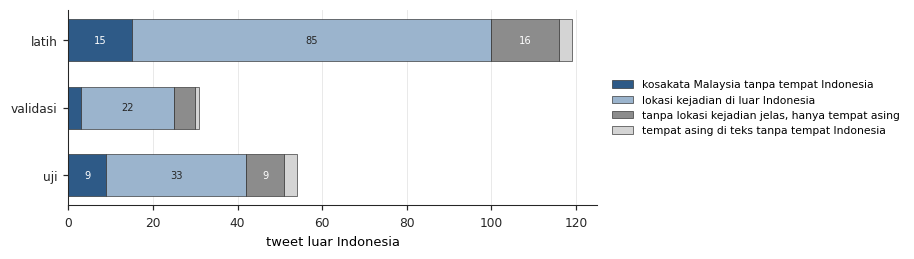

In [28]:
ID = {"train": "latih", "val": "validasi", "test": "uji"}
LOK = R["lokasi"].replace({"split": ID})
TL = LOK[LOK.keputusan == "luar Indonesia"].groupby(["aturan", "split"]).size().unstack(fill_value=0).reindex(columns=["latih", "validasi", "uji"])
TL.loc["total"] = TL.sum()
display(TL)
display(LOK[LOK.keputusan == "luar Indonesia"].groupby("aturan").head(2)[["text_id", "split", "aturan", "tempat asing", "teks"]].reset_index(drop=True))
fig, ax = plt.subplots(figsize=(6.2, 2.3))
PL.tumpuk(ax, TL.drop(index="total").T, dict(zip(TL.index[:-1], [PL.BIRU, PL.BIRU_M, PL.ABU, PL.ABU_M])), "tweet luar Indonesia", lambda v: fmt(v))
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, .5))
PL.save(fig, "5_3_luar_indonesia"); plt.show()

<div align="justify">

Sebanyak 204 *tweet* berlabel membahas kejadian di luar Indonesia: 119 di data latih, 31 di data validasi, dan 54 di data uji. Sebagian besar terdeteksi dari *span* lokasi kejadian (aturan a). Aturan teks yang baru menambah 34 *tweet*, misalnya "pusat pemindahan banjir di balairaya tg bungor" dan "berlaku kebakaran kenderaan di km 40.6 hala timur" yang berasal dari Malaysia, serta gempa di Shaanxi, China. Pada versi sebelumnya, 12 *tweet* luar Indonesia masih tersisa di data uji. Aturan yang sama dipakai untuk semua *split*, sehingga data latih dan data uji kini memiliki definisi domain yang sama.

</div>


#### 5.3.5 *Tweet* tanpa label kejadian, duplikat, dan kebocoran data


In [29]:
NE = R["tanpa_kejadian"].replace({"split": ID})
display(pd.crosstab(NE["kategori"], NE["split"], margins=True, margins_name="total"))
BC = R["bocor"].replace({"split tweet berlabel": ID})
display(pd.crosstab(BC["sebab"], BC["split tweet berlabel"], margins=True, margins_name="total"))
mt = R["mirip_test"]
print(f"Tweet uji dengan cosine ≥ 0,8 terhadap data latih dan validasi: {(mt >= .8).sum()} dari {len(mt)}")

split,latih,uji,validasi,total
kategori,,,,
"ada kata kejadian, tanpa argumen",7,2,0,9
kemungkinan label kejadian terlewat,13,9,4,26
kemungkinan memang bukan kejadian,1,0,0,1
total,21,11,4,36


split tweet berlabel,lain,latih,uji,validasi,total
sebab,,,,,
"mirip ≥ 0,8",1,0,0,0,1
tweet berlabel itu sendiri,0,211,76,50,337
total,1,211,76,50,338


Tweet uji dengan cosine ≥ 0,8 terhadap data latih dan validasi: 38 dari 946


<div align="justify">

Ada 36 *tweet* tanpa label kejadian, dan 26 di antaranya kemungkinan labelnya terlewat karena memuat kata kejadian dan argumen. Hanya 21 *tweet* di data latih yang dikeluarkan agar data validasi dan uji tetap utuh. Sebanyak 337 *tweet* tanpa label ternyata adalah *tweet* berlabel itu sendiri (211 dari data latih, 50 dari validasi, dan 76 dari uji), sehingga dibuang dari *pool* untuk mencegah kebocoran. Sebanyak 38 dari 946 *tweet* uji (4,0%) sangat mirip dengan *tweet* latih atau validasi (cosine ≥ 0,8). *Tweet* ini dibiarkan karena berasal dari kejadian yang berbeda, tetapi dicatat sebagai risiko skor uji sedikit optimistis.

</div>


#### 5.3.6 Konvensi label yang tidak konsisten

<div align="justify">

Kesalahan juga muncul pada label. Pemeriksaan mencakup kata yang bersebelahan dengan sebuah *span* dan kadang ikut masuk *span*, kadang tidak. Kata yang masuk *span* antara 25% dan 75% kemunculannya menandakan konvensi batas yang tidak konsisten. Temuan ini menjadi alasan audit label untuk RQ4 pada Bab 8.4.

</div>


In [30]:
KV = AU.konvensi(d["train"])
display(tabel(KV.head(10).set_index(["kata", "label"])[["masuk span", "di luar span", "% masuk"]], 1))
print(f"Pasangan kata dan label dengan konvensi tidak konsisten (n ≥ 8): {len(KV)}")

,,masuk span,di luar span,% masuk
kata,label,,,
dan,OFFICER-ARG,"13,0","32,0","28,9"
sebuah,AFFECTEDOBJECTS-ARG,"23,0","12,0","65,7"
provinsi,PLACE-ARG,"12,0","12,0","50,0"
kawasan,PLACE-ARG,"15,0","8,0","65,2"
tim,OFFICER-ARG,"13,0","8,0","61,9"
hari,TIME-ARG,"11,0","9,0","55,0"
di,REASON-ARG,"8,0","12,0","40,0"
berkekuatan,INFORMATION-ARG,"5,0","15,0","25,0"
tahun,TIME-ARG,"14,0","5,0","73,7"


Pasangan kata dan label dengan konvensi tidak konsisten (n ≥ 8): 33


<div align="justify">

Ada 33 pasangan kata dan label yang batasnya tidak konsisten. Kata "dan" di sebelah OFFICER-ARG masuk *span* 13 kali dan berada di luar *span* 32 kali, "tahun" di sebelah TIME-ARG masuk 74% kemunculannya, dan "berkekuatan" di sebelah INFORMATION-ARG hanya masuk 25%. Model yang belajar dari data ini akan mendapat sinyal yang saling bertentangan, dan skor evaluasi ikut terpengaruh karena data validasi dan uji memakai konvensi yang sama tidak konsistennya.

</div>


#### 5.3.7 Keputusan

| Temuan | Keputusan |
|:-|:-|
| Normalisasi hanya pada sebagian *tweet* | kamus bawaan diterapkan pada semua *tweet* berlabel yang belum dinormalisasi |
| "KM" menjadi "kamu" | dikembalikan menjadi "km" berdasarkan teks mentah dan konteks angka, arah mata angin, atau kapal |
| Singkatan lain dan angka yang berubah arti | dikembalikan ke bentuk teks mentah, dan singkatan tersebut tidak dipakai di kamus |
| *Typo* dan kata menempel | diperbaiki dengan kamus hasil pemeriksaan manual dan penjajaran teks mentah |
| *Tweet* luar Indonesia | dikeluarkan dari data latih, validasi, uji, dan *pool* dengan aturan yang sama |
| *Tweet* tanpa label kejadian | dikeluarkan dari data latih |
| *Tweet* *pool* yang sama atau mirip *tweet* berlabel | dibuang dari *pool* |
| Label tidak konsisten | diaudit untuk menjawab RQ4 pada Bab 8.4 |

### 5.4 Analisis Hubungan Fitur


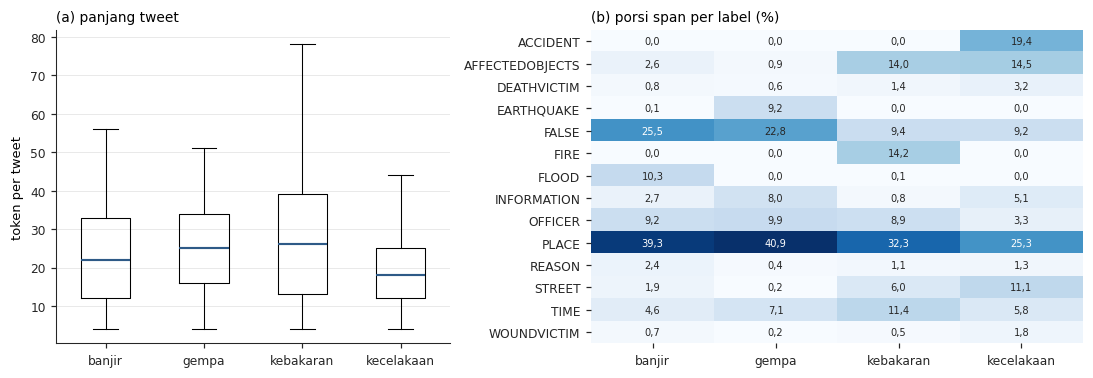

,muncul,nyata,FALSE-EVENT,lain
kata,,,,
banjir,1.458,"28,2","68,9","2,9"
gempa,1.132,"26,1","64,3","9,5"
kebakaran,1.288,"54,5","38,6","6,9"
terbakar,81,"91,4","7,4","1,2"
kecelakaan,906,"66,0","31,9","2,1"
tabrakan,10,"50,0","0,0","50,0"


In [31]:
LJ = LP.label_per_jenis(lama)
PJ = LP.panjang(lama)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw=dict(width_ratios=[1, 1.25]))
urut = list(C.EVENT_CODES.values())
ax[0].boxplot([PJ[PJ.jenis == j].token for j in urut], tick_labels=urut, widths=.5, showfliers=False,
              medianprops=dict(color=PL.BIRU, lw=1.4), boxprops=dict(lw=.7), whiskerprops=dict(lw=.7), capprops=dict(lw=.7))
ax[0].set_ylabel("token per tweet"); ax[0].set_title("(a) panjang tweet", loc="left")
PL.heatmap(ax[1], LJ[urut].values, [pendek(l) for l in LJ.index], urut, fmt="{:.1f}", rot=0)
ax[1].set_title("(b) porsi span per label (%)", loc="left")
fig.tight_layout(); PL.save(fig, "5_4_hubungan_fitur"); plt.show()
display(tabel(LP.kata_kejadian(lama), 1))

<div align="justify">

*Tweet* kecelakaan paling pendek (median 18 token), sedangkan *tweet* kebakaran paling panjang dan paling beragam (median 26, maksimum 126 token). Porsi label juga bergantung pada jenis kejadian. STREET-ARG mencapai 11,1% *span* pada kecelakaan karena banyak laporan lalu lintas tol, AFFECTEDOBJECTS-ARG mencapai 14% pada kebakaran dan kecelakaan, dan INFORMATION-ARG lebih banyak pada gempa (8%) karena memuat magnitudo dan kedalaman. FALSE-EVENT mencapai 25,5% *span* banjir dan 22,8% *span* gempa.

</div>

<div align="justify">

Tabel kata kejadian memperlihatkan bahwa kata yang sama dapat berlabel nyata atau FALSE-EVENT. Kata "banjir" 68,9% berlabel FALSE-EVENT dan "gempa" 64,3%, sedangkan "kecelakaan" 66,0% nyata dan "terbakar" 91,4% nyata. Oleh karena itu, status kejadian tidak dapat ditebak dari katanya saja, dan model harus membaca konteks. Perbedaan porsi label antarjenis juga menjadi alasan uji lintas kejadian pada Bab 8.3.

</div>


### 5.5 Distribusi Data Latih, Validasi, dan Uji


,latih,validasi,uji
gempa,472,122,232
kebakaran,692,157,245
banjir,750,195,226
kecelakaan,466,125,243


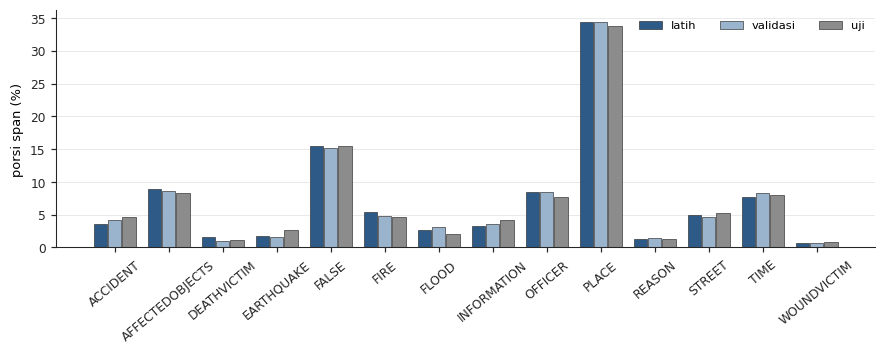

tahun                2018  2019  2020  2021  2022  2023  tidak terpetakan
bagian   jenis                                                           
latih    banjir       285   463     0     0     0     0                 2
         gempa        454    17     0     0     0     0                 1
         kebakaran      0     1   670     0     0     0                21
         kecelakaan   449     0     0     0     0     0                17
pool     banjir        66    47   136   132   107   109                 0
         gempa         86    98    77   125   137   129                 0
         kebakaran    794   777   180   814   782     0                 0
         kecelakaan   215   327   286     0     0     0                 0
uji      banjir        83   143     0     0     0     0                 0
         gempa        225     5     0     0     0     0                 2
         kebakaran      0     0   234     0     0     0                11
         kecelakaan   234     0     0     0     0     0                 9
validasi banjir        62   133     0     0     0     0                 0
         gempa        119     2     0     0     0     0                 1
         kebakaran      3     0   149     0     0     0                 5
         kecelakaan   120     0     0     0     0     0                 5

In [32]:
SP, JN = LP.per_split({"latih": d["train"], "validasi": d["filter_dev"] + d["stop_dev"], "uji": d["test"]})
display(JN.rename(index=C.EVENT_CODES))
fig, ax = plt.subplots(figsize=(9.6, 2.8))
PL.kelompok(ax, SP.rename(index=pendek), {"latih": PL.BIRU, "validasi": PL.BIRU_M, "uji": PL.ABU}, ylabel="porsi span (%)")
ax.tick_params(axis="x", rotation=40); ax.legend(ncol=3)
PL.save(fig, "5_5_distribusi_split"); plt.show()
PER = LK.periode().assign(tahun=lambda x: x.bulan.str[:4])
display(pd.crosstab([PER.bagian, PER.jenis], PER.tahun.fillna("tidak terpetakan")))

<div align="justify">

Porsi setiap label hampir sama di ketiga *split*. PLACE-ARG mencakup 34,3%, 34,4%, dan 33,8% *span*, sedangkan FALSE-EVENT 15,5%, 15,2%, dan 15,4%. Perbedaan terbesar ada pada EARTHQUAKE-EVENT (1,7% di data latih dan 2,7% di data uji). Data uji diambil sama banyak per jenis kejadian, sehingga porsi gempa di data uji lebih besar. Dari sisi waktu, setiap jenis kejadian berasal dari periodenya sendiri: kebakaran dari 2020, banjir dari 2018 dan 2019, gempa dan kecelakaan dari 2018. Periode data latih, validasi, dan uji sama, sehingga tidak ada pergeseran waktu antar*split*. Sebaliknya, sekitar 43% *pool* berasal dari 2021 sampai 2023, sehingga *pseudo-label* sebagian berasal dari periode yang belum pernah dilihat model.

</div>


<a id="bab-6"></a>
## 6. *Preprocessing* dan *Feature Engineering*

### 6.1 Langkah Perbaikan dan Penelitian Pendukung

| Masalah | Perbaikan | Alasan |
|:-|:-|:-|
| Normalisasi tidak seragam | kamus bawaan *dataset* diterapkan pada *tweet* yang belum dinormalisasi | satu kata tidak boleh muncul dalam dua bentuk yang dianggap berbeda oleh model |
| "KM" menjadi "kamu" | "kamu" dikembalikan menjadi "km" bila teks mentahnya "KM", bertetangga dengan angka atau arah mata angin, atau didahului kata kapal dan kecelakaan | arti "km" dapat dipulihkan dari huruf kapital dan angka di teks mentah |
| Singkatan dan angka yang berubah arti | 84 singkatan yang artinya bergantung konteks tidak dinormalisasi dan dikembalikan ke bentuk mentah; angka dikembalikan ke penulisan teks mentah bila digitnya sama; pasangan kamus yang memecah satu kata tidak dipakai | kamus tanpa konteks mengubah arti, sehingga bentuk mentah lebih aman |
| *Typo* | kamus *typo* hasil pemeriksaan manual atas kandidat berjarak satu huruf | kandidat otomatis juga memuat nama tempat dan kata daerah, sehingga harus diperiksa manual |
| Kata menempel | token dipisah mengikuti teks mentah atau kamus; setiap bagian mewarisi labelnya, kecuali kata fungsi yang diberi O | kata menempel tidak dikenali *tokenizer* dan memotong batas *span* |
| *Tweet* luar Indonesia | dikeluarkan dari semua *split* dan *pool* dengan aturan yang sama | *dataset* disusun untuk kejadian di Indonesia [2](#ref-2) |
| Tanpa label kejadian | dikeluarkan dari data latih | *tweet* yang kata kejadiannya tidak berlabel mengajarkan bahwa kata kejadian adalah O |
| Kebocoran *pool* | *tweet* *pool* yang identik atau mirip (cosine ≥ 0,8) dengan *tweet* berlabel dibuang | kebocoran data menaikkan skor secara semu [8](#ref-8) |

<div align="justify">

Pemisahan kata menempel adalah satu-satunya perbaikan yang menambah jumlah token. Perbaikan lain hanya mengganti satu kata dengan satu kata, sehingga label tetap.

</div>

### 6.2 Hasil Perbaikan


In [33]:
UB = pd.concat([R["log"].assign(data="berlabel"), R["log_pool"].assign(data="pool")]).groupby(["jenis", "data"]).size().unstack(fill_value=0)
UB.loc["total"] = UB.sum()
display(UB)
sb = R["sebelum_sesudah"]
for jenis in ("km menjadi kamu", "arti dikembalikan", "angka dikembalikan", "typo", "kata menempel", "normalisasi"):
    x = log[(log.jenis == jenis) & log.text_id.map(lambda i: len(sb["sebelum"][i]["tokens"]) <= 25)]
    tid = x.text_id.value_counts().index[0]
    print(f"[{jenis}] {tid}\n  sebelum: {' '.join(sb['sebelum'][tid]['tokens'])[:150]}\n  sesudah: {' '.join(sb['sesudah'][tid]['tokens'])[:150]}")

data,berlabel,pool
jenis,,
angka dikembalikan,820,880
arti dikembalikan,390,829
kata menempel,238,248
km menjadi kamu,77,365
normalisasi,606,0
typo,220,9
total,2351,2331


[km menjadi kamu] KEC-01064
  sebelum: kecelakaan dua mobil terbalik di kamu 1- 900 macet mulai kamu 0-00 tol jakarta- cikampek arah cikampek
  sesudah: kecelakaan dua mobil terbalik di km 1- 900 macet mulai km 0-00 tol jakarta- cikampek arah cikampek
[arti dikembalikan] KEC-01380
  sebelum: jorr dari bekasi menuju cilandak macet dari km 41 kata mbah google sih ada kecelakaan di sktr km38 tapi aku belum lewatin
  sesudah: jorr dr bekasi menuju cilandak macet dr km 41 kata mbah google si ada kecelakaan d sktr km38 tapi aku belum lewatin
[angka dikembalikan] GEM-00128
  sebelum: info gempa bumi mag 32 sr yang berlokasi 86 lu dan 12244 buat atau di 14 km selatan
  sesudah: info gempa bumi mag 3.2 sr yang berlokasi 0.86 lu dan 122.44 bt atau di 14 km selatan
[typo] BAN-01291
  sebelum: kondisi banjir di perumahan taman surya agung desa wage kecamatan taman kabupaten sidoarjo ketinggian air sudah mncapai lutut orang dwasa
  sesudah: kondisi banjir di perumahan taman surya agung desa wage ke

<div align="justify">

Pada data berlabel, 2.351 token diperbaiki: 820 angka dan 390 singkatan dikembalikan ke bentuk mentah, 606 karena normalisasi, 238 karena kata menempel, 220 karena *typo*, dan 77 karena "kamu" dikembalikan menjadi "km". Pada *pool*, 2.331 token diperbaiki, terutama angka (880), singkatan (829), dan "km" (365). Normalisasi tidak diterapkan pada *pool* karena *pool* diambil dari teks hasil *preprocessing* yang sudah dinormalisasi. Contoh di bawah tabel memperlihatkan bahwa setiap perbaikan hanya mengubah kata yang bermasalah, sedangkan bagian lain *tweet* tetap.

</div>


,split CP1,luar Indonesia,tanpa label kejadian,dipakai
latih,2520,119,21,2380
validasi,630,31,0,599
uji,1000,54,0,946


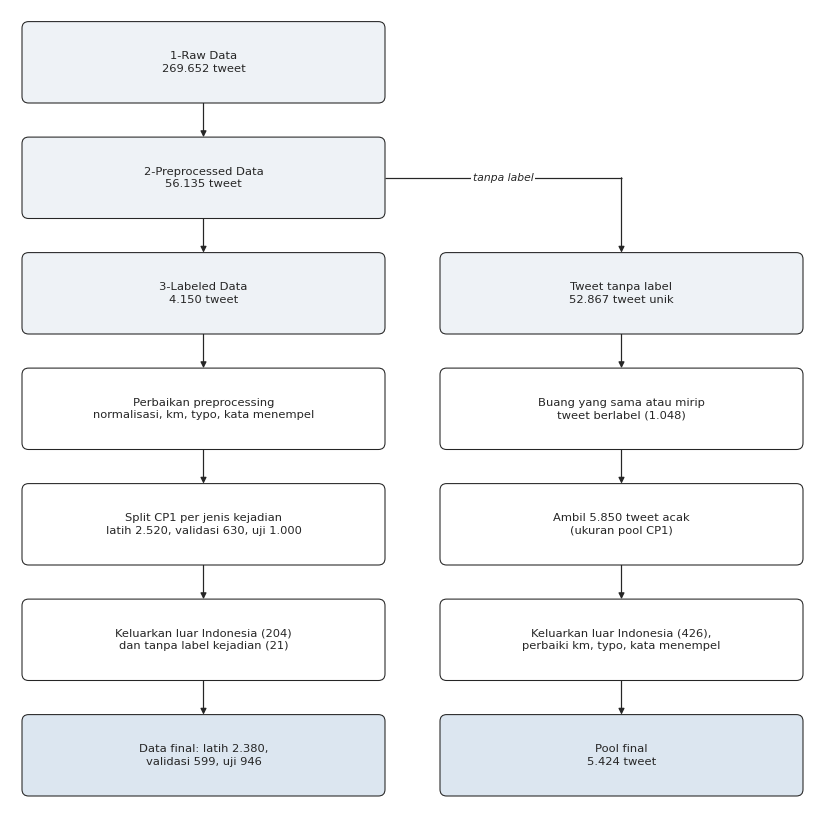

In [34]:
display(R["final"])
n, ps = R["isi"].loc["total"], R["pool_stat"]
nodes = {"raw": dict(x=1.6, y=6.3, teks=f"1-Raw Data\n{fmt(n['1-Raw Data (tweet)'])} tweet", jenis="data"),
         "pre": dict(x=1.6, y=5.25, teks=f"2-Preprocessed Data\n{fmt(n['2-Preprocessed Data (tweet)'])} tweet", jenis="data"),
         "lab": dict(x=1.6, y=4.2, teks=f"3-Labeled Data\n{fmt(n['3-Labeled Data (tweet)'])} tweet", jenis="data"),
         "fix": dict(x=1.6, y=3.15, teks="Perbaikan preprocessing\nnormalisasi, km, typo, kata menempel"),
         "split": dict(x=1.6, y=2.1, teks="Split CP1 per jenis kejadian\nlatih 2.520, validasi 630, uji 1.000"),
         "buang": dict(x=1.6, y=1.05, teks=f"Keluarkan luar Indonesia ({int(R['final']['luar Indonesia'].sum())})\ndan tanpa label kejadian ({int(R['final']['tanpa label kejadian'].sum())})"),
         "final": dict(x=1.6, y=0, teks=f"Data final: latih {fmt(len(d['train']))},\nvalidasi {len(d['filter_dev']) + len(d['stop_dev'])}, uji {len(d['test'])}", jenis="hasil"),
         "pool": dict(x=5.4, y=4.2, teks=f"Tweet tanpa label\n{fmt(ps['unique_candidates'])} tweet unik", jenis="data"),
         "bocor": dict(x=5.4, y=3.15, teks=f"Buang yang sama atau mirip\ntweet berlabel ({fmt(ps['removed_similar'] + ps['dibuang_bocor'])})"),
         "cp1": dict(x=5.4, y=2.1, teks=f"Ambil {fmt(ps['pool_cp1'])} tweet acak\n(ukuran pool CP1)"),
         "pluar": dict(x=5.4, y=1.05, teks=f"Keluarkan luar Indonesia ({ps['luar_indonesia']}),\nperbaiki km, typo, kata menempel"),
         "pfinal": dict(x=5.4, y=0, teks=f"Pool final\n{fmt(ps['dipakai'])} tweet", jenis="hasil")}
for v in nodes.values():
    v.update(w=3.3, h=.74)
edges = [("raw", "pre"), ("pre", "lab"), ("lab", "fix"), ("fix", "split"), ("split", "buang"), ("buang", "final"),
         dict(a="pre", b="pool", dari="kanan", ke="atas", label="tanpa label"), ("pool", "bocor"), ("bocor", "cp1"), ("cp1", "pluar"), ("pluar", "pfinal")]
fig = PL.diagram(nodes, edges)
PL.save(fig, "6_2_alur_data"); plt.show()

<div align="justify">

Dari 4.150 *tweet* berlabel, 3.925 *tweet* dipakai: 2.380 untuk data latih, 599 untuk validasi, dan 946 untuk uji. Porsi *tweet* luar Indonesia hampir sama di ketiga *split*, yaitu 4,7% (latih), 4,9% (validasi), dan 5,4% (uji). Dari 52.867 *tweet* tanpa label yang unik, 1.048 dibuang karena sama atau mirip dengan *tweet* berlabel, 5.850 diambil secara acak mengikuti ukuran *pool* *Checkpoint* 1, dan 426 *tweet* luar Indonesia dikeluarkan. *Pool* final berisi 5.424 *tweet*.

</div>


### 6.3 Tokenisasi *Subword* dan Penyelarasan Label

<div align="justify">

Model menerima token *subword* dari *tokenizer* setiap *model bahasa*. Label hanya ditempelkan pada *subword* pertama setiap kata, dan prediksi kata diambil dari *subword* tersebut. *Tweet* yang lebih panjang dari 512 *subword* dipotong, tetapi pada data ini tidak ada *tweet* yang terpotong.

</div>


In [35]:
enc = S.encoder(C.BACKBONE_PAPER)
t = d["train"][5]
sub = [enc.tok.tokenize(w) for w in t["tokens"][:10]]
display(pd.DataFrame({"kata": t["tokens"][:10], "subword": [" ".join(s) for s in sub], "label kata": t["labels"][:10],
                      "label subword": [" ".join([l] + ["(diabaikan)"] * (len(s) - 1)) for s, l in zip(sub, t["labels"][:10])]}))
pj = {nama: max(len(sum((enc.tok.tokenize(w) for w in x["tokens"]), [])) for x in d[nama]) for nama in ("train", "stop_dev", "test")}
print("subword terpanjang per split:", pj)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


,kata,subword,label kata,label subword
0,malam,malam,O,O
1,tadi,tadi,O,O
2,kebakaran,kebakaran,FALSE-EVENT,FALSE-EVENT
3,di,di,O,O
4,jalan,jalan,PLACE-ARG,PLACE-ARG
5,antasan,antas ##an,PLACE-ARG,PLACE-ARG (diabaikan)
6,kecil,kecil,PLACE-ARG,PLACE-ARG
7,dekat,dekat,INFORMATION-ARG,INFORMATION-ARG
8,jembatan,jembatan,INFORMATION-ARG,INFORMATION-ARG
9,mesjid,mesjid,INFORMATION-ARG,INFORMATION-ARG


subword terpanjang per split: {'train': 177, 'stop_dev': 69, 'test': 126}


<div align="justify">

Kata yang tidak ada di kosakata IndoBERT dipecah menjadi beberapa *subword*, misalnya "antasan" menjadi "antas" dan "##an". Hanya *subword* pertama yang membawa label, sehingga jumlah prediksi selalu sama dengan jumlah kata. *Tweet* terpanjang berisi 177 *subword*, jauh di bawah batas 512, sehingga tidak ada token yang terpotong.

</div>


<a id="bab-7"></a>
## 7. *Baseline*

<div align="justify">

Model awal menggunakan representasi *Transformer* dan lapisan klasifikasi linear pada *subword* pertama. Eksperimen CP2 mencakup IndoBERT, IndoBERTweet, IndoBERT IndoNLU, dan XLM-R. Seluruh model awal CP2 dilatih 15 *epoch* tetap, berbeda dari batas 10 *epoch* pada reproduksi CP1. R-Drop menjadi pembanding regularisasi sebelum penambahan *pseudo-label*.

</div>


In [36]:
S.jalankan_semua(S.antrean("awal"))
display(LP.rerata(LP.metrik("val", ("awal",))))

[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a
[awal IndoBERTweet seed42] memakai hasil tersimpan runs/e92485f00487
[awal IndoBERTweet seed43] memakai hasil tersimpan runs/e1ff1a83f0d9
[awal IndoBERTweet seed44] memakai hasil tersimpan runs/14d89dd25b28
[awal IndoBERT IndoNLU seed42] memakai hasil tersimpan runs/b1d67f8b3456
[awal IndoBERT IndoNLU seed43] memakai hasil tersimpan runs/ee51bb52d281
[awal IndoBERT IndoNLU seed44] memakai hasil tersimpan runs/02a5c87a025f
[awal XLM-R seed42] memakai hasil tersimpan runs/76e4daa94aa9
[awal XLM-R seed43] memakai hasil tersimpan runs/b1a090cd3527
[awal XLM-R seed44] memakai hasil tersimpan runs/006acd51eb44


,,accuracy,precision,recall,macro-F1,weighted F1,span F1
backbone,model,,,,,,
IndoBERT,awal,"0,9095 ± 0,001","0,7377 ± 0,0021","0,7896 ± 0,0047","0,7597 ± 0,0023","0,9104 ± 0,0008","0,756 ± 0,0016"
IndoBERTweet,awal,"0,909 ± 0,0016","0,731 ± 0,0058","0,7781 ± 0,0079","0,7497 ± 0,0058","0,9092 ± 0,0014","0,7491 ± 0,0036"
IndoBERT IndoNLU,awal,"0,9122 ± 0,0022","0,7533 ± 0,0113","0,7572 ± 0,0077","0,7516 ± 0,0087","0,9113 ± 0,0022","0,7505 ± 0,0064"
XLM-R,awal,"0,9055 ± 0,0018","0,7256 ± 0,0059","0,7908 ± 0,0023","0,7524 ± 0,0046","0,9065 ± 0,0017","0,7498 ± 0,0021"


<div align="justify">

Keempat *model bahasa* menghasilkan *accuracy* 0,906 sampai 0,912 dan *weighted F1* 0,907 sampai 0,911, tetapi *macro-F1* tanpa O hanya 0,750 sampai 0,760. Selisih sekitar 0,15 ini muncul karena *accuracy* dan *weighted F1* didominasi token O, sedangkan *macro-F1* tanpa O memberi bobot sama pada label jarang. IndoBERT memperoleh *macro-F1* tertinggi (0,7597 ± 0,0023), tetapi selisihnya dengan *model bahasa* lain hanya 0,007 sampai 0,010, sebanding dengan simpangan baku antar*seed* IndoBERT IndoNLU (0,0087). Pada IndoBERT dan XLM-R, *recall* lebih tinggi daripada *precision* (0,7896 dibanding 0,7377 dan 0,7908 dibanding 0,7256), sehingga kesalahan kedua model lebih banyak berupa *false positive*.

</div>


### 7.2 R-Drop

<div align="justify">

Liang dkk. [10](#ref-10) mengusulkan *Regularized Dropout* (R-Drop). *Input* yang sama melewati dua *forward pass* dengan bobot bersama dan *mask* *dropout* berbeda. Rata-rata *cross-entropy* mengukur kecocokan terhadap label, sedangkan *Kullback–Leibler* (KL) divergence simetris mengurangi perbedaan kedua distribusi.

</div>

$$L=\frac{L_1+L_2}{2}+\beta D_{\rm sim},\qquad D_{\rm sim}=\frac{D_{KL}(P_1\Vert P_2)+D_{KL}(P_2\Vert P_1)}{2}.$$

<div align="justify">

$L_1$ dan $L_2$ adalah *loss* kedua *pass*, $P_1$ dan $P_2$ distribusi label, serta $\beta=0{,}5$ bobot konsistensi. Penelitian asal menjumlahkan kedua *loss*, sedangkan kode ini merata-ratakannya; nilai koefisien tidak dibandingkan langsung tanpa memperhitungkan skala tersebut. Arsitektur R-Drop dan *self-training* sama, tetapi komposisi *batch* serta data latihnya berbeda.

</div>


In [37]:
S.jalankan_semua(S.antrean("rdrop"))
display(LP.rerata(LP.metrik("val", ("awal", "rdrop"))))
display(tabel(LP.tabel_banding("val", (("rdrop", "awal"),)), 4))

[11-21 07:36] mulai rdrop IndoBERT IndoNLU
[11-21 07:37] selesai rdrop IndoBERT IndoNLU
[11-21 07:37] mulai rdrop XLM-R
[11-21 07:37] selesai rdrop XLM-R


accuracy        precision           recall  \
backbone         model                                                       
IndoBERT         awal     0,9095 ± 0,001  0,7377 ± 0,0021  0,7896 ± 0,0047   
                 R-Drop  0,9144 ± 0,0014  0,7538 ± 0,0036  0,8025 ± 0,0072   
IndoBERTweet     awal     0,909 ± 0,0016   0,731 ± 0,0058  0,7781 ± 0,0079   
                 R-Drop  0,9109 ± 0,0008  0,7421 ± 0,0084  0,7833 ± 0,0047   
IndoBERT IndoNLU awal    0,9122 ± 0,0022  0,7533 ± 0,0113  0,7572 ± 0,0077   
                 R-Drop   0,913 ± 0,0026  0,7601 ± 0,0085  0,7615 ± 0,0061   
XLM-R            awal    0,9055 ± 0,0018  0,7256 ± 0,0059  0,7908 ± 0,0023   
                 R-Drop  0,9089 ± 0,0009  0,7399 ± 0,0019   0,788 ± 0,0041   

                                macro-F1      weighted F1          span F1  
backbone         model                                                      
IndoBERT         awal    0,7597 ± 0,0023  0,9104 ± 0,0008   0,756 ± 0,0016  
                 R-Drop   0,774 ± 0,0035  0,9149 ± 0,0015  0,7704 ± 0,0036  
IndoBERTweet     awal    0,7497 ± 0,0058  0,9092 ± 0,0014  0,7491 ± 0,0036  
                 R-Drop  0,7575 ± 0,0033  0,9109 ± 0,0006  0,7562 ± 0,0042  
IndoBERT IndoNLU awal    0,7516 ± 0,0087  0,9113 ± 0,0022  0,7505 ± 0,0064  
                 R-Drop  0,7553 ± 0,0079  0,9123 ± 0,0026  0,7559 ± 0,0052  
XLM-R            awal    0,7524 ± 0,0046  0,9065 ± 0,0017  0,7498 ± 0,0021  
                 R-Drop  0,7585 ± 0,0032   0,9094 ± 0,001  0,7592 ± 0,0027

,backbone,model,acuan,selisih,ci_bawah,ci_atas,seed_naik
0,IndoBERT,R-Drop,awal,"0,0143","0,0062","0,0246",3/3
1,IndoBERTweet,R-Drop,awal,"0,0077","0,0009","0,0160",3/3
2,IndoBERT IndoNLU,R-Drop,awal,"0,0037","-0,0045","0,0130",2/3
3,XLM-R,R-Drop,awal,"0,0061","-0,0033","0,0163",2/3


<div align="justify">

R-Drop menaikkan *macro-F1* pada keempat *model bahasa*. Kenaikan terbesar terjadi pada IndoBERT, yaitu 0,0143 dengan CI 95% [0,0062; 0,0246] dan naik pada ketiga *seed*, disusul IndoBERTweet sebesar 0,0077 [0,0009; 0,0160]. Pada IndoBERT IndoNLU (+0,0037) dan XLM-R (+0,0061), CI 95% masih melewati nol dan hanya dua dari tiga *seed* yang naik. Kenaikan ini lebih banyak berasal dari *precision*, misalnya *precision* IndoBERT naik dari 0,7377 menjadi 0,7538, dan *span* F1-nya naik dari 0,756 menjadi 0,7704. Oleh karena itu, R-Drop menjadi pembanding yang ketat bagi *self-training*, sebab regularisasinya sama dan perbedaannya hanya *pseudo-label*.

</div>


<a id="bab-8"></a>
## 8. Metode dan Pemeriksaan Protokol

### 8.1 *Novelty* 1: Seleksi *Pseudo-label*

#### 8.1.1 Temuan CP1 dan Pemeriksaan Lanjutan CP2

<div align="justify">

Tabel pertama merangkum *run* IndoBERT pada CP1. Tabel berikutnya memeriksa aturan seleksi lama pada *pool* final CP2. Asal data tersebut dibedakan agar hasil kedua tahap tidak dianggap berasal dari eksperimen yang sama.

</div>


In [38]:
display(LP.cp1_summary())
display(tabel(LP.seleksi_paper(), 1))

,threshold,iterasi,tweet pool diterima,sisa pool,val macro-F1
0,self training 0 7,3,5850,0.0,0.737797
1,self training 0 8,5,5850,0.0,0.753254
2,self training 0 9,13,5850,0.0,0.757054
3,tanpa self training,0,0,NaN,0.732363


[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba


,"tweet diterima, rata-rata keyakinan (%)","tweet diterima, semua token bukan O yakin (%)",token di atas threshold (%)
threshold,,,
0.700000,"99,1","47,4","92,2"
0.800000,"90,6","35,1","88,3"
0.900000,"24,3","14,4","67,1"


<div align="justify">

Pada *run* IndoBERT CP1, ketiga *threshold* menerima seluruh 5.850 *tweet* secara kumulatif dengan 3, 5, dan 13 iterasi. Temuan ini tidak berlaku seragam pada semua model CP1. Pada *pool* final CP2, aturan rata-rata probabilitas menerima 99,1%, 90,6%, dan 24,3% *tweet* untuk *threshold* 0,7, 0,8, dan 0,9. Jumlah kumulatif selama *self-training* dan jumlah yang lolos satu kali seleksi mengukur hal berbeda.

</div>


<div align="justify">

**Dominasi O pada skor tweet.** Rata-rata probabilitas dapat tetap tinggi ketika token O mudah diprediksi, sementara sebagian token peran masih salah. Pemeriksaan berikut membandingkan tingkat penerimaan dan kualitas prediksi pada validasi.

</div>


[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba


,tweet diterima (%),tweet diterima yang memuat kesalahan (%),presisi token bukan O yang diterima
threshold,,,
0.700000,"99,833","64,047","0,811"
0.800000,"97,663","63,419","0,816"
0.900000,"59,098","48,870","0,873"


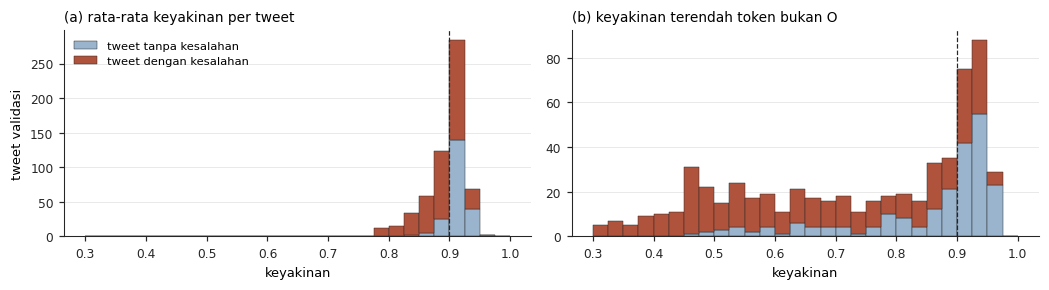

In [39]:
KT, KT_TAB = LP.keyakinan_tweet()
display(tabel(KT_TAB, 3))
fig, ax = plt.subplots(1, 2, figsize=(9.6, 2.7))
for a, kol, judul_ in ((ax[0], "rata", "(a) rata-rata keyakinan per tweet"), (ax[1], "minimum", "(b) keyakinan terendah token bukan O")):
    a.hist([KT.loc[~KT.salah, kol], KT.loc[KT.salah, kol]], bins=np.linspace(.3, 1, 29), stacked=True, color=[PL.BIRU_M, PL.BATA],
           label=["tweet tanpa kesalahan", "tweet dengan kesalahan"], edgecolor=PL.TINTA, linewidth=.3)
    a.axvline(.9, color=PL.TINTA, lw=.8, ls="--"); a.set_title(judul_, loc="left"); a.set_xlabel("keyakinan")
ax[0].set_ylabel("tweet validasi"); ax[0].legend(loc="upper left")
fig.tight_layout(); PL.save(fig, "8_1_keyakinan_tweet"); plt.show()

<div align="justify">

Pada data validasi, *threshold* 0,7 dan 0,8 menerima 99,8% dan 97,7% *tweet*, dan 63,4% sampai 64,0% *tweet* yang diterima memuat minimal satu token salah. *Threshold* 0,9 lebih ketat, tetapi 48,9% *tweet* yang diterimanya tetap memuat kesalahan. Histogram (a) memperlihatkan penyebabnya. Rata-rata probabilitas prediksi hampir semua *tweet* berada di atas 0,8, dan banyak *tweet* yang memuat kesalahan (merah) berada di kanan garis 0,9. Histogram (b) memakai probabilitas prediksi terendah token bukan O, sehingga *tweet* salah tersebar ke nilai rendah dan lebih mudah dipisahkan. Oleh karena itu, seleksi *pseudo-label* pada *Novelty* 1 menilai setiap *span* dari token terlemahnya.

</div>


<div align="justify">

**Pembagian ulang data gabungan.** Protokol CP1 sengaja menggabungkan *pseudo-label* dan data berlabel, kemudian membagi ulang data latih serta validasi. Komposisi validasi berubah sepanjang iterasi. Tabel berikut merupakan simulasi prosedur tersebut, bukan pelacakan identitas sampel pada seluruh *run* lama.

</div>


,% validasi berisi pseudo-label,% validasi awal pindah ke data latih
pseudo-label di data gabungan,,
0,"0,0","0,0"
500,"11,5","7,0"
1000,"21,9","17,1"
2000,"38,6","79,7"
3000,"48,5","79,5"
5850,"65,2","80,8"


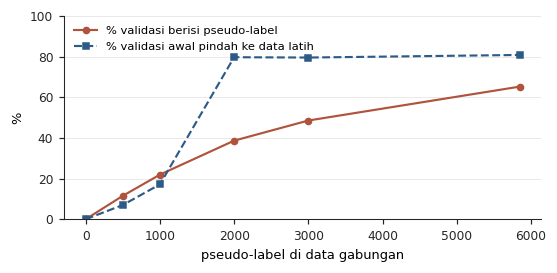

In [40]:
VC = LP.validasi_tercemar()
display(tabel(VC, 1))
fig, ax = plt.subplots(figsize=(5.6, 2.4))
for kol, w, mk in zip(VC.columns, (PL.BATA, PL.BIRU), ("o-", "s--")):
    ax.plot(VC.index, VC[kol], mk, color=w, label=kol)
ax.set_xlabel("pseudo-label di data gabungan"); ax.set_ylabel("%"); ax.set_ylim(0, 100); ax.legend()
PL.save(fig, "8_1_validasi_tercemar"); plt.show()

<div align="justify">

Bila 500 *pseudo-label* digabung lalu dibagi ulang, 11,5% data validasi sudah berupa *pseudo-label*. Pada 2.000 *pseudo-label*, porsinya menjadi 38,6% dan 79,7% data validasi asli berpindah ke data latih. Pada seluruh 5.850 *pseudo-label*, 65,2% data validasi adalah *pseudo-label* dan 80,8% data validasi asli sudah dipakai untuk *training*. Dengan kondisi ini, model dinilai dengan label buatannya sendiri dan dengan data yang sudah dilihatnya, sehingga skor validasi tidak lagi mengukur generalisasi. Oleh karena itu, data validasi dibekukan pada *Novelty* 1 [8](#ref-8).

</div>


<div align="justify">

**Variasi epoch pada model awal CP2.** Riwayat berikut berasal dari IndoBERT CP2 dengan 15 *epoch* dan lima *seed*. CP1 memakai batas 10 *epoch*. Pemeriksaan ini menilai variasi *checkpoint* setelah data diperbaiki dan tidak membuktikan bahwa *early stopping* pada CP1 gagal.

</div>


In [41]:
display(tabel(LP.analisis_epoch_cp2(), 4))

,epoch terbaik,F1 epoch terbaik,F1 epoch 15,selisih,sd F1 epoch 6 sampai 15,lebar CI 95% bootstrap
seed,,,,,,
42,13,"0,7471","0,7439","0,0032","0,0060","0,0725"
43,8,"0,7475","0,7421","0,0054","0,0034","0,0722"
44,14,"0,7362","0,7336","0,0026","0,0036","0,0649"
45,15,"0,7363","0,7363","0,0000","0,0036","0,0682"
46,12,"0,7598","0,7566","0,0032","0,0093","0,0621"


<div align="justify">

*Epoch* terbaik model awal CP2 berada pada 8 sampai 15. Selisihnya terhadap *epoch* terakhir sebesar 0 sampai 0,0054, sedangkan lebar CI skor tunggal 0,0621 sampai 0,0725. CI skor tunggal tidak menguji selisih antarepoch. Durasi tetap menyamakan protokol, tetapi belum terbukti sebagai jumlah *epoch* optimal [9](#ref-9).

</div>


#### 8.1.2 Dasar Seleksi

<div align="justify">

Rizve dkk. [11](#ref-11) menggunakan ketidakpastian untuk memperbaiki *pseudo-label*, sedangkan SeqUST [12](#ref-12) memilih token pada *sequence labeling*. Penelitian ini mengadaptasinya ke *span*, yaitu rentang token berurutan dengan label sama. Lima model dengan *seed* berbeda menghasilkan masing-masing 10 prediksi *Monte Carlo* (MC) *dropout*. *Dropout* tetap aktif saat prediksi untuk mengamati variasi keluaran [14](#ref-14)[15](#ref-15).

</div>

$$\bar p_j(c)=\frac{1}{50}\sum_{m=1}^{5}\sum_{t=1}^{10}p_j^{m,t}(c),\qquad a(s)=\frac{1}{|s|}\sum_{j\in s}\frac{1}{50}\sum_{m,t}\mathbf1[\hat y_j^{m,t}=c_s].$$

<div align="justify">

$j$ adalah posisi token, $c$ kandidat label, $m$ model, $t$ pengulangan *dropout*, dan $s$ *span* berlabel $c_s$. Kesepakatan $a(s)\ge0{,}9$ adalah rata-rata atas token dan *pass*. Angka tersebut tidak mensyaratkan 45 suara pada setiap token secara individual.

</div>

$$\ell_{j,c}=\log\bar p_j(c),\qquad z_j=\frac{\ell_{j,\hat y_j}-\bar\ell_j}{\sum_{c=1}^{15}|\ell_{j,c}-\bar\ell_j|},\qquad\mathrm{skor}(s)=\min_{j\in s}z_j.$$

<div align="justify">

$\hat y_j$ adalah label prediksi dan $\bar\ell_j$ rata-rata log probabilitas seluruh label. Penyebut memakai jumlah simpangan absolut, bukan simpangan baku. Skor token terlemah ini adalah heuristik penelitian untuk mengurutkan *span*, bukan probabilitas bahwa *span* pasti benar.

</div>

<div align="justify">

*Span* diurutkan per kelompok label, diambil sesuai kuota 50%, kemudian diperiksa kesepakatannya. Label argumen sangat jarang digabung. Konflik kejadian nyata dan FALSE-EVENT dikeluarkan. Batas dua kali proporsi label memakai penyebut sebelum seleksi akhir dan bukan jaminan proporsi akhir. Bila kesamaan batas kurang dari 80% *pass*, tepi *span* lebih panjang dari dua token tidak disupervisi.

</div>

<div align="justify">

Sebanyak 35% kandidat O yang disepakati semua *pass* dan jauh lebih dari dua token dari prediksi bukan O disertakan. Rancangan ini mempertimbangkan risiko entitas terlewat yang dipelajari sebagai O [13](#ref-13). Setiap *batch* berisi empat *tweet* berlabel manusia dan empat *tweet* *pseudo-label*.

</div>

$$L_r=L_{\rm asli}+\lambda\,\mathrm{rata\mbox{-}rata}\{L_{\rm pseudo,bukan\ O},L_{\rm pseudo,O}\},\qquad\lambda=0{,}25.$$

<div align="justify">

Rata-rata hanya mencakup kelompok yang memiliki token. $L_r$ menggantikan *loss* tiap *pass* pada R-Drop. Kuota, bobot, dan aturan batas adalah konfigurasi eksperimen ini; seluruh parameter belum diuji secara terpisah. Seleksi dan pelatihan berlangsung satu putaran, sehingga hasil ini tidak membuktikan perilaku konvergensi seleksi berulang.

</div>


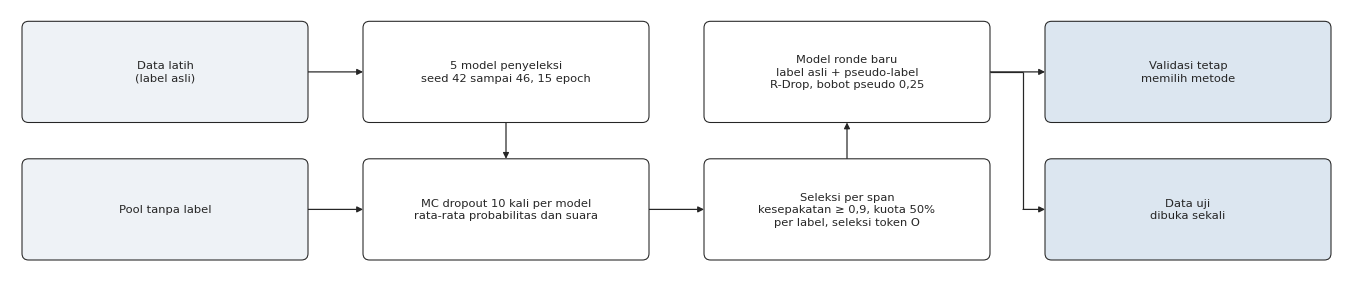

In [42]:
nodes = {"latih": dict(x=1.5, y=3.0, teks="Data latih\n(label asli)", jenis="data"),
         "pool": dict(x=1.5, y=1.75, teks="Pool tanpa label", jenis="data"),
         "sel": dict(x=4.6, y=3.0, teks="5 model penyeleksi\nseed 42 sampai 46, 15 epoch"),
         "mc": dict(x=4.6, y=1.75, teks="MC dropout 10 kali per model\nrata-rata probabilitas dan suara"),
         "pilih": dict(x=7.7, y=1.75, teks="Seleksi per span\nkesepakatan ≥ 0,9, kuota 50%\nper label, seleksi token O"),
         "ronde": dict(x=7.7, y=3.0, teks="Model ronde baru\nlabel asli + pseudo-label\nR-Drop, bobot pseudo 0,25"),
         "val": dict(x=10.8, y=3.0, teks="Validasi tetap\nmemilih metode", jenis="hasil"),
         "uji": dict(x=10.8, y=1.75, teks="Data uji\ndibuka sekali", jenis="hasil")}
for v in nodes.values():
    v.update(w=2.6, h=.92)
edges = [("latih", "sel"), ("sel", "mc"), ("pool", "mc"), ("mc", "pilih"), ("pilih", "ronde"), ("ronde", "val"), dict(a="ronde", b="uji", tengah=9.3)]
fig = PL.diagram(nodes, edges)
PL.save(fig, "8_1_protokol"); plt.show()

<div align="justify">

Lima model memprediksi *pool*, kemudian seleksi menyisakan *span* yang memenuhi kriteria. Model *self-training* diinisialisasi dari bobot pralatih dan dilatih memakai label manusia serta *pseudo-label*. Validasi tetap berasal dari anotasi manusia. Protokol satu putaran ini tidak mengulang penerimaan sampai *pool* habis.

</div>


#### 8.1.3 *Training*

<div align="justify">

Model *self-training* dilatih pada keempat *model bahasa* dengan tiga *seed*. Setiap *model bahasa* memakai lima model penyeleksinya sendiri, yaitu model awal *seed* 42 sampai 46 dari *model bahasa* yang sama. Varian *threshold* (0,7, 0,8, 0,9) dan *learning curve* (10%, 25%, 50% data latih) dilatih pada IndoBERT dengan tiga *seed* sebagai *ablation*.

</div>


In [43]:
S.jalankan_semua(S.antrean("st", "lain"))
display(pd.concat({C.BACKBONES[b]["nama"]: LP.pseudo_info(b, ("st",))["self-training"] for b in S.BB if LP.ada("st", b)}, axis=1))
display(LP.pseudo_info())

[11-21 07:38] mulai st IndoBERT IndoNLU
[11-21 07:38] selesai st IndoBERT IndoNLU
[11-21 07:38] mulai st XLM-R
[11-21 07:38] selesai st XLM-R
[11-21 07:38] mulai lain IndoBERT
[11-21 07:39] selesai lain IndoBERT


,IndoBERT,IndoBERTweet,IndoBERT IndoNLU,XLM-R
tweet pool dipakai,4438,4441,4401,4343
token bukan O,18445,17711,18077,17764
token O,12749,13128,13193,12035
ACCIDENT-EVENT,223,215,219,214
AFFECTEDOBJECTS-ARG,2471,2400,2430,2345
DEATHVICTIM-ARG,489,491,454,455
EARTHQUAKE-EVENT,229,188,184,209
FALSE-EVENT,1664,1571,1618,1651
FIRE-EVENT,697,698,780,695
FLOOD-EVENT,51,56,57,52


,self-training,"threshold 0,9","threshold 0,8","threshold 0,7"
tweet pool dipakai,4438,4368,5152,5234
token bukan O,18445,13872,24951,27957
token O,12749,13289,16050,16357
ACCIDENT-EVENT,223,295,396,424
AFFECTEDOBJECTS-ARG,2471,1720,2899,3449
DEATHVICTIM-ARG,489,136,367,503
EARTHQUAKE-EVENT,229,351,426,430
FALSE-EVENT,1664,1964,2830,2938
FIRE-EVENT,697,864,1333,1383
FLOOD-EVENT,51,65,92,97


<div align="justify">

IndoBERT memakai 4.438 dari 5.424 *tweet* *pool* dengan 18.445 token bukan O dan 12.749 token O. Model lain memakai 4.343 sampai 4.441 *tweet*; kemiripan jumlah tersebut belum menjamin isi *pseudo-label* sama. Kuota memasukkan 108 token WOUNDVICTIM-ARG dan 489 DEATHVICTIM-ARG, sedangkan *threshold* 0,9 hanya memasukkan 7 dan 136 token. FLOOD-EVENT tetap sedikit, yakni 51 sampai 57 token, dibandingkan 1.571 sampai 1.664 FALSE-EVENT.

</div>


### 8.2 *Novelty* 2: Evaluasi Ketidakpastian

<div align="justify">

*Novelty* 2 menggunakan prediksi model terlatih untuk membentuk himpunan kandidat label dan menilai kebutuhan peninjauan. Guo dkk. [4](#ref-4) menunjukkan bahwa probabilitas tinggi belum tentu sesuai dengan ketepatan empiris. Grafik berikut memeriksa hubungan tersebut. *Expected Calibration Error* (ECE) adalah rata-rata berbobot selisih *confidence* dan akurasi pada kelompok probabilitas. *Confidence* merupakan probabilitas label yang diprediksi.

</div>


token,ECE semua token,ECE token bukan O
"IndoBERT, awal","0,043","0,131"
"IndoBERT, self-training","0,044","0,120"
"IndoBERTweet, awal","0,043","0,125"
"IndoBERTweet, self-training","0,049","0,125"
"IndoBERT IndoNLU, awal","0,050","0,121"
"IndoBERT IndoNLU, self-training","0,054","0,117"
"XLM-R, awal","0,045","0,136"
"XLM-R, self-training","0,047","0,128"


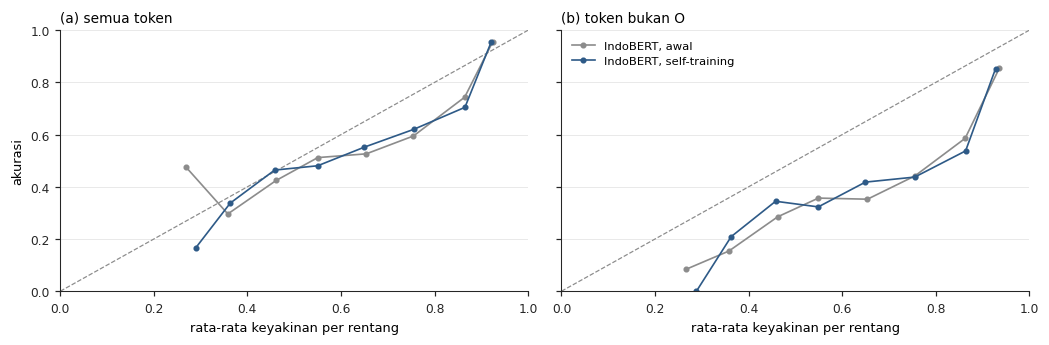

In [44]:
RL = {(b, k): KF.reliabilitas(b, k) for b, k in KF.daftar(("awal", "st"))}
display(tabel(pd.DataFrame({KF.nama(b, k): e for (b, k), (_, e) in RL.items()}).T.add_prefix("ECE "), 3))
fig, ax = plt.subplots(1, 2, figsize=(9.6, 3.2), sharey=True)
for a, tok, h in zip(ax, ("semua token", "token bukan O"), "ab"):
    a.plot([0, 1], [0, 1], color=PL.ABU, lw=.8, ls="--")
    for k, w in (("awal", PL.ABU), ("st", PL.BIRU)):
        d = RL[(C.BACKBONE_PAPER, k)][0]
        d = d[d.token == tok]
        a.plot(d.keyakinan, d.akurasi, "o-", color=w, ms=3, lw=1.1, label=KF.nama(C.BACKBONE_PAPER, k))
    a.set_xlabel("rata-rata keyakinan per rentang"); a.set_title(f"({h}) {tok}", loc="left"); a.set_xlim(0, 1); a.set_ylim(0, 1)
ax[0].set_ylabel("akurasi"); ax[1].legend(loc="upper left"); fig.tight_layout(); PL.save(fig, "8_2_reliabilitas"); plt.show()

<div align="justify">

ECE seluruh token berada pada 0,043 sampai 0,054, sedangkan kelompok bukan O mencapai 0,117 sampai 0,136. Pada IndoBERT, *self-training* menurunkannya dari 0,131 menjadi 0,120. Perbaikan akurasi tidak menghilangkan ketidaksesuaian probabilitas. Kelompok bukan O untuk ECE mencakup token dengan label asli atau prediksi bukan O; cakupan conformal memakai label asli bukan O.

</div>


#### 8.2.2 Himpunan Label dan Penerimaan

<div align="justify">

*Split conformal* dari Angelopoulos dan Bates [5](#ref-5) membentuk himpunan dengan target cakupan di bawah asumsi pertukaran data. Versi per kelompok label mengurangi dominasi O. Campos dkk. [6](#ref-6) membahas penerapan conformal pada NLP. Kalibrasi conformal menentukan batas skor, berbeda dari kalibrasi probabilitas yang menyesuaikan *confidence*.

</div>

$$s_i=1-p(y_i\mid x_i),\quad r_k=\lceil(n_k+1)(1-\alpha)\rceil,\quad q_k=s^{(k)}_{(r_k)},\quad C(x)=\{c:1-p(c\mid x)\le q_{g(c)}\}.$$

<div align="justify">

$x_i$ adalah token dalam konteks *tweet*, $y_i$ label benar, $n_k$ jumlah token kalibrasi kelompok $k$, dan $g(c)$ kelompok kandidat label. Skor diurutkan menaik. Bila $r_k>n_k$, batas ditetapkan satu. Target $1-\alpha$ berlaku per kelompok hanya di bawah asumsi conformal. DEATHVICTIM-ARG dan WOUNDVICTIM-ARG digabung; jaminan kelompok gabungan tidak otomatis berlaku pada tiap labelnya.

</div>

<div align="justify">

Token menjadi kandidat penerimaan jika himpunannya memiliki tepat satu anggota dan anggota itu sama dengan label keluaran model. Token lain ditinjau. *Tweet* ditandai jika setidaknya satu token perlu ditinjau. Cakupan label benar tidak sama dengan ketepatan semua *tweet* yang diterima.

</div>

<div align="justify">

Untuk penyaringan *tweet*, $u$ menyatakan ketidakpastian dan $u^s_{(j)}$ skor urutan ke-$j$ dari $m$ *tweet* kalibrasi yang salah.

</div>

$$j=\lfloor\alpha(m+1)\rfloor,\qquad\mathrm{terima}\iff u<u^s_{(j)}.$$

<div align="justify">

Jika $j=0$, tidak ada penerimaan. Aturan ini mengadaptasi kuantil bersyarat pada kelompok salah [5](#ref-5). *Conformal risk control* oleh Angelopoulos dkk. [16](#ref-16) mengendalikan nilai harapan *loss* monoton; rumus di atas bukan bentuk umum algoritma tersebut. Proporsi semua *tweet* salah yang lolos berbeda dari *selective risk*, yaitu proporsi *tweet* salah di antara *tweet* yang diterima.

</div>

$$\mathrm{AURC}=\frac1N\sum_{j=1}^{N}\frac1j\sum_{i=1}^{j}e_{\pi(i)}.$$

<div align="justify">

*Area Under the Risk-Coverage Curve* (AURC) merangkum risiko sepanjang tingkat penerimaan [17](#ref-17). $N$ adalah jumlah *tweet*, $\pi$ urutan ketidakpastian menaik, dan $e=1$ jika suatu *tweet* memiliki token salah. Nilai kecil menunjukkan pengurutan yang lebih baik. Skor probabilitas, token terendah, skor ternormalisasi, kesepakatan MC *dropout*, kesepakatan model, dan jumlah token ditandai dibandingkan.

</div>


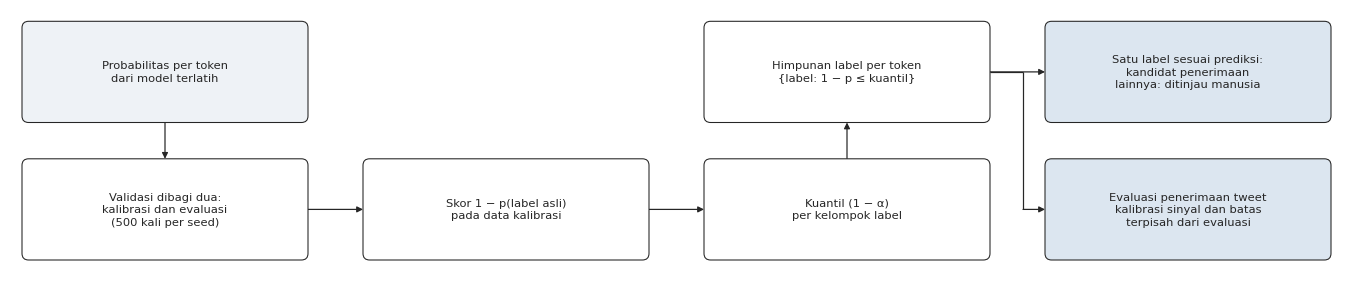

In [45]:
nodes = {"p": dict(x=1.5, y=3.0, teks="Probabilitas per token\ndari model terlatih", jenis="data"),
         "bagi": dict(x=1.5, y=1.75, teks="Validasi dibagi dua:\nkalibrasi dan evaluasi\n(500 kali per seed)"),
         "s": dict(x=4.6, y=1.75, teks="Skor 1 − p(label asli)\npada data kalibrasi"),
         "q": dict(x=7.7, y=1.75, teks="Kuantil (1 − α)\nper kelompok label"),
         "h": dict(x=7.7, y=3.0, teks="Himpunan label per token\n{label: 1 − p ≤ kuantil}"),
         "r": dict(x=10.8, y=3.0, teks="Satu label sesuai prediksi:\nkandidat penerimaan\nlainnya: ditinjau manusia", jenis="hasil"),
         "t": dict(x=10.8, y=1.75, teks="Evaluasi penerimaan tweet\nkalibrasi sinyal dan batas\nterpisah dari evaluasi", jenis="hasil")}
for v in nodes.values():
    v.update(w=2.6, h=.92)
edges = [("p", "bagi"), ("bagi", "s"), ("s", "q"), ("q", "h"), ("h", "r"), dict(a="h", b="t", tengah=9.3)]
fig = PL.diagram(nodes, edges)
PL.save(fig, "8_2_conformal"); plt.show()

<div align="justify">

Probabilitas tersimpan menjadi masukan pembentukan himpunan. Kalibrasi menetapkan kuantil per kelompok label, kemudian kandidat label pada data evaluasi dibandingkan dengan kuantil tersebut. Penerimaan memerlukan *singleton* yang selaras dengan label prediksi. Evaluasi ini tidak mengubah bobot model.

</div>


#### 8.2.3 Rancangan Evaluasi

<div align="justify">

*Run* tersimpan memakai 500 pembagian validasi per *seed* untuk kalibrasi dan evaluasi cakupan. Pada uji, seluruh validasi menjadi data kalibrasi. Ketergantungan token dalam *tweet* dan penggunaan validasi untuk pengembangan model membatasi klaim jaminan formal.

</div>

<div align="justify">

Evaluasi penerimaan membagi 599 *tweet* validasi menjadi tiga bagian terpisah: 149 untuk membentuk himpunan, 150 untuk menentukan batas penerimaan, dan 300 untuk mengukur galat. Pembagian diulang 500 kali per *seed* agar label evaluasi tidak ikut membentuk sinyal himpunan.

</div>


In [46]:
S.jalankan_semua(S.antrean("konformal"))
DAFTAR = pd.DataFrame([dict(backbone=C.BACKBONES[b]["nama"], model=LP.NAMA[k]) for b, k in KF.daftar()])
display(DAFTAR.groupby("backbone", sort=False).model.agg(", ".join).to_frame("model yang diperiksa (seed 42, 43, 44)"))

[11-21 07:39] mulai konformal IndoBERT
[11-21 07:42] selesai konformal IndoBERT
[11-21 07:42] mulai konformal IndoBERTweet
[11-21 07:45] selesai konformal IndoBERTweet
[11-21 07:45] mulai konformal IndoBERT IndoNLU
[11-21 07:48] selesai konformal IndoBERT IndoNLU
[11-21 07:48] mulai konformal XLM-R
[11-21 07:51] selesai konformal XLM-R


,"model yang diperiksa (seed 42, 43, 44)"
backbone,
IndoBERT,"awal, R-Drop, self-training"
IndoBERTweet,"awal, R-Drop, self-training"
IndoBERT IndoNLU,"awal, R-Drop, self-training"
XLM-R,"awal, R-Drop, self-training"


<div align="justify">

Pemeriksaan *conformal* mencakup 12 model, yaitu model awal, R-Drop, dan *self-training* pada empat *model bahasa*, masing-masing dengan tiga *seed*. Cakupan ini memperlihatkan apakah hasil Bab 10.3 bergantung pada *model bahasa* atau cara *training*.

</div>


### 8.3 *Novelty* 3: Uji Lintas Jenis Kejadian

<div align="justify">

Model dengan daftar label tetap tidak memperoleh supervisi positif untuk jenis kejadian yang dikeluarkan dari data latih berlabel. Kondisi ini dapat menghambat pengenalan jenis tersebut meskipun label keluarannya masih tersedia. Huang dkk. [18](#ref-18) mengkaji transfer ke jenis baru melalui representasi semantik kata kejadian dan nama jenisnya. Pendekatan tersebut menjadi konteks masalah, bukan metode yang diterapkan dalam eksperimen ini. Temuan Medina Maza dkk. [7](#ref-7) tentang ketergantungan pada kata khas kejadian juga mendasari *Novelty* 3, yaitu evaluasi *leave-one-event-type-out* (LOEO) yang mengeluarkan satu jenis kejadian dari data latih berlabel.

</div>

<div align="justify">

Untuk setiap jenis e, yakni banjir, gempa, kebakaran, atau kecelakaan, *tweet* jenis e dikeluarkan dari data latih dan *stop dev*. Data latih tersisa 1.630 sampai 1.914 *tweet*. Lima model penyeleksi IndoBERT dilatih tanpa contoh berlabel jenis e. Model awal, R-Drop, dan *self-training* kemudian diuji pada 122 sampai 195 *tweet* validasi jenis e. *Pool* tanpa label masih dapat memuat jenis yang dikeluarkan, maka eksperimen menguji ketiadaan supervisi berlabel, bukan ketiadaan seluruh paparan teks. Keempat label kejadian nyata digabung menjadi KEJADIAN NYATA untuk mengevaluasi pengenalan status kejadian melalui *macro-F1* atas 11 label. Cakupan conformal diperiksa dengan kalibrasi dari jenis lain dan penambahan 25 serta 50 *tweet* jenis baru.

</div>


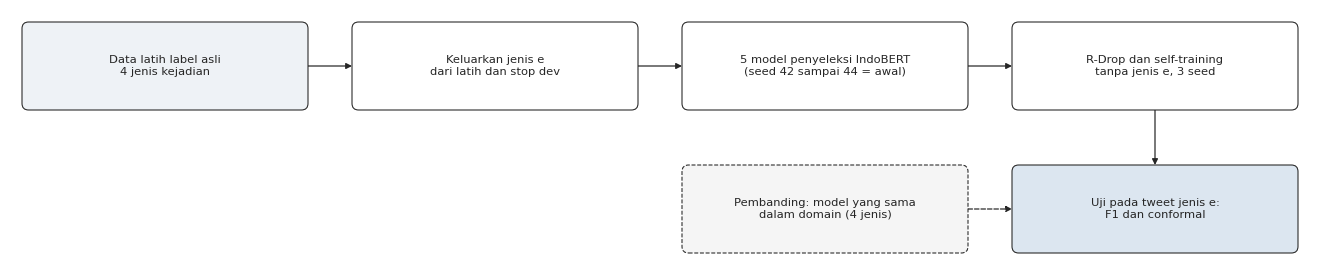

,jenis dikeluarkan,tweet latih,tweet stop dev,tweet validasi jenis ini
0,banjir,1630,271,195
1,gempa,1908,319,122
2,kebakaran,1688,296,157
3,kecelakaan,1914,317,125


In [47]:
nodes = {"all": dict(x=1.5, y=1.9, teks="Data latih label asli\n4 jenis kejadian", jenis="data"),
         "tanpa": dict(x=4.5, y=1.9, teks="Keluarkan jenis e\ndari latih dan stop dev"),
         "sel": dict(x=7.5, y=1.9, teks="5 model penyeleksi IndoBERT\n(seed 42 sampai 44 = awal)"),
         "st": dict(x=10.5, y=1.9, teks="R-Drop dan self-training\ntanpa jenis e, 3 seed"),
         "uji": dict(x=10.5, y=.6, teks="Uji pada tweet jenis e:\nF1 dan conformal", jenis="hasil"),
         "ref": dict(x=7.5, y=.6, teks="Pembanding: model yang sama\ndalam domain (4 jenis)", jenis="catatan")}
for v in nodes.values():
    v.update(w=2.6, h=.8)
fig = PL.diagram(nodes, [("all", "tanpa"), ("tanpa", "sel"), ("sel", "st"), ("st", "uji"), dict(a="ref", b="uji", putus=True)])
PL.save(fig, "8_3_rancangan"); plt.show()
LIP = pd.DataFrame([{"jenis dikeluarkan": LK.NAMA[e], "tweet latih": len(a), "tweet stop dev": len(b),
                     "tweet validasi jenis ini": sum(t["text_id"][:3] == e for t in S.data("val"))} for e in LK.JENIS for a, b in [LK.bagian(e)]])
display(LIP)

<div align="justify">

Mengeluarkan satu jenis kejadian mengurangi data latih menjadi 1.630 sampai 1.914 *tweet*. Pengurangan terbesar terjadi saat banjir dikeluarkan karena banjir adalah jenis dengan *tweet* latih terbanyak. Setiap jenis yang dikeluarkan diuji pada 122 sampai 195 *tweet* validasi.

</div>


#### 8.3.3 *Training*


In [48]:
S.jalankan_semua(S.antrean("lintas"))

[11-21 07:51] mulai lintas IndoBERT
[11-21 07:52] selesai lintas IndoBERT


<div align="justify">

Model lintas kejadian dilatih selama 15 *epoch* tetap. Pada *self-training* tanpa kecelakaan *seed* 44, F1 *stop dev* mencapai 0,6615 pada *epoch* 6, lalu berada di antara 0,6534 dan 0,6724 sampai *epoch* 15 (0,6643). Pola datar setelah *epoch* 6 ini sama dengan riwayat model dalam domain pada Bab 10.2.5. Seluruh model lintas kejadian IndoBERT selesai dilatih dari pukul 01.18 sampai 02.49.

</div>


### 8.4 RQ4: Audit Label pada IndoBERT

<div align="justify">

RQ4 menilai kesepakatan penilai dan pengaruh koreksi anotasi terhadap kinerja serta ketidakpastian prediksi IndoBERT. Audit menggunakan model untuk menemukan kandidat kesalahan label dan melengkapi ketiga *novelty*. Koreksi yang disepakati dipakai untuk melatih ulang IndoBERT awal, R-Drop, dan *self-training* dengan tiga *seed*, sedangkan *model bahasa* lain tidak dilatih ulang. Model label audit juga diperiksa dengan *conformal prediction* Bab 8.2.

</div>

#### 8.4.1 Bukti Masalah

<div align="justify">

Bab 5.3.6 menunjukkan kata yang kadang masuk dan kadang tidak masuk *span* yang sama. Bukti kedua datang dari model. Bila model yang tidak pernah melihat sebuah *tweet* tetap memberi label berbeda dengan anotasi, perbedaan itu bisa berarti model salah atau label anotasi salah. Data latih dibagi menjadi lima *fold*, lalu setiap *fold* diprediksi oleh IndoBERT yang dilatih pada empat *fold* lainnya (prediksi *out-of-fold*). Setiap perbedaan dikelompokkan menjadi lima kategori.

</div>

| Kategori | Arti |
|:-|:-|
| status kejadian | model memberi status nyata, sedangkan label asli FALSE-EVENT, atau sebaliknya |
| argumen mungkin terlewat | model menemukan *span* argumen pada token berlabel O |
| batas *span* | label sama, tetapi batas *span* berbeda |
| tipe argumen | batas sama, tetapi label argumen berbeda |
| label mungkin berlebih | *span* berlabel argumen, tetapi model memberi O |


In [49]:
NILAI = AU.semua()
KD = pd.read_csv(AU.OUT / "kandidat_kunci.csv")
display(NILAI.groupby(["split", "lembar"]).size().rename("item").unstack())

lembar,kandidat,sampel acak
split,,
test,190,50
train,190,80
validasi,190,40


<div align="justify">

Audit terbaru memuat 190 kandidat pada setiap bagian, ditambah 80 sampel acak latih, 40 validasi, dan 50 uji. Total 740 item dibaca langsung dari tiga berkas penilaian. Kandidat tetap berasal dari pemeriksaan sebelumnya; pembaruan ini tidak mengulang pemilihan kandidat atau *training out-of-fold*.

</div>


#### 8.4.2 Penelitian Terkait

<div align="justify">

Mencari label salah dengan bantuan model sudah dilakukan pada *dataset* NER. CrossWeigh [19](#ref-19) melatih model *k-fold* pada CoNLL03, menandai entitas yang prediksinya berbeda dari label, lalu menemukan label salah pada sekitar 5,4% kalimat uji. Kandidat dari model tetap dapat keliru, sehingga keputusan akhir perlu dibuat manusia dan keandalannya diukur dengan kesepakatan antarpenilai. Cohen's *kappa* mengoreksi kesepakatan yang terjadi secara kebetulan, yaitu $\kappa = (p_o - p_e)/(1 - p_e)$ dengan $p_o$ porsi sepakat dan $p_e$ porsi sepakat yang diharapkan secara acak. Nilainya dipengaruhi prevalensi kelas, sehingga *kappa* dapat rendah walaupun persentase sepakat tinggi [20](#ref-20).

</div>

<div align="justify">

Audit ini menggabungkan kedua hal tersebut: kandidat dari prediksi *out-of-fold* seperti CrossWeigh, penilaian oleh dua penilai independen, dan perubahan label hanya bila kedua penilai sepakat. Penilaian data validasi dan uji dibuat buta: label asli dan prediksi model ditampilkan sebagai opsi A dan B dengan urutan acak, sehingga penilai tidak tahu mana label anotasi.

</div>

#### 8.4.3 Rancangan


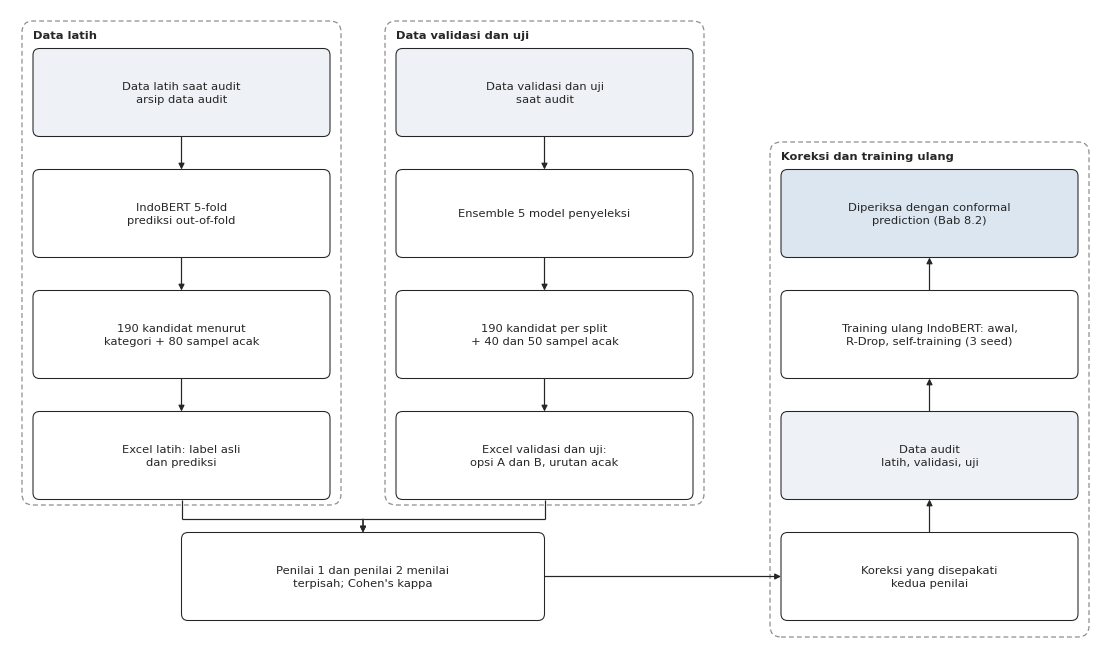

In [50]:
nodes = {"a1": dict(x=1.6, y=4.6, teks="Data latih saat audit\narsip data audit", jenis="data"),
         "a2": dict(x=1.6, y=3.5, teks="IndoBERT 5-fold\nprediksi out-of-fold"),
         "a3": dict(x=1.6, y=2.4, teks="190 kandidat menurut\nkategori + 80 sampel acak"),
         "a4": dict(x=1.6, y=1.3, teks="Excel latih: label asli\ndan prediksi"),
         "b1": dict(x=4.9, y=4.6, teks="Data validasi dan uji\nsaat audit", jenis="data"),
         "b2": dict(x=4.9, y=3.5, teks="Ensemble 5 model penyeleksi"),
         "b3": dict(x=4.9, y=2.4, teks="190 kandidat per split\n+ 40 dan 50 sampel acak"),
         "b4": dict(x=4.9, y=1.3, teks="Excel validasi dan uji:\nopsi A dan B, urutan acak"),
         "p": dict(x=3.25, y=.2, teks="Penilai 1 dan penilai 2 menilai\nterpisah; Cohen's kappa", w=3.3),
         "q": dict(x=8.4, y=.2, teks="Koreksi yang disepakati\nkedua penilai"),
         "r": dict(x=8.4, y=1.3, teks="Data audit\nlatih, validasi, uji", jenis="data"),
         "s": dict(x=8.4, y=2.4, teks="Training ulang IndoBERT: awal,\nR-Drop, self-training (3 seed)"),
         "t": dict(x=8.4, y=3.5, teks="Diperiksa dengan conformal\nprediction (Bab 8.2)", jenis="hasil")}
for v in nodes.values():
    v.setdefault("w", 2.7); v["h"] = .8
grup = [dict(x0=.15, x1=3.05, y0=.85, y1=5.25, judul="Data latih"), dict(x0=3.45, x1=6.35, y0=.85, y1=5.25, judul="Data validasi dan uji"),
        dict(x0=6.95, x1=9.85, y0=-.35, y1=4.15, judul="Koreksi dan training ulang")]
edges = [("a1", "a2"), ("a2", "a3"), ("a3", "a4"), ("b1", "b2"), ("b2", "b3"), ("b3", "b4"),
         dict(a="a4", b="p", dari="bawah", ke="atas", tengah=.72), dict(a="b4", b="p", dari="bawah", ke="atas", tengah=.72),
         ("p", "q"), ("q", "r"), ("r", "s"), ("s", "t")]
fig = PL.diagram(nodes, edges, grup)
PL.save(fig, "8_4_audit"); plt.show()

<div align="justify">

Diagram di atas merangkum alur audit. Kandidat data latih ditampilkan bersama label asli dan prediksinya, sedangkan kandidat data validasi dan uji ditampilkan tanpa keterangan sumber. Kedua jalur bertemu pada penilaian oleh dua penilai, dan hanya koreksi yang disepakati yang masuk ke data audit untuk *training* ulang. Model IndoBERT hasil *training* ulang lalu diperiksa bersama model label asli dengan *conformal prediction* Bab 8.2.

</div>


#### 8.4.4 Kandidat dari Prediksi *Out-of-Fold*

<div align="justify">

Kandidat diurutkan berdasarkan selisih probabilitas antara label prediksi dan label asli, lalu diambil yang teratas dari setiap kategori. Sampel acak *span* ditambahkan untuk memperkirakan tingkat salah label pada seluruh data, tidak hanya pada kandidat. Untuk data validasi dan uji, kandidat berasal dari *ensemble* lima model penyeleksi IndoBERT Bab 8.1, dan kuncinya disimpan di `kunci_kandidat_*.csv`.

</div>


In [51]:
JML = NILAI.groupby(["kategori", "split"]).size().unstack(fill_value=0).reindex(columns=AU.BAGIAN)
JML.loc["total"] = JML.sum()
display(JML)
display(NILAI.groupby(["split", "kategori"]).head(1)[["split", "kategori", "text_id", "span", "label_asli", "label_prediksi"]])

split,train,validasi,test
kategori,,,
argumen mungkin terlewat,50,50,50
batas span,40,40,40
label mungkin berlebih,20,20,20
sampel acak,80,40,50
status kejadian,60,60,60
tipe argumen,20,20,20
total,270,230,240


,split,kategori,text_id,span,label_asli,label_prediksi
0,train,status kejadian,BAN-01520,banjir,FALSE-EVENT,FLOOD-EVENT
60,train,argumen mungkin terlewat,KEB-00006,lahan,O,AFFECTEDOBJECTS-ARG
110,train,batas span,KEC-00010,tewaskan 12 orang,DEATHVICTIM-ARG [TEWASKAN 12 ORANG],DEATHVICTIM-ARG [12 ORANG]
150,train,tipe argumen,KEB-00670,kilang mercun,PLACE-ARG,AFFECTEDOBJECTS-ARG
170,train,label mungkin berlebih,BAN-00096,sejumlah kecamatan,AFFECTEDOBJECTS-ARG,O
190,train,sampel acak,KEC-00323,kecelakaan,FALSE-EVENT,
270,validasi,argumen mungkin terlewat,BAN-01913,konawe utara,O,PLACE-ARG
272,validasi,batas span,GEM-01133,28/9/2018 pukul 0:17:02 wib,TIME-ARG [28/9/2018],TIME-ARG [28/9/2018 PUKUL 0:17:02 WIB]
274,validasi,tipe argumen,KEC-01183,kalimalang,PLACE-ARG,STREET-ARG
279,validasi,status kejadian,BAN-01868,banjir,FALSE-EVENT,FLOOD-EVENT


<div align="justify">

Kandidat mencakup perbedaan status kejadian, argumen yang mungkin terlewat, batas *span*, tipe argumen, dan label yang mungkin berlebih. Sampel acak dilaporkan terpisah karena kandidat dipilih berdasarkan perbedaan prediksi, sehingga tingkat kesalahannya tidak mewakili seluruh *dataset*.

</div>


#### 8.4.5 Berkas Penilaian Lokal

<div align="justify">

Penilaian dibaca dari `audit/penilaian_train.xlsx`, `audit/penilaian_validasi.xlsx`, dan `audit/penilaian_test.xlsx`. Kedua kelompok kolom mengikuti urutan penilai pada setiap lembar. Nama `label perbaikan` dan `label_perbaikan` disetarakan sebelum pembacaan, sehingga kolom koreksi tetap terpasang pada penilai yang tepat.

</div>


In [52]:
display(pd.DataFrame({"bagian": list(AU.BAGIAN), "file": [str(AU.OUT / f"penilaian_{s}.xlsx") for s in AU.BAGIAN]}))

,bagian,file
0,train,/content/CP2-KEL5/audit/penilaian_train.xlsx
1,validasi,/content/CP2-KEL5/audit/penilaian_validasi.xlsx
2,test,/content/CP2-KEL5/audit/penilaian_test.xlsx


<div align="justify">

Berkas penilaian dan kunci audit dipertahankan sebagai sumber. Tabel hasil, daftar item yang belum dapat diterapkan, dan salinan label audit disimpan terpisah menurut sidik berkas sumber.

</div>


#### 8.4.6 Hasil Penilaian dan Kesepakatan

<div align="justify">

Cohen's *kappa* dihitung dari keputusan kedua penilai. Kandidat memakai empat kategori: label asli benar, prediksi benar, keduanya salah, dan tidak yakin. Sampel acak memakai tetap, diubah, dan tidak yakin. Kandidat dan sampel acak dilaporkan terpisah agar perbedaan jenis keputusan tidak tertutup oleh penggabungan kategori. Respons tidak yakin tetap dihitung sebagai kategori tersendiri. Hanya pasangan dengan keputusan kosong yang dikeluarkan. *Confidence interval* (CI) 95% dihitung melalui 2.000 pengambilan ulang *tweet* dengan mempertahankan kelompok item dari *tweet* yang sama.

</div>

<div align="justify">

Kesepakatan dihitung dari keputusan kedua penilai. Koreksi hanya diterapkan jika kedua label akhir sama, lengkap, dan tidak disengketakan. Item yang belum disepakati mempertahankan label asli. Nilai *kappa* tidak membuktikan seluruh label benar atau proses penilaian independen.

</div>


status                sepakat tetap  sepakat ubah  tidak sepakat
split    lembar                                                 
test     kandidat                73           104             13
         sampel acak             36             6              8
train    kandidat                62           118             10
         sampel acak             64            11              5
validasi kandidat                78           109              3
         sampel acak             36             3              1

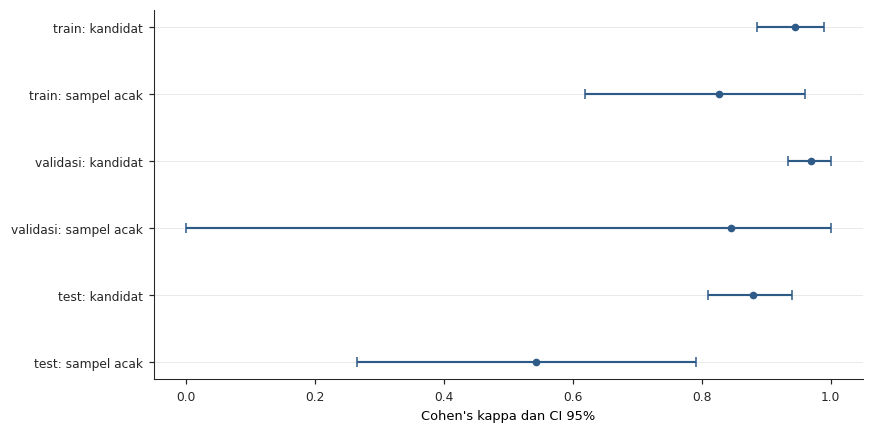

In [53]:
NILAI = AU.semua()
os.environ["CP2_AUDIT_ID"] = AU.versi()
KP = AU.kappa(NILAI)
FOLDER_HASIL_AUDIT = AU.folder_hasil()
KP.to_csv(FOLDER_HASIL_AUDIT / "cohens_kappa.csv", index=False)
NILAI.to_csv(FOLDER_HASIL_AUDIT / "penilaian_terbaca.csv", index=False)
NILAI[NILAI.beda_keputusan | NILAI.baris_merah].to_csv(FOLDER_HASIL_AUDIT / "perbedaan_penilaian.csv", index=False)
display(tabel(KP.set_index(["split", "lembar"]), 3))
display(NILAI.groupby(["split", "lembar", "status"]).size().unstack(fill_value=0))
fig, ax = plt.subplots(figsize=(8, 4))
label = [f"{s}: {l}" for s, l in zip(KP.split, KP.lembar)]
ax.errorbar(KP.kappa, range(len(KP)), xerr=[(KP.kappa-KP["CI bawah"]).clip(lower=0), (KP["CI atas"]-KP.kappa).clip(lower=0)], fmt="o", capsize=3)
ax.set_yticks(range(len(KP)), label)
ax.invert_yaxis()
ax.set_xlabel("Cohen's kappa dan CI 95%")
fig.tight_layout()
fig.savefig(FOLDER_HASIL_AUDIT / "cohens_kappa.png", dpi=160, bbox_inches="tight")
plt.show()

<div align="justify">

Cohen's *kappa* kandidat latih, validasi, dan uji adalah 0,9447, 0,9691, dan 0,8800. Pada sampel acak, nilainya 0,8270, 0,8456, dan 0,5423. Dari 740 item, 738 pasangan masuk penghitungan. Dua kandidat latih dikeluarkan karena satu keputusan kosong. Respons tidak yakin tetap menjadi kategori tersendiri.

</div>

<div align="justify">

Sampel acak validasi memiliki 39 keputusan sama dari 40 item atau 97,5%. Sampel acak uji memiliki 42 keputusan sama dari 50 item atau 84,0%. Delapan perbedaan pada uji merupakan ketidaksepakatan penilai, bukan delapan kesalahan label yang sudah dipastikan. Pada uji, kesepakatan yang diharapkan dari distribusi jawaban sebesar 65,04%, sehingga *kappa* menjadi (0,84 − 0,6504)/(1 − 0,6504) = 0,5423. CI 95% sebesar 0,265 sampai 0,791 menunjukkan ketidakpastian pada sampel ini.

</div>

<div align="justify">

Seluruh 30 blok merah pekat tercatat sebagai sengketa. Perbedaan keputusan tanpa tanda merah juga dihitung. Persetujuan atas kategori keputusan belum tentu berarti persetujuan atas label pengganti. Koreksi hanya diterapkan jika label akhir kedua penilai sama dan valid. Item yang disengketakan atau tidak lengkap tetap memakai label asli, sedangkan respons kedua penilai dipertahankan untuk menghitung kesepakatan.

</div>


#### 8.4.7 Penerapan Koreksi yang Disepakati

<div align="justify">

Label hanya berubah ketika kedua penilai menyepakati label akhir yang valid. Posisi *span* dicocokkan dengan `audit/data_saat_audit`, kemudian dipetakan ke token data final. Perbedaan token yang tidak dapat dipetakan dan koreksi tumpang tindih yang bertentangan tetap memakai label asli serta dicatat. Data latih, validasi, dan uji tetap terpisah; koreksi validasi atau uji tidak menjadi tambahan data latih.

</div>


In [54]:
LOG, AUDIT = AU.terapkan(NILAI)
LP.gold.cache_clear()
LP.pred.cache_clear()
display(LOG.groupby(["split", "status"]).size().unstack(fill_value=0))
PERUBAHAN = pd.DataFrame([dict(bagian=sp, tweet=len(items), token_diubah=sum(a != b for x, y in zip(S.data(sp), items) for a, b in zip(x["labels"], y["labels"]))) for sp, items in AUDIT.items()])
PERUBAHAN.to_csv(FOLDER_HASIL_AUDIT / "jumlah_koreksi.csv", index=False)
display(PERUBAHAN)
display(LOG[LOG.status != "diterapkan"])

status,diterapkan,tweet dikeluarkan
split,,
test,100,10
train,128,1
validasi,110,2


,bagian,tweet,token_diubah
0,train,2380,192
1,filter_dev,198,38
2,stop_dev,401,141
3,test,946,159


,split,data,text_id,kategori,span,label_asli,label_baru,token_diubah,status
338,train,,KEB-00029,status kejadian,kebakaran,FIRE-EVENT,FALSE-EVENT,0,tweet dikeluarkan
339,validasi,,KEB-00330,argumen mungkin terlewat,pelantar piper alpha,O,AFFECTEDOBJECTS-ARG,0,tweet dikeluarkan
340,validasi,,KEB-00330,argumen mungkin terlewat,aberdeen,O,PLACE-ARG,0,tweet dikeluarkan
341,test,,KEC-01208,status kejadian,kecelakaan,FALSE-EVENT,ACCIDENT-EVENT,0,tweet dikeluarkan
342,test,,BAN-01859,tipe argumen,2 jam hujan,INFORMATION-ARG,REASON-ARG,0,tweet dikeluarkan
343,test,,BAN-01826,tipe argumen,jalan tun razak,PLACE-ARG,STREET-ARG,0,tweet dikeluarkan
344,test,,BAN-01830,status kejadian,banjir,FALSE-EVENT,FLOOD-EVENT,0,tweet dikeluarkan
345,test,,BAN-00067,batas span,kota damansar petang,PLACE-ARG [KOTA DAMANSAR PETANG],PLACE-ARG [KOTA DAMANSAR],0,tweet dikeluarkan
346,test,,GEM-00135,status kejadian,gempa bumi,FALSE-EVENT,EARTHQUAKE-EVENT,0,tweet dikeluarkan
347,test,,GEM-00135,status kejadian,gempa bumi,FALSE-EVENT,EARTHQUAKE-EVENT,0,tweet dikeluarkan


<div align="justify">

Koreksi diterapkan pada 128 *span* latih, 110 *span* validasi, dan 100 *span* uji. Total 338 *span* tersebut mengubah 530 token, terdiri atas 192 token latih, 179 validasi, dan 159 uji. Sebanyak 13 koreksi yang disepakati tidak diterapkan karena *tweet* terkait sudah dikeluarkan saat *preprocessing*. Data latih, validasi, dan uji tetap terpisah. Label pada item yang belum disepakati tidak diubah.

</div>


#### 8.4.8 *Training* Ulang dan Pemeriksaan *Conformal*

<div align="justify">

IndoBERT dilatih pada label audit untuk *baseline* 1 (model awal), *baseline* 2 (R-Drop), dan *Novelty* 1 (*self-training*). Lima *seed* model awal menjadi penyeleksi, sedangkan perbandingan ketiga metode memakai *seed* 42, 43, dan 44. Konfigurasi pelatihan dipertahankan. *Novelty* 2 pada model audit memakai label audit validasi untuk kalibrasi serta label audit uji untuk evaluasi. Bobot, prediksi, riwayat pelatihan, *pseudo-label*, kuantil, dan metrik disimpan lokal; perubahan berkas audit menghasilkan folder eksperimen yang berbeda.

</div>


In [55]:
if os.environ.get("CP2_AUDIT_ID") != AU.versi():
    raise RuntimeError("Berkas penilaian berubah. Hitung ulang kesepakatan dan terapkan koreksi audit sebelum training.")
S.jalankan_semua(S.antrean("audit", "konformal_audit", bbs=[C.BACKBONE_PAPER]))
METRIK_AUDIT = pd.concat([LP.metrik(sp, KF.AUDIT, [C.BACKBONE_PAPER]).assign(evaluasi=sp) for sp in ("val", "val_audit", "test", "test_audit")], ignore_index=True)
METRIK_AUDIT.to_csv(FOLDER_HASIL_AUDIT / "metrik_indobert.csv", index=False)
display(LP.rerata(METRIK_AUDIT[METRIK_AUDIT.evaluasi == "val_audit"].drop(columns="evaluasi")))

[11-21 07:52] mulai audit IndoBERT
[awal IndoBERT seed42 audit] memakai hasil tersimpan runs/ecf59f72148c
[awal IndoBERT seed43 audit] memakai hasil tersimpan runs/c4e15bc2cd45
[awal IndoBERT seed44 audit] memakai hasil tersimpan runs/27f4d3141236
[awal IndoBERT seed45 audit] memakai hasil tersimpan runs/14fe73ae724e
[awal IndoBERT seed46 audit] melanjutkan dari epoch 3
  [awal IndoBERT seed46 audit] epoch  4 | train loss (asli) 0.2152 | val macro-F1 tanpa O 0.7740 | val loss 0.3208 | 33 s
  [awal IndoBERT seed46 audit] epoch  5 | train loss (asli) 0.1605 | val macro-F1 tanpa O 0.7705 | val loss 0.2966 | 25 s
  [awal IndoBERT seed46 audit] epoch  6 | train loss (asli) 0.1535 | val macro-F1 tanpa O 0.7836 | val loss 0.3152 | 26 s
  [awal IndoBERT seed46 audit] epoch  7 | train loss (asli) 0.1375 | val macro-F1 tanpa O 0.7814 | val loss 0.3201 | 26 s
  [awal IndoBERT seed46 audit] epoch  8 | train loss (asli) 0.1242 | val macro-F1 tanpa O 0.7700 | val loss 0.3352 | 26 s
  [awal IndoBERT 

accuracy        precision           recall  \
backbone model                                                              
IndoBERT awal            0,9199 ± 0,002  0,7835 ± 0,0047  0,8081 ± 0,0148   
         R-Drop          0,9232 ± 0,001  0,7832 ± 0,0093  0,8213 ± 0,0044   
         self-training  0,9253 ± 0,0007   0,795 ± 0,0029  0,8213 ± 0,0023   

                               macro-F1      weighted F1          span F1  
backbone model                                                             
IndoBERT awal            0,7927 ± 0,007   0,9201 ± 0,002  0,7866 ± 0,0079  
         R-Drop         0,7986 ± 0,0061  0,9237 ± 0,0009  0,7966 ± 0,0025  
         self-training  0,8052 ± 0,0026  0,9252 ± 0,0008  0,8065 ± 0,0023

<div align="justify">

Pelatihan audit ketiga metode telah selesai untuk *seed* 42, 43, dan 44. Pada label validasi audit, *macro-F1* model awal, R-Drop, dan *self-training* berturut turut mencapai 0,7927, 0,7986, dan 0,8052. Tabel pada Bab 10.6 memisahkan evaluasi dengan label asli dan label audit agar perubahan acuan tidak disamakan dengan peningkatan akibat pelatihan.

</div>


<a id="bab-9"></a>
## 9. Validasi dan Evaluasi

<div align="justify">

Pengujian menggunakan *seed* 42, 43, dan 44 untuk mengamati variasi *fine-tuning* [9](#ref-9). Hasil dilaporkan sebagai rata-rata dan simpangan baku atau *standard deviation* (SD). *Novelty* 1 dan 3 menggunakan *macro-F1* tanpa O, sedangkan *Novelty* 2 mengevaluasi cakupan, proporsi peninjauan, kesalahan yang terjaring, dan AURC. CI selisih antarmodel dihitung melalui *bootstrap* per *tweet* sebanyak 1.000 kali atas rata-rata tiga *seed*. Pengambilan ulang dilakukan berpasangan per *tweet* agar token dalam *tweet* yang sama tidak berubah. CI selisih yang melintasi nol menunjukkan bahwa data belum memberi bukti kuat tentang arah perbedaannya. Tingkat kepercayaan merujuk pada ketercakupan prosedur pengulangan sampel, bukan persentase prediksi model yang benar. Model dipilih berdasarkan *macro-F1* validasi, hasil uji digunakan untuk evaluasi akhir dan tidak digunakan untuk memilih model utama.

</div>

<div align="justify">

*Macro-F1* tanpa O merata-ratakan F1 empat belas label peran dengan bobot sama. *True positive* (TP) adalah prediksi benar, *false positive* (FP) adalah prediksi label yang keliru, dan *false negative* (FN) adalah label benar yang terlewat.

</div>

<div align="justify">

*Confidence interval* (CI) atau interval kepercayaan menggambarkan ketidakpastian estimasi. CI 95% tidak berarti 95% prediksi benar. Untuk selisih model, interval yang melintasi nol belum memberi bukti kuat mengenai arah perbedaan. Evaluasi audit menggunakan label yang terkoreksi sebagian dan dilaporkan terpisah.

</div>


In [56]:
from srl_cp2.evaluation import tweet_counts, metrics_from_counts
cn = tweet_counts(LP.gold("val"), LP.pred("awal", C.BACKBONE_PAPER, 42, "val"))
m = metrics_from_counts(cn)
display(pd.Series({v: m[k] for k, v in LP.METRIK.items()}, name="IndoBERT awal, seed 42").to_frame().T.round(4))
rng = np.random.default_rng(0)
n = len(cn["tp"])
B = [metrics_from_counts(cn, np.bincount(rng.integers(0, n, n), minlength=n).astype(float))["f1_macro_noO"] for _ in range(1000)]
print(f"macro-F1 {m['f1_macro_noO']:.4f}, CI 95% bootstrap per tweet [{np.percentile(B, 2.5):.4f}, {np.percentile(B, 97.5):.4f}]")

[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba


,accuracy,precision,recall,macro-F1,weighted F1,span F1
"IndoBERT awal, seed 42",0.9103,0.7394,0.7925,0.762,0.9111,0.7574


macro-F1 0.7620, CI 95% bootstrap per tweet [0.7307, 0.7848]


<div align="justify">

Model awal IndoBERT *seed* 42 memperoleh *accuracy* 0,9103 dan *weighted F1* 0,9111, tetapi *macro-F1* tanpa O hanya 0,7620. CI 95% *bootstrap* per *tweet* adalah [0,7307; 0,7848] dengan lebar 0,054. Lebar ini menunjukkan bahwa skor satu model pada satu *seed* masih memiliki ketidakpastian besar, sehingga perbandingan pada Bab 10 memakai selisih berpasangan per *tweet* dan rata-rata tiga *seed*.

</div>


<a id="bab-10"></a>
## 10. Hasil Eksperimen dan Analisis

<div align="justify">

Hasil eksperimen mencakup model awal, R-Drop, dan *self-training*. Evaluasi *conformal* mensyaratkan himpunan satu label yang selaras dengan prediksi. Model dengan label audit dibahas terpisah pada RQ4.

</div>

### 10.1 Ringkasan Hasil Validasi


In [57]:
MV = LP.metrik("val")
display(LP.rerata(MV))
BD = LP.tabel_banding("val")
display(tabel(BD, 4))

[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a
[awal IndoBERTweet seed42] memakai hasil tersimpan runs/e92485f00487
[awal IndoBERTweet seed43] memakai hasil tersimpan runs/e1ff1a83f0d9
[awal IndoBERTweet seed44] memakai hasil tersimpan runs/14d89dd25b28
[awal IndoBERT IndoNLU seed42] memakai hasil tersimpan runs/b1d67f8b3456
[awal IndoBERT IndoNLU seed43] memakai hasil tersimpan runs/ee51bb52d281
[awal IndoBERT IndoNLU seed44] memakai hasil tersimpan runs/02a5c87a025f
[awal XLM-R seed42] memakai hasil tersimpan runs/76e4daa94aa9
[awal XLM-R seed43] memakai hasil tersimpan runs/b1a090cd3527
[awal XLM-R seed44] memakai hasil tersimpan runs/006acd51eb44


accuracy        precision  \
backbone         model                                             
IndoBERT         awal            0,9095 ± 0,001  0,7377 ± 0,0021   
                 R-Drop         0,9144 ± 0,0014  0,7538 ± 0,0036   
                 self-training  0,9173 ± 0,0008  0,7672 ± 0,0047   
IndoBERTweet     awal            0,909 ± 0,0016   0,731 ± 0,0058   
                 R-Drop         0,9109 ± 0,0008  0,7421 ± 0,0084   
                 self-training  0,9134 ± 0,0018  0,7572 ± 0,0091   
IndoBERT IndoNLU awal           0,9122 ± 0,0022  0,7533 ± 0,0113   
                 R-Drop          0,913 ± 0,0026  0,7601 ± 0,0085   
                 self-training  0,9166 ± 0,0011  0,7817 ± 0,0043   
XLM-R            awal           0,9055 ± 0,0018  0,7256 ± 0,0059   
                 R-Drop         0,9089 ± 0,0009  0,7399 ± 0,0019   
                 self-training  0,9124 ± 0,0006   0,746 ± 0,0021   

                                         recall         macro-F1  \
backbone         model                                             
IndoBERT         awal           0,7896 ± 0,0047  0,7597 ± 0,0023   
                 R-Drop         0,8025 ± 0,0072   0,774 ± 0,0035   
                 self-training  0,7952 ± 0,0036  0,7763 ± 0,0003   
IndoBERTweet     awal           0,7781 ± 0,0079  0,7497 ± 0,0058   
                 R-Drop         0,7833 ± 0,0047  0,7575 ± 0,0033   
                 self-training  0,7797 ± 0,0056  0,7625 ± 0,0064   
IndoBERT IndoNLU awal           0,7572 ± 0,0077  0,7516 ± 0,0087   
                 R-Drop         0,7615 ± 0,0061  0,7553 ± 0,0079   
                 self-training  0,7648 ± 0,0049  0,7662 ± 0,0039   
XLM-R            awal           0,7908 ± 0,0023  0,7524 ± 0,0046   
                 R-Drop          0,788 ± 0,0041  0,7585 ± 0,0032   
                 self-training  0,7828 ± 0,0042   0,759 ± 0,0028   

                                    weighted F1          span F1  
backbone         model                                            
IndoBERT         awal           0,9104 ± 0,0008   0,756 ± 0,0016  
                 R-Drop         0,9149 ± 0,0015  0,7704 ± 0,0036  
                 self-training  0,9171 ± 0,0009  0,7793 ± 0,0026  
IndoBERTweet     awal           0,9092 ± 0,0014  0,7491 ± 0,0036  
                 R-Drop         0,9109 ± 0,0006  0,7562 ± 0,0042  
                 self-training  0,9128 ± 0,0017  0,7642 ± 0,0059  
IndoBERT IndoNLU awal           0,9113 ± 0,0022  0,7505 ± 0,0064  
                 R-Drop         0,9123 ± 0,0026  0,7559 ± 0,0052  
                 self-training  0,9151 ± 0,0011  0,7719 ± 0,0017  
XLM-R            awal           0,9065 ± 0,0017  0,7498 ± 0,0021  
                 R-Drop          0,9094 ± 0,001  0,7592 ± 0,0027  
                 self-training  0,9123 ± 0,0006  0,7701 ± 0,0032

,backbone,model,acuan,selisih,ci_bawah,ci_atas,seed_naik
0,IndoBERT,self-training,awal,"0,0165","0,0068","0,0288",3/3
1,IndoBERT,self-training,R-Drop,"0,0022","-0,0047","0,0088",2/3
2,IndoBERT,R-Drop,awal,"0,0143","0,0062","0,0246",3/3
3,IndoBERTweet,self-training,awal,"0,0128","0,0052","0,0212",3/3
4,IndoBERTweet,self-training,R-Drop,"0,0050","-0,0022","0,0113",2/3
5,IndoBERTweet,R-Drop,awal,"0,0077","0,0009","0,0160",3/3
6,IndoBERT IndoNLU,self-training,awal,"0,0146","0,0052","0,0275",3/3
7,IndoBERT IndoNLU,self-training,R-Drop,"0,0110","0,0041","0,0193",3/3
8,IndoBERT IndoNLU,R-Drop,awal,"0,0037","-0,0045","0,0130",2/3
9,XLM-R,self-training,awal,"0,0066","-0,0076","0,0159",3/3


<div align="justify">

Model dengan *macro-F1* validasi tertinggi adalah IndoBERT *self-training* (0,7763 ± 0,0003), disusul IndoBERT R-Drop (0,7740) dan IndoBERT IndoNLU *self-training* (0,7662). Urutan pada setiap *model bahasa* sama, yaitu *self-training* di atas R-Drop dan R-Drop di atas model awal. Tabel kedua menguji selisih tersebut. *Self-training* lebih baik daripada model awal pada keempat *model bahasa* dan ketiga *seed*, dengan selisih 0,0066 sampai 0,0165, dan CI 95% berada di atas nol kecuali pada XLM-R [−0,0076; 0,0159]. Terhadap R-Drop, selisihnya lebih kecil (0,0005 sampai 0,0110) dan hanya nyata pada IndoBERT IndoNLU [0,0041; 0,0193]. Kenaikan *self-training* lebih banyak berasal dari *precision*, misalnya IndoBERT naik dari 0,7377 menjadi 0,7672, sedangkan *recall*-nya hampir tetap (0,7896 menjadi 0,7952).

</div>


### 10.2 Hasil *Novelty* 1: Protokol *Self-Training* yang Diperbaiki

#### 10.2.1 Kualitas *Pseudo-Label* Sebelum *Training*

<div align="justify">

Aturan seleksi dapat dinilai tanpa *training* dengan menerapkannya pada data validasi yang labelnya diketahui. Presisi menunjukkan berapa *pseudo-label* yang benar, sedangkan cakupan menunjukkan berapa token bukan O yang ikut terambil.

</div>


[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a
[awal IndoBERT seed45] memakai hasil tersimpan runs/aab9eb709d69
[awal IndoBERT seed46] memakai hasil tersimpan runs/85f5d69645eb


,token bukan O diterima,presisi bukan O,cakupan bukan O,presisi O,cakupan label jarang
aturan,,,,,
"paper, threshold 0,9",705,"0,932","0,147","0,991","0,077"
"paper, threshold 0,8",3.939,"0,845","0,743","0,957","0,402"
"paper, threshold 0,7",4.382,"0,840","0,822","0,949","0,547"
"per span, threshold 0,9",1.680,"0,952","0,357","0,988","0,141"
"per span, threshold 0,8",2.963,"0,924","0,611","0,989","0,265"
"per span, threshold 0,7",3.231,"0,913","0,658","0,989","0,316"
"per span, kuota 0,5 (dipakai)",2.043,"0,943","0,430","0,989","0,325"


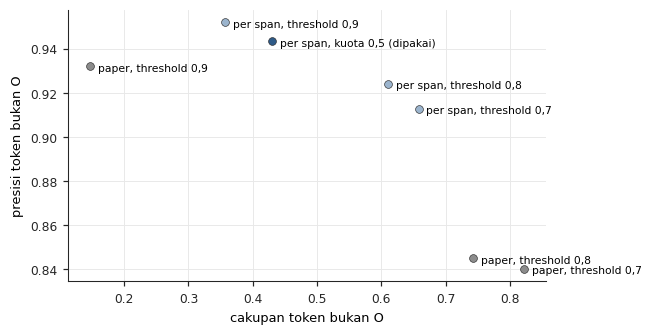

In [58]:
CS = LP.cek_seleksi()
display(tabel(CS, 3))
fig, ax = plt.subplots(figsize=(5.6, 3.2))
for nama, r in CS.iterrows():
    w = PL.ABU if nama.startswith("paper") else PL.BIRU if "kuota" in nama else PL.BIRU_M
    ax.scatter(r["cakupan bukan O"], r["presisi bukan O"], color=w, s=26, zorder=3, edgecolor=PL.TINTA, linewidth=.4)
    ax.annotate(nama, (r["cakupan bukan O"], r["presisi bukan O"]), xytext=(5, -3), textcoords="offset points", fontsize=7)
ax.set_xlabel("cakupan token bukan O"); ax.set_ylabel("presisi token bukan O"); ax.grid(axis="x", visible=True)
PL.save(fig, "10_2_kualitas_pseudo"); plt.show()

<div align="justify">

Aturan penelitian sebelumnya dengan *threshold* 0,7 dan 0,8 mengambil 82,2% dan 74,3% token bukan O, tetapi presisinya hanya 0,840 dan 0,845, artinya sekitar satu dari enam *pseudo-label* salah. *Threshold* 0,9 lebih presisi (0,932), tetapi hanya mengambil 14,7% token bukan O dan 7,7% token label jarang. Seleksi per *span* memberi presisi 0,913 sampai 0,952, lebih tinggi daripada aturan penelitian sebelumnya pada setiap *threshold*. Kuota 0,5 yang dipakai mencapai presisi 0,943 dengan cakupan 0,430, dan cakupan label jarangnya (0,325) lebih tinggi daripada *threshold* 0,8 per *span* (0,265) walaupun cakupan totalnya lebih kecil. Presisi token O tetap 0,989 pada seleksi per *span*, sehingga sampel O hampir tidak menambah kesalahan.

</div>


#### 10.2.2 *Self-Training* Dibandingkan Model Awal dan R-Drop pada Empat *Model Bahasa*


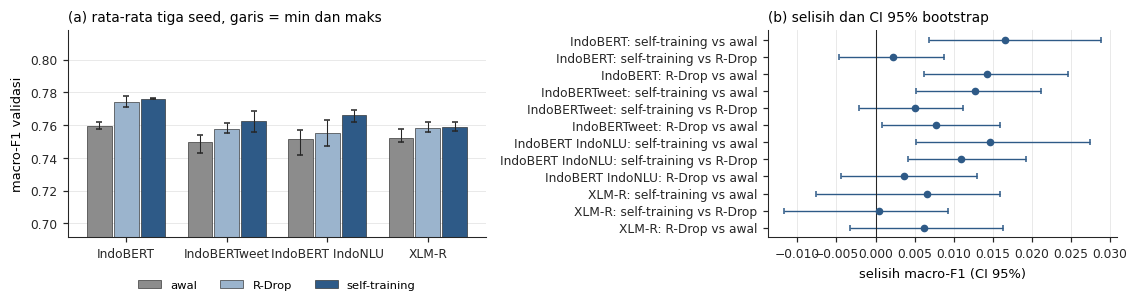

In [59]:
g = MV.groupby(["backbone", "model"], sort=False)["macro-F1"]
kol = ["awal", "R-Drop", "self-training"]
fig, ax = plt.subplots(1, 2, figsize=(10.4, 2.9), gridspec_kw=dict(width_ratios=[1.2, 1]))
PL.kelompok(ax[0], g.mean().unstack()[kol].reindex(BB), PL.WARNA_MODEL, g.min().unstack()[kol].reindex(BB), g.max().unstack()[kol].reindex(BB), "macro-F1 validasi")
PL.rentang(ax[0], MV["macro-F1"]); PL.legenda_bawah(ax[0], 3); ax[0].set_title("(a) rata-rata tiga seed, garis = min dan maks", loc="left")
PL.selisih(ax[1], BD, [f"{b}: {m} vs {a}" for b, m, a in zip(BD.backbone, BD.model, BD.acuan)])
ax[1].set_title("(b) selisih dan CI 95% bootstrap", loc="left")
fig.tight_layout(); PL.save(fig, "10_2_banding_model"); plt.show()

<div align="justify">

*Self-training* memiliki rata-rata skor tertinggi pada keempat model bahasa. CI selisih terhadap model awal berada di atas nol pada tiga model. Terhadap R-Drop, hanya IndoBERT IndoNLU memiliki CI yang seluruhnya positif. Hasil ini mendukung peningkatan pada konfigurasi yang diuji, tetapi belum memisahkan pengaruh seluruh komponen protokol atau membuktikan keunggulan tambahan yang konsisten.

</div>


#### 10.2.3 Perubahan F1 per Label


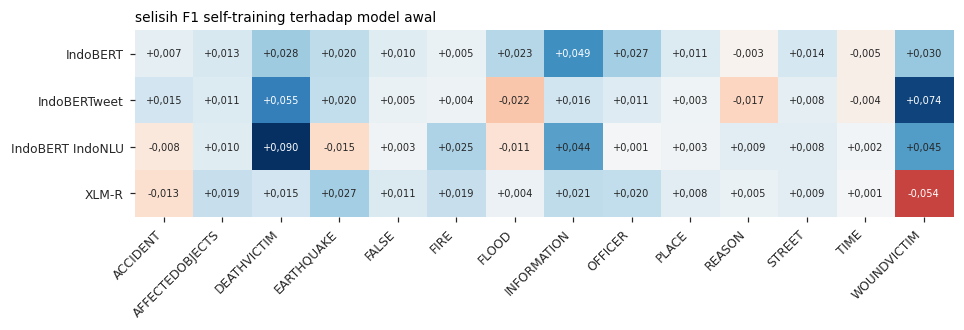

In [60]:
PLS = LP.per_label("val")
dl = PLS.pivot_table(index=["backbone", "label"], columns="model", values="f1")
dl = (dl["self-training"] - dl["awal"]).unstack().reindex(index=BB, columns=C.NON_O)
fig, ax = plt.subplots(figsize=(9.6, 2.2))
PL.heatmap(ax, dl.values, dl.index, [pendek(l) for l in dl.columns], fmt="{:+.3f}", cmap="RdBu", vmin=-.08, vmax=.08)
ax.set_title("selisih F1 self-training terhadap model awal", loc="left")
PL.save(fig, "10_2_selisih_label"); plt.show()

<div align="justify">

Dibandingkan model awal, *self-training* paling banyak menaikkan F1 label korban dan keterangan. Pada IndoBERT, kenaikan terbesar ada pada INFORMATION-ARG (+0,049), WOUNDVICTIM-ARG (+0,030), dan DEATHVICTIM-ARG (+0,028). Pada IndoBERTweet dan IndoBERT IndoNLU, DEATHVICTIM-ARG naik +0,055 dan +0,090, sedangkan WOUNDVICTIM-ARG naik +0,074 dan +0,045. Pola ini sesuai dengan tujuan kuota per label, yaitu memberi label jarang porsi *pseudo-label* yang cukup. Penurunan juga muncul, terutama WOUNDVICTIM-ARG pada XLM-R (−0,054) dan FLOOD-EVENT pada IndoBERTweet (−0,022). Kedua label ini memiliki sedikit contoh, sehingga perubahan pada beberapa *span* sudah menggeser F1-nya.

</div>


#### 10.2.4 *Ablation*: *Threshold* dan *Learning Curve*

<div align="justify">

Varian *threshold* memakai seleksi per *span* yang sama, tetapi *span* lolos bila probabilitas prediksi terendahnya melewati 0,7, 0,8, atau 0,9. *Learning curve* melatih model R-Drop dengan 10%, 25%, 50%, dan 100% data latih untuk melihat seberapa besar tambahan data berlabel masih menaikkan skor. Keduanya memakai IndoBERT dan tiga *seed*.

</div>


,accuracy,precision,recall,macro-F1,weighted F1,span F1
model,,,,,,
R-Drop,"0,9144","0,7538","0,8025","0,7740","0,9149","0,7704"
"threshold 0,9","0,9169","0,7698","0,7903","0,7754","0,9166","0,7775"
"threshold 0,8","0,9157","0,7601","0,7907","0,7700","0,9155","0,7758"
"threshold 0,7","0,9154","0,7615","0,7885","0,7699","0,9152","0,7756"
self-training,"0,9173","0,7672","0,7952","0,7763","0,9171","0,7793"


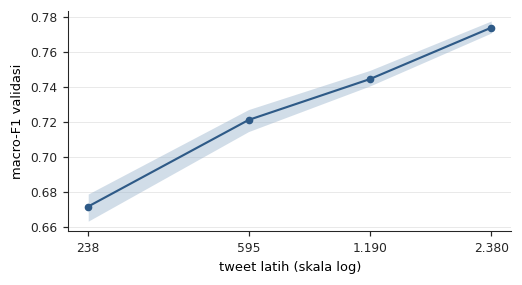

In [61]:
display(tabel(LP.ambang_vs_kuota(), 4))
KV_ = LP.kurva()
fig, ax = plt.subplots(figsize=(5.2, 2.6))
m = KV_.groupby("tweet").f1.agg(["mean", "min", "max"])
ax.fill_between(m.index, m["min"], m["max"], color=PL.BIRU_M, alpha=.45, lw=0)
ax.plot(m.index, m["mean"], "o-", color=PL.BIRU)
ax.set_xscale("log"); ax.set_xticks(m.index, [fmt(x) for x in m.index]); ax.minorticks_off()
ax.set_xlabel("tweet latih (skala log)"); ax.set_ylabel("macro-F1 validasi")
PL.save(fig, "10_2_learning_curve"); plt.show()

<div align="justify">

Pada tabel *ablation*, kuota 0,5 memberi *macro-F1* tertinggi (0,7763), disusul *threshold* 0,9 (0,7754) dan R-Drop tanpa *pseudo-label* (0,7740). *Threshold* 0,8 dan 0,7 justru di bawah R-Drop (0,7700 dan 0,7699) karena *pseudo-label* yang diambilnya lebih banyak dan kurang presisi. *Threshold* 0,9 memberi *precision* tertinggi (0,7698), tetapi *recall*-nya lebih rendah daripada kuota (0,7903 dibanding 0,7952) karena label jarang hampir tidak terambil. Hasil ini menjadi alasan kuota 0,5 dipakai sebagai protokol utama. *Learning curve* memperlihatkan bahwa *macro-F1* R-Drop naik dari di bawah 0,68 pada 238 *tweet* latih menjadi 0,7740 pada 2.380 *tweet*, dan kenaikannya belum melandai pada skala log. Artinya, data berlabel tambahan masih sangat berguna, sedangkan *pseudo-label* hanya menambah 0,0022 di atas R-Drop.

</div>


#### 10.2.5 Riwayat *Training*, *Overfit*, dan *Underfit*


[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a


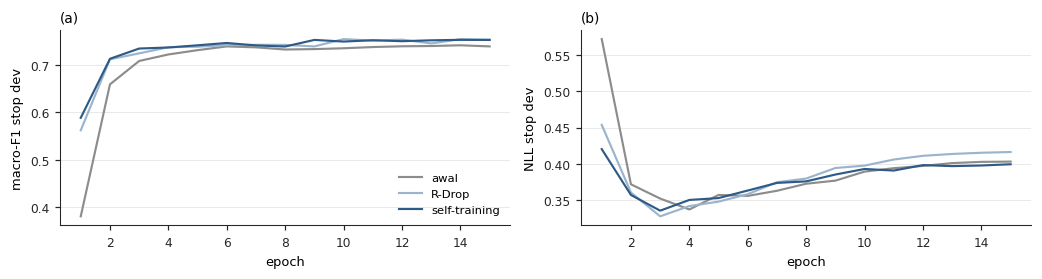

[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a


,model,seed,f1_latih,f1_validasi,celah,f1_latih_terendah,label_latih_terendah
0,awal,42,"0,9839","0,7620","0,2220","0,9552",FLOOD-EVENT
1,awal,43,"0,9788","0,7599","0,2189","0,9215",FLOOD-EVENT
2,awal,44,"0,9804","0,7574","0,2230","0,9327",FLOOD-EVENT
3,R-Drop,42,"0,9950","0,7779","0,2171","0,9882",FLOOD-EVENT
4,R-Drop,43,"0,9944","0,7733","0,2212","0,9832",FLOOD-EVENT
5,R-Drop,44,"0,9947","0,7710","0,2237","0,9878",INFORMATION-ARG
6,self-training,42,"0,9955","0,7764","0,2191","0,9916",FLOOD-EVENT
7,self-training,43,"0,9946","0,7759","0,2187","0,9873",INFORMATION-ARG
8,self-training,44,"0,9943","0,7765","0,2179","0,9882",FLOOD-EVENT


In [62]:
RW = LP.riwayat()
fig, ax = plt.subplots(1, 2, figsize=(9.6, 2.6))
for nama, w in PL.WARNA_MODEL.items():
    r = RW[RW.model == nama].groupby("epoch")[["val_f1", "val_loss"]].mean()
    ax[0].plot(r.index, r.val_f1, color=w, label=nama); ax[1].plot(r.index, r.val_loss, color=w, label=nama)
ax[0].set_ylabel("macro-F1 stop dev"); ax[1].set_ylabel("NLL stop dev")
for a, t in zip(ax, ("(a)", "(b)")):
    a.set_xlabel("epoch"); a.set_title(t, loc="left")
ax[0].legend(); fig.tight_layout(); PL.save(fig, "10_2_riwayat"); plt.show()
display(tabel(LP.fit(), 4))

<div align="justify">

*Macro-F1* *stop dev* naik pada awal pelatihan dan relatif stabil setelah sekitar *epoch* 6, sedangkan *Negative Log-Likelihood* (NLL) mulai naik setelah minimum pada *epoch* 3 sampai 4. NLL adalah rata-rata negatif log probabilitas label benar dan menghukum prediksi salah yang sangat yakin. F1 latih 0,9788 sampai 0,9955 lebih tinggi daripada validasi 0,7574 sampai 0,7779. Pola tersebut menunjukkan celah generalisasi; F1 yang stabil tidak membuktikan bahwa *overfitting* tidak berdampak.

</div>


<div align="justify">

NLL pada *stop dev* dapat naik walaupun *macro-F1* tidak turun karena NLL juga mengukur kalibrasi, yaitu kesesuaian probabilitas prediksi model dengan peluang benarnya. Untuk memisahkan keduanya, *temperature scaling* [4](#ref-4) membagi *logit* setiap model dengan satu angka $T$ yang dicocokkan pada *filter dev*, lalu NLL dan ECE dihitung pada *stop dev*. Pembagian dengan $T$ tidak mengubah label dengan probabilitas tertinggi, sehingga prediksi dan F1 tetap sama. Bila NLL dan ECE turun setelah *temperature scaling*, kenaikan NLL berasal dari kalibrasi, bukan dari prediksi yang memburuk. Nilai $T < 1$ berarti model rata-rata kurang yakin, sedangkan $T > 1$ berarti model terlalu yakin. Dua kolom terakhir dihitung setelah *temperature scaling*: porsi NLL yang berasal dari token salah dan porsi token salah yang diprediksi dengan probabilitas prediksi minimal 0,8.

</div>

<div align="justify">

*Temperature scaling* hanya dipakai untuk analisis ini. Seleksi *pseudo-label* dan *conformal prediction* tetap memakai probabilitas asli. Seleksi hanya bergantung pada urutan probabilitas prediksi, sedangkan jaminan cakupan *conformal* tidak memerlukan kalibrasi dan *filter dev* sudah menjadi bagian dari data kalibrasinya.

</div>


In [63]:
SH = LP.suhu()
display(LP.rerata(SH, ("model",)))

[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a


,T,NLL sebelum,ECE sebelum,NLL sesudah,ECE sesudah,porsi NLL dari token salah,"token salah dengan keyakinan ≥ 0,8"
model,,,,,,,
awal,"0,9053 ± 0,0089","0,4032 ± 0,0022","0,0517 ± 0,005","0,3986 ± 0,0022","0,0242 ± 0,0022","0,8519 ± 0,0055","0,6866 ± 0,0087"
R-Drop,"0,9134 ± 0,0076","0,4163 ± 0,0035","0,043 ± 0,0024","0,4137 ± 0,0042","0,0226 ± 0,0027","0,8615 ± 0,0086","0,7722 ± 0,0019"
self-training,"0,8947 ± 0,0042","0,3995 ± 0,0056","0,0399 ± 0,0032","0,3949 ± 0,0064","0,023 ± 0,002","0,8636 ± 0,0051","0,7736 ± 0,0079"


<div align="justify">

*Temperature scaling* memperoleh T sebesar 0,8947 sampai 0,9134 dan menurunkan ECE, misalnya 0,0517 menjadi 0,0242 pada model awal. NLL turun 0,0026 sampai 0,0046. Sebanyak 85,2% sampai 86,4% NLL berasal dari token salah dan 68,7% sampai 77,4% token salah memiliki *confidence* minimal 0,8. Penyesuaian skala global belum menghilangkan prediksi salah yang terlalu yakin.

</div>


### 10.3 Hasil *Novelty* 2: *Conformal Prediction*

<div align="justify">

Semua hasil memakai $\alpha = 0{,}1$ kecuali disebut lain, artinya label benar ditargetkan masuk himpunan pada minimal 90% token. Model yang diperiksa adalah model awal, R-Drop, dan *self-training* keempat *model bahasa* pada label asli. Setiap angka adalah rata-rata tiga *seed*.

</div>

#### 10.3.1 Batas Probabilitas per Label

<div align="justify">

Gambar berikut menampilkan probabilitas minimum agar sebuah label masuk himpunan, dihitung dari seluruh data validasi. Batas yang rendah berarti label tersebut sering benar walaupun probabilitasnya rendah, sehingga label lain lebih mudah ikut masuk himpunan.

</div>


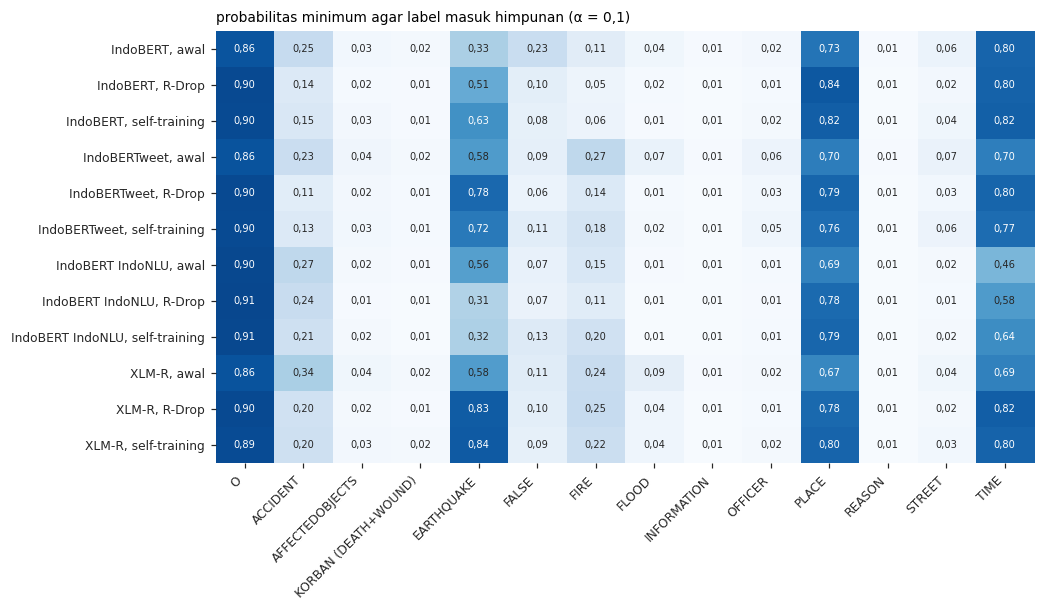

In [64]:
DF = KF.daftar()
NM = {x: KF.nama(*x) for x in DF}
PAPER = "rerata keyakinan per tweet (paper)"
SIN = {PAPER: "artikel (rerata tweet)", "keyakinan token terendah": "token terendah", "skor ternormalisasi logit terendah": "logit ternormalisasi",
       "MC dropout 10 pass": "MC dropout", "lima model penyeleksi": "5 model penyeleksi", "ukuran himpunan conformal": "himpunan conformal"}
WS = dict(zip(SIN, [PL.BATA, PL.BIRU, PL.BIRU_M, PL.ABU, "#B9A27C", PL.TINTA]))
BT = pd.DataFrame({NM[x]: KF.batas(*x) for x in DF}).T
fig, ax = plt.subplots(figsize=(9.6, .3 * len(BT) + 1.5))
PL.heatmap(ax, BT.values, BT.index, [pendek(g) for g in BT.columns], vmin=0, vmax=1)
ax.set_title("probabilitas minimum agar label masuk himpunan (α = 0,1)", loc="left")
PL.save(fig, "10_3_batas"); plt.show()

<div align="justify">

Batas probabilitas berbeda jauh antarlabel. Label O membutuhkan probabilitas 0,86 sampai 0,91, PLACE-ARG 0,67 sampai 0,84, dan TIME-ARG 0,46 sampai 0,82. Sebaliknya, INFORMATION-ARG, REASON-ARG, OFFICER-ARG, korban, dan AFFECTEDOBJECTS-ARG hanya membutuhkan 0,01 sampai 0,06. Batas serendah ini berarti label benar pada kelompok tersebut sering hanya mendapat probabilitas kecil, sehingga label itu ikut masuk himpunan setiap kali probabilitasnya minimal 0,01. Akibatnya, label argumen yang sulit menjadi sumber utama token yang ditandai pada Bab 10.3.2. EARTHQUAKE-EVENT paling bervariasi antarmodel (0,31 sampai 0,84).

</div>


#### 10.3.2 Cakupan dan Beban Peninjauan

<div align="justify">

Tabel pertama merangkum semua model pada $\alpha = 0{,}1$. Tabel kedua memperlihatkan IndoBERT *self-training* pada beberapa $\alpha$, termasuk $\alpha$ terpisah untuk label O. Gambar di bawahnya memperlihatkan beban peninjauan ketiga model IndoBERT dan cakupan per kelompok label semua model.

</div>


,cakupan_bukan_O,cakupan_O,rerata_ukuran,token_ditinjau,tweet_ditinjau,token_salah_tertangkap,tweet_salah_tertangkap
model,,,,,,,
"IndoBERT, awal","0,898","0,900","1,257","0,210","0,820","0,553","0,904"
"IndoBERT, R-Drop","0,899","0,900","1,461","0,344","0,857","0,604","0,925"
"IndoBERT, self-training","0,899","0,900","1,497","0,365","0,875","0,626","0,938"
"IndoBERTweet, awal","0,897","0,900","1,365","0,296","0,894","0,618","0,946"
"IndoBERTweet, R-Drop","0,898","0,901","1,402","0,280","0,907","0,635","0,955"
"IndoBERTweet, self-training","0,898","0,901","1,430","0,302","0,913","0,656","0,962"
"IndoBERT IndoNLU, awal","0,899","0,901","1,924","0,537","0,983","0,784","0,994"
"IndoBERT IndoNLU, R-Drop","0,898","0,901","2,380","0,694","0,992","0,833","0,997"
"IndoBERT IndoNLU, self-training","0,898","0,901","2,006","0,568","0,973","0,803","0,988"


,,cakupan_bukan_O,cakupan_O,rerata_ukuran,token_ditinjau,tweet_ditinjau,token_salah_tertangkap,tweet_salah_tertangkap
alpha,alpha_O,,,,,,,
0.050000,0.050000,"0,949","0,950","3,113","0,849","0,997","0,859","0,999"
0.100000,0.100000,"0,899","0,900","1,497","0,365","0,875","0,626","0,938"
0.200000,0.200000,"0,798","0,800","0,912","0,179","0,836","0,498","0,922"
0.100000,0.010000,"0,899","0,990","1,673","0,431","0,926","0,783","0,971"


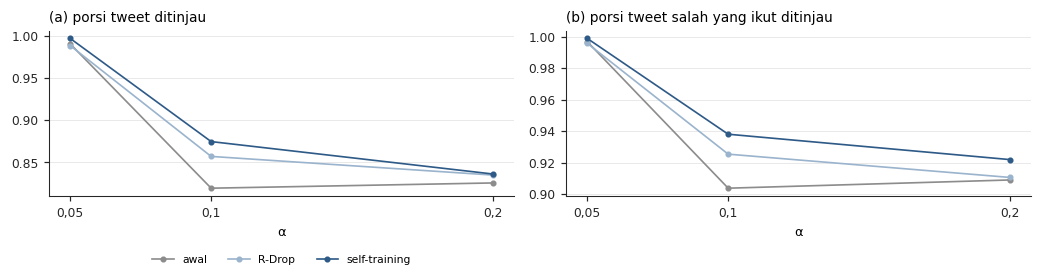

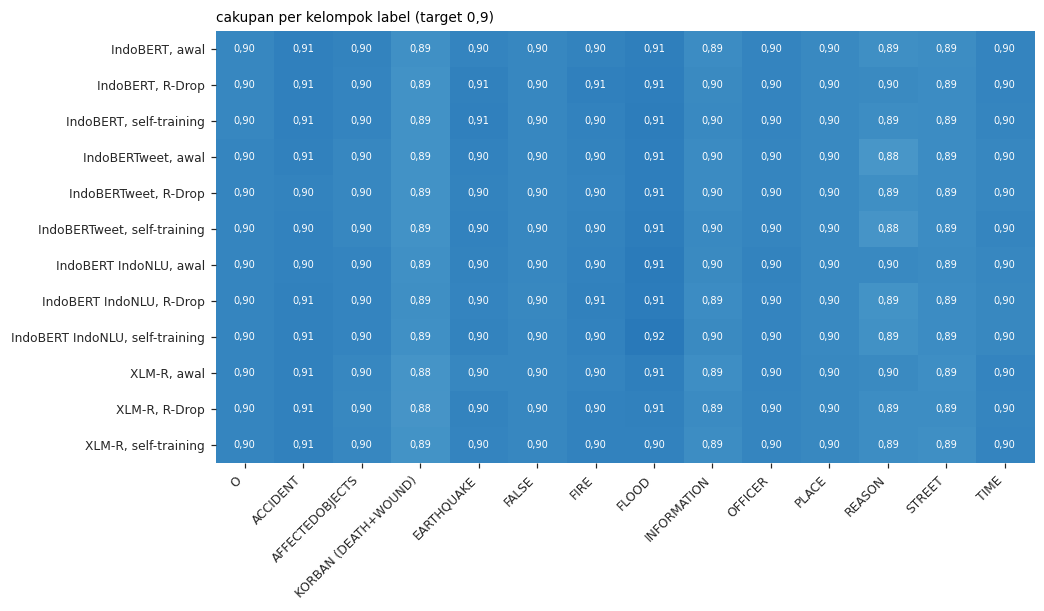

In [65]:
KON = {x: KF.resplit(*x) for x in DF}
RG = pd.concat([r.drop(columns="seed").assign(model=NM[x]) for x, (_, r, _) in KON.items()]).groupby(["model", "alpha", "alpha_O"], sort=False).mean()
display(tabel(RG.xs((.1, .1), level=["alpha", "alpha_O"]), 3))
display(tabel(RG.loc[NM[(C.BACKBONE_PAPER, "st")]], 3))
ib = RG.reset_index()
ib = ib[(ib.alpha == ib.alpha_O) & ib.model.str.startswith("IndoBERT,")]
fig, ax = plt.subplots(1, 2, figsize=(9.6, 2.8), sharex=True)
for nama, r in ib.groupby("model", sort=False):
    for a, kol in zip(ax, ("tweet_ditinjau", "tweet_salah_tertangkap")):
        a.plot(r.alpha, r[kol], "o-", color=PL.WARNA_MODEL[nama.split(", ")[1]], ms=3, lw=1.1, label=nama.removeprefix("IndoBERT, "))
for a, t in zip(ax, ("(a) porsi tweet ditinjau", "(b) porsi tweet salah yang ikut ditinjau")):
    a.set_xticks([.05, .1, .2], ["0,05", "0,1", "0,2"]); a.set_xlabel("α"); a.set_title(t, loc="left")
PL.legenda_bawah(ax[0], 3, y=-.3, fontsize=7); fig.tight_layout(); PL.save(fig, "10_3_beban"); plt.show()
GR = pd.concat([g.assign(model=NM[x]) for x, (g, _, _) in KON.items()])
GR = GR[(GR.alpha == .1) & (GR.alpha_O == .1)].groupby(["model", "grup"], sort=False).cakupan.mean().unstack().reindex(columns=KF.GRUP)
fig, ax = plt.subplots(figsize=(9.6, .3 * len(GR) + 1.5))
PL.heatmap(ax, GR.values, GR.index, [pendek(g) for g in GR.columns], vmin=.7, vmax=1)
ax.set_title("cakupan per kelompok label (target 0,9)", loc="left")
PL.save(fig, "10_3_cakupan_label"); plt.show()

<div align="justify">

Pada target 0,9, cakupan validasi berada pada 0,897 sampai 0,899 untuk token bukan O dan 0,900 sampai 0,901 untuk O. Angka yang mendekati target merupakan bukti empiris, bukan pembuktian jaminan formal. Aturan penerimaan menandai 82,0% *tweet* IndoBERT awal dan 87,5% *tweet* *self-training*. *Self-training* menjaring 93,8% *tweet* salah, tetapi beban peninjauannya lebih besar.

</div>


#### 10.3.3 Cakupan per Kelompok *Tweet* dan Contoh Himpunan

<div align="justify">

Jaminan *conformal* berlaku rata-rata atas semua token. Gambar berikut memeriksa apakah rata-rata itu menutupi kelompok *tweet* yang cakupannya jauh di bawah target. Tabel di bawahnya memperlihatkan contoh token yang ditandai pada IndoBERT *self-training* *seed* 42.

</div>


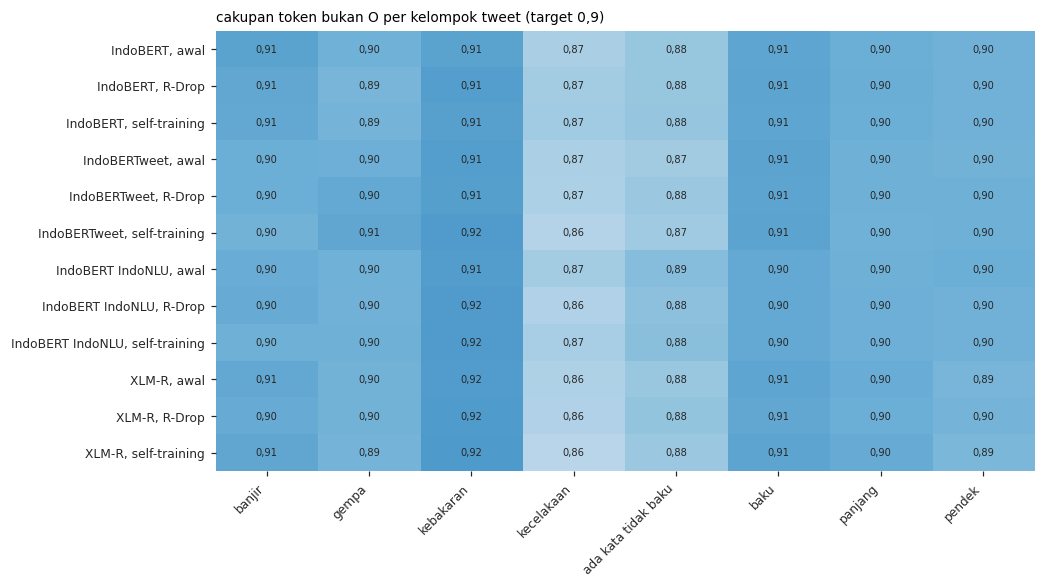

,tweet,konteks,token,label_asli,prediksi,himpunan
0,BAN-01886,yang terkena musibah banjir di konawe sulawesi,banjir,FALSE-EVENT,FALSE-EVENT,"FALSE-EVENT (0.94), FLOOD-EVENT (0.01)"
1,BAN-01065,di berbagai titik kecamatan kabtrenggalek,kecamatan,PLACE-ARG,PLACE-ARG,"PLACE-ARG (0.92), FLOOD-EVENT (0.01)"
2,BAN-01413,mobil terendam banjir di rumah,terendam,AFFECTEDOBJECTS-ARG,O,"O (0.92), INFORMATION-ARG (0.01), FLOOD-EVENT (0.01)"
3,BAN-01413,terendam banjir di rumah sakit urip sumoharjo,rumah,PLACE-ARG,INFORMATION-ARG,"INFORMATION-ARG (0.42), AFFECTEDOBJECTS-ARG (0.26), WOUNDVICTIM-ARG (0.03), OFFICER-ARG (0.02), FLOOD-EVEN..."
4,BAN-01413,banjir di rumah sakit urip sumoharjo,sakit,PLACE-ARG,INFORMATION-ARG,"INFORMATION-ARG (0.39), AFFECTEDOBJECTS-ARG (0.25), WOUNDVICTIM-ARG (0.03), OFFICER-ARG (0.03), FLOOD-EVEN..."
5,BAN-01101,semarang jateng banjir masuk koran btw,banjir,FALSE-EVENT,FALSE-EVENT,"FALSE-EVENT (0.93), FLOOD-EVENT (0.03)"
6,BAN-01101,itu motor yang kebanjiran di dorong apa,kebanjiran,FALSE-EVENT,O,"FALSE-EVENT (0.23), INFORMATION-ARG (0.01), FLOOD-EVENT (0.01), REASON-ARG (0.01)"


In [66]:
STR = pd.concat([s.assign(model=NM[x]) for x, (_, _, s) in KON.items()]).groupby(["model", "kelompok", "nilai"], sort=False).cakupan_bukan_O.mean().unstack([1, 2])
fig, ax = plt.subplots(figsize=(9.6, .3 * len(STR) + 1.6))
PL.heatmap(ax, STR.values, STR.index, [v for _, v in STR.columns], vmin=.8, vmax=1)
ax.set_title("cakupan token bukan O per kelompok tweet (target 0,9)", loc="left")
PL.save(fig, "10_3_cakupan_kelompok"); plt.show()
display(KF.contoh(C.BACKBONE_PAPER, "st"))

<div align="justify">

Cakupan berbeda menurut kelompok *tweet*: kecelakaan 0,86 sampai 0,87, bahasa tidak baku 0,87 sampai 0,89, dan kebakaran 0,91 sampai 0,92. Cakupan per kelompok label tidak menjamin cakupan setiap kelompok *tweet*. Contoh “kebanjiran” menunjukkan masalah operasional: model memilih O, sementara himpunan memuat FALSE-EVENT. Aturan baru menandai ketidaksesuaian ini meskipun himpunannya hanya memiliki satu anggota.

</div>


#### 10.3.4 Pengurutan *Tweet* Berdasarkan Ketidakpastian

<div align="justify">

Sebuah sinyal ketidakpastian dinilai dengan AURC: *tweet* diurutkan dari yang paling yakin, lalu porsi *tweet* yang memuat kesalahan dihitung pada setiap tingkat penerimaan [17](#ref-17). Rata-rata probabilitas prediksi per *tweet* pada penelitian sebelumnya menjadi acuan, dan selisih yang CI 95%-nya tidak melewati nol dianggap nyata.

</div>


sinyal,artikel (rerata tweet),token terendah,logit ternormalisasi,MC dropout,5 model penyeleksi,himpunan conformal,acak (tanpa urutan)
model,,,,,,,
"IndoBERT, awal","0,467","0,432","0,419","0,426","0,483","0,493","0,648"
"IndoBERT, R-Drop","0,474","0,429","0,415","0,423","0,472","0,494","0,626"
"IndoBERT, self-training","0,426","0,392","0,383","0,411","0,464","0,470","0,615"
"IndoBERTweet, awal","0,481","0,461","0,447","0,451","0,493","0,530","0,663"
"IndoBERTweet, R-Drop","0,487","0,446","0,432","0,440","0,490","0,485","0,652"
"IndoBERTweet, self-training","0,444","0,414","0,404","0,431","0,467","0,448","0,631"
"IndoBERT IndoNLU, awal","0,461","0,429","0,420","0,423","0,464","0,528","0,646"
"IndoBERT IndoNLU, R-Drop","0,486","0,448","0,421","0,462","0,467","0,543","0,639"
"IndoBERT IndoNLU, self-training","0,437","0,408","0,400","0,445","0,456","0,507","0,627"


,AURC,ci_bawah,ci_atas,selisih_vs_paper,selisih_bawah,selisih_atas,F1_diterima_50%,F1_diterima_70%,F1_diterima_90%
sinyal,,,,,,,,,
rerata keyakinan per tweet (paper),"0,426","0,373","0,478","0,000","0,000","0,000","0,816","0,818","0,784"
keyakinan token terendah,"0,392","0,343","0,442","-0,034","-0,049","-0,018","0,842","0,814","0,788"
skor ternormalisasi logit terendah,"0,383","0,336","0,436","-0,043","-0,066","-0,019","0,810","0,819","0,793"
MC dropout 10 pass,"0,411","0,383","0,487","-0,015","-0,024","0,041","0,796","0,787","0,785"
lima model penyeleksi,"0,464","0,428","0,535","0,038","0,015","0,090","0,776","0,799","0,784"
ukuran himpunan conformal,"0,470","0,422","0,520","0,044","0,023","0,067","0,800","0,791","0,785"
acak (tanpa urutan),"0,615",,,,,,,,


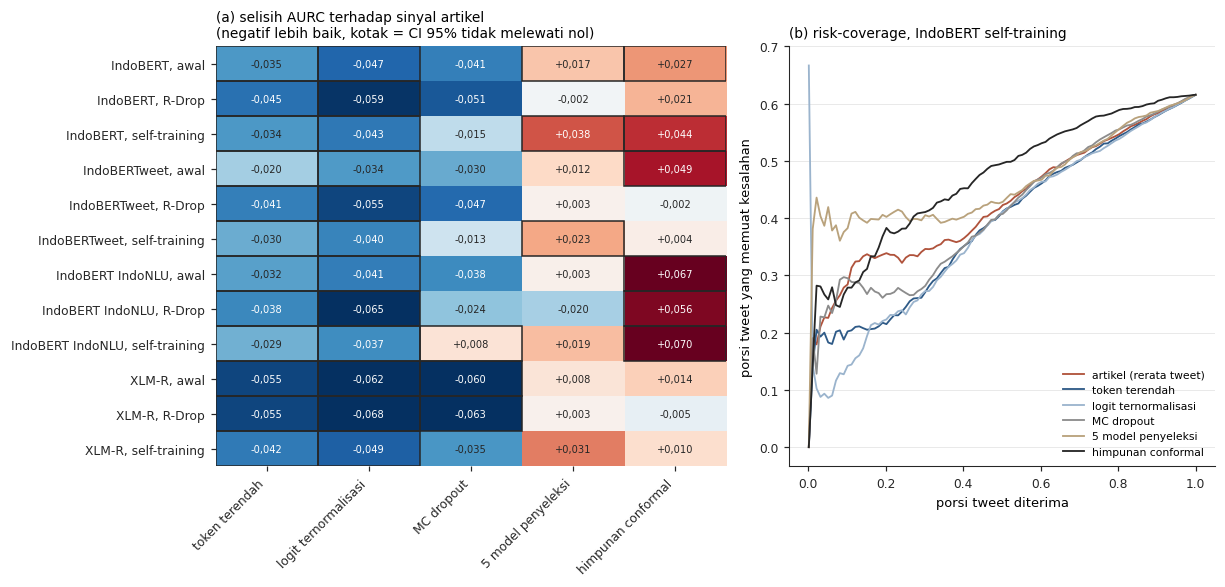

In [67]:
RS = {x: KF.risiko(*x) for x in DF}
RT = pd.concat([t.assign(model=NM[x]) for x, (t, _) in RS.items()])
display(tabel(RT.pivot_table(index="model", columns="sinyal", values="AURC", sort=False).rename(columns=lambda c: SIN.get(c, c)), 3))
display(tabel(RS[(C.BACKBONE_PAPER, "st")][0].set_index("sinyal"), 3))
DS = RT[RT.sinyal.isin(list(SIN)[1:])].pivot_table(index="model", columns="sinyal", values="selisih_vs_paper", sort=False)
NY = RT[RT.sinyal.isin(list(SIN)[1:])].assign(nyata=lambda d: (d.selisih_atas < 0) | (d.selisih_bawah > 0)).pivot_table(index="model", columns="sinyal", values="nyata", sort=False)
fig, ax = plt.subplots(1, 2, figsize=(11.2, .3 * len(DS) + 1.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
PL.heatmap(ax[0], DS.values, DS.index, [SIN[c] for c in DS.columns], fmt="{:+.3f}", cmap="RdBu_r", vmin=-.06, vmax=.06)
for i, j in zip(*np.where(NY.values.astype(bool))):
    ax[0].add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, ec=PL.TINTA, lw=1))
ax[0].set_title("(a) selisih AURC terhadap sinyal artikel\n(negatif lebih baik, kotak = CI 95% tidak melewati nol)", loc="left")
for nama, r in RS[(C.BACKBONE_PAPER, "st")][1].groupby("sinyal", sort=False):
    ax[1].plot(r.diterima, r.tweet_salah, color=WS[nama], lw=1.2, label=SIN[nama])
ax[1].set_xlabel("porsi tweet diterima"); ax[1].set_ylabel("porsi tweet yang memuat kesalahan"); ax[1].legend(fontsize=7)
ax[1].set_title("(b) risk-coverage, IndoBERT self-training", loc="left")
fig.tight_layout(); PL.save(fig, "10_3_aurc"); plt.show()

<div align="justify">

Skor ternormalisasi terendah memberikan AURC terkecil pada ke-12 model dalam evaluasi tersimpan. Pada IndoBERT *self-training*, nilainya 0,383 dibanding 0,426 untuk rata-rata probabilitas *tweet*. CI selisih berada di bawah nol. Sinyal ini lebih baik untuk mengurutkan *tweet* pada data tersebut, tetapi tidak menghasilkan jaminan ketepatan otomatis. Evaluasi penerimaan memisahkan pembentukan himpunan, penentuan batas, dan pengukuran galat.

</div>


#### 10.3.5 Penerimaan dan Dua Ukuran Galat

<div align="justify">

Salah lolos menggunakan seluruh *tweet* salah sebagai penyebut. Risiko *tweet* diterima menggunakan seluruh *tweet* yang diterima sebagai penyebut. Kedua ukuran dilaporkan terpisah agar proporsi kesalahan yang lolos tidak disamakan dengan risiko pada kelompok yang diterima.

</div>


sinyal,artikel (rerata tweet),token terendah,logit ternormalisasi,MC dropout,5 model penyeleksi,himpunan conformal
model,,,,,,
"IndoBERT, awal","0,160","0,213","0,212","0,053","0,000","0,165"
"IndoBERT, R-Drop","0,139","0,193","0,204","0,002","0,000","0,159"
"IndoBERT, self-training","0,174","0,236","0,238","0,001","0,000","0,162"
"IndoBERTweet, awal","0,164","0,198","0,206","0,012","0,000","0,161"
"IndoBERTweet, R-Drop","0,145","0,197","0,214","0,001","0,000","0,152"
"IndoBERTweet, self-training","0,169","0,214","0,226","0,000","0,000","0,157"
"IndoBERT IndoNLU, awal","0,159","0,208","0,219","0,001","0,000","0,142"
"IndoBERT IndoNLU, R-Drop","0,135","0,178","0,207","0,000","0,000","0,136"
"IndoBERT IndoNLU, self-training","0,161","0,215","0,227","0,000","0,000","0,141"


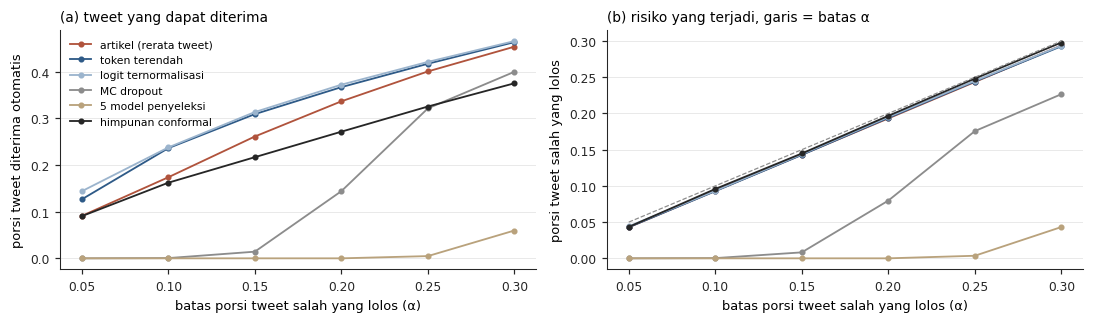

In [68]:
KDL = pd.concat([KF.kendali(*x).assign(model=NM[x]) for x in DF])
display(tabel(KDL[KDL.alpha == .1].pivot_table(index="model", columns="sinyal", values="diterima", sort=False).rename(columns=SIN), 3))
ks = KDL[KDL.model == NM[(C.BACKBONE_PAPER, "st")]]
display(tabel(ks[ks.alpha.isin([.05, .1, .2])].set_index(["sinyal", "alpha"]).drop(columns="model").rename(index=SIN), 3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw=dict(width_ratios=[1, 1]))
for nama, r in ks.groupby("sinyal", sort=False):
    ax[0].plot(r.alpha, r.diterima, "o-", color=WS[nama], lw=1.2, ms=3, label=SIN[nama])
    ax[1].plot(r.alpha, r.salah_lolos, "o-", color=WS[nama], lw=1.2, ms=3)
ax[1].plot([.05, .3], [.05, .3], color=PL.ABU, lw=.8, ls="--")
ax[0].set_ylabel("porsi tweet diterima otomatis"); ax[1].set_ylabel("porsi tweet salah yang lolos")
for a, t in zip(ax, ("(a) tweet yang dapat diterima", "(b) risiko yang terjadi, garis = batas α")):
    a.set_xlabel("batas porsi tweet salah yang lolos (α)"); a.set_title(t, loc="left")
ax[0].legend(fontsize=7); fig.tight_layout(); PL.save(fig, "10_3_kendali"); plt.show()

<div align="justify">

Skor ternormalisasi menerima 23,8% *tweet* validasi IndoBERT *self-training*. Sebanyak 9,3% dari seluruh *tweet* salah ikut lolos. Di antara *tweet* yang diterima, 23,4% masih mengandung kesalahan dan galat tingkat token sebesar 2,1%. Angka tersebut memakai penyebut berbeda. Rata-rata probabilitas menerima 17,4% *tweet*. Pemisahan tiga bagian validasi menjaga agar label pengukuran galat tidak ikut menentukan batas penerimaan.

</div>


### 10.4 Hasil *Novelty* 3: Uji Lintas Jenis Kejadian (IndoBERT)


[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a


,,tweet,f1_dalam_domain,f1_jenis_dikeluarkan,sd_jenis_dikeluarkan,selisih,ci_bawah,ci_atas
model,jenis,,,,,,,
awal,gabungan,599,"0,744","0,556","0,011","-0,188","-0,218","-0,165"
R-Drop,gabungan,599,"0,761","0,564","0,004","-0,196","-0,230","-0,173"
self-training,gabungan,599,"0,761","0,489","0,008","-0,273","-0,310","-0,247"
self-training dikurangi awal,gabungan,599,,,,"-0,067","-0,081","-0,055"
self-training dikurangi R-Drop,gabungan,599,,,,"-0,075","-0,090","-0,064"
R-Drop dikurangi awal,gabungan,599,,,,"0,008","-0,001","0,017"
awal,banjir,195,"0,691","0,510","0,024","-0,181","-0,242","-0,137"
R-Drop,banjir,195,"0,720","0,529","0,021","-0,191","-0,260","-0,137"
self-training,banjir,195,"0,722","0,466","0,017","-0,255","-0,329","-0,204"


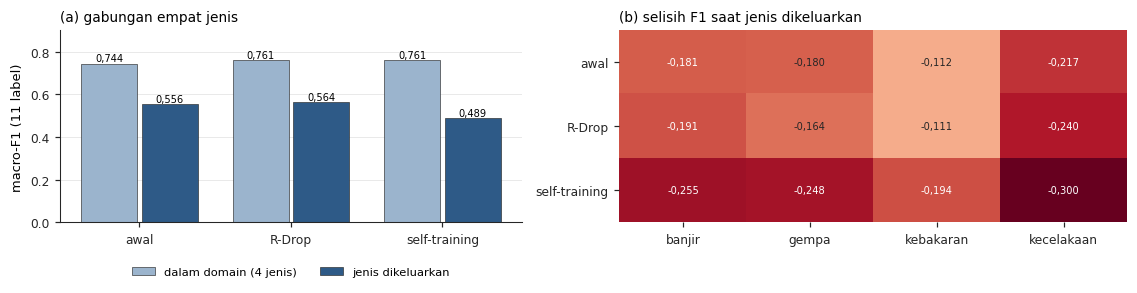

[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a


In [69]:
TAB, PER_LABEL = LK.hasil()
display(tabel(TAB.set_index(["model", "jenis"]), 3))
ga = TAB[(TAB.jenis == "gabungan") & TAB.model.isin(LK.MODEL.values())].set_index("model").reindex(LK.MODEL.values())
pj = TAB[(TAB.jenis != "gabungan") & TAB.model.isin(LK.MODEL.values())].pivot(index="model", columns="jenis", values="selisih")
pj = pj.reindex(index=LK.MODEL.values(), columns=list(LK.NAMA.values()))
fig, ax = plt.subplots(1, 2, figsize=(10.4, 2.8), gridspec_kw=dict(width_ratios=[1, 1.1]))
x = ga[["f1_dalam_domain", "f1_jenis_dikeluarkan"]].set_axis(["dalam domain (4 jenis)", "jenis dikeluarkan"], axis=1)
PL.kelompok(ax[0], x, {"dalam domain (4 jenis)": PL.BIRU_M, "jenis dikeluarkan": PL.BIRU}, ylabel="macro-F1 (11 label)", fmt=lambda v: f"{v:.3f}".replace(".", ","))
ax[0].set_ylim(0, .9); PL.legenda_bawah(ax[0], 2, y=-.18); ax[0].set_title("(a) gabungan empat jenis", loc="left")
PL.heatmap(ax[1], pj.values, pj.index, pj.columns, fmt="{:+.3f}", cmap="RdBu", vmin=-.3, vmax=.3, rot=0)
ax[1].set_title("(b) selisih F1 saat jenis dikeluarkan", loc="left")
fig.tight_layout(); PL.save(fig, "10_4_lintas"); plt.show()
display(tabel(PER_LABEL.pivot_table(index="label", columns="model", values=["dalam_domain", "jenis_dikeluarkan"], sort=False), 3))
display(tabel(LK.token_kejadian().set_index(["model", "sumber", "jenis"]), 1))

<div align="justify">

Mengeluarkan satu jenis kejadian menurunkan *macro-F1* gabungan model awal dari 0,744 menjadi 0,556 (−0,188) dan R-Drop dari 0,761 menjadi 0,564 (−0,196). *Self-training* turun paling dalam, dari 0,761 menjadi 0,489 (−0,273), dan selisihnya terhadap model awal (−0,067) maupun R-Drop (−0,075) memiliki CI 95% di bawah nol. Penurunan terbesar terjadi saat kecelakaan dikeluarkan (−0,217 sampai −0,300) dan terkecil saat kebakaran dikeluarkan (−0,111 sampai −0,194).

</div>

<div align="justify">

Tabel per label menunjukkan penyebabnya. Argumen yang tidak khas jenis kejadian tetap dikenali, misalnya PLACE-ARG (0,879 sampai 0,885) dan TIME-ARG (0,849 sampai 0,861). Sebaliknya, F1 KEJADIAN NYATA turun dari sekitar 0,83 menjadi 0,420 (awal), 0,473 (R-Drop), dan 0 (*self-training*). INFORMATION-ARG juga hampir hilang (0,017 sampai 0,120) karena keterangannya khas tiap jenis, misalnya magnitudo pada gempa. Tabel terakhir memperlihatkan bahwa model awal dan R-Drop masih sering menebak kata kejadian baru sebagai jenis nyata lain, misalnya 48,7% kata kebakaran ditebak sebagai kejadian nyata lain oleh model awal, dan tebakan ini tetap dihitung benar sebagai KEJADIAN NYATA. *Self-training* tidak pernah melakukannya. Kata banjir, gempa, dan kecelakaan hampir selalu ditebak O (95,5% sampai 100%), dan kata kebakaran ditebak FALSE-EVENT (86,4%).

</div>


<div align="justify">

Tabel pertama di bawah menghitung rata-rata token *pseudo-label* per *seed* yang diambil dari *pool* jenis yang dikeluarkan dan jenis lain. Tabel kedua menerapkan *conformal prediction* Bab 8.2 pada model lintas kejadian. Kalibrasi memakai *tweet* jenis lain, lalu cakupan dihitung pada jenis yang dikeluarkan, baik tanpa maupun dengan 25 dan 50 *tweet* jenis tersebut ditambahkan ke data kalibrasi.

</div>


label                              ACCIDENT-EVENT  AFFECTEDOBJECTS-ARG  \
jenis      pool                                                          
banjir     jenis lain                       227.0               2490.0   
           jenis yang dikeluarkan             0.0                  5.0   
gempa      jenis lain                       227.0               2491.0   
           jenis yang dikeluarkan             0.0                 13.0   
kebakaran  jenis lain                       327.0                544.0   
           jenis yang dikeluarkan             1.0                764.0   
kecelakaan jenis lain                         0.0               2323.0   
           jenis yang dikeluarkan             0.0                 98.0   

label                              DEATHVICTIM-ARG  EARTHQUAKE-EVENT  \
jenis      pool                                                        
banjir     jenis lain                        494.0             229.0   
           jenis yang dikeluarkan              5.0               0.0   
gempa      jenis lain                        492.0               0.0   
           jenis yang dikeluarkan             27.0               0.0   
kebakaran  jenis lain                        163.0             218.0   
           jenis yang dikeluarkan            226.0               0.0   
kecelakaan jenis lain                        382.0             231.0   
           jenis yang dikeluarkan            120.0               0.0   

label                              FALSE-EVENT  FIRE-EVENT  FLOOD-EVENT  \
jenis      pool                                                           
banjir     jenis lain                   1507.0       707.0          0.0   
           jenis yang dikeluarkan          7.0         0.0          0.0   
gempa      jenis lain                   1178.0       726.0         50.0   
           jenis yang dikeluarkan         10.0         0.0          0.0   
kebakaran  jenis lain                   1334.0         0.0         51.0   
           jenis yang dikeluarkan        381.0         0.0          0.0   
kecelakaan jenis lain                   1493.0       723.0         51.0   
           jenis yang dikeluarkan          0.0         1.0          0.0   

label                              INFORMATION-ARG  OFFICER-ARG  PLACE-ARG  \
jenis      pool                                                              
banjir     jenis lain                        555.0       1284.0     5610.0   
           jenis yang dikeluarkan              0.0        105.0      683.0   
gempa      jenis lain                        191.0       1181.0     5411.0   
           jenis yang dikeluarkan              0.0        125.0     1023.0   
kebakaran  jenis lain                        527.0        468.0     2276.0   
           jenis yang dikeluarkan              6.0        666.0     3351.0   
kecelakaan jenis lain                        580.0       1336.0     6446.0   
           jenis yang dikeluarkan             15.0         89.0      320.0   

label                              REASON-ARG  STREET-ARG  TIME-ARG  \
jenis      pool                                                       
banjir     jenis lain                   217.0      2073.0    1717.0   
           jenis yang dikeluarkan         0.0        37.0      63.0   
gempa      jenis lain                   308.0      2060.0    1522.0   
           jenis yang dikeluarkan         0.0         0.0     164.0   
kebakaran  jenis lain                    72.0       566.0     755.0   
           jenis yang dikeluarkan       100.0      1237.0     852.0   
kecelakaan jenis lain                   267.0      1597.0    1581.0   
           jenis yang dikeluarkan         2.0       142.0     135.0   

label                              WOUNDVICTIM-ARG  
jenis      pool                                     
banjir     jenis lain                        102.0  
           jenis yang dikeluarkan              0.0  
gempa      jenis lain                         92.0  
           jenis yang dikeluar

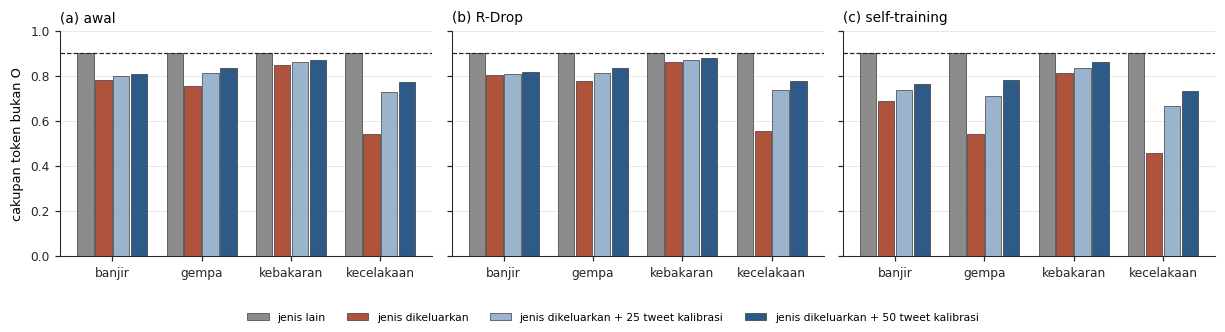

In [70]:
PR_ = LK.pseudo_rinci()
display(PR_.pivot_table(index=["jenis", "pool"], columns="label", values="token", aggfunc="sum", fill_value=0, sort=False)[sorted(set(PR_.label), key=C.LABELS.index)].round(0))
GS = KF.pergeseran()
display(tabel(GS.pivot_table(index=["model", "kondisi"], columns="jenis", values="cakupan_bukan_O", sort=False), 3))
fig, ax = plt.subplots(1, 3, figsize=(11.2, 3), sharey=True)
for a, h, (nama, r) in zip(ax, "abc", GS.groupby("model", sort=False)):
    g = r.pivot(index="jenis", columns="kondisi", values="cakupan_bukan_O").reindex(index=list(LK.NAMA.values()), columns=list(dict.fromkeys(GS.kondisi)))
    PL.kelompok(a, g, dict(zip(g.columns, (PL.ABU, PL.BATA, PL.BIRU_M, PL.BIRU))))
    a.axhline(.9, color=PL.TINTA, lw=.8, ls="--"); a.set_ylim(0, 1); a.set_title(f"({h}) {nama}", loc="left")
ax[0].set_ylabel("cakupan token bukan O")
fig.tight_layout(rect=(0, .1, 1, 1)); fig.legend(*ax[0].get_legend_handles_labels(), ncol=4, loc="lower center", fontsize=7)
PL.save(fig, "10_4_conformal_lintas"); plt.show()

<div align="justify">

Tabel *pseudo-label* menjelaskan kegagalan *self-training*. Pada *pool* jenis yang dikeluarkan, model penyeleksi tidak pernah memberi label kejadian nyata jenis tersebut. Saat kebakaran dikeluarkan, FIRE-EVENT mendapat 0 token, sedangkan FALSE-EVENT mendapat 381 token. Pada banjir, gempa, dan kecelakaan, kata kejadiannya juga tidak mendapat label jenisnya sendiri. Model ronde lalu belajar dari *pseudo-label* tersebut, sehingga kesalahan model penyeleksi diperkuat. *Confirmation bias* ini tidak terlihat pada uji dalam domain.

</div>

<div align="justify">

Tabel kedua memperlihatkan bahwa jaminan *conformal* tidak berlaku saat jenis kejadian berubah. Bila kalibrasi hanya memakai jenis lain, cakupan token bukan O pada jenis baru turun menjadi 0,539 sampai 0,847 (awal), 0,555 sampai 0,861 (R-Drop), dan 0,457 sampai 0,810 (*self-training*), jauh di bawah target 0,9. Menambahkan 50 *tweet* jenis baru ke data kalibrasi menaikkan cakupan menjadi 0,733 sampai 0,878, tetapi belum mencapai target. Oleh karena itu, untuk jenis bencana baru, data kalibrasi perlu diperbarui dengan *tweet* dari jenis tersebut sebelum himpunan *conformal* dipercaya.

</div>


### 10.5 Evaluasi Akhir pada Data Uji

<div align="justify">

Data uji berisi 946 *tweet* setelah 54 *tweet* luar Indonesia dikeluarkan dengan aturan yang sama seperti data latih. Data ini tidak dipakai untuk memilih metode, *hyperparameter*, *epoch*, atau *threshold* *conformal*.

</div>


In [71]:
MT = LP.metrik("test")
display(LP.rerata(MT))
display(tabel(LP.tabel_banding("test"), 4))

[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a
[awal IndoBERTweet seed42] memakai hasil tersimpan runs/e92485f00487
[awal IndoBERTweet seed43] memakai hasil tersimpan runs/e1ff1a83f0d9
[awal IndoBERTweet seed44] memakai hasil tersimpan runs/14d89dd25b28
[awal IndoBERT IndoNLU seed42] memakai hasil tersimpan runs/b1d67f8b3456
[awal IndoBERT IndoNLU seed43] memakai hasil tersimpan runs/ee51bb52d281
[awal IndoBERT IndoNLU seed44] memakai hasil tersimpan runs/02a5c87a025f
[awal XLM-R seed42] memakai hasil tersimpan runs/76e4daa94aa9
[awal XLM-R seed43] memakai hasil tersimpan runs/b1a090cd3527
[awal XLM-R seed44] memakai hasil tersimpan runs/006acd51eb44


accuracy        precision  \
backbone         model                                             
IndoBERT         awal           0,9062 ± 0,0004  0,7287 ± 0,0018   
                 R-Drop         0,9101 ± 0,0006  0,7421 ± 0,0071   
                 self-training  0,9125 ± 0,0009  0,7543 ± 0,0015   
IndoBERTweet     awal           0,9044 ± 0,0009  0,7329 ± 0,0057   
                 R-Drop         0,9073 ± 0,0012  0,7422 ± 0,0006   
                 self-training  0,9109 ± 0,0012  0,7569 ± 0,0057   
IndoBERT IndoNLU awal            0,909 ± 0,0019  0,7651 ± 0,0078   
                 R-Drop         0,9082 ± 0,0008  0,7649 ± 0,0016   
                 self-training  0,9126 ± 0,0015   0,7823 ± 0,008   
XLM-R            awal           0,9037 ± 0,0007  0,7288 ± 0,0049   
                 R-Drop         0,9071 ± 0,0006  0,7438 ± 0,0031   
                 self-training  0,9105 ± 0,0004  0,7572 ± 0,0006   

                                         recall         macro-F1  \
backbone         model                                             
IndoBERT         awal           0,7805 ± 0,0067  0,7507 ± 0,0024   
                 R-Drop         0,7872 ± 0,0055  0,7608 ± 0,0047   
                 self-training  0,7828 ± 0,0023  0,7644 ± 0,0014   
IndoBERTweet     awal           0,7701 ± 0,0037  0,7464 ± 0,0037   
                 R-Drop         0,7758 ± 0,0054  0,7553 ± 0,0028   
                 self-training  0,7719 ± 0,0016  0,7592 ± 0,0043   
IndoBERT IndoNLU awal            0,7439 ± 0,002  0,7511 ± 0,0036   
                 R-Drop         0,7401 ± 0,0076  0,7481 ± 0,0055   
                 self-training  0,7409 ± 0,0073   0,756 ± 0,0064   
XLM-R            awal           0,7815 ± 0,0063  0,7529 ± 0,0057   
                 R-Drop         0,7777 ± 0,0033   0,759 ± 0,0033   
                 self-training  0,7816 ± 0,0031   0,7665 ± 0,001   

                                    weighted F1          span F1  
backbone         model                                            
IndoBERT         awal           0,9074 ± 0,0005   0,745 ± 0,0031  
                 R-Drop         0,9109 ± 0,0008  0,7584 ± 0,0021  
                 self-training  0,9127 ± 0,0007  0,7644 ± 0,0018  
IndoBERTweet     awal            0,9046 ± 0,001  0,7327 ± 0,0037  
                 R-Drop         0,9075 ± 0,0011  0,7458 ± 0,0027  
                 self-training  0,9103 ± 0,0012    0,757 ± 0,004  
IndoBERT IndoNLU awal           0,9079 ± 0,0019  0,7405 ± 0,0046  
                 R-Drop          0,9071 ± 0,001   0,745 ± 0,0022  
                 self-training  0,9109 ± 0,0016   0,756 ± 0,0054  
XLM-R            awal           0,9049 ± 0,0008  0,7374 ± 0,0023  
                 R-Drop         0,9078 ± 0,0004  0,7495 ± 0,0041  
                 self-training  0,9104 ± 0,0004  0,7591 ± 0,0027

,backbone,model,acuan,selisih,ci_bawah,ci_atas,seed_naik
0,IndoBERT,self-training,awal,"0,0137","0,0065","0,0209",3/3
1,IndoBERT,self-training,R-Drop,"0,0036","-0,0030","0,0092",2/3
2,IndoBERT,R-Drop,awal,"0,0101","0,0045","0,0162",3/3
3,IndoBERTweet,self-training,awal,"0,0128","0,0053","0,0200",3/3
4,IndoBERTweet,self-training,R-Drop,"0,0039","-0,0022","0,0102",2/3
5,IndoBERTweet,R-Drop,awal,"0,0089","0,0036","0,0140",3/3
6,IndoBERT IndoNLU,self-training,awal,"0,0048","-0,0011","0,0114",3/3
7,IndoBERT IndoNLU,self-training,R-Drop,"0,0078","0,0019","0,0134",3/3
8,IndoBERT IndoNLU,R-Drop,awal,"-0,0030","-0,0090","0,0030",0/3
9,XLM-R,self-training,awal,"0,0135","0,0053","0,0216",3/3


<div align="justify">

IndoBERT *self-training* yang dipilih dari validasi memperoleh *macro-F1* uji 0,7644 ± 0,0014. XLM-R *self-training* mencapai 0,7665, tetapi data uji tidak digunakan untuk mengganti model terpilih. *Weighted F1* IndoBERT sebesar 0,9127 tidak dibandingkan langsung dengan F1 0,863 pada penelitian sebelumnya karena pembagian data dan jenis rata-ratanya berbeda [2](#ref-2).

</div>


<div align="justify">

Pada *conformal prediction*, seluruh data validasi menjadi data kalibrasi dengan $\alpha = 0{,}1$, lalu himpunan label dihitung pada data uji. Bila jaminannya berlaku di luar data validasi, cakupan token bukan O pada data uji berada di sekitar 0,9.

</div>


,cakupan_bukan_O,cakupan_O,rerata_ukuran,token_ditinjau,tweet_ditinjau,tweet_ditinjau_aturan_lama,singleton_tidak_selaras,token_salah_tertangkap,tweet_salah_tertangkap
"IndoBERT, awal","0,900","0,893","1,177","0,156","0,777","0,742","0,017","0,521","0,885"
"IndoBERT, R-Drop","0,903","0,894","1,235","0,163","0,788","0,765","0,014","0,548","0,898"
"IndoBERT, self-training","0,901","0,892","1,257","0,171","0,795","0,777","0,013","0,584","0,909"
"IndoBERTweet, awal","0,898","0,892","1,248","0,216","0,893","0,875","0,017","0,601","0,957"
"IndoBERTweet, R-Drop","0,895","0,890","1,260","0,210","0,905","0,892","0,017","0,603","0,962"
"IndoBERTweet, self-training","0,897","0,891","1,273","0,221","0,905","0,892","0,015","0,629","0,964"
"IndoBERT IndoNLU, awal","0,895","0,892","1,549","0,307","0,967","0,962","0,011","0,710","0,988"
"IndoBERT IndoNLU, R-Drop","0,894","0,892","1,991","0,541","0,992","0,992","0,005","0,805","0,999"
"IndoBERT IndoNLU, self-training","0,894","0,893","1,702","0,385","0,958","0,955","0,008","0,756","0,987"
"XLM-R, awal","0,899","0,897","1,227","0,202","0,850","0,819","0,016","0,549","0,916"


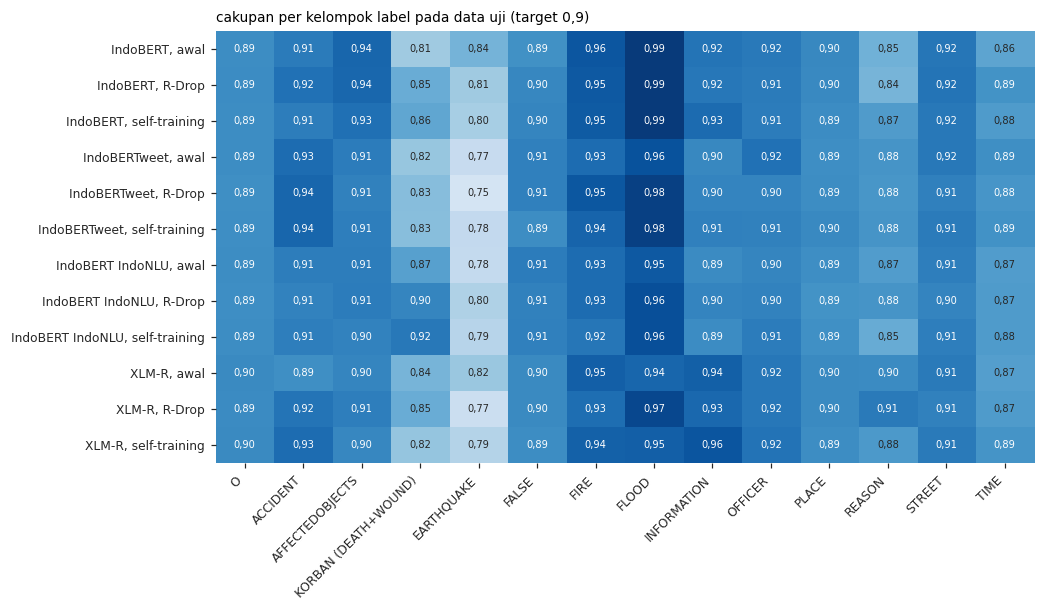

In [72]:
UJ = {x: KF.uji(*x) for x in DF}
display(tabel(pd.DataFrame({NM[x]: u["ringkas"] for x, u in UJ.items()}).T, 3))
GU = pd.DataFrame({NM[x]: u["grup"] for x, u in UJ.items()}).T.reindex(columns=KF.GRUP)
fig, ax = plt.subplots(figsize=(9.6, .3 * len(GU) + 1.5))
PL.heatmap(ax, GU.values, GU.index, [pendek(g) for g in GU.columns], vmin=.7, vmax=1)
ax.set_title("cakupan per kelompok label pada data uji (target 0,9)", loc="left")
PL.save(fig, "10_5_conformal_uji"); plt.show()

<div align="justify">

Cakupan token bukan O pada data uji sebesar 0,894 sampai 0,903 dengan target 0,9, sedangkan cakupan O sebesar 0,890 sampai 0,897. Aturan penerimaan menandai 79,5% *tweet* IndoBERT *self-training* dan menjaring 90,9% *tweet* salah. Cakupan EARTHQUAKE-EVENT sebesar 0,75 sampai 0,84 dan label korban sebesar 0,81 sampai 0,92 menunjukkan keterbatasan kelompok kecil. Target tidak selalu tercapai pada setiap kelompok. Aturan yang sama digunakan dalam perbandingan audit pada Bab 10.6.

</div>


### 10.6 Hasil RQ4: Audit Label pada IndoBERT

#### 10.6.1 Kinerja dengan Label Asli dan Label Audit

<div align="justify">

Ketiga model pada tabel berikut dilatih menggunakan label audit. Prediksi yang sama dinilai terhadap label asli dan label audit pada masing masing bagian data. Perbedaan kedua skor mengukur pengaruh perubahan acuan evaluasi. Pengaruh pelatihan ulang diperiksa dengan membandingkan model ini terhadap model berlabel latih asli pada Bab 10.1 dan 10.5 dengan acuan evaluasi yang sama.

</div>


In [73]:
display(METRIK_AUDIT.groupby(["model", "evaluasi"])[["macro-F1", "precision", "recall", "span F1"]].agg(["mean", "std"]).round(4))
PAS = (("audit_st", "audit_rdrop"), ("audit_st", "audit_awal"), ("audit_rdrop", "audit_awal"))
display(tabel(LP.tabel_banding("val_audit", PAS, bbs=[C.BACKBONE_PAPER]), 4))

macro-F1         precision          recall          \
                             mean     std      mean     std    mean     std   
model         evaluasi                                                        
R-Drop        test         0.7577  0.0062    0.7379  0.0057  0.7863  0.0083   
              test_audit   0.7728  0.0061    0.7572  0.0057  0.7957  0.0085   
              val          0.7656  0.0056    0.7432  0.0080  0.7992  0.0041   
              val_audit    0.7986  0.0061    0.7832  0.0093  0.8213  0.0044   
awal          test         0.7544  0.0045    0.7364  0.0093  0.7809  0.0048   
              test_audit   0.7698  0.0046    0.7561  0.0097  0.7908  0.0047   
              val          0.7606  0.0070    0.7442  0.0057  0.7871  0.0144   
              val_audit    0.7927  0.0070    0.7835  0.0047  0.8081  0.0148   
self-training test         0.7623  0.0017    0.7509  0.0044  0.7839  0.0022   
              test_audit   0.7775  0.0021    0.7703  0.0047  0.7931  0.0027   
              val          0.7724  0.0028    0.7558  0.0031  0.8000  0.0025   
              val_audit    0.8052  0.0026    0.7950  0.0029  0.8213  0.0023   

                         span F1          
                            mean     std  
model         evaluasi                    
R-Drop        test        0.7576  0.0049  
              test_audit  0.7751  0.0048  
              val         0.7641  0.0028  
              val_audit   0.7966  0.0025  
awal          test        0.7470  0.0015  
              test_audit  0.7645  0.0015  
              val         0.7551  0.0089  
              val_audit   0.7866  0.0079  
self-training test        0.7637  0.0029  
              test_audit  0.7813  0.0032  
              val         0.7743  0.0033  
              val_audit   0.8065  0.0023

,backbone,model,acuan,selisih,ci_bawah,ci_atas,seed_naik
0,IndoBERT,self-training,R-Drop,"0,0066","0,0005","0,0145",3/3
1,IndoBERT,self-training,awal,"0,0125","0,0041","0,0215",3/3
2,IndoBERT,R-Drop,awal,"0,0059","-0,0019","0,0152",3/3


<div align="justify">

Pada validasi audit, *self-training* mencapai *macro-F1* 0,8052 ± 0,0026. Selisih terhadap R-Drop sebesar +0,0066 dengan CI 95% 0,0005 sampai 0,0145 dan terhadap model awal sebesar +0,0125 dengan CI 0,0041 sampai 0,0215. Kedua perbandingan meningkat pada ketiga *seed*. Selisih R-Drop terhadap model awal sebesar +0,0059 memiliki CI −0,0019 sampai 0,0152, sehingga arah peningkatannya belum cukup kuat. Perbandingan ini menguji metode dalam kondisi label audit, bukan pengaruh audit secara terpisah.

</div>

<div align="justify">

Ketika label evaluasi yang sama diganti dari asli menjadi audit, skor naik 0,0321 sampai 0,0330 pada validasi dan 0,0151 sampai 0,0154 pada uji. Pada uji audit, model awal, R-Drop, dan *self-training* memperoleh 0,7698, 0,7728, dan 0,7775. Kenaikan akibat penggantian acuan tidak menunjukkan bahwa prediksi model berubah.

</div>

<div align="justify">

Manfaat pelatihan ulang belum konsisten pada label evaluasi asli. Dibandingkan model sebelum audit, perubahan validasi untuk model awal, R-Drop, dan *self-training* adalah +0,0009, −0,0084, dan −0,0039. Pada uji asli, perubahannya +0,0037, −0,0031, dan −0,0021. Selisih tersebut bersifat deskriptif karena CI khusus perbandingan sebelum dan sesudah audit belum tersedia pada keluaran terbaru.

</div>


#### 10.6.2 *Conformal Prediction* pada Model Label Audit

<div align="justify">

Ketiga model audit dievaluasi pada target cakupan 0,9. Label audit validasi dipakai untuk kalibrasi dan label audit uji untuk evaluasi. Peninjauan memakai aturan terbaru: suatu token diterima hanya jika himpunannya berisi tepat satu label yang sama dengan prediksi model. Satu token yang tidak memenuhi aturan tersebut membuat *tweet* perlu ditinjau.

</div>


In [74]:
DA = KF.daftar(KF.AUDIT)
rows = []
for b, k in DA:
    v = KF.resplit(b, k)[1]
    v = v[(v.alpha == .1) & (v.alpha_O == .1)].mean(numeric_only=True)
    u = KF.uji(b, k)["ringkas"]
    rows.append(dict(model=KF.nama(b, k), cakupan_validasi=v.cakupan_bukan_O, cakupan_uji=u["cakupan_bukan_O"], tinjau_validasi=v.tweet_ditinjau, tinjau_uji=u["tweet_ditinjau"]))
RA = pd.DataFrame(rows)
RA.to_csv(FOLDER_HASIL_AUDIT / "novelty2_audit.csv", index=False)
display(tabel(RA, 3))

,model,cakupan_validasi,cakupan_uji,tinjau_validasi,tinjau_uji
0,"IndoBERT, awal (label audit)","0,898","0,897","0,764","0,726"
1,"IndoBERT, R-Drop (label audit)","0,898","0,896","0,751","0,707"
2,"IndoBERT, self-training (label audit)","0,898","0,892","0,767","0,715"


<div align="justify">

Cakupan token bukan O pada validasi sekitar 0,898 untuk ketiga model. Pada uji, cakupan model awal, R-Drop, dan *self-training* adalah 0,897, 0,896, dan 0,892 dengan kebutuhan peninjauan *tweet* 72,6%, 70,7%, dan 71,5%. Cakupan mendekati target 0,9, tetapi ketiga rata rata uji masih berada di bawahnya.

</div>

<div align="justify">

Dengan aturan penerimaan yang sama, model berlabel asli memerlukan peninjauan 77,7%, 78,8%, dan 79,5% pada tabel evaluasi ulang di bawah. Beban peninjauan setelah audit lebih rendah sekitar 5,1, 8,1, dan 8,0 poin persentase. Namun, cakupannya juga turun dari 0,900, 0,903, dan 0,901. Hasil ini menunjukkan berkurangnya beban peninjauan, tetapi belum menunjukkan perbaikan menyeluruh karena model, label kalibrasi, dan label uji berubah bersamaan. CI selisih cakupan dan peninjauan belum tersedia. Cakupan token juga bukan akurasi seluruh *tweet* atau jaminan bahwa semua keluaran yang diterima benar.

</div>


#### 10.6.3 Token yang Dikoreksi Audit

<div align="justify">

Analisis ini mencakup 179 token validasi yang labelnya berubah. Himpunan dibentuk dengan pembagian silang pada validasi audit. Hasilnya menjelaskan hubungan koreksi label dengan ketidakpastian model dan tidak dipakai sebagai ukuran keberhasilan mendeteksi seluruh kesalahan anotasi.

</div>


,token dikoreksi audit,ditandai: semua token,ditandai: prediksi salah,ditandai: token dikoreksi audit,label audit masuk himpunan,label asli masuk himpunan,prediksi sama dengan label audit
"IndoBERT, awal (label audit)",179,"0,246","0,555","0,192","0,888","0,130","0,911"
"IndoBERT, R-Drop (label audit)",179,"0,139","0,528","0,175","0,885","0,123","0,912"
"IndoBERT, self-training (label audit)",179,"0,138","0,555","0,166","0,890","0,125","0,909"


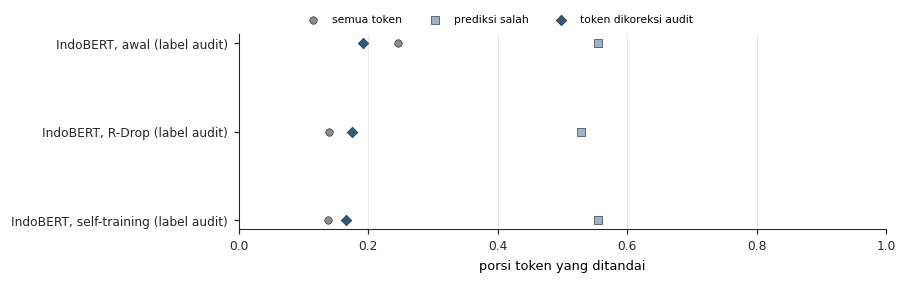

In [75]:
KR = pd.DataFrame({KF.nama(*x): KF.koreksi(*x) for x in DA}).T.astype({"token dikoreksi audit": int})
display(tabel(KR, 3))
kol = ["ditandai: semua token", "ditandai: prediksi salah", "ditandai: token dikoreksi audit"]
fig, ax = plt.subplots(figsize=(7.6, .3 * len(KR) + 1.4))
for c, w, mk in zip(kol, (PL.ABU, PL.BIRU_M, PL.BIRU), "osD"):
    ax.scatter(KR[c], range(len(KR)), color=w, marker=mk, s=24, edgecolor=PL.TINTA, linewidth=.4, label=c.removeprefix("ditandai: "), zorder=3)
ax.set_yticks(range(len(KR)), KR.index); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("porsi token yang ditandai")
ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(.4, 1.0), fontsize=7)
PL.save(fig, "10_6_koreksi_audit"); plt.show()

<div align="justify">

Pada token validasi yang dikoreksi, prediksi ketiga model sesuai label audit pada 90,9% sampai 91,2% token. Label audit masuk himpunan pada 88,5% sampai 89,0% token, sedangkan label asli hanya 12,3% sampai 13,0%. Namun, hanya 16,6% sampai 19,2% token yang dikoreksi ditandai untuk ditinjau. Model dapat menghasilkan prediksi yang konsisten dengan koreksi tanpa menandainya sebagai tidak pasti.

</div>

<div align="justify">

Temuan ini menunjukkan kesesuaian prediksi dengan anotasi yang disepakati, tetapi *conformal prediction* belum menjadi pendeteksi kesalahan label yang lengkap. Token ini dipilih melalui audit dan tidak mewakili sampel baru yang independen dari pengembangan model.

</div>


### Evaluasi ulang dari prediksi tersimpan

<div align="justify">

Tabel ini memakai aturan *singleton* yang selaras dengan prediksi dan tersimpan di `hasil/konformal_v2/ringkasan_uji.csv`. Tabel ini memuat model dengan label latih asli sebagai pembanding audit dan memakai aturan penerimaan yang sama. Bobot model tetap. Data final dan prediksi validasi serta uji menjadi sumber penghitungan ulang.

</div>


In [76]:
EVALUASI_BARU = KF.evaluasi_tersimpan()
display(EVALUASI_BARU)
if EVALUASI_BARU.empty:
    print("Prediksi validasi dan uji final belum tersedia di folder hasil aktif.")

,model,cakupan_bukan_O,cakupan_O,rerata_ukuran,token_ditinjau,tweet_ditinjau,tweet_ditinjau_aturan_lama,singleton_tidak_selaras,token_salah_tertangkap,tweet_salah_tertangkap
0,"IndoBERT, awal",0.899847,0.893206,1.177029,0.155664,0.776956,0.742072,0.017206,0.520691,0.884909
1,"IndoBERT, R-Drop",0.902962,0.893651,1.235278,0.163242,0.788231,0.764975,0.014195,0.548457,0.897840
2,"IndoBERT, self-training",0.901334,0.892402,1.256788,0.170804,0.794926,0.776956,0.013410,0.583914,0.908790
3,"IndoBERTweet, awal",0.897568,0.892254,1.247669,0.215716,0.892882,0.874912,0.017249,0.600746,0.957447
4,"IndoBERTweet, R-Drop",0.895429,0.890180,1.260468,0.210146,0.904863,0.892178,0.016929,0.603467,0.961773
5,"IndoBERTweet, self-training",0.897429,0.891365,1.273499,0.220559,0.904863,0.891825,0.015417,0.629237,0.964354
6,"IndoBERT IndoNLU, awal",0.894546,0.892212,1.549050,0.307125,0.966878,0.961593,0.010937,0.710207,0.987979
7,"IndoBERT IndoNLU, R-Drop",0.894220,0.891958,1.991114,0.540527,0.992248,0.991896,0.005483,0.804702,0.998936
8,"IndoBERT IndoNLU, self-training",0.894453,0.892825,1.702314,0.384659,0.958069,0.954545,0.007723,0.756396,0.986573
9,"XLM-R, awal",0.899242,0.896698,1.227279,0.202452,0.849894,0.819239,0.015926,0.549200,0.915801


<a id="bab-11"></a>
## 11. Interpretabilitas / *Error Analysis*

<div align="justify">

Analisis kesalahan memakai model yang dipilih dari *macro-F1* validasi tertinggi, yaitu IndoBERT *self-training* (0,7763, Bab 10.1 dan Bab 13), dengan IndoBERT awal sebagai pembanding. F1 per label memakai data validasi untuk semua model. *Confusion matrix*, jenis kesalahan, dan contoh prediksi memakai data uji yang sudah dibuka pada Bab 10.5, dan hasilnya tidak dipakai untuk keputusan apa pun.

</div>

### 11.1 F1 per Label


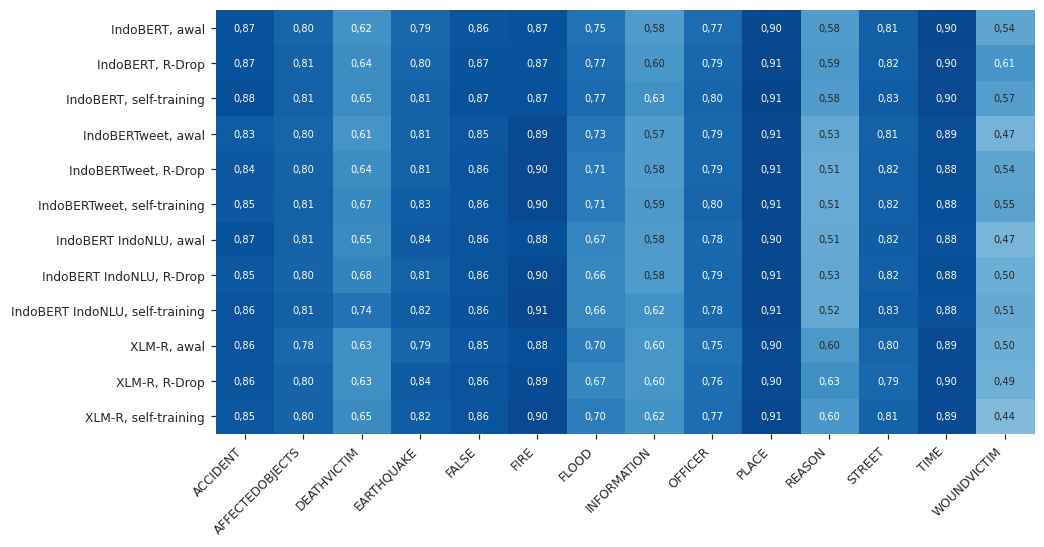

In [77]:
PLB = PLS.pivot_table(index=["backbone", "model"], columns="label", values="f1", sort=False).reindex(columns=C.NON_O)
fig, ax = plt.subplots(figsize=(9.6, .3 * len(PLB) + 1.4))
PL.heatmap(ax, PLB.values, [f"{b}, {m}" for b, m in PLB.index], [pendek(l) for l in PLB.columns], vmin=0, vmax=1)
PL.save(fig, "11_1_f1_label"); plt.show()

<div align="justify">

F1 per label validasi memperlihatkan pola yang sama pada ke-12 model. Label terlemah adalah WOUNDVICTIM-ARG (0,44 sampai 0,61), REASON-ARG (0,51 sampai 0,63), INFORMATION-ARG (0,57 sampai 0,63), dan DEATHVICTIM-ARG (0,61 sampai 0,74), sedangkan PLACE-ARG (0,90 sampai 0,91) dan TIME-ARG (0,88 sampai 0,90) paling tinggi. Pada model terpilih, IndoBERT *self-training*, F1 WOUNDVICTIM-ARG 0,57 dan DEATHVICTIM-ARG 0,65. Angka ini di atas penelitian sebelumnya (0,377 dan 0,530) [2](#ref-2), walaupun data dan pembagiannya berbeda, tetapi kedua label korban tetap termasuk yang paling lemah. Label korban dan penyebab paling dibutuhkan saat bencana dan paling sedikit contohnya, sehingga perbaikan berikutnya paling bermanfaat pada label ini.

</div>


### 11.2 *Confusion Matrix* Data Uji


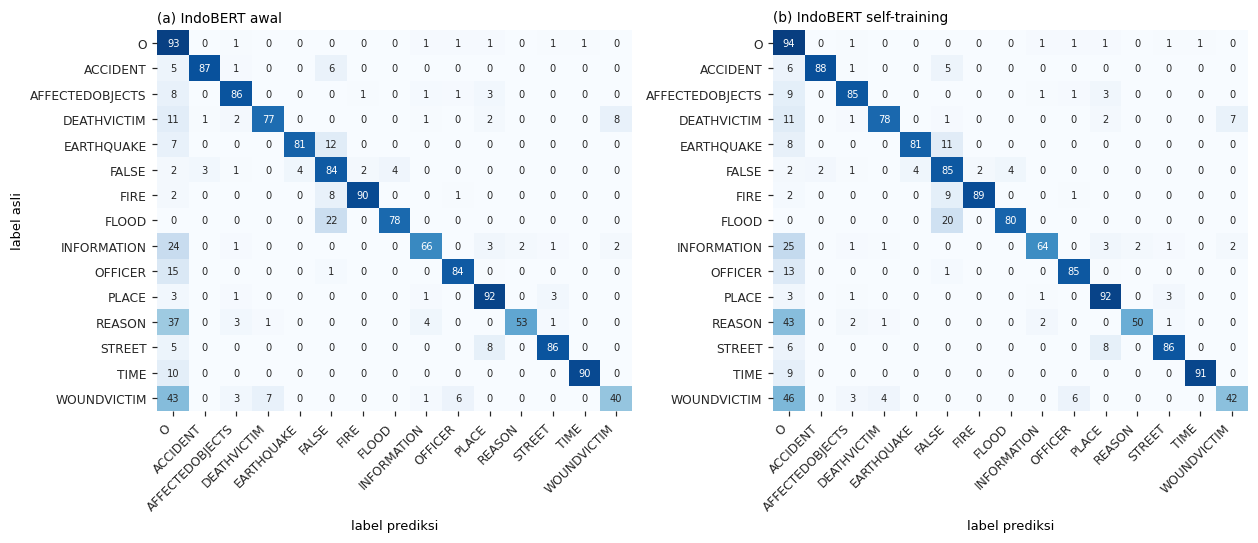

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 5))
for a, arm, t in ((ax[0], "awal", "(a) IndoBERT awal"), (ax[1], "st", "(b) IndoBERT self-training")):
    PL.confusion(a, LP.matriks("test", arm), [pendek(l) for l in C.LABELS], t)
ax[1].set_ylabel(""); fig.tight_layout(); PL.save(fig, "11_2_confusion_uji"); plt.show()

<div align="justify">

*Confusion matrix* dijumlahkan atas tiga *seed* dan dinormalisasi per baris. Kesalahan terbesar pada kedua model adalah argumen yang ditebak O. Pada IndoBERT *self-training*, 46% token WOUNDVICTIM-ARG, 43% REASON-ARG, dan 25% INFORMATION-ARG ditebak O, sehingga *recall* label tersebut rendah. Kesalahan kedua adalah kejadian nyata yang ditebak FALSE-EVENT, yaitu 20% FLOOD-EVENT dan 11% EARTHQUAKE-EVENT. Kesalahan ini muncul karena status nyata ditentukan konteks *tweet*, bukan kata kejadiannya. Pertukaran antarargumen lebih kecil, misalnya STREET-ARG ke PLACE-ARG (8%) dan DEATHVICTIM-ARG ke WOUNDVICTIM-ARG (7%). Dibandingkan model awal, *self-training* sedikit memperbaiki WOUNDVICTIM-ARG (40% menjadi 42%) dan FLOOD-EVENT (78% menjadi 80%), tetapi REASON-ARG turun dari 53% menjadi 50%.

</div>


### 11.3 F1 per Jenis Kejadian dan Jenis Kesalahan

<div align="justify">

Prediksi model pada data uji dibandingkan dengan label asli memakai kategori yang sama dengan kandidat audit (Bab 8.4), sehingga jenis kesalahan model dapat dibaca dengan cara yang sama seperti jenis kesalahan label.

</div>


[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba


,awal,R-Drop,self-training
kategori,,,
status kejadian,125,120,125
argumen mungkin terlewat,405,394,358
batas span,354,324,341
tipe argumen,33,33,29
label mungkin berlebih,133,126,135


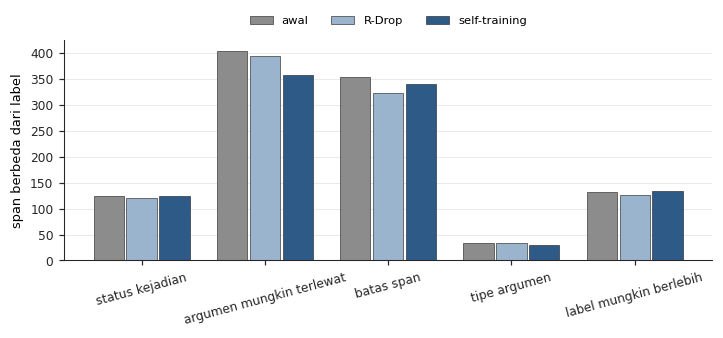

In [79]:
display(tabel(LP.per_jenis("test").pivot_table(index="jenis", columns=["backbone", "model"], values="f1", sort=False), 3))
NMA = {"awal": "awal", "rdrop": "R-Drop", "st": "self-training"}
JK = pd.DataFrame({n: AU.jenis_kesalahan(S.prediksi(S.model_dir(a, C.BACKBONE_PAPER, 42), "test", C.BACKBONE_PAPER), S.data("test"))
                   for a, n in NMA.items()}).reindex(AU.N_PER).fillna(0).astype(int)
display(JK)
fig, ax = plt.subplots(figsize=(7.6, 2.6))
PL.kelompok(ax, JK, PL.WARNA_MODEL, ylabel="span berbeda dari label")
ax.tick_params(axis="x", rotation=15); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(.5, 1.02))
PL.save(fig, "11_3_jenis_kesalahan"); plt.show()

<div align="justify">

*Macro-F1* per jenis kejadian pada data uji berada di 0,452 sampai 0,657. Angka ini lebih rendah daripada *macro-F1* keseluruhan karena label kejadian dari jenis lain tidak muncul pada subset tersebut dan tetap dihitung dengan F1 nol dalam rata-rata 14 label. Oleh karena itu, angka per jenis hanya dibandingkan antarmodel dalam jenis yang sama. Pada IndoBERT, *self-training* lebih baik daripada model awal untuk banjir (0,573 dibanding 0,545) dan kebakaran (0,611 dibanding 0,604), dan hampir sama untuk gempa dan kecelakaan. Tabel jenis kesalahan memakai IndoBERT *seed* 42. *Self-training* mengurangi argumen yang terlewat dari 405 menjadi 358 *span* dan batas *span* yang berbeda dari 354 menjadi 341, sedangkan status kejadian (125) dan label berlebih (133 menjadi 135) hampir tidak berubah. Jadi, kenaikan *self-training* terutama berasal dari argumen yang sebelumnya terlewat.

</div>


### 11.4 Contoh Prediksi Benar dan Salah


In [80]:
pd.set_option("display.max_colwidth", 200)
display(LP.contoh_prediksi("test", "st"))
pd.set_option("display.max_colwidth", 110)

,hasil,text_id,teks,span label asli,span prediksi
0,benar,GEM-01313,gempa magnitudo 4 6 terjadi di mamasa sulbar : gempa bumi magnitudo 4 6 terjadi di mamasa,[gempa]EARTHQUAKE [magnitudo 4 6]INFORMATION [mamasa sulbar]PLACE [gempa bumi]EARTHQUAKE [magnitudo 4 6]INFORMATION [mamasa]PLACE,[gempa]EARTHQUAKE [magnitudo 4 6]INFORMATION [mamasa sulbar]PLACE [gempa bumi]EARTHQUAKE [magnitudo 4 6]INFORMATION [mamasa]PLACE
1,benar,KEB-00689,"02.47 : kebakaran ruko di jalan raya merdeka , cimone , kota tangerang dan lalin di lokasi padat . ( p . dedi )",[kebakaran]FIRE [ruko]AFFECTEDOBJECTS [jalan raya merdeka]STREET [cimone]PLACE [kota tangerang]PLACE,[kebakaran]FIRE [ruko]AFFECTEDOBJECTS [jalan raya merdeka]STREET [cimone]PLACE [kota tangerang]PLACE
2,benar,KEC-01475,05:06 kecelakaan di km 44 tol ciawi ( arah ke cawang ) & amp masih penanganan polri,[05:06]TIME [kecelakaan]ACCIDENT [km 44 tol ciawi ( arah ke cawang]STREET [masih penanganan]INFORMATION [polri]OFFICER,[05:06]TIME [kecelakaan]ACCIDENT [km 44 tol ciawi ( arah ke cawang]STREET [masih penanganan]INFORMATION [polri]OFFICER
3,benar,KEB-00166,"sehari , dua kebakaran lahan terjadi di kabupaten bintan",[kebakaran]FIRE [lahan]AFFECTEDOBJECTS [kabupaten bintan]PLACE,[kebakaran]FIRE [lahan]AFFECTEDOBJECTS [kabupaten bintan]PLACE
4,salah,BAN-01805,pasca banjir muncul ular sepanjang 4 5 meter di perumahan binong permai blok b curug kabupaten tangerang kamis ( 16/5/2019 ) pukul 01:00 wib,[banjir]FALSE [perumahan binong permai blok b]STREET [curug kabupaten tangerang]PLACE [kamis]TIME,[banjir]FLOOD [4 5 meter]INFORMATION [perumahan binong permai blok b]STREET [curug kabupaten tangerang]PLACE [kamis]TIME [16/5/2019]TIME [pukul 01:00 wib]TIME
5,salah,KEC-00333,kecelakaan di subang sopir bus premium ditetapkan tersangka,[kecelakaan]ACCIDENT [subang]PLACE,[kecelakaan]ACCIDENT [subang]PLACE [sopir bus premium]WOUNDVICTIM
6,salah,BAN-01427,sebelum jembatan layang kiaracondong ( jl ibrahim adjie ) banjir hati di jalan,[jl ibrahim adjie]STREET [banjir]FLOOD [jalan]INFORMATION,[sebelum jembatan]INFORMATION [layang kiaracondong]PLACE [jl ibrahim adjie]STREET [banjir]FLOOD
7,salah,KEC-01122,06.55 : terjadi kecelakaan di tol dalam kota km09-300 arah slipi sedang penanganan ada korban jiwa ( brigadir harlen ),[kecelakaan]ACCIDENT [tol dalam kota km09-300 arah slipi]STREET [sedang penanganan ada korban jiwa]INFORMATION,[kecelakaan]ACCIDENT [tol dalam kota km09-300 arah slipi]STREET [penanganan]INFORMATION [ada korban jiwa]DEATHVICTIM


<div align="justify">

Contoh benar umumnya *tweet* berita yang pendek dan baku, misalnya laporan gempa dengan magnitudo dan lokasi. Contoh salah memperlihatkan dua sumber kesalahan. Sebagian berasal dari model. Pada KEC-00333, "sopir bus premium" ditebak WOUNDVICTIM-ARG padahal *tweet* membahas status tersangka. Sebagian lainnya berkaitan dengan konvensi anotasi. Pada BAN-01805, prediksi FLOOD-EVENT untuk "banjir" semula berbeda dari label asli FALSE-EVENT. Kedua penilai kemudian menyepakati FLOOD-EVENT, sehingga prediksi tersebut sesuai dengan label audit. Pada BAN-01805, model memberi TIME-ARG pada "16/5/2019" dan "pukul 01:00 wib" yang tidak dilabeli anotasi, dan pada KEC-01122, anotasi menggabungkan "sedang penanganan ada korban jiwa" menjadi satu INFORMATION-ARG, sedangkan model memisahkan "ada korban jiwa" sebagai DEATHVICTIM-ARG.

</div>


<a id="bab-12"></a>
## 12. Biaya Komputasi

<div align="justify">

Waktu *training* diambil dari riwayat setiap model dan dirata-ratakan atas tiga *seed*. Waktu *training* *self-training* belum termasuk MC *dropout* lima model penyeleksi pada *pool*. Waktu inferensi diukur pada 599 *tweet* validasi dengan *batch* 8 pada GPU yang tercetak di Bab 4.1. *Conformal prediction* tidak menambah *training*: biayanya hanya MC *dropout* pada data validasi untuk dua sinyal pembanding dan perhitungan kuantil di CPU.

</div>


In [81]:
display(tabel(LP.biaya(), 1))

[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed42] memakai hasil tersimpan runs/aec4a1bef7ba
[awal IndoBERT seed43] memakai hasil tersimpan runs/0944cb0f46aa
[awal IndoBERT seed44] memakai hasil tersimpan runs/59a278a70a9a
[awal IndoBERTweet seed42] memakai hasil tersimpan runs/e92485f00487
[awal IndoBERTweet seed42] memakai hasil tersimpan runs/e92485f00487
[awal IndoBERTweet seed43] memakai hasil tersimpan runs/e1ff1a83f0d9
[awal IndoBERTweet seed44] memakai hasil tersimpan runs/14d89dd25b28
[awal IndoBERT IndoNLU seed42] memakai hasil tersimpan runs/b1d67f8b3456
[awal IndoBERT IndoNLU seed42] memakai hasil tersimpan runs/b1d67f8b3456
[awal IndoBERT IndoNLU seed43] memakai hasil tersimpan runs/ee51bb52d281
[awal IndoBERT IndoNLU seed44] memakai hasil tersimpan runs/02a5c87a025f
[awal XLM-R seed42] memakai hasil tersimpan runs/76e4daa94aa9
[awal XLM-R seed42] memakai hasil tersimpan runs/76e4daa94aa9
[awal XLM-R seed43] memakai hasil tersimpan runs

,parameter (juta),model.pt (MB),training awal (menit),training R-Drop (menit),training self-training (menit),inferensi validasi (detik),inferensi per tweet (ms),memori GPU puncak (MB)
backbone,,,,,,,,
IndoBERT,"110,6","210,9","5,0","11,8","12,8","1,0","1,6","644,3"
IndoBERTweet,"110,6","210,9","4,9","11,7","12,8","2,9","4,8","644,3"
IndoBERT IndoNLU,"124,5","237,4","4,9","12,0","12,0","2,2","3,6","693,4"
XLM-R,"278,1","530,4","5,2","13,3","12,9","4,7","7,9","1.282,2"


<div align="justify">

IndoBERT dan IndoBERTweet memiliki 110,6 juta parameter, sedangkan XLM-R 278,1 juta karena kosakatanya multibahasa. *Training* model awal membutuhkan sekitar 5 menit pada A100, sedangkan R-Drop dan *self-training* membutuhkan 11,7 sampai 13,3 menit karena dua *forward pass* dan *batch* tambahan *pseudo-label*. Inferensi IndoBERT hanya 1,9 ms per *tweet*, sedangkan XLM-R 16,9 ms. *Conformal prediction* tidak menambah *training*, sehingga biaya *Novelty* 2 hanya perhitungan kuantil dan MC *dropout* untuk sinyal pembanding.

</div>


<a id="bab-13"></a>
## 13. Model Final dan Inferensi

<div align="justify">

Model utama dipilih dari rata-rata *macro-F1* validasi dan *checkpoint* *seed* 42 digunakan untuk contoh inferensi. *Pseudo-label* adalah label keluaran model, sedangkan *pool* merupakan kumpulan *tweet* tanpa anotasi manusia yang menjadi sumber kandidat tambahan. Keluaran inferensi menyimpan *span*, himpunan label, dan status peninjauan. *Singleton* hanya menjadi kandidat penerimaan jika sama dengan label keluaran. Kuantil dan identitas kalibrasi tersimpan bersama contoh hasil.

</div>


In [82]:
import json
skor = {(b, a): LP.metrik("val", (a,), [b])["macro-F1"].mean() for b in LP.siap() for a in KF.ASLI}
BBF, ARMF = FINAL = max(skor, key=skor.get)
display(pd.Series({KF.nama(*x): v for x, v in skor.items()}, name="macro-F1 validasi").to_frame().round(4))
print("model final:", KF.nama(*FINAL), "|", S.model_dir(ARMF, BBF, 42).relative_to(C.OUT))

model, enc = S.load_model(S.model_dir(ARMF, BBF, 42), BBF), S.encoder(BBF)
_, _, Pv, yv, _ = KF.data(BBF, ARMF)
Q = KF.ambang(Pv, yv, np.arange(len(yv)), .1)
kalibrasi = KF.simpan_kalibrasi(BBF, ARMF, 42, Q)
S.write(C.OUT / "inferensi" / "kalibrasi.json", kalibrasi)
kamus = S.read(C.DATA_OUT / "info.json")["kamus"]

def siapkan(teks):
    tok = [w.lower() for w in PR.tokenisasi_mentah(teks) if not (w.startswith("@") or PR.adalah_url(w))]
    return PR.perbaiki(tok, ["O"] * len(tok), kamus=kamus)[0]

def ekstrak(teks):
    tok = siapkan(teks)
    if not tok:
        return {"teks": "", "span": [], "perlu_ditinjau": True, "token_ditandai": [], "alasan": "teks kosong setelah preprocessing"}
    o = tr.predict(model, [{"text_id": "baru", "tokens": tok}], enc)
    lab, Sx = tr.decode_all(o)[0], KF.himpunan(tr.softmax(o.word_logits[0]), Q)
    ragu = [{"kata": tok[j], "himpunan": [C.LABELS[c] for c in np.where(Sx[j])[0]]} for j in np.where(KF.perlu_tinjau(tr.softmax(o.word_logits[0]), Sx))[0]]
    return {"teks": " ".join(tok), "span": [{"label": l, "kata": " ".join(tok[a:b]), "posisi": [a, b]} for a, b, l in spans(lab)],
            "perlu_ditinjau": bool(ragu), "token_ditandai": ragu}

BARU = ["Telah terjadi kebakaran rumah di Jl. Soekarno Hatta KM 5 Balikpapan pukul 14.00 WITA, petugas damkar masih memadamkan api",
        "Banjir merendam 300 rumah di Kecamatan Dayeuhkolot Kabupaten Bandung sejak tadi malam akibat hujan deras",
        "Semoga tidak ada banjir lagi tahun ini, jangan buang sampah sembarangan ya"]
HASIL = [ekstrak(t) for t in BARU]
(C.OUT / "inferensi").mkdir(exist_ok=True)
(C.OUT / "inferensi" / "contoh.json").write_text(json.dumps(HASIL, ensure_ascii=False, indent=1), encoding="utf-8")
for h in HASIL:
    print(h["teks"]); print("  ", "; ".join(f"[{s['kata']}] {pendek(s['label'])}" for s in h["span"]))
    print("   perlu ditinjau:", "ya, " + "; ".join(f"{r['kata']} {{{', '.join(map(pendek, r['himpunan'])) or 'kosong'}}}" for r in h["token_ditandai"]) if h["perlu_ditinjau"] else "tidak")

,macro-F1 validasi
"IndoBERT, awal",0.7597
"IndoBERT, R-Drop",0.7740
"IndoBERT, self-training",0.7763
"IndoBERTweet, awal",0.7497
"IndoBERTweet, R-Drop",0.7575
"IndoBERTweet, self-training",0.7625
"IndoBERT IndoNLU, awal",0.7516
"IndoBERT IndoNLU, R-Drop",0.7553
"IndoBERT IndoNLU, self-training",0.7662
"XLM-R, awal",0.7524


model final: IndoBERT, self-training | selftraining/st/p_indobert/seed42/model
telah terjadi kebakaran rumah di jl . soekarno hatta km 5 balikpapan pukul 14.00 wita , petugas damkar masih memadamkan api
   [kebakaran] FIRE; [rumah] AFFECTEDOBJECTS; [jl . soekarno hatta km 5] STREET; [balikpapan] PLACE; [pukul 14.00 wita] TIME; [petugas damkar] OFFICER
   perlu ditinjau: tidak
banjir merendam 300 rumah di kecamatan dayeuhkolot kabupaten bandung sejak tadi malam akibat hujan deras
   [banjir] FLOOD; [300 rumah] AFFECTEDOBJECTS; [kecamatan dayeuhkolot kabupaten bandung] PLACE; [hujan deras] REASON
   perlu ditinjau: ya, merendam {O, INFORMATION}; 300 {AFFECTEDOBJECTS, INFORMATION}; rumah {AFFECTEDOBJECTS, INFORMATION}; hujan {FLOOD, INFORMATION, REASON}; deras {FLOOD, INFORMATION, REASON}
semoga tidak ada banjir lagi tahun ini , jangan buang sampah sembarangan ya
   [banjir] FALSE
   perlu ditinjau: tidak


<div align="justify">

Contoh pertama mengenali kejadian kebakaran beserta objek, jalan, lokasi, waktu, dan petugas tanpa token yang ditandai. Contoh kedua mengenali kejadian banjir, tetapi beberapa token memiliki lebih dari satu kandidat label dan memerlukan peninjauan. Pada contoh ketiga, kata "banjir" dalam kalimat harapan diprediksi FALSE-EVENT. Ketiga contoh menggambarkan keluaran inferensi dan tidak menjadi ukuran akurasi pada data baru.

</div>


<a id="bab-14"></a>
## 14. Pembahasan

<div align="justify">

Rancangan penelitian berkembang dari hasil reproduksi dan analisis kesalahan. Penelitian sebelumnya melaporkan peningkatan skor pada *threshold* yang lebih tinggi. *Checkpoint* 1 menemukan bahwa sebagian besar model menerima seluruh atau hampir seluruh *pool* secara kumulatif, sementara dominasi O memengaruhi metrik agregat dan validasi berubah akibat pembagian ulang data. *Checkpoint* 2 menanggapi masalah tersebut melalui perbaikan *preprocessing*, seleksi per *span*, dan validasi yang dipertahankan. Setelah manfaat *self-training* diukur dalam protokol tersebut, *conformal prediction* digunakan untuk menilai cakupan label dan kebutuhan peninjauan. Uji lintas kejadian melengkapi evaluasi dengan menunjukkan batas penerapannya.

</div>

<div align="justify">

RQ1. *Self-training* memiliki rata-rata kinerja lebih tinggi daripada model awal pada keempat model bahasa dasar, baik di validasi (+0,0066 sampai +0,0165) maupun uji (+0,0048 sampai +0,0137). Namun, selisih terhadap R-Drop lebih kecil dan CI yang seluruhnya positif hanya ditemukan pada IndoBERT IndoNLU. Hasil ini mendukung manfaat protokol dalam konfigurasi yang diuji, tetapi belum menunjukkan keunggulan tambahan yang konsisten terhadap R-Drop pada semua model. *Pseudo-label* bergantung pada kemampuan penyeleksi, sementara *learning curve* menunjukkan bahwa peningkatan jumlah data berlabel masih bermanfaat.

</div>

<div align="justify">

RQ2. *Conformal prediction* menghasilkan cakupan empiris di sekitar target 0,9 tanpa melatih model baru, dengan beban peninjauan sebesar 77,7% sampai 99,2% *tweet* uji. Skor ternormalisasi terendah memberikan pengurutan terbaik pada validasi dan memungkinkan penerimaan 23,8% *tweet*. Proporsi dari seluruh *tweet* salah yang ikut diterima berada di bawah target 10%; angka ini bukan proporsi kesalahan di antara *tweet* yang diterima. Skor yang sama mendasari pengurutan *span* pada *Novelty* 1, tetapi satuan seleksi dan tujuan evaluasinya berbeda. Beban peninjauan tinggi tidak membatalkan peningkatan F1 pada *Novelty* 1. Aturan peninjauan berlaku pada seluruh *tweet* dan satu token meragukan sudah cukup untuk menandainya. Hasil ini menunjukkan bahwa otomatisasi penuh masih terbatas. Peninjauan menggunakan aturan *singleton* yang selaras dengan prediksi dan menjadi pembanding hasil audit pada Bab 10.6.

</div>

<div align="justify">

RQ3. Pengeluaran satu jenis kejadian dari data latih berlabel menurunkan *macro-F1* sebesar 0,188 sampai 0,273. Peran umum masih dapat dikenali, tetapi kata kejadian baru sering dipetakan ke O, FALSE-EVENT, atau jenis lain. Pola tersebut menunjukkan keterbatasan supervisi dengan label tetap dan berkaitan dengan motivasi penelitian transfer jenis kejadian [18](#ref-18). *Self-training* menunjukkan penurunan terbesar karena *pseudo-label* dapat mempertahankan kesalahan penyeleksi pada jenis yang tidak memiliki contoh latih berlabel.

</div>

<div align="justify">

RQ4. Koreksi 530 token dalam 338 *span* memperbarui label latih, validasi, dan uji. *Self-training* unggul terhadap model awal dan R-Drop pada validasi audit dengan CI selisih di atas nol. Namun, pelatihan ulang belum konsisten memperbaiki skor pada label evaluasi asli. Penggantian acuan menaikkan skor validasi sekitar 0,032 sampai 0,033 tanpa mengubah prediksi. Beban peninjauan *conformal* berkurang, tetapi cakupan uji menjadi 0,892 sampai 0,897. Audit memperjelas pengaruh anotasi terhadap evaluasi dan belum membuktikan peningkatan seluruh aspek model.

</div>


<a id="bab-15"></a>
## 15. Keterbatasan

<div align="justify">

Data latih berjumlah 2.380 *tweet* dari satu *dataset*. *Learning curve* belum menunjukkan pelandaian yang jelas, sementara kemiripan sebagian data uji dengan data pengembangan tetap membatasi interpretasi generalisasi.

</div>

<div align="justify">

Jaminan conformal memerlukan pertukaran unit kalibrasi dan evaluasi. Ketergantungan token dalam *tweet* serta penggunaan validasi dalam pengembangan model membatasi penafsiran hasil sebagai jaminan formal. Evaluasi memakai *singleton* yang selaras dengan prediksi. Evaluasi batas penerimaan berbasis sinyal memisahkan data pembentuk himpunan, penentu batas, dan pengukur galat. Pemisahan ini tidak menghapus keterbatasan akibat ketergantungan antartoken dan penggunaan validasi selama pengembangan.

</div>

<div align="justify">

Setiap separuh validasi hanya memuat sekitar 300 *tweet*. Kuantil label jarang dapat berubah akibat sedikitnya contoh, sementara cakupan per kelompok label tidak otomatis menjamin cakupan setiap jenis *tweet*.

</div>

<div align="justify">

Uji lintas kejadian dan audit label terbatas pada IndoBERT karena biaya komputasi. *Pool* pada uji lintas kejadian masih dapat memuat jenis yang dikeluarkan dari data latih berlabel. Pengaruh setiap *hyperparameter* dan perbedaan *batch* juga belum dipisahkan melalui *ablation* tersendiri.

</div>

<div align="justify">

Cohen's *kappa* kandidat audit berada pada 0,8800 sampai 0,9691, sedangkan sampel acak uji mencapai 0,5423 dengan kesepakatan 84,0%. Audit hanya mencakup sebagian data dan item yang disengketakan tetap memakai label asli. Kesepakatan tinggi tidak membuktikan bahwa seluruh anotasi benar. Perbandingan *conformal* sebelum dan sesudah audit mengubah model serta label kalibrasi dan evaluasi sekaligus, sehingga pengaruh masing masing perubahan belum terpisah.

</div>


<a id="bab-16"></a>
## 16. Kesimpulan

<div align="justify">

Penelitian ini mereproduksi SRL tanpa predikat untuk *tweet* krisis berbahasa Indonesia dan mengembangkan evaluasi melalui perbaikan *preprocessing*, protokol *self-training*, *conformal prediction*, serta uji lintas kejadian. Seleksi per *span* dan kuota label membatasi ketergantungan pada rata-rata probabilitas *tweet*, sementara data validasi dan jumlah *epoch* dipertahankan sepanjang pelatihan. *Self-training* memiliki rata-rata skor lebih tinggi daripada model awal pada keempat model bahasa dasar, tetapi keunggulan tambahannya terhadap R-Drop belum konsisten. IndoBERT *self-training* terpilih dengan *macro-F1* 0,7763 pada validasi dan 0,7644 pada data uji. Cakupan empiris conformal berada di sekitar target 0,9. Pada validasi, skor ternormalisasi terendah memungkinkan penerimaan 23,8% *tweet* dengan pembatasan proporsi *tweet* salah yang lolos. Uji lintas kejadian menurunkan *macro-F1* sebesar 0,188 sampai 0,273 dan mengurangi cakupan conformal. Oleh karena itu, hasil penelitian mendukung penggunaan model sebagai kandidat alat bantu ekstraksi dengan peninjauan manusia, disertai verifikasi aturan penerimaan dan kalibrasi ulang sebelum diterapkan pada jenis bencana baru.

</div>

<div align="justify">

Audit label pada RQ4 memperbaiki 530 token dan menghasilkan *macro-F1* uji audit 0,7775 untuk IndoBERT *self-training*. Beban peninjauan turun menjadi 71,5%, tetapi cakupan token bukan O sebesar 0,892 masih di bawah target 0,9. Hasil ini mendukung pemeriksaan anotasi sekaligus menunjukkan bahwa peningkatan skor evaluasi tidak selalu berarti peningkatan kemampuan model.

</div>


<a id="bab-17"></a>
## 17. Referensi

<a id="ref-1"></a>
[1] M. Imran, C. Castillo, F. Diaz, dan S. Vieweg, *“Processing social media messages in mass emergency: A survey,”* ACM Computing Surveys, vol. 47, no. 4, Art. no. 67, 2015. [DOI atau naskah sumber](https://doi.org/10.1145/2771588)

<a id="ref-2"></a>
[2] A. D. P. Ariyanto, D. Purwitasari, C. Fatichah, S. D. Ravana, Andrian, dan A. A. Y. Parwata, *“Transformer-based semantic role labeling for crisis events using semi-supervised learning on low-resource language Twitter texts,”* IEEE Access, vol. 13, hlm. 158938 sampai 158966, 2025. [DOI atau naskah sumber](https://doi.org/10.1109/ACCESS.2025.3604068)

<a id="ref-3"></a>
[3] A. D. P. Ariyanto, D. Purwitasari, B. Amaliah, C. Fatichah, M. G. Taqiuddin, dan Haikal, *“Annotated data for semantic role labeling of crisis events in Indonesian tweets,”* Data in Brief, vol. 61, Art. no. 111688, 2025. [DOI atau naskah sumber](https://doi.org/10.1016/j.dib.2025.111688)

<a id="ref-4"></a>
[4] C. Guo, G. Pleiss, Y. Sun, dan K. Q. Weinberger, *“On calibration of modern neural networks,”* dalam Proc. Int. Conf. Machine Learning (ICML), hlm. 1321 sampai 1330, 2017. [DOI atau naskah sumber](https://arxiv.org/abs/1706.04599)

<a id="ref-5"></a>
[5] A. N. Angelopoulos dan S. Bates, *“A gentle introduction to conformal prediction and distribution-free uncertainty quantification,”* arXiv:2107.07511, 2021. [DOI atau naskah sumber](https://arxiv.org/abs/2107.07511)

<a id="ref-6"></a>
[6] M. Campos, A. Farinhas, C. Zerva, M. A. T. Figueiredo, dan A. F. T. Martins, *“Conformal prediction for natural language processing: A survey,”* Trans. Assoc. Computational Linguistics, vol. 12, hlm. 1497 sampai 1516, 2024. [DOI atau naskah sumber](https://doi.org/10.1162/tacl_a_00715)

<a id="ref-7"></a>
[7] S. Medina Maza, E. Spiliopoulou, E. Hovy, dan A. Hauptmann, *“Event-related bias removal for real-time disaster events,”* dalam Findings of EMNLP, 2020. [DOI atau naskah sumber](https://arxiv.org/abs/2011.00681)

<a id="ref-8"></a>
[8] A. Elangovan, J. He, dan K. Verspoor, *“Memorization vs. generalization: Quantifying data leakage in NLP performance evaluation,”* dalam Proc. 16th Conf. European Chapter Assoc. Computational Linguistics (EACL), hlm. 1325 sampai 1335, 2021. [DOI atau naskah sumber](https://doi.org/10.18653/v1/2021.eacl-main.113)

<a id="ref-9"></a>
[9] J. Dodge, G. Ilharco, R. Schwartz, A. Farhadi, H. Hajishirzi, dan N. Smith, *“Fine-tuning pretrained language models: Weight initializations, data orders, and early stopping,”* arXiv:2002.06305, 2020. [DOI atau naskah sumber](https://arxiv.org/abs/2002.06305)

<a id="ref-10"></a>
[10] X. Liang, L. Wu, J. Li, Y. Wang, Q. Meng, T. Qin, W. Chen, M. Zhang, dan T.-Y. Liu, *“R-Drop: Regularized dropout for neural networks,”* dalam Advances in Neural Information Processing Systems 34, 2021. [DOI atau naskah sumber](https://arxiv.org/abs/2106.14448)

<a id="ref-11"></a>
[11] M. N. Rizve, K. Duarte, Y. S. Rawat, dan M. Shah, *“In defense of pseudo-labeling: An uncertainty-aware pseudo-label selection framework for semi-supervised learning,”* dalam Proc. Int. Conf. Learning Representations (ICLR), 2021. [DOI atau naskah sumber](https://arxiv.org/abs/2101.06329)

<a id="ref-12"></a>
[12] J. Wang, C. Wang, J. Huang, M. Gao, dan A. Zhou, *“Uncertainty-aware self-training for low-resource neural sequence labeling,”* dalam Proc. AAAI Conf. Artificial Intelligence, vol. 37, no. 11, hlm. 13682 sampai 13690, 2023. [DOI atau naskah sumber](https://doi.org/10.1609/aaai.v37i11.26603)

<a id="ref-13"></a>
[13] Y. Li, L. Liu, dan S. Shi, *“Empirical analysis of unlabeled entity problem in named entity recognition,”* dalam Proc. Int. Conf. Learning Representations (ICLR), 2021. [DOI atau naskah sumber](https://arxiv.org/abs/2012.05426)

<a id="ref-14"></a>
[14] B. Lakshminarayanan, A. Pritzel, dan C. Blundell, *“Simple and scalable predictive uncertainty estimation using deep ensembles,”* dalam Advances in Neural Information Processing Systems 30, 2017. [DOI atau naskah sumber](https://arxiv.org/abs/1612.01474)

<a id="ref-15"></a>
[15] Y. Gal dan Z. Ghahramani, *“Dropout as a Bayesian approximation: Representing model uncertainty in deep learning,”* dalam Proc. Int. Conf. Machine Learning (ICML), hlm. 1050 sampai 1059, 2016. [DOI atau naskah sumber](https://arxiv.org/abs/1506.02142)

<a id="ref-16"></a>
[16] A. N. Angelopoulos, S. Bates, A. Fisch, L. Lei, dan T. Schuster, *“Conformal risk control,”* dalam Proc. Int. Conf. Learning Representations (ICLR), 2024. [DOI atau naskah sumber](https://arxiv.org/abs/2208.02814)

<a id="ref-17"></a>
[17] Y. Geifman, G. Uziel, dan R. El-Yaniv, *“Bias-reduced uncertainty estimation for deep neural classifiers,”* dalam Proc. Int. Conf. Learning Representations (ICLR), 2019. [DOI atau naskah sumber](https://arxiv.org/abs/1805.08206)

<a id="ref-18"></a>
[18] L. Huang, H. Ji, K. Cho, I. Dagan, S. Riedel, dan C. Voss, *“Zero-shot transfer learning for event extraction,”* dalam Proc. 56th Annu. Meeting Assoc. Computational Linguistics (ACL), hlm. 2160 sampai 2170, 2018. [DOI atau naskah sumber](https://doi.org/10.18653/v1/P18-1201)

<a id="ref-19"></a>
[19] Z. Wang, J. Shang, L. Liu, L. Lu, J. Liu, dan J. Han, *“CrossWeigh: Training named entity tagger from imperfect annotations,”* dalam Proc. EMNLP-IJCNLP, hlm. 5154 sampai 5163, 2019. [DOI atau naskah sumber](https://doi.org/10.18653/v1/D19-1519)

<a id="ref-20"></a>
[20] R. Artstein dan M. Poesio, *“Inter-coder agreement for computational linguistics,”* Computational Linguistics, vol. 34, no. 4, hlm. 555 sampai 596, 2008. [DOI atau naskah sumber](https://doi.org/10.1162/coli.07-034-R2)
